# Initialize

In [ ]:
!pip install scikit-learn==1.6.1
!pip install xgboost==3.2.0
!pip install optuna==4.8.0
!pip install openpyxl==3.1.5

from google.colab import drive

drive.mount('/content/drive')

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 131.7/131.7 MB 6.3 MB/s eta 0:00:00
  Attempting uninstall: xgboost
    Found existing installation: xgboost 3.3.0
    Uninstalling xgboost-3.3.0:
      Successfully uninstalled xgboost-3.3.0
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 419.5/419.5 kB 12.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 264.7/264.7 kB 13.7 MB/s eta 0:00:00
Mounted at /content/drive


In [ ]:
# import xgboost
# print(xgboost.__version__)

3.2.0


# Visualize Samples

[0, 13]
len(df)=401
               eventType  rt75_by_event
1     EVENT_MAT_LEFT_VRU        2.25168
266   EVENT_MAT_ONCOMING        1.02830
0    EVENT_MAT_RIGHT_VRU        2.25166


/tmp/ipykernel_6398/1672565504.py:144: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:#1A1A1A'` for the same effect.

  sns.stripplot(


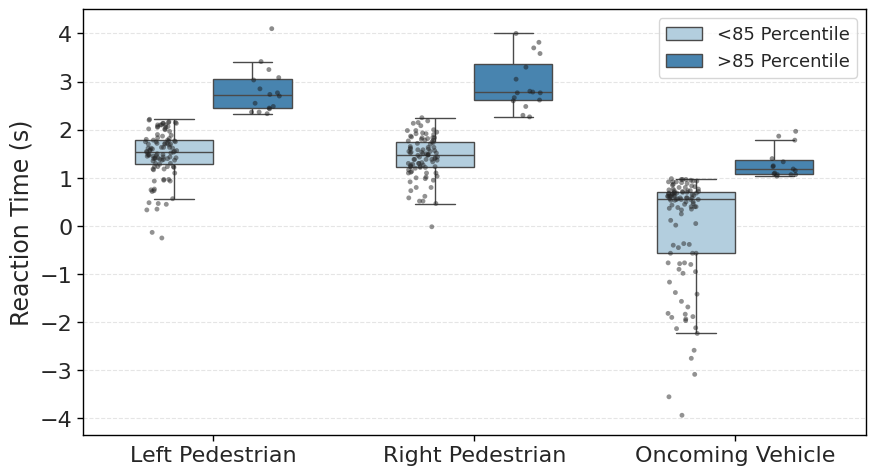

In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt


dataName = "/content/drive/MyDrive/Colab_Backups/Data_3sMean_IDT_beforeMat.xlsx"

TW_comb = [[0,x] for x in range(13,14)]
twType = "combineTW"

for TWs in TW_comb:

  print(TWs)

  if len(TWs)>1:

    targetTW = TWs[1]

  else:
    targetTW = TWs[0]

  corrThre = 0.85

  # ---------- Data Setup ----------
  df = pd.read_excel(dataName)

  # ---------- Parameter ----------
  outer_splits, inner_splits, n_trials = 5, 4, 100

  target_col = "relativeRT"

  cat_names = ["Gender", "automation", "eventType"]

  TW_list = TWs

  feature_templates = [
      "Age",
      "License",
      "Mileage",
      "Gender",
      "automation", "eventType",
      "visibleSpeed",

      # "sDuMean_{TW}",
      # "sAmpMean_{TW}",
      # "sVel2Mean_{TW}",


      "pdMean_{TW}", "pdSd_{TW}",
      "blinkNumber_{TW}",
      "avgBlinkDuration_{TW}",

      "fixNumber_{TW}",
      "avgFixDuration_{TW}",

      "fixTE_{TW}", "fixSE_{TW}",
      "FixDisperX_{TW}", "FixDisperY_{TW}",
      "FixDisperE_{TW}",
      "FixMeanPosX_{TW}", "FixMeanPosY_{TW}",

  ]

  feature_cols = []
  for c in feature_templates:
      feature_cols.extend([c.format(TW=tw) for tw in TW_list] if "{TW}" in c else [c])

  cont_names = [c for c in feature_cols if c not in cat_names]


  print(f'len(df)={len(df)}')

  df[target_col] = pd.to_numeric(df[target_col], errors="coerce")
  df = df.dropna(subset=[target_col, "eventType", "subNumber"]).copy()

  df["rt75_by_event"] = df.groupby("eventType")[target_col].transform(lambda x: x.quantile(0.85))
  df["RT75_cls"] = (df[target_col] >= df["rt75_by_event"]).astype(int)

  print(df[["eventType", "rt75_by_event"]].drop_duplicates().sort_values("eventType"))

  tww_cols = [f"perValid_{i}" for i in range(31)]

  pervalid_mean = df[tww_cols].mean(axis=1)

  abandon_mask = pervalid_mean < 74.5
  keep_mask = ~abandon_mask

  df = df[keep_mask].copy()

  X = df[feature_cols].copy()
  y = df["RT75_cls"].values.astype(int)

  # ---------------------------------------------------------
  # PREP DATA
  # ---------------------------------------------------------
  plot_df = df[["eventType", "RT75_cls", "relativeRT"]].copy()
  plot_df["relativeRT"] = pd.to_numeric(plot_df["relativeRT"], errors="coerce")
  plot_df = plot_df.dropna(subset=["eventType", "RT75_cls", "relativeRT"]).copy()

  plot_df["RT75_cls"] = plot_df["RT75_cls"].astype(str)

  # optional: shorter labels for display
  label_map = {
      "EVENT_MAT_LEFT_VRU": "Left Pedestrian",
      "EVENT_MAT_ONCOMING": "Oncoming Vehicle",
      "EVENT_MAT_RIGHT_VRU": "Right Pedestrian"
  }
  plot_df["eventType_clean"] = plot_df["eventType"].map(label_map).fillna(plot_df["eventType"])

  event_order = ["Left Pedestrian", "Right Pedestrian", "Oncoming Vehicle"]
  hue_order = ["0", "1"]


  # ---------------------------------------------------------
  # PLOT
  # ---------------------------------------------------------

sns.set_theme(style="whitegrid")

# Match the palette to your other figures
class_palette = {
    "0": "#C8C8C8" ,   # baseline grey
    "1": "#4DBBD5",   # accent blue
}
# "#4DBBD5",
#     ("LASSO", 1): "#1F77B4",

fig, ax = plt.subplots(figsize=(9, 5))

sns.boxplot(
    data=plot_df,
    x="eventType_clean",
    y="relativeRT",
    hue="RT75_cls",
    order=event_order,
    hue_order=hue_order,
    width=0.6,
    fliersize=0,
    # palette=class_palette,
    palette="Blues",
    linewidth=1.0,
    ax=ax,
)

sns.stripplot(
    data=plot_df,
    x="eventType_clean",
    y="relativeRT",
    hue="RT75_cls",
    order=event_order,
    hue_order=hue_order,
    dodge=True,
    jitter=0.12,
    size=3.5,
    alpha=0.5,
    color="#1A1A1A",      # match the dark dot color from your LASSO panel
    ax=ax,
)

# Clean spines + grid to match your other figures
# ax.spines["top"].set_visible(False)
# ax.spines["right"].set_visible(False)
ax.grid(axis="y", linestyle="--", linewidth=0.8, alpha=0.5)
ax.grid(axis="x", visible=False)
ax.tick_params(axis="both", which="both", length=10)

# Legend (only the box handles, not the strip duplicates)
handles, labels = ax.get_legend_handles_labels()
ax.legend(
    handles[:2],
    ["<85 Percentile", ">85 Percentile"],
    title="",
    loc="best",
    frameon=True,
    fontsize=13,
)

ax.set_title("")
ax.set_xlabel("")
ax.set_ylabel("Reaction Time (s)", fontsize=17)
ax.tick_params(axis="both", labelsize=16)

plt.tight_layout()
# Black frame on all four sides
for spine in ax.spines.values():
    spine.set_visible(True)
    spine.set_color("black")
    spine.set_linewidth(1.0)

# X-axis tick marks (short vertical bars), both axes black
ax.tick_params(axis="x", which="both", direction="out",
               length=4, width=1.0, color="black", bottom=True)
ax.tick_params(axis="y", which="both", direction="out",
               length=4, width=1.0, color="black", left=True)
plt.show()

Quality filtering: kept 351 of 401 rows (removed 50 with perValid mean < 74.5)


/tmp/ipykernel_959/3663688587.py:72: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


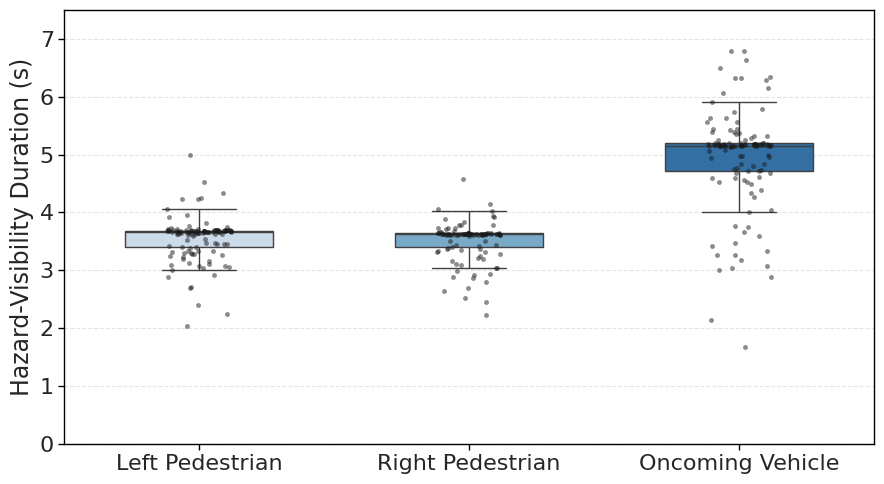


Total sample size (after quality filtering and dropna): 351
Sample size per event type:
eventType_clean
Left Pedestrian     121
Right Pedestrian    109
Oncoming Vehicle    121
Name: count, dtype: int64


In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

dataName = "/content/drive/MyDrive/Colab_Backups/Data_3sMean_IDT_beforeMat.xlsx"

# ---------- Data Setup ----------
df = pd.read_excel(dataName)

# ---------------------------------------------------------
# EYE-TRACKING DATA QUALITY FILTERING (from 1st code)
# ---------------------------------------------------------
tww_cols = [f"perValid_{i}" for i in range(31)]

pervalid_mean = df[tww_cols].mean(axis=1)

abandon_mask = pervalid_mean < 74.5
keep_mask = ~abandon_mask

n_before = len(df)
df = df[keep_mask].copy()
n_after = len(df)

print(f"Quality filtering: kept {n_after} of {n_before} rows "
      f"(removed {n_before - n_after} with perValid mean < 74.5)")

# ---------------------------------------------------------
# PREP DATA
# ---------------------------------------------------------

plot_df = df[["eventType", "epochDuration_0_x"]].copy()

plot_df["epochDuration_0_x"] = pd.to_numeric(
    plot_df["epochDuration_0_x"],
    errors="coerce"
)

plot_df = plot_df.dropna(
    subset=["eventType", "epochDuration_0_x"]
).copy()

# Optional shorter labels
label_map = {
    "EVENT_MAT_LEFT_VRU": "Left Pedestrian",
    "EVENT_MAT_ONCOMING": "Oncoming Vehicle",
    "EVENT_MAT_RIGHT_VRU": "Right Pedestrian"
}

plot_df["eventType_clean"] = (
    plot_df["eventType"]
    .map(label_map)
    .fillna(plot_df["eventType"])
)

event_order = [
    "Left Pedestrian",
    "Right Pedestrian",
    "Oncoming Vehicle"
]

# ---------------------------------------------------------
# PLOT
# ---------------------------------------------------------

sns.set_theme(style="whitegrid")

# Different shades from blue palette
palette = sns.color_palette("Blues", n_colors=3)

fig, ax = plt.subplots(figsize=(9, 5))

sns.boxplot(
    data=plot_df,
    x="eventType_clean",
    y="epochDuration_0_x",
    order=event_order,
    width=0.55,
    fliersize=0,
    palette=palette,
    linewidth=1.0,
    ax=ax,
)

sns.stripplot(
    data=plot_df,
    x="eventType_clean",
    y="epochDuration_0_x",
    order=event_order,
    jitter=0.12,
    size=3.5,
    alpha=0.5,
    color="#1A1A1A",
    ax=ax,
)

# Grid styling
ax.grid(axis="y", linestyle="--", linewidth=0.8, alpha=0.5)
ax.grid(axis="x", visible=False)

# Labels
ax.set_title("")
ax.set_xlabel("")
ax.set_ylabel("Hazard-Visibility Duration (s)", fontsize=17)

# Tick styling
ax.tick_params(axis="both", labelsize=16)

# Black frame on all sides
for spine in ax.spines.values():
    spine.set_visible(True)
    spine.set_color("black")
    spine.set_linewidth(1.0)

# Tick marks
ax.tick_params(
    axis="x",
    which="both",
    direction="out",
    length=4,
    width=1.0,
    color="black",
    bottom=True
)

ax.tick_params(
    axis="y",
    which="both",
    direction="out",
    length=4,
    width=1.0,
    color="black",
    left=True
)
plt.ylim(0,7.5)
plt.tight_layout()
plt.show()

# ---------------------------------------------------------
# SAMPLE SIZE (after plotting)
# ---------------------------------------------------------
print(f"\nTotal sample size (after quality filtering and dropna): {len(plot_df)}")
print("Sample size per event type:")
print(plot_df["eventType_clean"].value_counts().reindex(event_order))

# Feature Bundle

In [ ]:
import pandas as pd
import os
import seaborn as plt

# TW_list = range(0,31,1)
# Vel = 30
eyeDataStyle = '3sMean_IDT'
# in_dir = f"/content/drive/MyDrive/HiDrive4/ETFeatures/Model_{eyeDataStyle}"

# base_features = [
#     "sDuMean",
#     "sAmpMean",
#     "sVel2Mean",
#     "sVelMean",
#     "pdMean", "pdSd",
#     "blinkNumber",
#     "avgBlinkDuration",
#     "fixNumber",
#     "avgFixDuration",
#     "sdFixDuration",
#     "fixTE", "fixSE",
#     "FixDisperX", "FixDisperY",
#     "FixDisperE",
#     "FixMeanPosX", "FixMeanPosY",
# ]


# df = None
# all_data_wide = None

# for TW in TW_list:
#     if TW == 0:
#         in_path = os.path.join(
#             f"/content/drive/MyDrive/HiDrive4/ETFeatures/Updated_TW0_beforeMat/Model_{eyeDataStyle}",
#             f"ETFeatures_{TW}TW_{Vel}Vel.xlsx"
#         )
#     else:
#         in_path = os.path.join(in_dir, f"ETFeatures_{TW}TW_{Vel}Vel.xlsx")

#     # in_path = os.path.join(in_dir, f"ETFeatures_{TW}TW_{Vel}Vel.xlsx")

#     if not os.path.exists(in_path):
#         continue

#     # Load and Preprocess (matching your specific cleanup logic)
#     df = pd.read_excel(in_path)
#     df = AddInformation(df.copy())
#     df_ped = FilterData(df.copy())
#     # df = df_ped.copy()
#     df_vec = FilterData_vec(df.copy())
#     df = pd.concat([df_ped, df_vec], ignore_index=True)
#     df = CatPerformance(df.copy(), "Bad")

#     # Apply your specific row exclusion
#     df = df[~((df["subNumber"] == 14) & (df["runNumber"] == 4) & (df["section"] == 6))]

#     current_features = [f"{feat}_{TW}" for feat in base_features]
#     if TW == 0:
#       current_features.append("epochDuration_0")

#     base_cols = [
#         'subNumber', 'runNumber', 'section',
#     ]

#     first_only_cols = [ "Age", "License", "Gender", "automation","nback",
#         "eventType", "Mileage",'relativeRT']

#     if all_data_wide is None:
#         df_subset = df[base_cols + first_only_cols + current_features].copy()
#     else:
#         df_subset = df[base_cols + current_features].copy()

#     if all_data_wide is None:
#         all_data_wide = df_subset
#     else:
#         all_data_wide = pd.merge(all_data_wide, df_subset, on=['subNumber', 'runNumber', 'section'], how='inner')


# df2 = pd.read_excel("/content/drive/MyDrive/HiDrive4/Material/test_All_8_Extra3.xlsx")
# df_merged = all_data_wide.merge(
#     df2[
#         [
#             'subNumber','runNumber','section',
#             'visibleSpeed'
#         ]
#     ],
#     on=['subNumber','runNumber','section'],
#     how='left'
# )
# all_data_wide = df_merged

all_data_wide = pd.read_excel("/content/drive/MyDrive/Colab_Backups/Data_3sMean_IDT_beforeMat.xlsx")

df3 = pd.read_excel("/content/drive/MyDrive/HiDrive4/Material/CheckDataLoss4.xlsx")

pervalid_cols = [c for c in df3.columns if (c.startswith("perValid_") or c.startswith("epochDuration_"))]

df_merged = all_data_wide.merge(
    df3[
        ['subNumber', 'runNumber', 'section'] + pervalid_cols
    ],
    on=['subNumber', 'runNumber', 'section'],
    how='left'
)

all_data_wide = df_merged

all_data_wide.to_excel(f"/content/drive/MyDrive/Colab_Backups/Data_{eyeDataStyle}_beforeMat.xlsx",index=False)


from IPython.display import Javascript

Javascript("""
var ctx = new (window.AudioContext || window.webkitAudioContext)();

function beep(freq){
    var o = ctx.createOscillator();
    var g = ctx.createGain();
    o.connect(g);
    g.connect(ctx.destination);
    o.frequency.value = freq;
    o.start();
    g.gain.exponentialRampToValueAtTime(0.00001, ctx.currentTime + 0.4);
}

beep(600);
setTimeout(()=>beep(900),200);
setTimeout(()=>beep(1200),400);

new Notification("Done!");
""")


<IPython.core.display.Javascript object>

# Get Outer Splits Random Seeds

In [ ]:
import numpy as np
import pandas as pd
from sklearn.model_selection import StratifiedGroupKFold

n_wanted = 10
n_splits = 5
max_seed_to_check = 100000
tolerance = 0.01

dataName = "/content/drive/MyDrive/Colab_Backups/Data_3sMean_IDT_beforeMat.xlsx"
save_path = "/content/drive/MyDrive/Colab_Backups/outer_splits_first10_within1pct.xlsx"

df = pd.read_excel(dataName)

target_col = "relativeRT"
df[target_col] = pd.to_numeric(df[target_col], errors="coerce")
df = df.dropna(subset=[target_col, "eventType", "subNumber"]).copy()

# =========================================================
# BUILD TARGET ON FULL DATA
# =========================================================
df["rt85_by_event"] = df.groupby("eventType")[target_col].transform(
    lambda x: x.quantile(0.85)
)
df["RT85_cls"] = (df[target_col] >= df["rt85_by_event"]).astype(int)

print(df[["eventType", "rt85_by_event"]].drop_duplicates().sort_values("eventType"))

# =========================================================
# COUNT ABANDONED SAMPLES BEFORE FILTERING
# =========================================================
valid_cutoff = 74.5
tw_cols = [f"perValid_{i}" for i in range(31)]

pervalid_mean = df[tw_cols].mean(axis=1)

abandon_mask = pervalid_mean < valid_cutoff
keep_mask = ~abandon_mask

n_total = len(df)
n_abandon = abandon_mask.sum()
n_keep = keep_mask.sum()

n_abandon_pos = df.loc[abandon_mask, "RT85_cls"].eq(1).sum()
n_abandon_neg = df.loc[abandon_mask, "RT85_cls"].eq(0).sum()

n_keep_pos = df.loc[keep_mask, "RT85_cls"].eq(1).sum()
n_keep_neg = df.loc[keep_mask, "RT85_cls"].eq(0).sum()

print("\n===== SAMPLE FILTER SUMMARY =====")
print(f"Total samples: {n_total}")
print(f"Kept samples: {n_keep}")
print(f"Abandoned samples: {n_abandon}")
print(f"Abandoned positive: {n_abandon_pos}")
print(f"Abandoned negative: {n_abandon_neg}")
print(f"Kept positive: {n_keep_pos}")
print(f"Kept negative: {n_keep_neg}")

abandon_by_event = (
    df.loc[abandon_mask]
      .groupby(["eventType", "RT85_cls"])
      .size()
      .unstack(fill_value=0)
      .rename(columns={0: "abandon_neg", 1: "abandon_pos"})
      .reset_index()
)

print("\n===== ABANDONED SAMPLES BY EVENT TYPE =====")
print(abandon_by_event)

# =========================================================
# FILTER DATA
# =========================================================
df = df.loc[keep_mask].copy()

TW_list = [0, 13]

feature_templates = [
    "Age",
    "License", "Mileage",
    "Gender", "automation", "eventType",
    "visibleSpeed",
    "pdMean_{TW}", "pdSd_{TW}",
    "blinkNumber_{TW}",
    "avgBlinkDuration_{TW}",
    "fixNumber_{TW}",
    "avgFixDuration_{TW}",
    "fixTE_{TW}", "fixSE_{TW}",
    "FixDisperX_{TW}", "FixDisperY_{TW}",
    "FixDisperE_{TW}",
    "FixMeanPosX_{TW}", "FixMeanPosY_{TW}",
]

feature_cols = []
for c in feature_templates:
    if "{TW}" in c:
        feature_cols.extend([c.format(TW=tw) for tw in TW_list])
    else:
        feature_cols.append(c)

X = df[feature_cols].copy()
y = df["RT85_cls"].values.astype(int)
groups = df["subNumber"].values

event_arr = df["eventType"].values
all_events = sorted(pd.unique(df["eventType"]))

# =========================================================
# GLOBAL CLASS RATIO
# =========================================================
global_ratio = y.mean()
print(f"\nGlobal positive class ratio: {global_ratio:.4f}")

# =========================================================
# GLOBAL EVENT-TYPE DISTRIBUTION
# =========================================================
global_event_summary = (
    df.groupby("eventType")["RT85_cls"]
      .agg(event_total="size", event_pos="sum")
      .reset_index()
)
global_event_summary["event_neg"] = (
    global_event_summary["event_total"] - global_event_summary["event_pos"]
)
global_event_summary["event_pos_ratio"] = (
    global_event_summary["event_pos"] / global_event_summary["event_total"]
)

print("\n===== GLOBAL EVENT-TYPE CLASS DISTRIBUTION =====")
print(global_event_summary.sort_values("eventType"))

# =========================================================
# SEARCH FIRST 10 SEEDS THAT SATISFY TOLERANCE IN ALL FOLDS
# =========================================================
results = []
accepted_count = 0

for seed in range(max_seed_to_check + 1):

    cv = StratifiedGroupKFold(
        n_splits=n_splits,
        shuffle=True,
        random_state=seed
    )

    fold_pos = []
    fold_neg = []
    fold_total = []
    fold_ratio = []
    fold_groups = []
    fold_event_stats = []

    all_folds_ok = True

    for fold, (_, test_idx) in enumerate(cv.split(X, y, groups), start=1):

        y_test = y[test_idx]
        g_test = groups[test_idx]
        ev_test = event_arr[test_idx]

        unique_groups = sorted(np.unique(g_test))

        n_pos = int(np.sum(y_test == 1))
        n_neg = int(np.sum(y_test == 0))
        total = int(len(y_test))
        pos_ratio = n_pos / total if total > 0 else np.nan

        if abs(pos_ratio - global_ratio) > tolerance:
            all_folds_ok = False
            break

        fold_pos.append(n_pos)
        fold_neg.append(n_neg)
        fold_total.append(total)
        fold_ratio.append(pos_ratio)
        fold_groups.append(unique_groups)

        # event-type class distribution within this fold
        df_fold_tmp = pd.DataFrame({
            "eventType": ev_test,
            "RT85_cls": y_test
        })

        event_stats = (
            df_fold_tmp.groupby("eventType")["RT85_cls"]
            .agg(event_total="size", event_pos="sum")
            .reset_index()
        )

        event_stats["event_neg"] = event_stats["event_total"] - event_stats["event_pos"]
        event_stats["event_pos_ratio"] = event_stats["event_pos"] / event_stats["event_total"]

        event_stats = (
            pd.DataFrame({"eventType": all_events})
            .merge(event_stats, on="eventType", how="left")
            .fillna({
                "event_total": 0,
                "event_pos": 0,
                "event_neg": 0,
                "event_pos_ratio": np.nan
            })
        )

        event_stats_dict = {}
        for _, ev_row in event_stats.iterrows():
            ev = ev_row["eventType"]
            event_stats_dict[ev] = {
                "event_total": int(ev_row["event_total"]),
                "event_pos": int(ev_row["event_pos"]),
                "event_neg": int(ev_row["event_neg"]),
                "event_pos_ratio": float(ev_row["event_pos_ratio"]) if pd.notna(ev_row["event_pos_ratio"]) else np.nan
            }

        fold_event_stats.append(event_stats_dict)

    if all_folds_ok:
        ratio_errors = [abs(r - global_ratio) for r in fold_ratio]
        mean_ratio_error = float(np.mean(ratio_errors))
        max_ratio_error = float(np.max(ratio_errors))

        results.append({
            "seed": seed,
            "balance_score": mean_ratio_error,
            "mean_ratio_error": mean_ratio_error,
            "max_ratio_error": max_ratio_error,
            "fold_pos": fold_pos,
            "fold_neg": fold_neg,
            "fold_total": fold_total,
            "fold_ratio": fold_ratio,
            "fold_groups": fold_groups,
            "fold_event_stats": fold_event_stats
        })

        accepted_count += 1
        print(f"Accepted seed {seed} ({accepted_count}/{n_wanted})")

        if accepted_count >= n_wanted:
            break

if accepted_count < n_wanted:
    print(f"\nOnly found {accepted_count} seeds within tolerance={tolerance:.4f} up to seed {max_seed_to_check}.")
else:
    print(f"\nFound first {n_wanted} acceptable seeds.")

# =========================================================
# RESULTS TABLE
# =========================================================
df_balance = pd.DataFrame(results)
df_balance = df_balance.sort_values(["max_ratio_error", "mean_ratio_error", "seed"]).reset_index(drop=True)

print("\nAccepted seeds:")
print(df_balance[["seed", "mean_ratio_error", "max_ratio_error"]])

# =========================================================
# EXPAND FOLD INFO
# =========================================================
expanded_rows = []

for _, row in df_balance.iterrows():
    seed = row["seed"]

    for i in range(n_splits):
        out_row = {
            "seed": seed,
            "fold": i + 1,
            "n_pos": row["fold_pos"][i],
            "n_neg": row["fold_neg"][i],
            "n_total": row["fold_total"][i],
            "pos_ratio": row["fold_ratio"][i],
            "abs_error_from_global_ratio": abs(row["fold_ratio"][i] - global_ratio),
            "groups": row["fold_groups"][i]
        }

        fold_event_stats = row["fold_event_stats"][i]
        for ev in all_events:
            ev_safe = str(ev).replace(" ", "_").replace("/", "_")
            out_row[f"{ev_safe}_total"] = fold_event_stats[ev]["event_total"]
            out_row[f"{ev_safe}_pos"] = fold_event_stats[ev]["event_pos"]
            out_row[f"{ev_safe}_neg"] = fold_event_stats[ev]["event_neg"]
            out_row[f"{ev_safe}_pos_ratio"] = fold_event_stats[ev]["event_pos_ratio"]

        expanded_rows.append(out_row)

df_folds = pd.DataFrame(expanded_rows)

# =========================================================
# SHOW ACCEPTED SEED STRUCTURE
# =========================================================
print("\nAccepted fold structures:")
print(df_folds[["seed", "fold", "n_pos", "n_neg", "n_total", "pos_ratio", "abs_error_from_global_ratio"]])

# =========================================================
# LONG FORMAT EVENT SUMMARY
# =========================================================
event_rows = []

for _, row in df_balance.iterrows():
    seed = row["seed"]

    for i in range(n_splits):
        fold_event_stats = row["fold_event_stats"][i]

        for ev in all_events:
            event_rows.append({
                "seed": seed,
                "fold": i + 1,
                "eventType": ev,
                "event_total": fold_event_stats[ev]["event_total"],
                "event_pos": fold_event_stats[ev]["event_pos"],
                "event_neg": fold_event_stats[ev]["event_neg"],
                "event_pos_ratio": fold_event_stats[ev]["event_pos_ratio"]
            })

df_event_long = pd.DataFrame(event_rows)

# =========================================================
# SAVE RESULTS
# =========================================================
with pd.ExcelWriter(save_path) as writer:
    df_balance.to_excel(writer, sheet_name="accepted_seed_ranking", index=False)
    df_folds.to_excel(writer, sheet_name="fold_structure", index=False)
    df_event_long.to_excel(writer, sheet_name="eventtype_structure_long", index=False)
    global_event_summary.to_excel(writer, sheet_name="global_eventtype_summary", index=False)

print(f"\nSaved results to {save_path}")

               eventType  rt85_by_event
1     EVENT_MAT_LEFT_VRU        2.25168
266   EVENT_MAT_ONCOMING        1.02830
0    EVENT_MAT_RIGHT_VRU        2.25166

===== SAMPLE FILTER SUMMARY =====
Total samples: 401
Kept samples: 351
Abandoned samples: 50
Abandoned positive: 14
Abandoned negative: 36
Kept positive: 47
Kept negative: 304

===== ABANDONED SAMPLES BY EVENT TYPE =====
RT85_cls            eventType  abandon_neg  abandon_pos
0          EVENT_MAT_LEFT_VRU           13            5
1          EVENT_MAT_ONCOMING            8            6
2         EVENT_MAT_RIGHT_VRU           15            3

Global positive class ratio: 0.1339

===== GLOBAL EVENT-TYPE CLASS DISTRIBUTION =====
             eventType  event_total  event_pos  event_neg  event_pos_ratio
0   EVENT_MAT_LEFT_VRU          121         16        105         0.132231
1   EVENT_MAT_ONCOMING          121         15        106         0.123967
2  EVENT_MAT_RIGHT_VRU          109         16         93         0.146789
Accepte

# Visualize Results

## Classifier

LASSO Single: Highest mean AUC at TW=11, AUC=0.7173, SE=0.0064
LASSO Combined: Highest mean AUC at TW=11, AUC=0.7027, SE=0.0096
XGBoost Single: Highest mean AUC at TW=13, AUC=0.6383, SE=0.0110
XGBoost Combined: Highest mean AUC at TW=13, AUC=0.7149, SE=0.0115


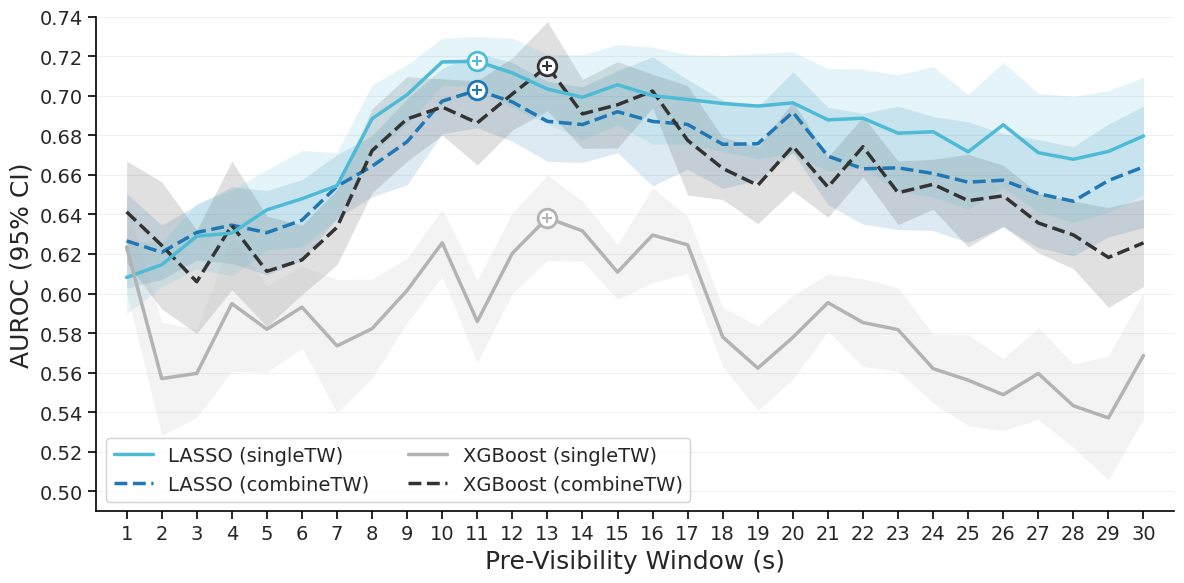

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors

# =========================================================
# 1. Load data
# =========================================================
df1 = pd.read_excel("/content/drive/MyDrive/Colab_Backups/XGBC/XGBC_combineTW.xlsx")
df1["combined"] = 1
df1["model"] = "XGBoost"

df2 = pd.read_excel("/content/drive/MyDrive/Colab_Backups/XGBC/XGBC_singleTW.xlsx")
df2["combined"] = 0
df2["model"] = "XGBoost"

df3 = pd.read_excel("/content/drive/MyDrive/Colab_Backups/LR_test/LRC_combineTW.xlsx")
df3["combined"] = 1
df3["model"] = "LASSO"

df4 = pd.read_excel("/content/drive/MyDrive/Colab_Backups/LR_test/LRC_singleTW.xlsx")
df4["combined"] = 0
df4["model"] = "LASSO"

df = pd.concat([df1, df2, df3, df4], ignore_index=True)

# =========================================================
# 2. Filter seeds
# =========================================================
selected_seeds = [
    3558, 6687, 6836, 7862, 11033,
    13285, 22075, 22163, 23858, 30690
]

df = df[df["seed"].isin(selected_seeds)].copy()

# =========================================================
# 3. Clean summary rows
# =========================================================
df["outer_fold"] = df["outer_fold"].astype(str)

summary_df = df[df["outer_fold"] == "SUMMARY"].copy()
summary_df["TW"] = pd.to_numeric(summary_df["TW"], errors="coerce")
summary_df["AUC"] = pd.to_numeric(summary_df["AUC"], errors="coerce")
summary_df = summary_df.dropna(subset=["TW", "AUC"])
summary_df = summary_df[summary_df["TW"] != 0].copy()

# =========================================================
# 4. Aggregate across seeds
# =========================================================
agg_df = (
    summary_df
    .groupby(["TW", "combined", "model"], as_index=False)
    .agg(
        mean_AUC=("AUC", "mean"),
        sd_AUC=("AUC", "std"),
        n_seeds=("AUC", "count")
    )
    .sort_values(["model", "combined", "TW"])
)

agg_df["sd_AUC"] = agg_df["sd_AUC"].fillna(0)
agg_df["se_AUC"] = agg_df["sd_AUC"] / np.sqrt(agg_df["n_seeds"])

# =========================================================
# 5. Find best TW per model/configuration
# =========================================================
peak_records = []

for (model, combined), grp in agg_df.groupby(["model", "combined"]):
    idx = grp["mean_AUC"].idxmax()

    best_tw = agg_df.loc[idx, "TW"]
    best_auc = agg_df.loc[idx, "mean_AUC"]
    best_se = agg_df.loc[idx, "se_AUC"]

    label = f"{model} {'Combined' if combined == 1 else 'Single'}"
    print(f"{label}: Highest mean AUC at TW={best_tw}, AUC={best_auc:.4f}, SE={best_se:.4f}")

    peak_records.append({
        "model": model,
        "combined": combined,
        "TW": best_tw,
        "AUC": best_auc
    })

# =========================================================
# 6. Style configuration
# =========================================================
colors = {
    ("LASSO", 0): "#4DBBD5",
    ("LASSO", 1): "#1F77B4",
    ("XGBoost", 0): "#b3b3b3",
    ("XGBoost", 1): "#333333",
}

linestyles = {
    0: "-",
    1: "--",
}

marker_map = {
    ("LASSO", 0): "^",
    ("LASSO", 1): "^",
    ("XGBoost", 0): "s",
    ("XGBoost", 1): "s",
}

# =========================================================
# 7. Plot
# =========================================================
plt.rcParams["font.family"] = "sans-serif"

fig, ax = plt.subplots(figsize=(12, 6))

order = [
    ("LASSO", 1),
    ("XGBoost", 1),
    ("LASSO", 0),
    ("XGBoost", 0),
]

for (model, combined) in order:
    grp = agg_df[
        (agg_df["model"] == model) &
        (agg_df["combined"] == combined)
    ].sort_values("TW")

    if grp.empty:
        continue

    color = colors[(model, combined)]

    label = f"{model} ({'combineTW' if combined == 1 else 'singleTW'})"
    ci95 = 1.96 * grp["se_AUC"]

    # ---- Confidence band ----
    ax.fill_between(
        grp["TW"],
        grp["mean_AUC"] - ci95,
        grp["mean_AUC"] + ci95,
        facecolor=color,
        alpha=0.15,
        linewidth=0,
        zorder=1
    )

    # ---- Main line ----
    ax.plot(
        grp["TW"],
        grp["mean_AUC"],
        # marker=marker_map[(model, combined)],
        # markevery=3,                           # 👈 marker every 3 TW (less clutter)
        linestyle=linestyles[combined],
        linewidth=2.5,
        markersize=7,                          # 👈 slightly bigger to compensate
        color=color,
        markerfacecolor=color,
        markeredgecolor=color,
        markeredgewidth=0.8,
        label=label,
        zorder=3
    )

# =========================================================
# 8. Highlight peak TW per configuration
# =========================================================
for rec in peak_records:
    line_color = colors[(rec["model"], rec["combined"])]

    # Outer ring
    ax.scatter(
        rec["TW"],
        rec["AUC"],
        s=180,
        facecolor="white",
        edgecolor=line_color,
        linewidth=2.0,
        zorder=4
    )

    # Plus sign in middle
    ax.scatter(
        rec["TW"],
        rec["AUC"],
        s=50,
        marker="+",
        color=line_color,
        linewidth=1.5,
        zorder=5
    )

# =========================================================
# 9. Axes styling
# =========================================================

ax.set_xlabel("Pre-Visibility Window (s)", fontsize=18)
ax.set_ylabel("AUROC (95% CI)", fontsize=18)

ax.set_xticks(np.arange(1, 31, 1))
ax.set_ylim(0.49, 0.74)
ax.set_yticks(np.arange(0.5, 0.741, 0.02))
ax.margins(x=0.03)

# No gridlines
ax.grid(False)

# Black ticks
# Black ticks — force them on
ax.tick_params(
    axis="x",
    labelsize=14,
    width=1.2,
    length=6,
    direction="out",
    color="black",
    bottom=True,        # explicitly enable bottom ticks
    top=False,
)
ax.tick_params(
    axis="y",
    labelsize=14,
    width=1.2,
    length=6,
    direction="out",
    color="black",
    left=True,          # explicitly enable left ticks
    right=False,
)

# Black axis spines; keep only left and bottom
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
for side in ("left", "bottom"):
    ax.spines[side].set_visible(True)
    ax.spines[side].set_linewidth(1.2)
    ax.spines[side].set_color("black")

# =========================================================
# 10. Legend (moved to lower-left to avoid peak overlap)
# =========================================================
handles, labels = ax.get_legend_handles_labels()
label_to_handle = dict(zip(labels, handles))

ordered_labels = [
    "LASSO (singleTW)",
    "LASSO (combineTW)",
    "XGBoost (singleTW)",
    "XGBoost (combineTW)",
]

ordered_handles = [label_to_handle[l] for l in ordered_labels]

ax.legend(
    ordered_handles,
    ordered_labels,
    ncol=2,
    loc="lower left",                           # 👈 was "upper right"
    fontsize=14,
    frameon=True,
    framealpha=0.85,                            # 👈 less transparent
    edgecolor="0.8"
)
ax.grid(axis="y", linewidth=0.5, alpha=0.4)  # then re-enable y-only
plt.tight_layout()
plt.show()

## Regressor

LASSO Single: Lowest mean RMSE at TW=19, RMSE=0.8800, SE=0.0034
LASSO Combined: Lowest mean RMSE at TW=20, RMSE=0.8691, SE=0.0044
XGBoost Single: Lowest mean RMSE at TW=21, RMSE=0.8874, SE=0.0058
XGBoost Combined: Lowest mean RMSE at TW=21, RMSE=0.8507, SE=0.0048


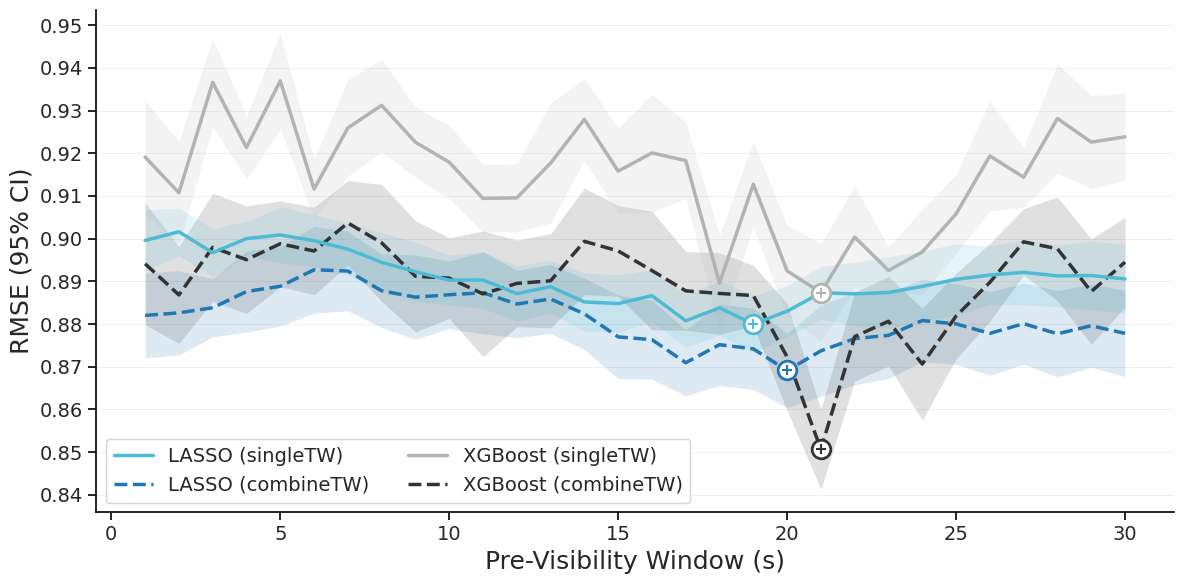

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors


# =========================================================
# 1. Load data
# =========================================================
df1 = pd.read_excel("/content/drive/MyDrive/Colab_Backups/XGBR/XGBR_combineTW.xlsx")
df1["combined"] = 1
df1["model"] = "XGBoost"

df2 = pd.read_excel("/content/drive/MyDrive/Colab_Backups/XGBR/XGBR_singleTW.xlsx")
df2["combined"] = 0
df2["model"] = "XGBoost"

df3 = pd.read_excel("/content/drive/MyDrive/Colab_Backups/LRR/LRR_combineTW.xlsx")
df3["combined"] = 1
df3["model"] = "LASSO"

df4 = pd.read_excel("/content/drive/MyDrive/Colab_Backups/LRR/LRR_singleTW.xlsx")
df4["combined"] = 0
df4["model"] = "LASSO"

df = pd.concat([df1, df2, df3, df4], ignore_index=True)

# =========================================================
# 2. Filter seeds
# =========================================================
selected_seeds = [261,452,285,966,786, 1423, 3789, 5602, 8741, 11905]

df = df[df["seed"].isin(selected_seeds)].copy()

# =========================================================
# 3. Clean summary rows
# =========================================================
df["outer_fold"] = df["outer_fold"].astype(str)

summary_df = df[df["outer_fold"] == "SUMMARY"].copy()
summary_df["TW"]   = pd.to_numeric(summary_df["TW"], errors="coerce")
summary_df["RMSE"] = pd.to_numeric(summary_df["RMSE"], errors="coerce")   # ← was AUC
summary_df = summary_df.dropna(subset=["TW", "RMSE"])
summary_df = summary_df[summary_df["TW"] != 0].copy()

# =========================================================
# 4. Aggregate across seeds
# =========================================================
agg_df = (
    summary_df
    .groupby(["TW", "combined", "model"], as_index=False)
    .agg(
        mean_RMSE=("RMSE", "mean"),
        sd_RMSE  =("RMSE", "std"),
        n_seeds  =("RMSE", "count"),
    )
    .sort_values(["model", "combined", "TW"])
)

agg_df["sd_RMSE"] = agg_df["sd_RMSE"].fillna(0)
agg_df["se_RMSE"] = agg_df["sd_RMSE"] / np.sqrt(agg_df["n_seeds"])

# =========================================================
# 5. Find BEST (= LOWEST) RMSE per model/configuration
# =========================================================
peak_records = []

for (model, combined), grp in agg_df.groupby(["model", "combined"]):
    idx = grp["mean_RMSE"].idxmin()                                    # ← idxmin, not idxmax

    best_tw   = agg_df.loc[idx, "TW"]
    best_rmse = agg_df.loc[idx, "mean_RMSE"]
    best_se   = agg_df.loc[idx, "se_RMSE"]

    label = f"{model} {'Combined' if combined == 1 else 'Single'}"
    print(f"{label}: Lowest mean RMSE at TW={best_tw}, RMSE={best_rmse:.4f}, SE={best_se:.4f}")

    peak_records.append({
        "model": model,
        "combined": combined,
        "TW": best_tw,
        "RMSE": best_rmse,
    })

# =========================================================
# 6. Style configuration
# =========================================================
colors = {
    ("LASSO",   0): "#4DBBD5",
    ("LASSO",   1): "#1F77B4",
    ("XGBoost", 0): "#b3b3b3",
    ("XGBoost", 1): "#333333",
}

linestyles = {
    0: "-",
    1: "--",
}

marker_map = {
    ("LASSO",   0): "^",
    ("LASSO",   1): "^",
    ("XGBoost", 0): "s",
    ("XGBoost", 1): "s",
}

# =========================================================
# 7. Plot
# =========================================================
plt.rcParams["font.family"] = "sans-serif"

fig, ax = plt.subplots(figsize=(12, 6))

order = [
    ("LASSO",   1),
    ("XGBoost", 1),
    ("LASSO",   0),
    ("XGBoost", 0),
]

for (model, combined) in order:
    grp = agg_df[
        (agg_df["model"] == model) &
        (agg_df["combined"] == combined)
    ].sort_values("TW")

    if grp.empty:
        continue

    color = colors[(model, combined)]
    label = f"{model} ({'combineTW' if combined == 1 else 'singleTW'})"
    ci95 = 1.96 * grp["se_RMSE"]                                       # ← se_RMSE

    # ---- Confidence band ----
    ax.fill_between(
        grp["TW"],
        grp["mean_RMSE"] - ci95,
        grp["mean_RMSE"] + ci95,
        facecolor=color,
        alpha=0.15,
        linewidth=0,
        zorder=1,
    )

    # ---- Main line ----
    ax.plot(
        grp["TW"],
        grp["mean_RMSE"],
        # marker=marker_map[(model, combined)],
        # markevery=3,
        linestyle=linestyles[combined],
        linewidth=2.5,
        markersize=7,
        color=color,
        markerfacecolor=color,
        markeredgecolor=color,
        markeredgewidth=0.8,
        label=label,
        zorder=3,
    )

# =========================================================
# 8. Highlight best (lowest) RMSE per configuration
# =========================================================
for rec in peak_records:
    line_color = colors[(rec["model"], rec["combined"])]

    # Outer ring
    ax.scatter(
        rec["TW"],
        rec["RMSE"],
        s=180,
        facecolor="white",
        edgecolor=line_color,
        linewidth=2.0,
        zorder=4,
    )

    # Plus sign in middle
    ax.scatter(
        rec["TW"],
        rec["RMSE"],
        s=50,
        marker="+",
        color=line_color,
        linewidth=1.5,
        zorder=5,
    )

# =========================================================
# 9. Axes styling
# =========================================================
ax.set_xlabel("Pre-Visibility Window (s)", fontsize=18)
ax.set_ylabel("RMSE (95% CI)", fontsize=18)
# No gridlines
ax.grid(False)

# Black ticks — force them on (overrides any seaborn/style suppression)
ax.tick_params(
    axis="x",
    labelsize=14,
    width=1.2,
    length=6,
    direction="out",
    color="black",
    bottom=True,
    top=False,
)
ax.tick_params(
    axis="y",
    labelsize=14,
    width=1.2,
    length=6,
    direction="out",
    color="black",
    left=True,
    right=False,
)

# Black axis spines; keep only left and bottom
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
for side in ("left", "bottom"):
    ax.spines[side].set_visible(True)
    ax.spines[side].set_linewidth(1.2)
    ax.spines[side].set_color("black")

# =========================================================
# 10. Legend
# =========================================================
handles, labels = ax.get_legend_handles_labels()
label_to_handle = dict(zip(labels, handles))

ordered_labels = [
    "LASSO (singleTW)",
    "LASSO (combineTW)",
    "XGBoost (singleTW)",
    "XGBoost (combineTW)",
]

ordered_handles = [label_to_handle[l] for l in ordered_labels]

# Best RMSE is at the bottom — put legend in upper-left to avoid peak overlap
ax.legend(
    ordered_handles,
    ordered_labels,
    ncol=2,
    loc="lower left",                                                  # ← was "lower left"
    fontsize=14,
    frameon=True,
    framealpha=0.85,
    edgecolor="0.8",
)

ax.grid(axis="y", linewidth=0.5, alpha=0.4)  # then re-enable y-only

from matplotlib.ticker import MultipleLocator
ax.yaxis.set_major_locator(MultipleLocator(0.01))


plt.tight_layout()
plt.show()

# AUC Curves

In [ ]:
import json
import os
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import t
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    roc_auc_score,
    roc_curve,
    precision_recall_curve,
    average_precision_score
)
from xgboost import XGBClassifier


# =========================================================
# 1) HELPERS
# =========================================================
def build_feature_cols(TWs):
    feature_templates = [
        "Age", "License", "Mileage",
        "Gender", "automation", "eventType",
        "visibleSpeed",
        "pdMean_{TW}", "pdSd_{TW}",
        "blinkNumber_{TW}",
        "avgBlinkDuration_{TW}",
        "fixNumber_{TW}",
        "avgFixDuration_{TW}",
        "fixTE_{TW}", "fixSE_{TW}",
        "FixDisperX_{TW}", "FixDisperY_{TW}",
        "FixDisperE_{TW}",
        "FixMeanPosX_{TW}", "FixMeanPosY_{TW}",
    ]

    feature_cols = []
    for c in feature_templates:
        if "{TW}" in c:
            feature_cols.extend([c.format(TW=tw) for tw in TWs])
        else:
            feature_cols.append(c)

    return feature_cols


def fit_outer_onehot(X_train_raw, X_test_raw, cat_cols):
    X_train_raw = X_train_raw.copy()
    X_test_raw = X_test_raw.copy()

    use_cat = [c for c in cat_cols if c in X_train_raw.columns]

    for c in use_cat:
        train_cats = pd.Index(X_train_raw[c].dropna().unique())
        dtype = pd.CategoricalDtype(categories=train_cats, ordered=False)
        X_train_raw[c] = X_train_raw[c].astype(dtype)
        X_test_raw[c] = X_test_raw[c].astype(dtype)

    X_train_oh = pd.get_dummies(X_train_raw, columns=use_cat, drop_first=False)
    X_test_oh = pd.get_dummies(X_test_raw, columns=use_cat, drop_first=False)
    X_test_oh = X_test_oh.reindex(columns=X_train_oh.columns, fill_value=0)

    return X_train_oh.astype(np.float32), X_test_oh.astype(np.float32)


def ensure_categorical_dtype_from_train(train_df, test_df, cat_cols):
    train_df = train_df.copy()
    test_df = test_df.copy()

    for col in cat_cols:
        if col in train_df.columns:
            cats = pd.Index(train_df[col].dropna().unique())
            dtype = pd.CategoricalDtype(categories=cats, ordered=False)
            train_df[col] = train_df[col].astype(dtype)
            test_df[col] = test_df[col].astype(dtype)

    return train_df, test_df


def load_lasso_params(base_dir, model_dir, seed, tw, outer_fold):
    folder = os.path.join(base_dir, model_dir)

    candidates = glob.glob(os.path.join(
        folder,
        f"lr_seed_{seed:02d}_*TW_{tw:02d}_outerfold_{outer_fold:02d}_meta.json"
    ))

    if len(candidates) == 0:
        candidates = glob.glob(os.path.join(
            folder,
            f"lr_seed_{seed:02d}_TW_{tw:02d}_outerfold_{outer_fold:02d}_meta.json"
        ))

    if len(candidates) == 0:
        raise FileNotFoundError(
            f"No LASSO metadata found for seed={seed}, TW={tw}, fold={outer_fold}"
        )

    path = sorted(candidates, key=len)[0]

    with open(path, "r", encoding="utf-8") as f:
        meta = json.load(f)

    return meta["best_params"], meta, path


def load_xgb_params(base_dir, model_dir, seed, tw, outer_fold):
    folder = os.path.join(base_dir, model_dir)

    candidates = glob.glob(os.path.join(
        folder,
        f"xgb_seed_{seed:02d}_*TW_{tw:02d}_outerfold_{outer_fold:02d}_meta.json"
    ))

    if len(candidates) == 0:
        candidates = glob.glob(os.path.join(
            folder,
            f"xgb_seed_{seed:02d}_TW_{tw:02d}_outerfold_{outer_fold:02d}_meta.json"
        ))

    if len(candidates) == 0:
        raise FileNotFoundError(
            f"No XGB metadata found for seed={seed}, TW={tw}, fold={outer_fold}"
        )

    path = sorted(candidates, key=len)[0]

    with open(path, "r", encoding="utf-8") as f:
        meta = json.load(f)

    return meta["best_params"], meta, path


# =========================================================
# 2) SETTINGS
# =========================================================
dataName = "/content/drive/MyDrive/Colab_Backups/Data_3sMean_IDT_beforeMat.xlsx"

REFIT_RS = [
    3558, 6687, 6836, 7862, 11033,
    13285, 22075, 22163, 23858, 30690
]
inner_seeds = pd.read_excel(
    "/content/drive/MyDrive/Colab_Backups/inner_cv_seed_search_results_all10seeds.xlsx"
)

inner_seeds_ok = inner_seeds[inner_seeds["accepted"] == True].copy()

outer_splits = 5
target_col = "relativeRT"
cat_names = ["Gender", "automation", "eventType"]

CONFIGS = {
    "LASSO Single TW": {
        "algo": "lasso",
        "base_dir": "/content/drive/MyDrive/Colab_Backups/LR_test",
        "model_dir": "LRC_model_singleTW",
        "targetTW": 11,
        "TWs": [11]
    },
    "LASSO Combined TW": {
        "algo": "lasso",
        "base_dir": "/content/drive/MyDrive/Colab_Backups/LR_test",
        "model_dir": "LRC_model_combineTW",
        "targetTW": 11,
        "TWs": [0, 11]
    },
    "XGB Combined TW": {
        "algo": "xgb",
        "base_dir": "/content/drive/MyDrive/Colab_Backups/XGBC",
        "model_dir": "XGB_model_combineTW",
        "targetTW": 13,
        "TWs": [0, 13]
    },
      "XGB Single TW": {
        "algo": "xgb",
        "base_dir": "/content/drive/MyDrive/Colab_Backups/XGBC",
        "model_dir": "XGB_model_singleTW",
        "targetTW": 13,
        "TWs": [13]
    },
}


# =========================================================
# 3) LOAD + PREP DATA
# =========================================================
df = pd.read_excel(dataName)

allowed_events = {
    "EVENT_MAT_RIGHT_VRU",
    "EVENT_MAT_LEFT_VRU",
    "EVENT_MAT_ONCOMING"
}

unexpected = set(df["eventType"].dropna().unique()) - allowed_events
if unexpected:
    raise ValueError(f"Unexpected eventType(s): {unexpected}")

df[target_col] = pd.to_numeric(df[target_col], errors="coerce")
df = df.dropna(subset=[target_col, "eventType", "subNumber"]).copy()

df["rt85_by_event"] = df.groupby("eventType")[target_col].transform(
    lambda x: x.quantile(0.85)
)

df["RT85_cls"] = (df[target_col] >= df["rt85_by_event"]).astype(int)

tww_cols = [f"perValid_{i}" for i in range(31)]
df = df[df[tww_cols].mean(axis=1) >= 74.5].copy()

y = df["RT85_cls"].values.astype(int)
groups = df["subNumber"].values
y_strat = y.copy()

print(f"Final N = {len(df)}")
print("Class counts:")
print(pd.Series(y).value_counts().sort_index())
print("Class proportions:")
print(pd.Series(y).value_counts(normalize=True).sort_index())


# =========================================================
# 4) REFIT FUNCTION WITH ROC + PR
# =========================================================
def run_refit_pipeline(config_name, config):
    print("\n" + "#" * 80)
    print(f"Running: {config_name}")
    print("#" * 80)

    algo = config["algo"]
    base_dir = config["base_dir"]
    model_dir = config["model_dir"]
    targetTW = config["targetTW"]
    TWs = config["TWs"]

    feature_cols = build_feature_cols(TWs)
    X = df[feature_cols].copy()

    seed_results = {}
    seed_interp_tprs = {}
    seed_interp_precisions = {}

    mean_fpr = np.linspace(0, 1, 1001)
    mean_recall_grid = np.linspace(0, 1, 1001)

    for rs in REFIT_RS:
        outer_cv = StratifiedGroupKFold(
            n_splits=outer_splits,
            shuffle=True,
            random_state=rs
        )

        fold_aucs = []
        fold_aps = []
        fold_interp_tprs = []
        fold_interp_precisions = []

        for outer_fold, (train_idx, test_idx) in enumerate(
            outer_cv.split(X, y_strat, groups),
            start=1
        ):
            X_train = X.iloc[train_idx].copy()
            X_test = X.iloc[test_idx].copy()

            y_train = y[train_idx]
            y_test = y[test_idx]

            if algo == "lasso":
                best_params, meta, meta_path = load_lasso_params(
                    base_dir, model_dir, rs, targetTW, outer_fold
                )

                X_train_proc, X_test_proc = fit_outer_onehot(
                    X_train, X_test, cat_names
                )

                imputer = SimpleImputer(strategy="median")

                X_train_proc = pd.DataFrame(
                    imputer.fit_transform(X_train_proc),
                    columns=X_train_proc.columns,
                    index=X_train_proc.index
                )

                X_test_proc = pd.DataFrame(
                    imputer.transform(X_test_proc),
                    columns=X_test_proc.columns,
                    index=X_test_proc.index
                )

                scaler = StandardScaler()

                X_train_proc = pd.DataFrame(
                    scaler.fit_transform(X_train_proc),
                    columns=X_train_proc.columns,
                    index=X_train_proc.index
                )

                X_test_proc = pd.DataFrame(
                    scaler.transform(X_test_proc),
                    columns=X_test_proc.columns,
                    index=X_test_proc.index
                )

                model = LogisticRegression(
                    **best_params
                )

            elif algo == "xgb":
                best_params, meta, meta_path = load_xgb_params(
                    base_dir, model_dir, rs, targetTW, outer_fold
                )

                X_train_proc, X_test_proc = ensure_categorical_dtype_from_train(
                    X_train, X_test, cat_names
                )

                model = XGBClassifier(**best_params)

            else:
                raise ValueError(f"Unknown algo: {algo}")

            model.fit(X_train_proc, y_train)
            y_prob = model.predict_proba(X_test_proc)[:, 1]

            # -------------------------
            # AUROC
            # -------------------------
            auc = roc_auc_score(y_test, y_prob)
            fold_aucs.append(auc)

            fpr, tpr_vals, _ = roc_curve(y_test, y_prob)

            interp_tpr = np.interp(mean_fpr, fpr, tpr_vals)
            interp_tpr[0] = 0.0
            interp_tpr[-1] = 1.0

            fold_interp_tprs.append(interp_tpr)

            # -------------------------
            # AUPR / Average Precision
            # -------------------------
            ap = average_precision_score(y_test, y_prob)
            fold_aps.append(ap)

            precision, recall, _ = precision_recall_curve(y_test, y_prob)

            # sklearn returns recall in decreasing order
            recall_rev = recall[::-1]
            precision_rev = precision[::-1]

            # remove duplicate recall values for interpolation stability
            pr_df = pd.DataFrame({
                "recall": recall_rev,
                "precision": precision_rev
            })

            pr_df = pr_df.groupby("recall", as_index=False)["precision"].max()
            pr_df = pr_df.sort_values("recall")

            interp_precision = np.interp(
                mean_recall_grid,
                pr_df["recall"].values,
                pr_df["precision"].values
            )

            fold_interp_precisions.append(interp_precision)

            print(
                f"{config_name} | seed={rs} | fold={outer_fold} | "
                f"AUROC={auc:.4f} | AP={ap:.4f} | "
                f"meta={os.path.basename(meta_path)}"
            )

        seed_results[rs] = {
            "fold_aucs": fold_aucs,
            "fold_aps": fold_aps,
            "mean_auc": float(np.mean(fold_aucs)),
            "sd_auc": float(np.std(fold_aucs, ddof=1)),
            "mean_ap": float(np.mean(fold_aps)),
            "sd_ap": float(np.std(fold_aps, ddof=1))
        }

        seed_interp_tprs[rs] = np.mean(fold_interp_tprs, axis=0)
        seed_interp_tprs[rs][0] = 0.0
        seed_interp_tprs[rs][-1] = 1.0

        seed_interp_precisions[rs] = np.mean(fold_interp_precisions, axis=0)

    # =====================================================
    # Seed-level AUROC summary
    # =====================================================
    seed_mean_aucs = np.array([
        seed_results[rs]["mean_auc"] for rs in REFIT_RS
    ])

    seed_mean_aps = np.array([
        seed_results[rs]["mean_ap"] for rs in REFIT_RS
    ])

    n = len(REFIT_RS)
    tcrit = t.ppf(0.975, df=n - 1)

    mean_auc = seed_mean_aucs.mean()
    sd_auc = seed_mean_aucs.std(ddof=1)
    se_auc = sd_auc / np.sqrt(n)

    ci_auc_lower = max(0, mean_auc - tcrit * se_auc)
    ci_auc_upper = min(1, mean_auc + tcrit * se_auc)

    mean_ap = seed_mean_aps.mean()
    sd_ap = seed_mean_aps.std(ddof=1)
    se_ap = sd_ap / np.sqrt(n)

    ci_ap_lower = max(0, mean_ap - tcrit * se_ap)
    ci_ap_upper = min(1, mean_ap + tcrit * se_ap)

    # =====================================================
    # ROC CI across seeds
    # =====================================================
    seed_tprs = np.vstack([
        seed_interp_tprs[rs] for rs in REFIT_RS
    ])

    mean_tpr = seed_tprs.mean(axis=0)
    mean_tpr[0] = 0.0
    mean_tpr[-1] = 1.0

    se_tpr = seed_tprs.std(axis=0, ddof=1) / np.sqrt(n)

    lower_tpr = np.clip(mean_tpr - tcrit * se_tpr, 0, 1)
    upper_tpr = np.clip(mean_tpr + tcrit * se_tpr, 0, 1)

    # =====================================================
    # PR CI across seeds
    # =====================================================
    seed_precisions = np.vstack([
        seed_interp_precisions[rs] for rs in REFIT_RS
    ])

    mean_precision = seed_precisions.mean(axis=0)

    se_precision = seed_precisions.std(axis=0, ddof=1) / np.sqrt(n)

    lower_precision = np.clip(
        mean_precision - tcrit * se_precision,
        0,
        1
    )

    upper_precision = np.clip(
        mean_precision + tcrit * se_precision,
        0,
        1
    )

    print("\n" + "=" * 70)
    print(f"SUMMARY: {config_name}")
    print("=" * 70)
    print(f"Mean AUROC = {mean_auc:.4f}")
    print(f"SD AUROC   = {sd_auc:.4f}")
    print(f"95% CI     = [{ci_auc_lower:.4f}, {ci_auc_upper:.4f}]")
    print(f"Mean AP    = {mean_ap:.4f}")
    print(f"SD AP      = {sd_ap:.4f}")
    print(f"95% CI AP  = [{ci_ap_lower:.4f}, {ci_ap_upper:.4f}]")

    return {
        "config_name": config_name,

        "mean_fpr": mean_fpr,
        "mean_tpr": mean_tpr,
        "lower_tpr": lower_tpr,
        "upper_tpr": upper_tpr,

        "mean_recall_grid": mean_recall_grid,
        "mean_precision": mean_precision,
        "lower_precision": lower_precision,
        "upper_precision": upper_precision,

        "seed_mean_aucs": seed_mean_aucs,
        "mean_auc": mean_auc,
        "sd_auc": sd_auc,
        "ci_auc_lower": ci_auc_lower,
        "ci_auc_upper": ci_auc_upper,

        "seed_mean_aps": seed_mean_aps,
        "mean_ap": mean_ap,
        "sd_ap": sd_ap,
        "ci_ap_lower": ci_ap_lower,
        "ci_ap_upper": ci_ap_upper,

        "seed_results": seed_results
    }


# =========================================================
# 5) RUN ALL CONFIGURATIONS
# =========================================================
results = {}

for config_name, config in CONFIGS.items():
    results[config_name] = run_refit_pipeline(config_name, config)


# =========================================================
# 6) SUMMARY TABLE
# =========================================================
summary_df = pd.DataFrame([
    {
        "Configuration": name,
        "Mean_AUROC": res["mean_auc"],
        "SD_AUROC": res["sd_auc"],
        "AUROC_CI95_lower": res["ci_auc_lower"],
        "AUROC_CI95_upper": res["ci_auc_upper"],
        "Mean_AP": res["mean_ap"],
        "SD_AP": res["sd_ap"],
        "AP_CI95_lower": res["ci_ap_lower"],
        "AP_CI95_upper": res["ci_ap_upper"]
    }
    for name, res in results.items()
])

print("\nSUMMARY TABLE")
print(summary_df)

# =========================================================
# 6.5) SAVE PLOTTING DATA AS CSV (for customizable replotting)
# =========================================================
save_dir = "/content/drive/MyDrive/Colab_Backups/plot_data"
os.makedirs(save_dir, exist_ok=True)

for config_name, res in results.items():
    # File-safe name
    safe_name = config_name.replace(" ", "_")

    # One row per x-value, columns for mean + CI bounds (ROC and PR combined)
    curve_df = pd.DataFrame({
        "fpr": res["mean_fpr"],
        "tpr_mean": res["mean_tpr"],
        "tpr_lower": res["lower_tpr"],
        "tpr_upper": res["upper_tpr"],
        "recall": res["mean_recall_grid"],
        "precision_mean": res["mean_precision"],
        "precision_lower": res["lower_precision"],
        "precision_upper": res["upper_precision"],
    })

    curve_path = os.path.join(save_dir, f"curves_{safe_name}.csv")
    curve_df.to_csv(curve_path, index=False)
    print(f"Saved curves → {curve_path}")

    # Per-seed metric values (useful for any later boxplots, t-tests, etc.)
    seed_df = pd.DataFrame({
        "seed": REFIT_RS,
        "mean_auc": res["seed_mean_aucs"],
        "mean_ap": res["seed_mean_aps"],
    })

    seed_path = os.path.join(save_dir, f"seeds_{safe_name}.csv")
    seed_df.to_csv(seed_path, index=False)
    print(f"Saved seed data → {seed_path}")

# Summary table (one row per config)
summary_path = os.path.join(save_dir, "summary.csv")
summary_df.to_csv(summary_path, index=False)
print(f"Saved summary → {summary_path}")

# Class-imbalance baseline for PR chance line
baseline_df = pd.DataFrame({
    "baseline_precision": [float(np.mean(y))],
    "n_seeds": [len(REFIT_RS)],
    "outer_splits": [outer_splits],
    "n_samples": [len(y)],
    "n_positive": [int(y.sum())],
})
baseline_path = os.path.join(save_dir, "meta.csv")
baseline_df.to_csv(baseline_path, index=False)
print(f"Saved meta → {baseline_path}")

# =========================================================
# 7) ROC PLOT
# =========================================================
colors = {
    "LASSO Single TW": "#4DBBD5",
    "LASSO Combined TW": "#1F77B4",
    "XGB Single TW": "#999999",      # 👈 lighter grey
    "XGB Combined TW": "#333333"
}

band_colors = {
    "LASSO Single TW": "#4DBBD5",
    "LASSO Combined TW": "#1F77B4",
    "XGB Single TW": "#D9D9D9",      # 👈 lighter band
    "XGB Combined TW": "#BDBDBD"
}

linestyles = {
    "LASSO Single TW": "-",
    "LASSO Combined TW": "--",
    "XGB Single TW": "-",
    "XGB Combined TW": "--"
}

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

ax_roc = axes[0]
ax_pr = axes[1]

for config_name, res in results.items():
    ax_roc.fill_between(
        res["mean_fpr"],
        res["lower_tpr"],
        res["upper_tpr"],
        color=band_colors[config_name],
        alpha=0.22,
        linewidth=0
    )

    ax_roc.step(
        res["mean_fpr"],
        res["mean_tpr"],
        where="post",
        color=colors[config_name],
        linestyle=linestyles[config_name],
        linewidth=2.2,
        label=(
            f"{config_name} - AUROC: {res['mean_auc']:.2f} "
            f"({res['ci_auc_lower']:.2f}–{res['ci_auc_upper']:.2f})"
        )
    )


ax_roc.set_xlabel("False Positive Rate", fontsize=16)
ax_roc.set_ylabel("True Positive Rate", fontsize=16)
ax_roc.set_xlim(0, 1)
ax_roc.set_ylim(0, 1)
ax_roc.grid(True, linewidth=0.5, alpha=0.4)
ax_roc.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="gray",
    linewidth=1.5,
    label="Chance level = 0.50"
)
handles, labels = ax_roc.get_legend_handles_labels()

desired_order = [
    "LASSO Single",
    "LASSO Combined",
    "XGB Single",
    "XGB Combined",
    "Chance level"
]

ordered_handles = []
ordered_labels = []

for key in desired_order:
    for h, l in zip(handles, labels):
        if key in l:
            ordered_handles.append(h)
            ordered_labels.append(l)

ax_roc.legend(
    ordered_handles,
    ordered_labels,
    loc="lower right",
    fontsize=10,
    frameon=True
)

# =========================================================
# 8) PRECISION-RECALL / AUPR PLOT
# =========================================================
baseline_precision = np.mean(y)

ax_pr.axhline(
    baseline_precision,
    color="gray",
    linestyle="--",
    linewidth=1.5,
    label=f"Chance level = {baseline_precision:.2f}"
)

for config_name, res in results.items():
    ax_pr.fill_between(
        res["mean_recall_grid"],
        res["lower_precision"],
        res["upper_precision"],
        color=band_colors[config_name],
        alpha=0.22,
        linewidth=0
    )

    ax_pr.step(
        res["mean_recall_grid"],
        res["mean_precision"],
        where="post",
        color=colors[config_name],
        linestyle=linestyles[config_name],
        linewidth=2.2,
        label=(
            f"{config_name} - AP: {res['mean_ap']:.2f} "
            f"({res['ci_ap_lower']:.2f}–{res['ci_ap_upper']:.2f})"
        )
    )

ax_pr.set_xlabel("Recall", fontsize=16)
ax_pr.set_ylabel("Precision", fontsize=16)
ax_pr.set_xlim(0, 1)
ax_pr.set_ylim(0, 1)
ax_pr.grid(True, linewidth=0.5, alpha=0.4)

for ax in axes:
    ax.tick_params(axis="both", labelsize=13)
    for spine in ax.spines.values():
        spine.set_linewidth(1.2)

desired_order = [
    "LASSO Single",
    "LASSO Combined",
    "XGB Single",
    "XGB Combined",
    "Chance level"
]

def apply_ordered_legend(ax, loc):
    handles, labels = ax.get_legend_handles_labels()

    ordered_handles = []
    ordered_labels = []

    for key in desired_order:
        for h, l in zip(handles, labels):
            if key in l:
                ordered_handles.append(h)
                ordered_labels.append(l)

    ax.legend(
        ordered_handles,
        ordered_labels,
        loc=loc,
        fontsize=10,
        frameon=True
    )

apply_ordered_legend(ax_roc, "lower right")
apply_ordered_legend(ax_pr, "upper right")

plt.tight_layout()
plt.show()




Final N = 351
Class counts:
0    304
1     47
Name: count, dtype: int64
Class proportions:
0    0.866097
1    0.133903
Name: proportion, dtype: float64

################################################################################
Running: LASSO Single TW
################################################################################
LASSO Single TW | seed=3558 | fold=1 | AUROC=0.6043 | AP=0.1690 | meta=lr_seed_3558_TW_11_outerfold_01_meta.json


KeyboardInterrupt: 

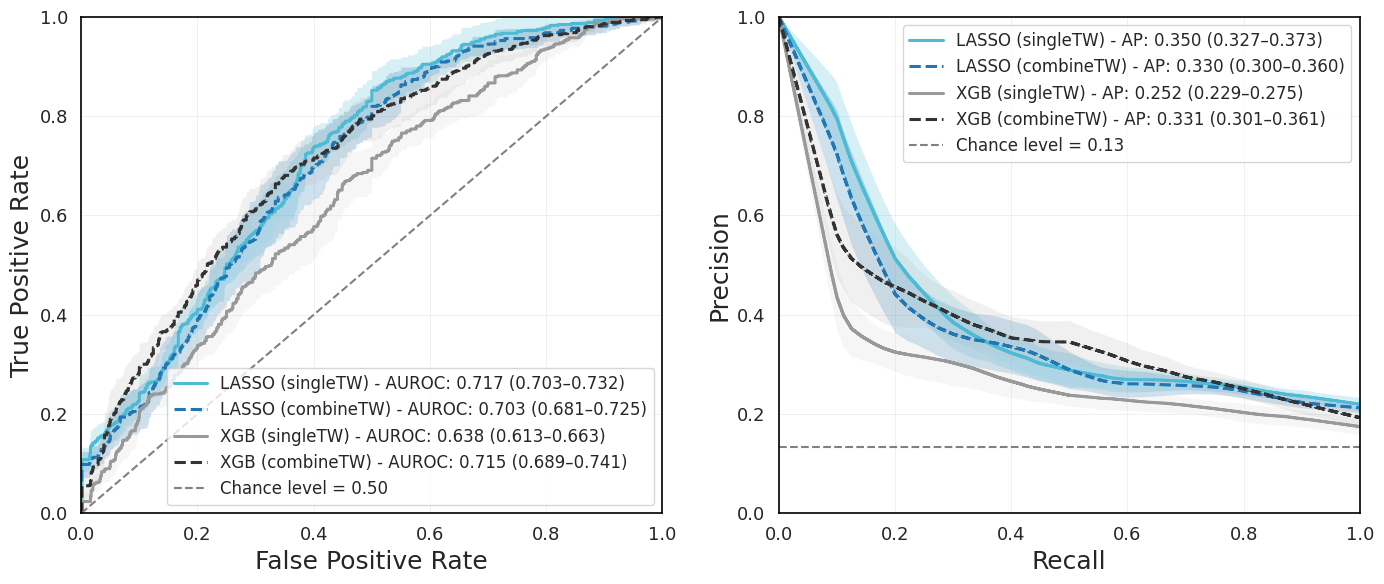

In [ ]:
"""
Replot ROC + PR curves from saved CSV data.

Reads files written by section 6.5 of the original pipeline:
    /content/drive/MyDrive/Colab_Backups/plot_data/
        curves_LASSO_Single_TW.csv
        curves_LASSO_Combined_TW.csv
        curves_XGB_Single_TW.csv
        curves_XGB_Combined_TW.csv
        summary.csv
        meta.csv

No model refitting required.
"""

import os
import pandas as pd
import matplotlib.pyplot as plt


# =========================================================
# Settings
# =========================================================
DATA_DIR = "/content/drive/MyDrive/Colab_Backups/plot_data"

# Plotting order — must match what's in summary.csv
CONFIG_ORDER = [
    "LASSO Single TW",
    "LASSO Combined TW",
    "XGB Single TW",
    "XGB Combined TW",
]
# Display name override for legend labels (parentheses around TW descriptor)
DISPLAY_NAME = {
    "LASSO Single TW":   "LASSO (singleTW)",
    "LASSO Combined TW": "LASSO (combineTW)",
    "XGB Single TW":     "XGB (singleTW)",
    "XGB Combined TW":   "XGB (combineTW)",
}
colors = {
    "LASSO Single TW":  "#4DBBD5",
    "LASSO Combined TW": "#1F77B4",
    "XGB Single TW":    "#999999",
    "XGB Combined TW":  "#333333",
}

band_colors = {
    "LASSO Single TW":  "#4DBBD5",
    "LASSO Combined TW": "#1F77B4",
    "XGB Single TW":    "#D9D9D9",
    "XGB Combined TW":  "#BDBDBD",
}

linestyles = {
    "LASSO Single TW":  "-",
    "LASSO Combined TW": "--",
    "XGB Single TW":    "-",
    "XGB Combined TW":  "--",
}


# =========================================================
# Load saved data
# =========================================================
summary_df = pd.read_csv(os.path.join(DATA_DIR, "summary.csv"))
meta_df    = pd.read_csv(os.path.join(DATA_DIR, "meta.csv"))

baseline_precision = float(meta_df["baseline_precision"].iloc[0])

# Load all curve CSVs into a dict keyed by config name
curves = {}
for config_name in CONFIG_ORDER:
    safe_name = config_name.replace(" ", "_")
    path = os.path.join(DATA_DIR, f"curves_{safe_name}.csv")
    curves[config_name] = pd.read_csv(path)



def get_summary_row(config_name):
    """Return the row of summary_df matching this config."""
    row = summary_df[summary_df["Configuration"] == config_name].iloc[0]
    return row


# =========================================================
# Plot
# =========================================================
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
ax_roc, ax_pr = axes

# ---------- ROC ----------
for config_name in CONFIG_ORDER:
    d = curves[config_name]
    s = get_summary_row(config_name)

    ax_roc.fill_between(
        d["fpr"], d["tpr_lower"], d["tpr_upper"],
        color=band_colors[config_name],
        alpha=0.22, linewidth=0,
    )
    ax_roc.step(
        d["fpr"], d["tpr_mean"],
        where="post",
        color=colors[config_name],
        linestyle=linestyles[config_name],
        linewidth=2.2,
        # label=(
        #     f"{config_name} - AUROC: {s['Mean_AUROC']:.2f} "
        #     f"({s['AUROC_CI95_lower']:.2f}–{s['AUROC_CI95_upper']:.2f})"
        # ),
        label=(
            f"{DISPLAY_NAME[config_name]} - AUROC: {s['Mean_AUROC']:.3f} "
            f"({s['AUROC_CI95_lower']:.3f}–{s['AUROC_CI95_upper']:.3f})"
        ),
    )

ax_roc.plot([0, 1], [0, 1],
            linestyle="--", color="gray", linewidth=1.5,
            label="Chance level = 0.50")

ax_roc.set_xlabel("False Positive Rate", fontsize=18)
ax_roc.set_ylabel("True Positive Rate", fontsize=18)
ax_roc.set_xlim(0, 1)
ax_roc.set_ylim(0, 1)
ax_roc.grid(True, linewidth=0.5, alpha=0.4)

# ---------- PR ----------
ax_pr.axhline(
    baseline_precision,
    color="gray", linestyle="--", linewidth=1.5,
    label=f"Chance level = {baseline_precision:.2f}",
)

for config_name in CONFIG_ORDER:
    d = curves[config_name]
    s = get_summary_row(config_name)

    ax_pr.fill_between(
        d["recall"], d["precision_lower"], d["precision_upper"],
        color=band_colors[config_name],
        alpha=0.22, linewidth=0,
    )
    ax_pr.step(
        d["recall"], d["precision_mean"],
        where="post",
        color=colors[config_name],
        linestyle=linestyles[config_name],
        linewidth=2.2,
        # label=(
        #     f"{config_name} - AP: {s['Mean_AP']:.2f} "
        #     f"({s['AP_CI95_lower']:.2f}–{s['AP_CI95_upper']:.2f})"
        # ),
        label=(
            f"{DISPLAY_NAME[config_name]} - AP: {s['Mean_AP']:.3f} "
            f"({s['AP_CI95_lower']:.3f}–{s['AP_CI95_upper']:.3f})"
        ),
    )

ax_pr.set_xlabel("Recall", fontsize=18)
ax_pr.set_ylabel("Precision", fontsize=18)
ax_pr.set_xlim(0, 1)
ax_pr.set_ylim(0, 1)
ax_pr.grid(True, linewidth=0.5, alpha=0.4)

# ---------- Styling ----------
for ax in axes:
    ax.tick_params(axis="both", labelsize=13, color="black")
    for spine in ax.spines.values():
        spine.set_linewidth(1.2)
        spine.set_color("black")        # black frame instead of grey

# ---------- Subplot labels (a, b) ----------
# ---------- Subplot labels (a, b) ----------
# for ax, letter in zip([ax_roc, ax_pr], ["A", "B"]):
#     ax.text(
#         -0.16, 1.05, letter,
#         transform=ax.transAxes,
#         fontsize=22, fontweight="bold",
#         va="top", ha="left",
#     )

# ---------- Ordered legends ----------
# DESIRED_ORDER_KEYS = [
#     "LASSO Single",
#     "LASSO Combined",
#     "XGB Single",
#     "XGB Combined",
#     "Chance level",
# ]

DESIRED_ORDER_KEYS = [
    "LASSO (singleTW)",
    "LASSO (combineTW)",
    "XGB (singleTW)",
    "XGB (combineTW)",
    "Chance level",
]

def apply_ordered_legend(ax, loc):
    handles, labels = ax.get_legend_handles_labels()
    ordered_handles, ordered_labels = [], []
    for key in DESIRED_ORDER_KEYS:
        for h, l in zip(handles, labels):
            if key in l:
                ordered_handles.append(h)
                ordered_labels.append(l)
    ax.legend(ordered_handles, ordered_labels,
              loc=loc, fontsize=12, frameon=True)

apply_ordered_legend(ax_roc, "lower right")
apply_ordered_legend(ax_pr,  "upper right")

plt.tight_layout()
fig.subplots_adjust(wspace=0.2)
plt.show()

# Calculate AUPR and BA

In [ ]:
from sklearn.metrics import balanced_accuracy_score
import json
import os
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import t
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    roc_auc_score,
    roc_curve,
    precision_recall_curve,
    average_precision_score
)
from xgboost import XGBClassifier


# =========================================================
# 1) HELPERS
# =========================================================
def build_feature_cols(TWs):
    feature_templates = [
        "Age", "License", "Mileage",
        "Gender", "automation", "eventType",
        "visibleSpeed",
        "pdMean_{TW}", "pdSd_{TW}",
        "blinkNumber_{TW}",
        "avgBlinkDuration_{TW}",
        "fixNumber_{TW}",
        "avgFixDuration_{TW}",
        "fixTE_{TW}", "fixSE_{TW}",
        "FixDisperX_{TW}", "FixDisperY_{TW}",
        "FixDisperE_{TW}",
        "FixMeanPosX_{TW}", "FixMeanPosY_{TW}",
    ]

    feature_cols = []
    for c in feature_templates:
        if "{TW}" in c:
            feature_cols.extend([c.format(TW=tw) for tw in TWs])
        else:
            feature_cols.append(c)

    return feature_cols


def fit_outer_onehot(X_train_raw, X_test_raw, cat_cols):
    X_train_raw = X_train_raw.copy()
    X_test_raw = X_test_raw.copy()

    use_cat = [c for c in cat_cols if c in X_train_raw.columns]

    for c in use_cat:
        train_cats = pd.Index(X_train_raw[c].dropna().unique())
        dtype = pd.CategoricalDtype(categories=train_cats, ordered=False)
        X_train_raw[c] = X_train_raw[c].astype(dtype)
        X_test_raw[c] = X_test_raw[c].astype(dtype)

    X_train_oh = pd.get_dummies(X_train_raw, columns=use_cat, drop_first=False)
    X_test_oh = pd.get_dummies(X_test_raw, columns=use_cat, drop_first=False)
    X_test_oh = X_test_oh.reindex(columns=X_train_oh.columns, fill_value=0)

    return X_train_oh.astype(np.float32), X_test_oh.astype(np.float32)


def ensure_categorical_dtype_from_train(train_df, test_df, cat_cols):
    train_df = train_df.copy()
    test_df = test_df.copy()

    for col in cat_cols:
        if col in train_df.columns:
            cats = pd.Index(train_df[col].dropna().unique())
            dtype = pd.CategoricalDtype(categories=cats, ordered=False)
            train_df[col] = train_df[col].astype(dtype)
            test_df[col] = test_df[col].astype(dtype)

    return train_df, test_df


def load_lasso_params(base_dir, model_dir, seed, tw, outer_fold):
    folder = os.path.join(base_dir, model_dir)

    candidates = glob.glob(os.path.join(
        folder,
        f"lr_seed_{seed:02d}_*TW_{tw:02d}_outerfold_{outer_fold:02d}_meta.json"
    ))

    if len(candidates) == 0:
        candidates = glob.glob(os.path.join(
            folder,
            f"lr_seed_{seed:02d}_TW_{tw:02d}_outerfold_{outer_fold:02d}_meta.json"
        ))

    if len(candidates) == 0:
        raise FileNotFoundError(
            f"No LASSO metadata found for seed={seed}, TW={tw}, fold={outer_fold}"
        )

    path = sorted(candidates, key=len)[0]

    with open(path, "r", encoding="utf-8") as f:
        meta = json.load(f)

    return meta["best_params"], meta, path


def load_xgb_params(base_dir, model_dir, seed, tw, outer_fold):
    folder = os.path.join(base_dir, model_dir)

    candidates = glob.glob(os.path.join(
        folder,
        f"xgb_seed_{seed:02d}_*TW_{tw:02d}_outerfold_{outer_fold:02d}_meta.json"
    ))

    if len(candidates) == 0:
        candidates = glob.glob(os.path.join(
            folder,
            f"xgb_seed_{seed:02d}_TW_{tw:02d}_outerfold_{outer_fold:02d}_meta.json"
        ))

    if len(candidates) == 0:
        raise FileNotFoundError(
            f"No XGB metadata found for seed={seed}, TW={tw}, fold={outer_fold}"
        )

    path = sorted(candidates, key=len)[0]

    with open(path, "r", encoding="utf-8") as f:
        meta = json.load(f)

    return meta["best_params"], meta, path


# =========================================================
# 2) SETTINGS
# =========================================================
dataName = "/content/drive/MyDrive/Colab_Backups/Data_3sMean_IDT_beforeMat.xlsx"

REFIT_RS = [
    3558, 6687, 6836, 7862, 11033,
    13285, 22075, 22163, 23858, 30690
]
inner_seeds = pd.read_excel(
    "/content/drive/MyDrive/Colab_Backups/inner_cv_seed_search_results_all10seeds.xlsx"
)

inner_seeds_ok = inner_seeds[inner_seeds["accepted"] == True].copy()

outer_splits = 5
target_col = "relativeRT"
cat_names = ["Gender", "automation", "eventType"]

CONFIGS = {
    "LASSO Single TW": {
        "algo": "lasso",
        "base_dir": "/content/drive/MyDrive/Colab_Backups/LR_test",
        "model_dir": "LRC_model_singleTW",
        "targetTW": 11,
        "TWs": [11]
    },
    "LASSO Combined TW": {
        "algo": "lasso",
        "base_dir": "/content/drive/MyDrive/Colab_Backups/LR_test",
        "model_dir": "LRC_model_combineTW",
        "targetTW": 11,
        "TWs": [0, 11]
    },
    "XGB Combined TW": {
        "algo": "xgb",
        "base_dir": "/content/drive/MyDrive/Colab_Backups/XGBC",
        "model_dir": "XGB_model_combineTW",
        "targetTW": 13,
        "TWs": [0, 13]
    },
      "XGB Single TW": {
        "algo": "xgb",
        "base_dir": "/content/drive/MyDrive/Colab_Backups/XGBC",
        "model_dir": "XGB_model_singleTW",
        "targetTW": 13,
        "TWs": [13]
    },
}


# =========================================================
# 3) LOAD + PREP DATA
# =========================================================
df = pd.read_excel(dataName)

allowed_events = {
    "EVENT_MAT_RIGHT_VRU",
    "EVENT_MAT_LEFT_VRU",
    "EVENT_MAT_ONCOMING"
}

unexpected = set(df["eventType"].dropna().unique()) - allowed_events
if unexpected:
    raise ValueError(f"Unexpected eventType(s): {unexpected}")

df[target_col] = pd.to_numeric(df[target_col], errors="coerce")
df = df.dropna(subset=[target_col, "eventType", "subNumber"]).copy()

df["rt85_by_event"] = df.groupby("eventType")[target_col].transform(
    lambda x: x.quantile(0.85)
)

df["RT85_cls"] = (df[target_col] >= df["rt85_by_event"]).astype(int)

tww_cols = [f"perValid_{i}" for i in range(31)]
df = df[df[tww_cols].mean(axis=1) >= 74.5].copy()

y = df["RT85_cls"].values.astype(int)
groups = df["subNumber"].values
y_strat = y.copy()

print(f"Final N = {len(df)}")
print("Class counts:")
print(pd.Series(y).value_counts().sort_index())
print("Class proportions:")
print(pd.Series(y).value_counts(normalize=True).sort_index())


def run_refit_pipeline(config_name, config):
    print("\n" + "#" * 80)
    print(f"Running: {config_name}")
    print("#" * 80)

    algo = config["algo"]
    base_dir = config["base_dir"]
    model_dir = config["model_dir"]
    targetTW = config["targetTW"]
    TWs = config["TWs"]

    feature_cols = build_feature_cols(TWs)
    X = df[feature_cols].copy()

    seed_results = {}
    seed_interp_tprs = {}
    seed_interp_precisions = {}
    fold_rows = []

    mean_fpr = np.linspace(0, 1, 1001)
    mean_recall_grid = np.linspace(0, 1, 1001)

    for rs in REFIT_RS:
        outer_cv = StratifiedGroupKFold(
            n_splits=outer_splits,
            shuffle=True,
            random_state=rs
        )

        fold_aucs = []
        fold_aps = []
        fold_bal_accs = []
        fold_interp_tprs = []
        fold_interp_precisions = []

        for outer_fold, (train_idx, test_idx) in enumerate(
            outer_cv.split(X, y_strat, groups),
            start=1
        ):
            X_train = X.iloc[train_idx].copy()
            X_test = X.iloc[test_idx].copy()

            y_train = y[train_idx]
            y_test = y[test_idx]

            if algo == "lasso":
                best_params, meta, meta_path = load_lasso_params(
                    base_dir, model_dir, rs, targetTW, outer_fold
                )

                X_train_proc, X_test_proc = fit_outer_onehot(
                    X_train, X_test, cat_names
                )

                imputer = SimpleImputer(strategy="median")

                X_train_proc = pd.DataFrame(
                    imputer.fit_transform(X_train_proc),
                    columns=X_train_proc.columns,
                    index=X_train_proc.index
                )

                X_test_proc = pd.DataFrame(
                    imputer.transform(X_test_proc),
                    columns=X_test_proc.columns,
                    index=X_test_proc.index
                )

                scaler = StandardScaler()

                X_train_proc = pd.DataFrame(
                    scaler.fit_transform(X_train_proc),
                    columns=X_train_proc.columns,
                    index=X_train_proc.index
                )

                X_test_proc = pd.DataFrame(
                    scaler.transform(X_test_proc),
                    columns=X_test_proc.columns,
                    index=X_test_proc.index
                )

                model = LogisticRegression(
                    **best_params
                )

            elif algo == "xgb":
                best_params, meta, meta_path = load_xgb_params(
                    base_dir, model_dir, rs, targetTW, outer_fold
                )

                X_train_proc, X_test_proc = ensure_categorical_dtype_from_train(
                    X_train, X_test, cat_names
                )

                model = XGBClassifier(**best_params)

            else:
                raise ValueError(f"Unknown algo: {algo}")

            model.fit(X_train_proc, y_train)
            y_prob = model.predict_proba(X_test_proc)[:, 1]

            # -------------------------
            # AUROC
            # -------------------------
            auc = roc_auc_score(y_test, y_prob)
            fold_aucs.append(auc)

            fpr, tpr_vals, _ = roc_curve(y_test, y_prob)

            interp_tpr = np.interp(mean_fpr, fpr, tpr_vals)
            interp_tpr[0] = 0.0
            interp_tpr[-1] = 1.0
            fold_interp_tprs.append(interp_tpr)

            # -------------------------
            # AUPR / Average Precision
            # -------------------------
            ap = average_precision_score(y_test, y_prob)
            fold_aps.append(ap)

            precision, recall, _ = precision_recall_curve(y_test, y_prob)

            recall_rev = recall[::-1]
            precision_rev = precision[::-1]

            pr_df = pd.DataFrame({
                "recall": recall_rev,
                "precision": precision_rev
            })

            pr_df = pr_df.groupby("recall", as_index=False)["precision"].max()
            pr_df = pr_df.sort_values("recall")

            interp_precision = np.interp(
                mean_recall_grid,
                pr_df["recall"].values,
                pr_df["precision"].values
            )

            fold_interp_precisions.append(interp_precision)

            # -------------------------
            # Balanced Accuracy with INNER-CV threshold selection
            # -------------------------
            lookup = inner_seeds_ok[
                (inner_seeds_ok["outer_seed"] == rs) &
                (inner_seeds_ok["outer_fold_idx"] == (outer_fold - 1))
            ]

            if lookup.empty:
                raise ValueError(
                    f"No accepted inner seed found for outer_seed={rs}, "
                    f"outer_fold_idx={outer_fold - 1}"
                )

            if len(lookup) > 1:
                raise ValueError(
                    f"Multiple accepted inner seeds found for outer_seed={rs}, "
                    f"outer_fold_idx={outer_fold - 1}"
                )

            selected_inner_seed = int(lookup["accepted_inner_seed"].iloc[0])

            print(
                f"Using accepted_inner_seed={selected_inner_seed} "
                f"for outer_seed={rs}, outer_fold={outer_fold}"
            )
            thresholds = np.linspace(0.01, 0.99, 50)

            inner_cv = StratifiedGroupKFold(
                n_splits=3,
                shuffle=True,
                random_state=selected_inner_seed
            )

            threshold_scores = []

            outer_train_groups = groups[train_idx]

            for thr in thresholds:
                inner_scores = []

                for inner_train_idx, inner_val_idx in inner_cv.split(
                    X_train_proc, y_train, outer_train_groups
                ):
                    X_inner_train = X_train_proc.iloc[inner_train_idx]
                    X_inner_val = X_train_proc.iloc[inner_val_idx]

                    y_inner_train = y_train[inner_train_idx]
                    y_inner_val = y_train[inner_val_idx]

                    # clone model
                    model_inner = model.__class__(**model.get_params())
                    model_inner.fit(X_inner_train, y_inner_train)

                    y_val_prob = model_inner.predict_proba(X_inner_val)[:, 1]
                    y_val_pred = (y_val_prob >= thr).astype(int)

                    inner_scores.append(
                        balanced_accuracy_score(y_inner_val, y_val_pred)
                    )

                threshold_scores.append(np.mean(inner_scores))

            best_thr = thresholds[np.argmax(threshold_scores)]

            # Apply to OUTER test set
            y_pred = (y_prob >= best_thr).astype(int)
            bal_acc = balanced_accuracy_score(y_test, y_pred)
            fold_bal_accs.append(bal_acc)

            fold_rows.append({
                "Configuration": config_name,
                "seed": rs,
                "outer_fold": outer_fold,
                "AUROC": float(auc),
                "AP": float(ap),
                "Balanced_Accuracy": float(bal_acc),
                "best_threshold": float(best_thr),
                "n_test": int(len(y_test)),
                "n_pos_test": int(np.sum(y_test == 1)),
                "n_neg_test": int(np.sum(y_test == 0))
            })

            print(
                f"{config_name} | seed={rs} | fold={outer_fold} | "
                f"AUROC={auc:.4f} | AP={ap:.4f} | "
                f"BalAcc={bal_acc:.4f} | "
                f"meta={os.path.basename(meta_path)}"
            )

        seed_results[rs] = {
            "fold_aucs": fold_aucs,
            "fold_aps": fold_aps,
            "fold_bal_accs": fold_bal_accs,
            "mean_auc": float(np.mean(fold_aucs)),
            "sd_auc": float(np.std(fold_aucs, ddof=1)),
            "mean_ap": float(np.mean(fold_aps)),
            "sd_ap": float(np.std(fold_aps, ddof=1)),
            "mean_bal_acc": float(np.mean(fold_bal_accs)),
            "sd_bal_acc": float(np.std(fold_bal_accs, ddof=1))
        }

        seed_interp_tprs[rs] = np.mean(fold_interp_tprs, axis=0)
        seed_interp_tprs[rs][0] = 0.0
        seed_interp_tprs[rs][-1] = 1.0

        seed_interp_precisions[rs] = np.mean(fold_interp_precisions, axis=0)

    # =====================================================
    # Seed-level summaries
    # =====================================================
    seed_mean_aucs = np.array([
        seed_results[rs]["mean_auc"] for rs in REFIT_RS
    ])

    seed_mean_aps = np.array([
        seed_results[rs]["mean_ap"] for rs in REFIT_RS
    ])

    seed_mean_bal_accs = np.array([
        seed_results[rs]["mean_bal_acc"] for rs in REFIT_RS
    ])

    n = len(REFIT_RS)
    tcrit = t.ppf(0.975, df=n - 1)

    mean_auc = seed_mean_aucs.mean()
    sd_auc = seed_mean_aucs.std(ddof=1)
    se_auc = sd_auc / np.sqrt(n)
    ci_auc_lower = max(0, mean_auc - tcrit * se_auc)
    ci_auc_upper = min(1, mean_auc + tcrit * se_auc)

    mean_ap = seed_mean_aps.mean()
    sd_ap = seed_mean_aps.std(ddof=1)
    se_ap = sd_ap / np.sqrt(n)
    ci_ap_lower = max(0, mean_ap - tcrit * se_ap)
    ci_ap_upper = min(1, mean_ap + tcrit * se_ap)

    mean_bal_acc = seed_mean_bal_accs.mean()
    sd_bal_acc = seed_mean_bal_accs.std(ddof=1)
    se_bal_acc = sd_bal_acc / np.sqrt(n)
    ci_bal_acc_lower = max(0, mean_bal_acc - tcrit * se_bal_acc)
    ci_bal_acc_upper = min(1, mean_bal_acc + tcrit * se_bal_acc)

    # =====================================================
    # ROC CI across seeds
    # =====================================================
    seed_tprs = np.vstack([
        seed_interp_tprs[rs] for rs in REFIT_RS
    ])

    mean_tpr = seed_tprs.mean(axis=0)
    mean_tpr[0] = 0.0
    mean_tpr[-1] = 1.0

    se_tpr = seed_tprs.std(axis=0, ddof=1) / np.sqrt(n)
    lower_tpr = np.clip(mean_tpr - tcrit * se_tpr, 0, 1)
    upper_tpr = np.clip(mean_tpr + tcrit * se_tpr, 0, 1)

    # =====================================================
    # PR CI across seeds
    # =====================================================
    seed_precisions = np.vstack([
        seed_interp_precisions[rs] for rs in REFIT_RS
    ])

    mean_precision = seed_precisions.mean(axis=0)
    se_precision = seed_precisions.std(axis=0, ddof=1) / np.sqrt(n)

    lower_precision = np.clip(
        mean_precision - tcrit * se_precision,
        0,
        1
    )

    upper_precision = np.clip(
        mean_precision + tcrit * se_precision,
        0,
        1
    )

    print("\n" + "=" * 70)
    print(f"SUMMARY: {config_name}")
    print("=" * 70)
    print(f"Mean AUROC = {mean_auc:.4f}")
    print(f"SD AUROC   = {sd_auc:.4f}")
    print(f"95% CI     = [{ci_auc_lower:.4f}, {ci_auc_upper:.4f}]")
    print(f"Mean AP    = {mean_ap:.4f}")
    print(f"SD AP      = {sd_ap:.4f}")
    print(f"95% CI AP  = [{ci_ap_lower:.4f}, {ci_ap_upper:.4f}]")
    print(f"Mean BalAcc = {mean_bal_acc:.4f}")
    print(f"SD BalAcc   = {sd_bal_acc:.4f}")
    print(f"95% CI BalAcc = [{ci_bal_acc_lower:.4f}, {ci_bal_acc_upper:.4f}]")

    fold_df = pd.DataFrame(fold_rows)

    fold_save_path = (
        f"/content/drive/MyDrive/Colab_Backups/"
        f"{config_name.replace(' ', '_')}_fold_results.xlsx"
    )

    fold_df.to_excel(fold_save_path, index=False)
    print(f"Saved fold-level results: {fold_save_path}")

    return {
        "config_name": config_name,
        "fold_df": fold_df,

        "mean_fpr": mean_fpr,
        "mean_tpr": mean_tpr,
        "lower_tpr": lower_tpr,
        "upper_tpr": upper_tpr,


        "mean_recall_grid": mean_recall_grid,
        "mean_precision": mean_precision,
        "lower_precision": lower_precision,
        "upper_precision": upper_precision,

        "seed_mean_aucs": seed_mean_aucs,
        "mean_auc": mean_auc,
        "sd_auc": sd_auc,
        "ci_auc_lower": ci_auc_lower,
        "ci_auc_upper": ci_auc_upper,

        "seed_mean_aps": seed_mean_aps,
        "mean_ap": mean_ap,
        "sd_ap": sd_ap,
        "ci_ap_lower": ci_ap_lower,
        "ci_ap_upper": ci_ap_upper,

        "seed_mean_bal_accs": seed_mean_bal_accs,
        "mean_bal_acc": mean_bal_acc,
        "sd_bal_acc": sd_bal_acc,
        "ci_bal_acc_lower": ci_bal_acc_lower,
        "ci_bal_acc_upper": ci_bal_acc_upper,

        "seed_results": seed_results
    }

results = {}

for config_name, config in CONFIGS.items():
    results[config_name] = run_refit_pipeline(config_name, config)


summary_df = pd.DataFrame([
    {
        "Configuration": name,
        "Mean_AUROC": res["mean_auc"],
        "SD_AUROC": res["sd_auc"],
        "AUROC_CI95_lower": res["ci_auc_lower"],
        "AUROC_CI95_upper": res["ci_auc_upper"],

        "Mean_AP": res["mean_ap"],
        "SD_AP": res["sd_ap"],
        "AP_CI95_lower": res["ci_ap_lower"],
        "AP_CI95_upper": res["ci_ap_upper"],

        "Mean_Balanced_Accuracy": res["mean_bal_acc"],
        "SD_Balanced_Accuracy": res["sd_bal_acc"],
        "Balanced_Accuracy_CI95_lower": res["ci_bal_acc_lower"],
        "Balanced_Accuracy_CI95_upper": res["ci_bal_acc_upper"]
    }
    for name, res in results.items()
])

print("\nSUMMARY TABLE")
print(summary_df)

Final N = 351
Class counts:
0    304
1     47
Name: count, dtype: int64
Class proportions:
0    0.866097
1    0.133903
Name: proportion, dtype: float64

################################################################################
Running: LASSO Single TW
################################################################################
Using accepted_inner_seed=121 for outer_seed=3558, outer_fold=1
LASSO Single TW | seed=3558 | fold=1 | AUROC=0.6043 | AP=0.1690 | BalAcc=0.4123 | meta=lr_seed_3558_TW_11_outerfold_01_meta.json
Using accepted_inner_seed=74 for outer_seed=3558, outer_fold=2
LASSO Single TW | seed=3558 | fold=2 | AUROC=0.5564 | AP=0.1543 | BalAcc=0.5686 | meta=lr_seed_3558_TW_11_outerfold_02_meta.json
Using accepted_inner_seed=167 for outer_seed=3558, outer_fold=3
LASSO Single TW | seed=3558 | fold=3 | AUROC=0.7698 | AP=0.4005 | BalAcc=0.7198 | meta=lr_seed_3558_TW_11_outerfold_03_meta.json
Using accepted_inner_seed=871 for outer_seed=3558, outer_fold=4
LASSO Single TW | 

KeyboardInterrupt: 

# Calculate RMSE, MAE, R2

In [ ]:
"""
Regression refit: cross-seed RMSE / MAE / R² for all 4 configurations
(LASSO singleTW, LASSO combineTW, XGBoost singleTW, XGBoost combineTW).

Fully self-contained — defines all helpers, settings, configs, and seeds
inline. No external notebook context required. Just press run.

Outputs three CSVs to:
    /content/drive/MyDrive/Colab_Backups/regression_results/
        fold_level_metrics.csv    (one row per config × seed × fold)
        cross_seed_summary.csv    (raw mean + CI bounds per config)
        table_for_paper.csv       (formatted table)
"""

import json
import os
import glob
import numpy as np
import pandas as pd

from scipy.stats import t
from sklearn.model_selection import GroupKFold
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Lasso
from xgboost import XGBRegressor


# =========================================================
# 1) Settings
# =========================================================
data_path    = "/content/drive/MyDrive/Colab_Backups/Data_3sMean_IDT_beforeMat.xlsx"
save_dir     = "/content/drive/MyDrive/Colab_Backups/regression_results"
target_col   = "relativeRT"
cat_names    = ["Gender", "automation", "eventType"]
outer_splits = 5

selected_seeds_reg = [
    261, 452, 285, 966, 786,
    1423, 3789, 5602, 8741, 11905,
]

# 4 configs: LASSO singleTW, LASSO combineTW, XGB singleTW, XGB combineTW
CONFIGS = {
    "LASSO (singleTW)": {
        "algo":       "lasso",
        "base_dir":   "/content/drive/MyDrive/Colab_Backups/LRR",
        "model_dir":  "LR_model_singleTW",
        "targetTW":   19,
        "TWs":        [19],
    },
    "LASSO (combineTW)": {
        "algo":       "lasso",
        "base_dir":   "/content/drive/MyDrive/Colab_Backups/LRR",
        "model_dir":  "LR_model_combineTW",
        "targetTW":   20,
        "TWs":        [0, 20],
    },
    "XGBoost (singleTW)": {
        "algo":       "xgb",
        "base_dir":   "/content/drive/MyDrive/Colab_Backups/XGBR",
        "model_dir":  "XGBR_model_singleTW",
        "targetTW":   21,
        "TWs":        [21],
    },
    "XGBoost (combineTW)": {
        "algo":       "xgb",
        "base_dir":   "/content/drive/MyDrive/Colab_Backups/XGBR",
        "model_dir":  "XGB_model_combineTW",
        "targetTW":   21,
        "TWs":        [0, 21],
    },
}


# =========================================================
# 2) Helpers
# =========================================================
def build_feature_cols(TWs):
    feature_templates = [
        "Age", "License", "Mileage",
        "Gender", "automation", "eventType",
        "visibleSpeed",
        "pdMean_{TW}", "pdSd_{TW}",
        "blinkNumber_{TW}",
        "avgBlinkDuration_{TW}",
        "fixNumber_{TW}",
        "avgFixDuration_{TW}",
        "fixTE_{TW}", "fixSE_{TW}",
        "FixDisperX_{TW}", "FixDisperY_{TW}",
        "FixDisperE_{TW}",
        "FixMeanPosX_{TW}", "FixMeanPosY_{TW}",
    ]
    feature_cols = []
    for c in feature_templates:
        if "{TW}" in c:
            feature_cols.extend([c.format(TW=tw) for tw in TWs])
        else:
            feature_cols.append(c)
    return feature_cols


def fit_outer_onehot(X_train_raw, X_test_raw, cat_cols):
    """Lock category levels from train, then one-hot encode both sets."""
    X_train_raw = X_train_raw.copy()
    X_test_raw  = X_test_raw.copy()
    use_cat = [c for c in cat_cols if c in X_train_raw.columns]

    for c in use_cat:
        train_cats = pd.Index(X_train_raw[c].dropna().unique())
        dtype = pd.CategoricalDtype(categories=train_cats, ordered=False)
        X_train_raw[c] = X_train_raw[c].astype(dtype)
        X_test_raw[c]  = X_test_raw[c].astype(dtype)

    X_train_oh = pd.get_dummies(X_train_raw, columns=use_cat, drop_first=False)
    X_test_oh  = pd.get_dummies(X_test_raw,  columns=use_cat, drop_first=False)
    X_test_oh  = X_test_oh.reindex(columns=X_train_oh.columns, fill_value=0)

    return X_train_oh.astype(np.float32), X_test_oh.astype(np.float32)


def ensure_categorical_dtype_from_train(train_df, test_df, cat_cols):
    """XGBoost-native categorical encoding: lock levels from train, share with test."""
    train_df = train_df.copy()
    test_df  = test_df.copy()
    for col in cat_cols:
        if col in train_df.columns:
            cats = pd.Index(train_df[col].dropna().unique())
            dtype = pd.CategoricalDtype(categories=cats, ordered=False)
            train_df[col] = train_df[col].astype(dtype)
            test_df[col]  = test_df[col].astype(dtype)
    return train_df, test_df


def load_xgb_params_reg(base_dir, model_dir, seed, tw, outer_fold):
    folder = os.path.join(base_dir, model_dir)
    candidates = glob.glob(os.path.join(
        folder,
        f"xgb_seed_{seed:02d}_*TW_{tw:02d}_outerfold_{outer_fold:02d}_meta.json"
    ))
    if len(candidates) == 0:
        candidates = glob.glob(os.path.join(
            folder,
            f"xgb_seed_{seed:02d}_TW_{tw:02d}_outerfold_{outer_fold:02d}_meta.json"
        ))
    if len(candidates) == 0:
        raise FileNotFoundError(
            f"No XGB metadata: seed={seed}, TW={tw}, fold={outer_fold}"
        )
    path = sorted(candidates, key=len)[0]
    with open(path, "r", encoding="utf-8") as f:
        meta = json.load(f)
    return meta["best_params"], meta, path


def load_lasso_params_reg(base_dir, model_dir, seed, tw, outer_fold):
    folder = os.path.join(base_dir, model_dir)
    candidates = glob.glob(os.path.join(
        folder,
        f"lr_seed_{seed:02d}_*TW_{tw:02d}_outerfold_{outer_fold:02d}_meta.json"
    ))
    if len(candidates) == 0:
        candidates = glob.glob(os.path.join(
            folder,
            f"lr_seed_{seed:02d}_TW_{tw:02d}_outerfold_{outer_fold:02d}_meta.json"
        ))
    if len(candidates) == 0:
        raise FileNotFoundError(
            f"No LASSO metadata: seed={seed}, TW={tw}, fold={outer_fold}"
        )
    path = sorted(candidates, key=len)[0]
    with open(path, "r", encoding="utf-8") as f:
        meta = json.load(f)
    return meta["best_params"], meta, path


def make_groupkfold(n_splits, seed):
    """
    Wrap GroupKFold to handle sklearn versions that don't accept random_state/shuffle.
    Newer versions accept them; older versions ignore the seed.
    """
    try:
        return GroupKFold(n_splits=n_splits, shuffle=True, random_state=seed)
    except TypeError:
        return GroupKFold(n_splits=n_splits)


def load_and_prepare_data(data_path, target_col):
    df = pd.read_excel(data_path)

    allowed_events = {
        "EVENT_MAT_RIGHT_VRU",
        "EVENT_MAT_LEFT_VRU",
        "EVENT_MAT_ONCOMING",
    }
    unexpected = set(df["eventType"].dropna().unique()) - allowed_events
    if unexpected:
        raise ValueError(f"Unexpected eventType(s): {unexpected}")

    df[target_col] = pd.to_numeric(df[target_col], errors="coerce")
    df = df.dropna(subset=[target_col, "eventType", "subNumber"]).copy()

    tww_cols = [f"perValid_{i}" for i in range(31)]
    df = df[df[tww_cols].mean(axis=1) >= 74.5].copy()

    y = df[target_col].values.astype(float)
    groups = df["subNumber"].values
    return df, y, groups


def cross_seed_ci(per_seed_means, conf=0.95):
    """
    Cross-seed mean + t-based CI computed across N seed-level means.
    Each value in `per_seed_means` is one seed's mean of 5 outer folds.
    """
    vals = np.asarray(per_seed_means, dtype=float)
    n = len(vals)
    mean = vals.mean()
    sd   = vals.std(ddof=1)
    se   = sd / np.sqrt(n)
    tcrit = t.ppf((1 + conf) / 2, df=n - 1)
    return mean, mean - tcrit * se, mean + tcrit * se


def fmt_mean_ci(mean, lo, hi, decimals=3):
    return f"{mean:.{decimals}f}", f"[{lo:.{decimals}f}, {hi:.{decimals}f}]"


# =========================================================
# 3) Refit one config across all seeds and outer folds
# =========================================================
def refit_one_config(config_name, config, seeds, df, y, groups,
                     cat_names, outer_splits):
    """
    For each seed, refit on all outer folds using saved hyperparameters,
    compute fold-level RMSE / MAE / R².

    Returns a DataFrame with one row per (seed, outer_fold).
    """
    algo      = config["algo"]
    base_dir  = config["base_dir"]
    model_dir = config["model_dir"]
    targetTW  = config["targetTW"]
    TWs       = config["TWs"]

    feature_cols = build_feature_cols(TWs)
    X = df[feature_cols].copy()

    rows = []

    for seed in seeds:
        outer_cv = make_groupkfold(outer_splits, seed)

        for outer_fold, (tr_idx, te_idx) in enumerate(
            outer_cv.split(X, y, groups), start=1
        ):
            X_train = X.iloc[tr_idx].copy()
            X_test  = X.iloc[te_idx].copy()
            y_train = y[tr_idx]
            y_test  = y[te_idx]

            if algo == "xgb":
                best_params, meta, _ = load_xgb_params_reg(
                    base_dir, model_dir, seed, targetTW, outer_fold
                )

                # Some XGB metas store a `selected_features` list
                selected_features = meta.get("selected_features", None)
                if selected_features is not None:
                    selected_features = [c for c in selected_features
                                         if c in X_train.columns]
                    X_train = X_train[selected_features].copy()
                    X_test  = X_test[selected_features].copy()

                X_train_proc, X_test_proc = ensure_categorical_dtype_from_train(
                    X_train, X_test, cat_names
                )

                model = XGBRegressor(**best_params)
                model.fit(X_train_proc, y_train, verbose=False)

            elif algo == "lasso":
                best_params, meta, _ = load_lasso_params_reg(
                    base_dir, model_dir, seed, targetTW, outer_fold
                )

                X_train_proc, X_test_proc = fit_outer_onehot(
                    X_train, X_test, cat_names
                )

                imputer = SimpleImputer(strategy="median")
                X_train_proc = pd.DataFrame(
                    imputer.fit_transform(X_train_proc),
                    columns=X_train_proc.columns, index=X_train_proc.index,
                )
                X_test_proc = pd.DataFrame(
                    imputer.transform(X_test_proc),
                    columns=X_test_proc.columns, index=X_test_proc.index,
                )

                scaler = StandardScaler()
                X_train_proc = pd.DataFrame(
                    scaler.fit_transform(X_train_proc),
                    columns=X_train_proc.columns, index=X_train_proc.index,
                )
                X_test_proc = pd.DataFrame(
                    scaler.transform(X_test_proc),
                    columns=X_test_proc.columns, index=X_test_proc.index,
                )

                model = Lasso(**best_params)
                model.fit(X_train_proc, y_train)

            else:
                raise ValueError(f"Unknown algo: {algo}")

            y_pred = model.predict(X_test_proc)

            fold_rmse = np.sqrt(mean_squared_error(y_test, y_pred))
            fold_mae  = mean_absolute_error(y_test, y_pred)
            fold_r2   = r2_score(y_test, y_pred)

            rows.append({
                "config":     config_name,
                "seed":       seed,
                "outer_fold": outer_fold,
                "RMSE":       fold_rmse,
                "MAE":        fold_mae,
                "R2":         fold_r2,
            })

        print(f"[{config_name}] seed {seed} done")

    return pd.DataFrame(rows)


# =========================================================
# 4) Run all configs and build the summary table
# =========================================================
df, y, groups = load_and_prepare_data(data_path, target_col)
print(f"N = {len(df)}\n")

all_fold_results = []   # one row per (config, seed, fold)
summary_rows     = []   # one row per config

for config_name, config in CONFIGS.items():
    print("=" * 70)
    print(f"Refitting: {config_name}")
    print("=" * 70)

    fold_df = refit_one_config(
        config_name, config,
        seeds=selected_seeds_reg,
        df=df, y=y, groups=groups,
        cat_names=cat_names,
        outer_splits=outer_splits,
    )
    all_fold_results.append(fold_df)

    # Fold-level → per-seed means (one mean per seed)
    seed_means = (
        fold_df.groupby("seed", as_index=False)
               .agg(RMSE=("RMSE", "mean"),
                    MAE =("MAE",  "mean"),
                    R2  =("R2",   "mean"))
    )

    # Per-seed → cross-seed mean + 95% CI
    rmse_mean, rmse_lo, rmse_hi = cross_seed_ci(seed_means["RMSE"])
    mae_mean,  mae_lo,  mae_hi  = cross_seed_ci(seed_means["MAE"])
    r2_mean,   r2_lo,   r2_hi   = cross_seed_ci(seed_means["R2"])

    summary_rows.append({
        "Model":        config_name,
        "Pre-Visibility Window (s)": config["targetTW"],
        "RMSE_mean":    rmse_mean,
        "RMSE_CI_low":  rmse_lo,
        "RMSE_CI_high": rmse_hi,
        "MAE_mean":     mae_mean,
        "MAE_CI_low":   mae_lo,
        "MAE_CI_high":  mae_hi,
        "R2_mean":      r2_mean,
        "R2_CI_low":    r2_lo,
        "R2_CI_high":   r2_hi,
    })

    print(f"\n{config_name}: cross-seed summary")
    print(f"  RMSE: {rmse_mean:.4f} [{rmse_lo:.4f}, {rmse_hi:.4f}]")
    print(f"  MAE:  {mae_mean:.4f} [{mae_lo:.4f}, {mae_hi:.4f}]")
    print(f"  R²:   {r2_mean:.4f} [{r2_lo:.4f}, {r2_hi:.4f}]\n")


fold_results_df = pd.concat(all_fold_results, ignore_index=True)
summary_df      = pd.DataFrame(summary_rows)


# =========================================================
# 5) Pretty-print the summary table in your requested format
# =========================================================
display_rows = []
for _, r in summary_df.iterrows():
    rmse_m, rmse_ci = fmt_mean_ci(r["RMSE_mean"], r["RMSE_CI_low"], r["RMSE_CI_high"])
    mae_m,  mae_ci  = fmt_mean_ci(r["MAE_mean"],  r["MAE_CI_low"],  r["MAE_CI_high"])
    r2_m,   r2_ci   = fmt_mean_ci(r["R2_mean"],   r["R2_CI_low"],   r["R2_CI_high"])

    display_rows.append({
        "Model":       r["Model"],
        "TW (s)":      r["Pre-Visibility Window (s)"],
        "RMSE":        rmse_m,
        "RMSE 95% CI": rmse_ci,
        "MAE":         mae_m,
        "MAE 95% CI":  mae_ci,
        "R²":          r2_m,
        "R² 95% CI":   r2_ci,
    })

display_df = pd.DataFrame(display_rows)

print("\n" + "=" * 80)
print("Cross-seed regression results")
print("=" * 80)
print(display_df.to_string(index=False))


# =========================================================
# 6) Save outputs
# =========================================================
os.makedirs(save_dir, exist_ok=True)

fold_results_df.to_csv(os.path.join(save_dir, "fold_level_metrics.csv"), index=False)
summary_df.to_csv     (os.path.join(save_dir, "cross_seed_summary.csv"), index=False)
display_df.to_csv     (os.path.join(save_dir, "table_for_paper.csv"),    index=False)

print(f"\nSaved → {save_dir}/")
print("  fold_level_metrics.csv  (one row per config × seed × fold)")
print("  cross_seed_summary.csv  (raw mean + CI bounds)")
print("  table_for_paper.csv     (formatted table)")

N = 351

Refitting: LASSO (combineTW)
  [LASSO (combineTW)] seed=261 fold=1 | RMSE=0.7036 | MAE=0.5584 | R²=0.2048
  [LASSO (combineTW)] seed=261 fold=2 | RMSE=0.8652 | MAE=0.6931 | R²=0.4091
  [LASSO (combineTW)] seed=261 fold=3 | RMSE=1.0699 | MAE=0.6909 | R²=0.4609
  [LASSO (combineTW)] seed=261 fold=4 | RMSE=0.8376 | MAE=0.6106 | R²=0.4187
  [LASSO (combineTW)] seed=261 fold=5 | RMSE=0.9226 | MAE=0.6396 | R²=0.3028
[LASSO (combineTW)] seed=261 done

  [LASSO (combineTW)] seed=452 fold=1 | RMSE=0.8110 | MAE=0.6322 | R²=0.3912
  [LASSO (combineTW)] seed=452 fold=2 | RMSE=0.8931 | MAE=0.6881 | R²=0.3742
  [LASSO (combineTW)] seed=452 fold=3 | RMSE=0.7699 | MAE=0.5856 | R²=0.3608
  [LASSO (combineTW)] seed=452 fold=4 | RMSE=0.8296 | MAE=0.5897 | R²=0.4703
  [LASSO (combineTW)] seed=452 fold=5 | RMSE=1.0267 | MAE=0.7072 | R²=0.3515
[LASSO (combineTW)] seed=452 done

  [LASSO (combineTW)] seed=285 fold=1 | RMSE=0.8174 | MAE=0.5907 | R²=0.4133
  [LASSO (combineTW)] seed=285 fold=2 | RMSE=

# Update Y_Pred and Y_True

In [ ]:
"""
Regression refit: cross-seed RMSE / MAE / R² PLUS per-sample (y_true, y_pred)
collection for all 4 configurations (LASSO/XGB × single/combine TW).

Reuses the helpers from your existing regression refit script:
    build_feature_cols, ensure_categorical_dtype_from_train,
    fit_outer_onehot, load_xgb_params_reg, load_lasso_params_reg,
    make_groupkfold, load_and_prepare_data, selected_seeds_reg,
    outer_splits, target_col, cat_names.
"""

import os
import numpy as np
import pandas as pd

from scipy.stats import t
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Lasso
from xgboost import XGBRegressor


# =========================================================
# Configurations to evaluate
# =========================================================
CONFIGS = {
    "LASSO (singleTW)": {
        "algo":       "lasso",
        "base_dir":   "/content/drive/MyDrive/Colab_Backups/LRR",
        "model_dir":  "LR_model_singleTW",
        "targetTW":   19,
        "TWs":        [19],
    },
    "LASSO (combineTW)": {
        "algo":       "lasso",
        "base_dir":   "/content/drive/MyDrive/Colab_Backups/LRR",
        "model_dir":  "LR_model_combineTW",
        "targetTW":   20,
        "TWs":        [0, 20],
    },
    "XGBoost (singleTW)": {
        "algo":       "xgb",
        "base_dir":   "/content/drive/MyDrive/Colab_Backups/XGBR",
        "model_dir":  "XGB_model_singleTW",
        "targetTW":   21,
        "TWs":        [21],
    },
    "XGBoost (combineTW)": {
        "algo":       "xgb",
        "base_dir":   "/content/drive/MyDrive/Colab_Backups/XGBR",
        "model_dir":  "XGB_model_combineTW",
        "targetTW":   21,
        "TWs":        [0, 21],
    },
}

data_path = "/content/drive/MyDrive/Colab_Backups/Data_3sMean_IDT_beforeMat.xlsx"


# =========================================================
# Refit one config across all seeds and folds
#   Returns:
#     metric_df : one row per (seed, fold) with RMSE / MAE / R²
#     pred_df   : one row per (seed, fold, sample) with (y_true, y_pred)
# =========================================================
def refit_one_config(config_name, config, seeds, df, y, groups,
                     cat_names, outer_splits):
    algo      = config["algo"]
    base_dir  = config["base_dir"]
    model_dir = config["model_dir"]
    targetTW  = config["targetTW"]
    TWs       = config["TWs"]

    feature_cols = build_feature_cols(TWs)
    X = df[feature_cols].copy()

    metric_rows = []
    pred_rows   = []

    for seed in seeds:
        outer_cv = make_groupkfold(outer_splits, seed)

        for outer_fold, (tr_idx, te_idx) in enumerate(
            outer_cv.split(X, y, groups), start=1
        ):
            X_train = X.iloc[tr_idx].copy()
            X_test  = X.iloc[te_idx].copy()
            y_train = y[tr_idx]
            y_test  = y[te_idx]
            sample_idx_test = df.index[te_idx].values   # df row IDs

            if algo == "xgb":
                best_params, meta, _ = load_xgb_params_reg(
                    base_dir, model_dir, seed, targetTW, outer_fold
                )

                selected_features = meta.get("selected_features", None)
                if selected_features is not None:
                    selected_features = [c for c in selected_features
                                         if c in X_train.columns]
                    X_train = X_train[selected_features].copy()
                    X_test  = X_test[selected_features].copy()

                X_train_proc, X_test_proc = ensure_categorical_dtype_from_train(
                    X_train, X_test, cat_names
                )

                model = XGBRegressor(**best_params)
                model.fit(X_train_proc, y_train, verbose=False)

            elif algo == "lasso":
                best_params, meta, _ = load_lasso_params_reg(
                    base_dir, model_dir, seed, targetTW, outer_fold
                )

                X_train_proc, X_test_proc = fit_outer_onehot(
                    X_train, X_test, cat_names
                )

                imputer = SimpleImputer(strategy="median")
                X_train_proc = pd.DataFrame(
                    imputer.fit_transform(X_train_proc),
                    columns=X_train_proc.columns, index=X_train_proc.index,
                )
                X_test_proc = pd.DataFrame(
                    imputer.transform(X_test_proc),
                    columns=X_test_proc.columns, index=X_test_proc.index,
                )
                scaler = StandardScaler()
                X_train_proc = pd.DataFrame(
                    scaler.fit_transform(X_train_proc),
                    columns=X_train_proc.columns, index=X_train_proc.index,
                )
                X_test_proc = pd.DataFrame(
                    scaler.transform(X_test_proc),
                    columns=X_test_proc.columns, index=X_test_proc.index,
                )

                model = Lasso(**best_params)
                model.fit(X_train_proc, y_train)

            else:
                raise ValueError(f"Unknown algo: {algo}")

            y_pred = model.predict(X_test_proc)

            # Per-fold metrics
            fold_rmse = np.sqrt(mean_squared_error(y_test, y_pred))
            fold_mae  = mean_absolute_error(y_test, y_pred)
            fold_r2   = r2_score(y_test, y_pred)

            metric_rows.append({
                "config":     config_name,
                "seed":       seed,
                "outer_fold": outer_fold,
                "RMSE":       fold_rmse,
                "MAE":        fold_mae,
                "R2":         fold_r2,
            })

            print(f"  [{config_name}] seed={seed} fold={outer_fold} | "
                  f"RMSE={fold_rmse:.4f} | MAE={fold_mae:.4f} | R²={fold_r2:.4f}")

            # Per-sample predictions
            for s_idx, yt, yp in zip(sample_idx_test, y_test, y_pred):
                pred_rows.append({
                    "config":     config_name,
                    "seed":       seed,
                    "outer_fold": outer_fold,
                    "sample_idx": s_idx,
                    "y_true":     float(yt),
                    "y_pred":     float(yp),
                })

        print(f"[{config_name}] seed={seed} done\n")

    return pd.DataFrame(metric_rows), pd.DataFrame(pred_rows)


# =========================================================
# Cross-seed CI helper
# =========================================================
def cross_seed_ci(per_seed_means, conf=0.95):
    """t-based CI across N seed-level means."""
    vals = np.asarray(per_seed_means, dtype=float)
    n = len(vals)
    mean = vals.mean()
    sd   = vals.std(ddof=1)
    se   = sd / np.sqrt(n)
    tcrit = t.ppf((1 + conf) / 2, df=n - 1)
    return mean, mean - tcrit * se, mean + tcrit * se


# =========================================================
# Main
# =========================================================
df, y, groups = load_and_prepare_data(data_path, target_col)
print(f"N = {len(df)}\n")

all_metric_dfs = []
all_pred_dfs   = []
summary_rows   = []

for config_name, config in CONFIGS.items():
    print("=" * 70)
    print(f"Refitting: {config_name}")
    print("=" * 70)

    metric_df, pred_df = refit_one_config(
        config_name, config,
        seeds=selected_seeds_reg,
        df=df, y=y, groups=groups,
        cat_names=cat_names,
        outer_splits=outer_splits,
    )
    all_metric_dfs.append(metric_df)
    all_pred_dfs.append(pred_df)

    # Per-config cross-seed summary
    seed_means = (
        metric_df.groupby("seed", as_index=False)
                 .agg(RMSE=("RMSE", "mean"),
                      MAE =("MAE",  "mean"),
                      R2  =("R2",   "mean"))
    )
    rmse_m, rmse_lo, rmse_hi = cross_seed_ci(seed_means["RMSE"])
    mae_m,  mae_lo,  mae_hi  = cross_seed_ci(seed_means["MAE"])
    r2_m,   r2_lo,   r2_hi   = cross_seed_ci(seed_means["R2"])

    summary_rows.append({
        "Model":        config_name,
        "Pre-Visibility Window (s)": config["targetTW"],
        "RMSE_mean":    rmse_m,
        "RMSE_CI_low":  rmse_lo,
        "RMSE_CI_high": rmse_hi,
        "MAE_mean":     mae_m,
        "MAE_CI_low":   mae_lo,
        "MAE_CI_high":  mae_hi,
        "R2_mean":      r2_m,
        "R2_CI_low":    r2_lo,
        "R2_CI_high":   r2_hi,
    })

    print(f"\n{config_name}: cross-seed summary")
    print(f"  RMSE: {rmse_m:.4f} [{rmse_lo:.4f}, {rmse_hi:.4f}]")
    print(f"  MAE:  {mae_m:.4f} [{mae_lo:.4f}, {mae_hi:.4f}]")
    print(f"  R²:   {r2_m:.4f} [{r2_lo:.4f}, {r2_hi:.4f}]\n")


fold_results_df = pd.concat(all_metric_dfs, ignore_index=True)
preds_df        = pd.concat(all_pred_dfs,   ignore_index=True)
summary_df      = pd.DataFrame(summary_rows)


# Per-sample mean prediction across seeds (for scatter plotting)
per_sample_df = (
    preds_df.groupby(["config", "sample_idx"], as_index=False)
            .agg(y_true     = ("y_true", "first"),
                 y_pred_mean= ("y_pred", "mean"),
                 y_pred_sd  = ("y_pred", "std"),
                 n_seeds    = ("y_pred", "count"))
)


# =========================================================
# Display table
# =========================================================
def fmt_mean_ci(mean, lo, hi, decimals=3):
    return f"{mean:.{decimals}f}", f"[{lo:.{decimals}f}, {hi:.{decimals}f}]"

display_rows = []
for _, r in summary_df.iterrows():
    rmse_m, rmse_ci = fmt_mean_ci(r["RMSE_mean"], r["RMSE_CI_low"], r["RMSE_CI_high"])
    mae_m,  mae_ci  = fmt_mean_ci(r["MAE_mean"],  r["MAE_CI_low"],  r["MAE_CI_high"])
    r2_m,   r2_ci   = fmt_mean_ci(r["R2_mean"],   r["R2_CI_low"],   r["R2_CI_high"])

    display_rows.append({
        "Model":       r["Model"],
        "TW (s)":      r["Pre-Visibility Window (s)"],
        "RMSE":        rmse_m,
        "RMSE 95% CI": rmse_ci,
        "MAE":         mae_m,
        "MAE 95% CI":  mae_ci,
        "R²":          r2_m,
        "R² 95% CI":   r2_ci,
    })

display_df = pd.DataFrame(display_rows)

print("\n" + "=" * 80)
print("Cross-seed regression results")
print("=" * 80)
print(display_df.to_string(index=False))


# =========================================================
# Save outputs
# =========================================================
save_dir = "/content/drive/MyDrive/Colab_Backups/regression_results"
os.makedirs(save_dir, exist_ok=True)

fold_results_df.to_csv(os.path.join(save_dir, "fold_level_metrics.csv"),     index=False)
summary_df.to_csv     (os.path.join(save_dir, "cross_seed_summary.csv"),     index=False)
display_df.to_csv     (os.path.join(save_dir, "table_for_paper.csv"),        index=False)
preds_df.to_csv       (os.path.join(save_dir, "fold_predictions.csv"),       index=False)
per_sample_df.to_csv  (os.path.join(save_dir, "per_sample_predictions.csv"), index=False)

print(f"\nSaved → {save_dir}/")
print("  fold_level_metrics.csv      (one row per config × seed × fold)")
print("  cross_seed_summary.csv      (raw mean + CI bounds per config)")
print("  table_for_paper.csv         (formatted table)")
print("  fold_predictions.csv        (one row per config × seed × fold × sample)")
print("  per_sample_predictions.csv  (one row per config × sample, averaged across seeds)")

N = 351

Refitting: LASSO (singleTW)
  [LASSO (singleTW)] seed=261 fold=1 | RMSE=0.6795 | MAE=0.5209 | R²=0.2584
  [LASSO (singleTW)] seed=261 fold=2 | RMSE=0.8393 | MAE=0.6237 | R²=0.4439
  [LASSO (singleTW)] seed=261 fold=3 | RMSE=1.1425 | MAE=0.7293 | R²=0.3853
  [LASSO (singleTW)] seed=261 fold=4 | RMSE=0.8272 | MAE=0.6020 | R²=0.4330
  [LASSO (singleTW)] seed=261 fold=5 | RMSE=0.9359 | MAE=0.6573 | R²=0.2824
[LASSO (singleTW)] seed=261 done

  [LASSO (singleTW)] seed=452 fold=1 | RMSE=0.8388 | MAE=0.6311 | R²=0.3486
  [LASSO (singleTW)] seed=452 fold=2 | RMSE=0.8673 | MAE=0.6546 | R²=0.4098
  [LASSO (singleTW)] seed=452 fold=3 | RMSE=0.7746 | MAE=0.5737 | R²=0.3530
  [LASSO (singleTW)] seed=452 fold=4 | RMSE=0.8755 | MAE=0.6158 | R²=0.4100
  [LASSO (singleTW)] seed=452 fold=5 | RMSE=1.0331 | MAE=0.7125 | R²=0.3434
[LASSO (singleTW)] seed=452 done

  [LASSO (singleTW)] seed=285 fold=1 | RMSE=0.8442 | MAE=0.6259 | R²=0.3743
  [LASSO (singleTW)] seed=285 fold=2 | RMSE=0.9551 | MAE=0.

In [ ]:
"""
Partial-update script for regression results.

Re-runs a subset of (config, seed) combinations and merges results into the
existing CSV files in regression_results/, preserving rows for configs/seeds
NOT in the current run.

Just edit CONFIGS_TO_UPDATE and SEEDS_TO_UPDATE at the top, then run.
"""

import json
import os
import glob
import numpy as np
import pandas as pd

from scipy.stats import t
from sklearn.model_selection import GroupKFold
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Lasso
from xgboost import XGBRegressor


# =========================================================
# WHAT TO UPDATE — edit these
# =========================================================
CONFIGS_TO_UPDATE = {
    # Example: only refit LASSO combineTW
    "LASSO (combineTW)": {
        "algo":       "lasso",
        "base_dir":   "/content/drive/MyDrive/Colab_Backups/LRR",
        "model_dir":  "LR_model_combineTW",
        "targetTW":   20,
        "TWs":        [0, 20],
    },
    # Add more configs here if needed, e.g.:
    # "XGBoost (combineTW)": {
    #     "algo":       "xgb",
    #     "base_dir":   "/content/drive/MyDrive/Colab_Backups/XGBR",
    #     "model_dir":  "XGB_model_combineTW",
    #     "targetTW":   21,
    #     "TWs":        [0, 21],
    # },
}

SEEDS_TO_UPDATE = [261, 452, 285, 966]


# =========================================================
# Settings
# =========================================================
data_path    = "/content/drive/MyDrive/Colab_Backups/Data_3sMean_IDT_beforeMat.xlsx"
save_dir     = "/content/drive/MyDrive/Colab_Backups/regression_results"
target_col   = "relativeRT"
cat_names    = ["Gender", "automation", "eventType"]
outer_splits = 5


# =========================================================
# Helpers (all inlined — no external dependencies)
# =========================================================
def build_feature_cols(TWs):
    feature_templates = [
        "Age", "License", "Mileage",
        "Gender", "automation", "eventType",
        "visibleSpeed",
        "pdMean_{TW}", "pdSd_{TW}",
        "blinkNumber_{TW}",
        "avgBlinkDuration_{TW}",
        "fixNumber_{TW}",
        "avgFixDuration_{TW}",
        "fixTE_{TW}", "fixSE_{TW}",
        "FixDisperX_{TW}", "FixDisperY_{TW}",
        "FixDisperE_{TW}",
        "FixMeanPosX_{TW}", "FixMeanPosY_{TW}",
    ]
    feature_cols = []
    for c in feature_templates:
        if "{TW}" in c:
            feature_cols.extend([c.format(TW=tw) for tw in TWs])
        else:
            feature_cols.append(c)
    return feature_cols


def fit_outer_onehot(X_train_raw, X_test_raw, cat_cols):
    X_train_raw = X_train_raw.copy()
    X_test_raw  = X_test_raw.copy()
    use_cat = [c for c in cat_cols if c in X_train_raw.columns]

    for c in use_cat:
        train_cats = pd.Index(X_train_raw[c].dropna().unique())
        dtype = pd.CategoricalDtype(categories=train_cats, ordered=False)
        X_train_raw[c] = X_train_raw[c].astype(dtype)
        X_test_raw[c]  = X_test_raw[c].astype(dtype)

    X_train_oh = pd.get_dummies(X_train_raw, columns=use_cat, drop_first=False)
    X_test_oh  = pd.get_dummies(X_test_raw,  columns=use_cat, drop_first=False)
    X_test_oh  = X_test_oh.reindex(columns=X_train_oh.columns, fill_value=0)

    return X_train_oh.astype(np.float32), X_test_oh.astype(np.float32)


def ensure_categorical_dtype_from_train(train_df, test_df, cat_cols):
    train_df = train_df.copy()
    test_df  = test_df.copy()
    for col in cat_cols:
        if col in train_df.columns:
            cats = pd.Index(train_df[col].dropna().unique())
            dtype = pd.CategoricalDtype(categories=cats, ordered=False)
            train_df[col] = train_df[col].astype(dtype)
            test_df[col]  = test_df[col].astype(dtype)
    return train_df, test_df


def load_xgb_params_reg(base_dir, model_dir, seed, tw, outer_fold):
    folder = os.path.join(base_dir, model_dir)
    candidates = glob.glob(os.path.join(
        folder,
        f"xgb_seed_{seed:02d}_*TW_{tw:02d}_outerfold_{outer_fold:02d}_meta.json"
    ))
    if len(candidates) == 0:
        candidates = glob.glob(os.path.join(
            folder,
            f"xgb_seed_{seed:02d}_TW_{tw:02d}_outerfold_{outer_fold:02d}_meta.json"
        ))
    if len(candidates) == 0:
        raise FileNotFoundError(
            f"No XGB metadata: seed={seed}, TW={tw}, fold={outer_fold}"
        )
    path = sorted(candidates, key=len)[0]
    with open(path, "r", encoding="utf-8") as f:
        meta = json.load(f)
    return meta["best_params"], meta, path


def load_lasso_params_reg(base_dir, model_dir, seed, tw, outer_fold):
    folder = os.path.join(base_dir, model_dir)
    candidates = glob.glob(os.path.join(
        folder,
        f"lr_seed_{seed:02d}_*TW_{tw:02d}_outerfold_{outer_fold:02d}_meta.json"
    ))
    if len(candidates) == 0:
        candidates = glob.glob(os.path.join(
            folder,
            f"lr_seed_{seed:02d}_TW_{tw:02d}_outerfold_{outer_fold:02d}_meta.json"
        ))
    if len(candidates) == 0:
        raise FileNotFoundError(
            f"No LASSO metadata: seed={seed}, TW={tw}, fold={outer_fold}"
        )
    path = sorted(candidates, key=len)[0]
    with open(path, "r", encoding="utf-8") as f:
        meta = json.load(f)
    return meta["best_params"], meta, path


def make_groupkfold(n_splits, seed):
    try:
        return GroupKFold(n_splits=n_splits, shuffle=True, random_state=seed)
    except TypeError:
        return GroupKFold(n_splits=n_splits)


def load_and_prepare_data(data_path, target_col):
    df = pd.read_excel(data_path)
    allowed_events = {
        "EVENT_MAT_RIGHT_VRU",
        "EVENT_MAT_LEFT_VRU",
        "EVENT_MAT_ONCOMING",
    }
    unexpected = set(df["eventType"].dropna().unique()) - allowed_events
    if unexpected:
        raise ValueError(f"Unexpected eventType(s): {unexpected}")

    df[target_col] = pd.to_numeric(df[target_col], errors="coerce")
    df = df.dropna(subset=[target_col, "eventType", "subNumber"]).copy()

    tww_cols = [f"perValid_{i}" for i in range(31)]
    df = df[df[tww_cols].mean(axis=1) >= 74.5].copy()

    y = df[target_col].values.astype(float)
    groups = df["subNumber"].values
    return df, y, groups


def cross_seed_ci(per_seed_means, conf=0.95):
    vals = np.asarray(per_seed_means, dtype=float)
    n = len(vals)
    mean = vals.mean()
    sd   = vals.std(ddof=1)
    se   = sd / np.sqrt(n)
    tcrit = t.ppf((1 + conf) / 2, df=n - 1)
    return mean, mean - tcrit * se, mean + tcrit * se


def fmt_mean_ci(mean, lo, hi, decimals=3):
    return f"{mean:.{decimals}f}", f"[{lo:.{decimals}f}, {hi:.{decimals}f}]"


def merge_with_existing(existing_path, new_df, drop_keys):
    """
    Read existing CSV, drop rows where ALL keys' values match the current scope,
    append new rows, return merged DataFrame.
    """
    if not os.path.exists(existing_path):
        print(f"  [{os.path.basename(existing_path)}] no existing file — writing fresh")
        return new_df.copy()

    existing = pd.read_csv(existing_path)
    mask = pd.Series(True, index=existing.index)
    for k, allowed_vals in drop_keys.items():
        mask &= existing[k].isin(allowed_vals)
    kept = existing[~mask]

    print(f"  [{os.path.basename(existing_path)}] kept {len(kept)} existing rows, "
          f"replacing {mask.sum()} rows with {len(new_df)} new rows")
    return pd.concat([kept, new_df], ignore_index=True)


# =========================================================
# Refit one config across given seeds
# =========================================================
def refit_one_config(config_name, config, seeds, df, y, groups,
                     cat_names, outer_splits):
    algo      = config["algo"]
    base_dir  = config["base_dir"]
    model_dir = config["model_dir"]
    targetTW  = config["targetTW"]
    TWs       = config["TWs"]

    feature_cols = build_feature_cols(TWs)
    X = df[feature_cols].copy()

    metric_rows = []
    pred_rows   = []

    for seed in seeds:
        outer_cv = make_groupkfold(outer_splits, seed)

        for outer_fold, (tr_idx, te_idx) in enumerate(
            outer_cv.split(X, y, groups), start=1
        ):
            X_train = X.iloc[tr_idx].copy()
            X_test  = X.iloc[te_idx].copy()
            y_train = y[tr_idx]
            y_test  = y[te_idx]
            sample_idx_test = df.index[te_idx].values

            if algo == "xgb":
                best_params, meta, _ = load_xgb_params_reg(
                    base_dir, model_dir, seed, targetTW, outer_fold
                )
                selected_features = meta.get("selected_features", None)
                if selected_features is not None:
                    selected_features = [c for c in selected_features
                                         if c in X_train.columns]
                    X_train = X_train[selected_features].copy()
                    X_test  = X_test[selected_features].copy()

                X_train_proc, X_test_proc = ensure_categorical_dtype_from_train(
                    X_train, X_test, cat_names
                )
                model = XGBRegressor(**best_params)
                model.fit(X_train_proc, y_train, verbose=False)

            elif algo == "lasso":
                best_params, meta, _ = load_lasso_params_reg(
                    base_dir, model_dir, seed, targetTW, outer_fold
                )
                X_train_proc, X_test_proc = fit_outer_onehot(
                    X_train, X_test, cat_names
                )
                imputer = SimpleImputer(strategy="median")
                X_train_proc = pd.DataFrame(
                    imputer.fit_transform(X_train_proc),
                    columns=X_train_proc.columns, index=X_train_proc.index,
                )
                X_test_proc = pd.DataFrame(
                    imputer.transform(X_test_proc),
                    columns=X_test_proc.columns, index=X_test_proc.index,
                )
                scaler = StandardScaler()
                X_train_proc = pd.DataFrame(
                    scaler.fit_transform(X_train_proc),
                    columns=X_train_proc.columns, index=X_train_proc.index,
                )
                X_test_proc = pd.DataFrame(
                    scaler.transform(X_test_proc),
                    columns=X_test_proc.columns, index=X_test_proc.index,
                )
                model = Lasso(**best_params)
                model.fit(X_train_proc, y_train)

            else:
                raise ValueError(f"Unknown algo: {algo}")

            y_pred = model.predict(X_test_proc)

            fold_rmse = np.sqrt(mean_squared_error(y_test, y_pred))
            fold_mae  = mean_absolute_error(y_test, y_pred)
            fold_r2   = r2_score(y_test, y_pred)

            metric_rows.append({
                "config":     config_name,
                "seed":       seed,
                "outer_fold": outer_fold,
                "RMSE":       fold_rmse,
                "MAE":        fold_mae,
                "R2":         fold_r2,
            })

            print(f"  [{config_name}] seed={seed} fold={outer_fold} | "
                  f"RMSE={fold_rmse:.4f} | MAE={fold_mae:.4f} | R²={fold_r2:.4f}")

            for s_idx, yt, yp in zip(sample_idx_test, y_test, y_pred):
                pred_rows.append({
                    "config":     config_name,
                    "seed":       seed,
                    "outer_fold": outer_fold,
                    "sample_idx": s_idx,
                    "y_true":     float(yt),
                    "y_pred":     float(yp),
                })

        print(f"[{config_name}] seed={seed} done\n")

    return pd.DataFrame(metric_rows), pd.DataFrame(pred_rows)


# =========================================================
# Main — run partial refit
# =========================================================
df, y, groups = load_and_prepare_data(data_path, target_col)
print(f"N = {len(df)}\n")

all_metric_dfs = []
all_pred_dfs   = []

for config_name, config in CONFIGS_TO_UPDATE.items():
    print("=" * 70)
    print(f"Refitting: {config_name}")
    print("=" * 70)

    metric_df, pred_df = refit_one_config(
        config_name, config,
        seeds=SEEDS_TO_UPDATE,
        df=df, y=y, groups=groups,
        cat_names=cat_names,
        outer_splits=outer_splits,
    )
    all_metric_dfs.append(metric_df)
    all_pred_dfs.append(pred_df)

new_fold_results = pd.concat(all_metric_dfs, ignore_index=True)
new_preds        = pd.concat(all_pred_dfs,   ignore_index=True)


# =========================================================
# Merge with existing CSVs
# =========================================================
os.makedirs(save_dir, exist_ok=True)

configs_in_run = list(CONFIGS_TO_UPDATE.keys())
seeds_in_run   = list(SEEDS_TO_UPDATE)

# ---------- 1. fold_level_metrics.csv ----------
fold_path = os.path.join(save_dir, "fold_level_metrics.csv")
merged_fold = merge_with_existing(
    fold_path, new_fold_results,
    drop_keys={"config": configs_in_run, "seed": seeds_in_run},
)
merged_fold.to_csv(fold_path, index=False)


# ---------- 2. fold_predictions.csv ----------
fold_pred_path = os.path.join(save_dir, "fold_predictions.csv")
merged_preds = merge_with_existing(
    fold_pred_path, new_preds,
    drop_keys={"config": configs_in_run, "seed": seeds_in_run},
)
merged_preds.to_csv(fold_pred_path, index=False)


# ---------- 3. Recompute cross_seed_summary.csv ----------
def get_tw(cfg_name):
    """Look up targetTW from CONFIGS_TO_UPDATE, or fall back to existing summary."""
    if cfg_name in CONFIGS_TO_UPDATE:
        return CONFIGS_TO_UPDATE[cfg_name]["targetTW"]
    old_summary_path = os.path.join(save_dir, "cross_seed_summary.csv")
    if os.path.exists(old_summary_path):
        old_sum = pd.read_csv(old_summary_path)
        match = old_sum[old_sum["Model"] == cfg_name]
        if len(match):
            return match.iloc[0]["Pre-Visibility Window (s)"]
    return np.nan


new_summary_rows = []
for cfg_name, sub in merged_fold.groupby("config"):
    seed_means = (
        sub.groupby("seed", as_index=False)
           .agg(RMSE=("RMSE", "mean"),
                MAE =("MAE",  "mean"),
                R2  =("R2",   "mean"))
    )
    rmse_m, rmse_lo, rmse_hi = cross_seed_ci(seed_means["RMSE"])
    mae_m,  mae_lo,  mae_hi  = cross_seed_ci(seed_means["MAE"])
    r2_m,   r2_lo,   r2_hi   = cross_seed_ci(seed_means["R2"])

    new_summary_rows.append({
        "Model":        cfg_name,
        "Pre-Visibility Window (s)": get_tw(cfg_name),
        "RMSE_mean":    rmse_m,
        "RMSE_CI_low":  rmse_lo,
        "RMSE_CI_high": rmse_hi,
        "MAE_mean":     mae_m,
        "MAE_CI_low":   mae_lo,
        "MAE_CI_high":  mae_hi,
        "R2_mean":      r2_m,
        "R2_CI_low":    r2_lo,
        "R2_CI_high":   r2_hi,
    })

merged_summary = pd.DataFrame(new_summary_rows)
merged_summary.to_csv(os.path.join(save_dir, "cross_seed_summary.csv"), index=False)


# ---------- 4. Recompute table_for_paper.csv ----------
display_rows = []
for _, r in merged_summary.iterrows():
    rmse_m, rmse_ci = fmt_mean_ci(r["RMSE_mean"], r["RMSE_CI_low"], r["RMSE_CI_high"])
    mae_m,  mae_ci  = fmt_mean_ci(r["MAE_mean"],  r["MAE_CI_low"],  r["MAE_CI_high"])
    r2_m,   r2_ci   = fmt_mean_ci(r["R2_mean"],   r["R2_CI_low"],   r["R2_CI_high"])
    display_rows.append({
        "Model":       r["Model"],
        "TW (s)":      r["Pre-Visibility Window (s)"],
        "RMSE":        rmse_m,
        "RMSE 95% CI": rmse_ci,
        "MAE":         mae_m,
        "MAE 95% CI":  mae_ci,
        "R²":          r2_m,
        "R² 95% CI":   r2_ci,
    })
merged_display = pd.DataFrame(display_rows)
merged_display.to_csv(os.path.join(save_dir, "table_for_paper.csv"), index=False)


# ---------- 5. Recompute per_sample_predictions.csv ----------
merged_per_sample = (
    merged_preds.groupby(["config", "sample_idx"], as_index=False)
                .agg(y_true     = ("y_true", "first"),
                     y_pred_mean= ("y_pred", "mean"),
                     y_pred_sd  = ("y_pred", "std"),
                     n_seeds    = ("y_pred", "count"))
)
merged_per_sample.to_csv(os.path.join(save_dir, "per_sample_predictions.csv"), index=False)


# ---------- Verification print ----------
print("\n" + "=" * 80)
print("Merged fold-level data — seeds present per config")
print("=" * 80)
print(merged_fold.groupby("config")["seed"].apply(lambda s: sorted(s.unique())))

print("\n" + "=" * 80)
print("Merged cross-seed regression results")
print("=" * 80)
print(merged_display.to_string(index=False))

print(f"\nSaved (merged) → {save_dir}/")
print("  fold_level_metrics.csv      (kept old + replaced touched rows)")
print("  fold_predictions.csv        (kept old + replaced touched rows)")
print("  cross_seed_summary.csv      (re-derived)")
print("  table_for_paper.csv         (re-derived)")
print("  per_sample_predictions.csv  (re-derived)")

N = 351

Refitting: LASSO (combineTW)
  [LASSO (combineTW)] seed=261 fold=1 | RMSE=0.7036 | MAE=0.5584 | R²=0.2048
  [LASSO (combineTW)] seed=261 fold=2 | RMSE=0.8652 | MAE=0.6931 | R²=0.4091
  [LASSO (combineTW)] seed=261 fold=3 | RMSE=1.0699 | MAE=0.6909 | R²=0.4609
  [LASSO (combineTW)] seed=261 fold=4 | RMSE=0.8376 | MAE=0.6106 | R²=0.4187
  [LASSO (combineTW)] seed=261 fold=5 | RMSE=0.9226 | MAE=0.6396 | R²=0.3028
[LASSO (combineTW)] seed=261 done

  [LASSO (combineTW)] seed=452 fold=1 | RMSE=0.8110 | MAE=0.6322 | R²=0.3912
  [LASSO (combineTW)] seed=452 fold=2 | RMSE=0.8931 | MAE=0.6881 | R²=0.3742
  [LASSO (combineTW)] seed=452 fold=3 | RMSE=0.7699 | MAE=0.5856 | R²=0.3608
  [LASSO (combineTW)] seed=452 fold=4 | RMSE=0.8296 | MAE=0.5897 | R²=0.4703
  [LASSO (combineTW)] seed=452 fold=5 | RMSE=1.0267 | MAE=0.7072 | R²=0.3515
[LASSO (combineTW)] seed=452 done

  [LASSO (combineTW)] seed=285 fold=1 | RMSE=0.8174 | MAE=0.5907 | R²=0.4133
  [LASSO (combineTW)] seed=285 fold=2 | RMSE=

# Plot Y_Pred and Y_True

Data range: [-3.933, 4.100]
Bin edges:  [-4.0, -3.0, -2.0, -1.0, 0.0, 1.0, 2.0, 3.0, 4.0, 5.0]
Number of bins: 9, bin width: 1.0


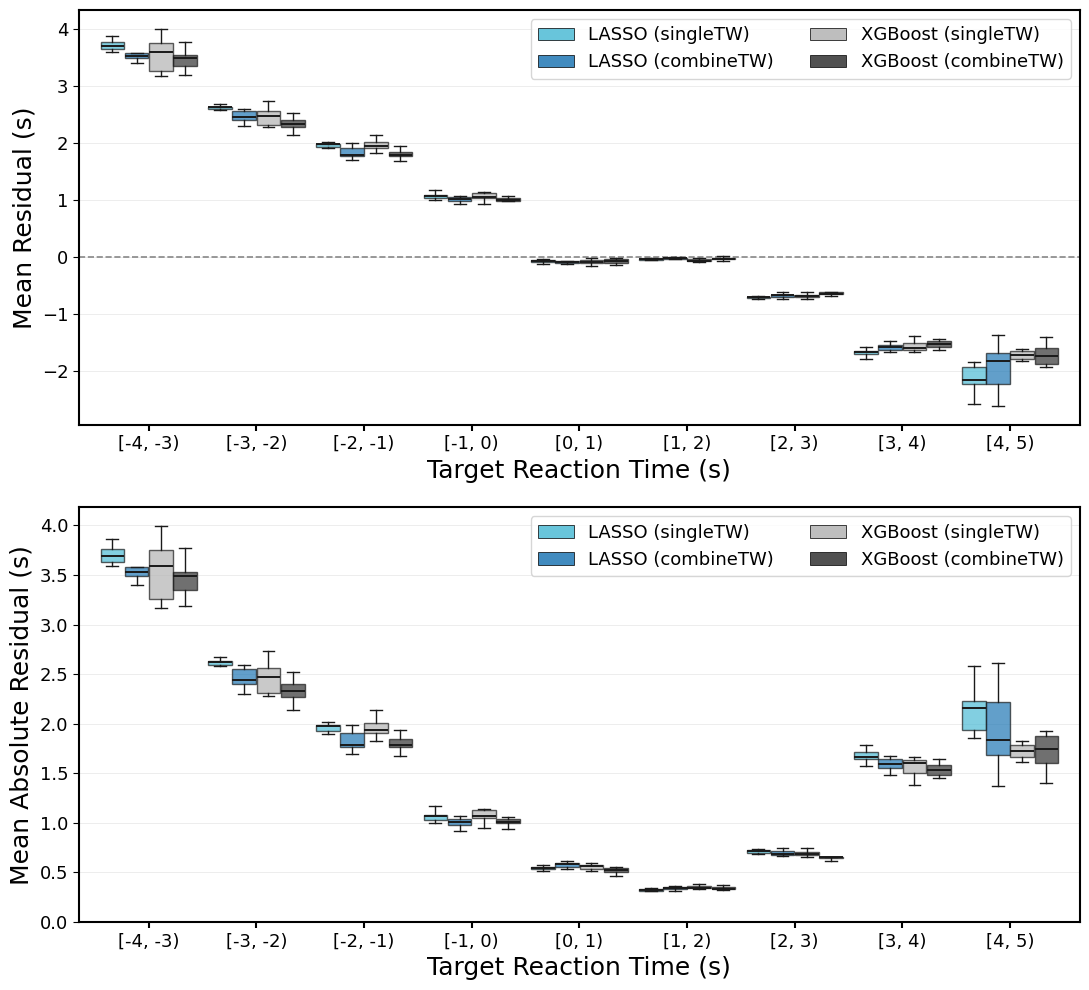

In [ ]:
"""
Residual boxplot — two panels stacked vertically.

Panel A (top):    Signed residuals (predicted − actual) — bias direction
Panel B (bottom): Absolute residuals |predicted − actual| — error magnitude

Panel A keeps the exact look of the original single-panel figure.

Reads from:
    /content/drive/MyDrive/Colab_Backups/regression_results/
        fold_predictions.csv
"""

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches


# =========================================================
# Settings
# =========================================================
DATA_DIR = "/content/drive/MyDrive/Colab_Backups/regression_results"
BIN_WIDTH = 1.0

CONFIG_ORDER = [
    "LASSO (singleTW)",
    "LASSO (combineTW)",
    "XGBoost (singleTW)",
    "XGBoost (combineTW)",
]

CONFIG_COLORS = {
    "LASSO (singleTW)":    "#4DBBD5",
    "LASSO (combineTW)":   "#1F77B4",
    "XGBoost (singleTW)":  "#b3b3b3",
    "XGBoost (combineTW)": "#333333",
}

# Box geometry — same as original
BOX_WIDTH_FRAC = 0.22
GROUP_PAD_FRAC = 0.005
ZERO_LINE_COLOR = "#888888"

# Stroke styling — same as original
STROKE_COLOR = "#000000"
STROKE_WIDTH = 0.6
LINE_WIDTH = 1
SPINE_WIDTH = 1.5

# =========================================================
# Load + compute residuals
# =========================================================
folds = pd.read_csv(os.path.join(DATA_DIR, "fold_predictions.csv"))
folds["residual"]     = folds["y_pred"] - folds["y_true"]
folds["abs_residual"] = folds["residual"].abs()


# =========================================================
# Bin definition
# =========================================================
all_y_true = folds["y_true"].values
y_low  = np.floor(all_y_true.min() / BIN_WIDTH) * BIN_WIDTH
y_high = np.ceil (all_y_true.max() / BIN_WIDTH) * BIN_WIDTH
bin_edges = np.arange(y_low, y_high + BIN_WIDTH, BIN_WIDTH)
n_bins = len(bin_edges) - 1
bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2

box_width = BIN_WIDTH * BOX_WIDTH_FRAC
group_pad = BIN_WIDTH * GROUP_PAD_FRAC

print(f"Data range: [{all_y_true.min():.3f}, {all_y_true.max():.3f}]")
print(f"Bin edges:  {bin_edges.tolist()}")
print(f"Number of bins: {n_bins}, bin width: {BIN_WIDTH}")

folds["bin"] = pd.cut(folds["y_true"], bins=bin_edges,
                      labels=False, include_lowest=True)


# =========================================================
# Aggregate per (config, seed, bin)
# =========================================================
per_seed_bin = (
    folds.groupby(["config", "seed", "bin"], as_index=False)
         .agg(mean_signed=("residual",     "mean"),
              mean_abs   =("abs_residual", "mean"))
)


# =========================================================
# Build box data per panel
# =========================================================
def build_box_data(df, value_col):
    out = {}
    for cfg in CONFIG_ORDER:
        cfg_data = df[df["config"] == cfg]
        bin_lists = []
        for b in range(n_bins):
            vals = cfg_data.loc[cfg_data["bin"] == b, value_col].values
            bin_lists.append(vals)
        out[cfg] = bin_lists
    return out


signed_box_data = build_box_data(per_seed_bin, "mean_signed")
abs_box_data    = build_box_data(per_seed_bin, "mean_abs")


# =========================================================
# Plot helper — matches original single-panel exactly
# =========================================================
def plot_box_panel(ax, box_data, ylabel, show_zero_line=True, show_legend=False):
    n_configs = len(CONFIG_ORDER)
    offsets = (np.arange(n_configs) - (n_configs - 1) / 2) \
              * (box_width + group_pad)

    if show_zero_line:
        ax.axhline(0, color=ZERO_LINE_COLOR, linestyle="--",
                   linewidth=1.2, zorder=1)

    for cfg_idx, cfg in enumerate(CONFIG_ORDER):
        positions = bin_centers + offsets[cfg_idx]
        cfg_color = CONFIG_COLORS[cfg]
        data_for_cfg = box_data[cfg]

        ax.boxplot(
            data_for_cfg,
            positions=positions,
            widths=box_width,
            patch_artist=True,
            showfliers=False,
            # medianprops =dict(color="black", linewidth=LINE_WIDTH),
            # whiskerprops=dict(color="black", linewidth=LINE_WIDTH),
            # capprops    =dict(color="black", linewidth=LINE_WIDTH),
            # boxprops    =dict(facecolor=cfg_color, edgecolor="black",
            #                   linewidth=LINE_WIDTH, alpha=0.70),

            medianprops=dict(color="#1A1A1A", linewidth=1.4),
            whiskerprops=dict(color="#1A1A1A", linewidth=1.0),
            capprops=dict(color="#1A1A1A", linewidth=1.0),
            boxprops=dict(linewidth=1.0, edgecolor="#1A1A1A",facecolor=cfg_color,alpha=0.70),
            manage_ticks=False,
            zorder=3,
        )

    # X-axis ticks with bin range labels
    bin_labels = [f"[{bin_edges[i]:.0f}, {bin_edges[i+1]:.0f})"
                  for i in range(n_bins)]
    ax.set_xticks(bin_centers)
    ax.set_xticklabels(bin_labels, fontsize=13)
    ax.tick_params(axis="y", labelsize=13)

    # Labels
    ax.set_xlabel("Target Reaction Time (s)", fontsize=18)
    ax.set_ylabel(ylabel, fontsize=18)
    ax.grid(False)

    # Gridlines behind boxes
    ax.grid(axis="y", linewidth=0.4, alpha=0.4, zorder=0)
    ax.set_axisbelow(True)

    # Tight x-limits (same as original)
    ax.set_xlim(bin_edges[0] - BIN_WIDTH * 0.15,
                bin_edges[-1] + BIN_WIDTH * 0.15)

    # Spines (same as original)
    # ax.spines["top"].set_visible(False)
    # ax.spines["right"].set_visible(False)

    # Legend (same as original — only on the panel that asks for it)
    if show_legend:
        legend_handles = [
            mpatches.Patch(facecolor=CONFIG_COLORS[c], edgecolor=STROKE_COLOR,
                           label=c, linewidth=STROKE_WIDTH, alpha=0.85)
            for c in CONFIG_ORDER
        ]
        ax.legend(
            handles=legend_handles,
            loc="upper right", fontsize=13, frameon=True, ncol=2,
        )


# =========================================================
# Plot — 2×1 stacked layout
# Each panel is the same height as the original (11×5)
# =========================================================
fig, axes = plt.subplots(2, 1, figsize=(11, 10))

# Panel A (top): signed residuals — IDENTICAL to original
plot_box_panel(
    axes[0],
    signed_box_data,
    ylabel="Mean Residual (s)",
    show_zero_line=True,
    show_legend=True,
)

# Panel B (bottom): absolute residuals
plot_box_panel(
    axes[1],
    abs_box_data,
    ylabel="Mean Absolute Residual (s)",
    show_zero_line=False,
    show_legend=True,
)
axes[1].set_ylim(bottom=0)

for ax in axes:
    for spine in ax.spines.values():
        if spine.get_visible():
            spine.set_linewidth(SPINE_WIDTH)
            spine.set_edgecolor("black")

    # X-axis ticks (bottom only)
    ax.tick_params(
        axis="x",
        labelsize=13,
        length=4,
        width=SPINE_WIDTH,
        colors="black",
        direction="out",
        bottom=True,
        top=False,
    )

    # Y-axis ticks (left only)
    ax.tick_params(
        axis="y",
        labelsize=13,
        length=4,
        # width=SPINE_WIDTH,
        colors="black",
        direction="out",
        left=True,
        right=False,
    )

plt.tight_layout()
plt.subplots_adjust(hspace=0.2)
plt.show()

Data range: [-3.933, 4.100]
Bin edges:  [-4.0, -3.0, -2.0, -1.0, 0.0, 1.0, 2.0, 3.0, 4.0, 5.0]
Number of bins: 9, bin width: 1.0

Per-seed count per bin (min / median / max):
     min  median  max
bin                  
0      3       3    3
1      5       5    5
2     11      11   11
3     17      17   17
4    100     100  100
5    160     160  160
6     44      44   44
7     10      10   10
8      1       1    1

Per-seed counts stable across seeds: True


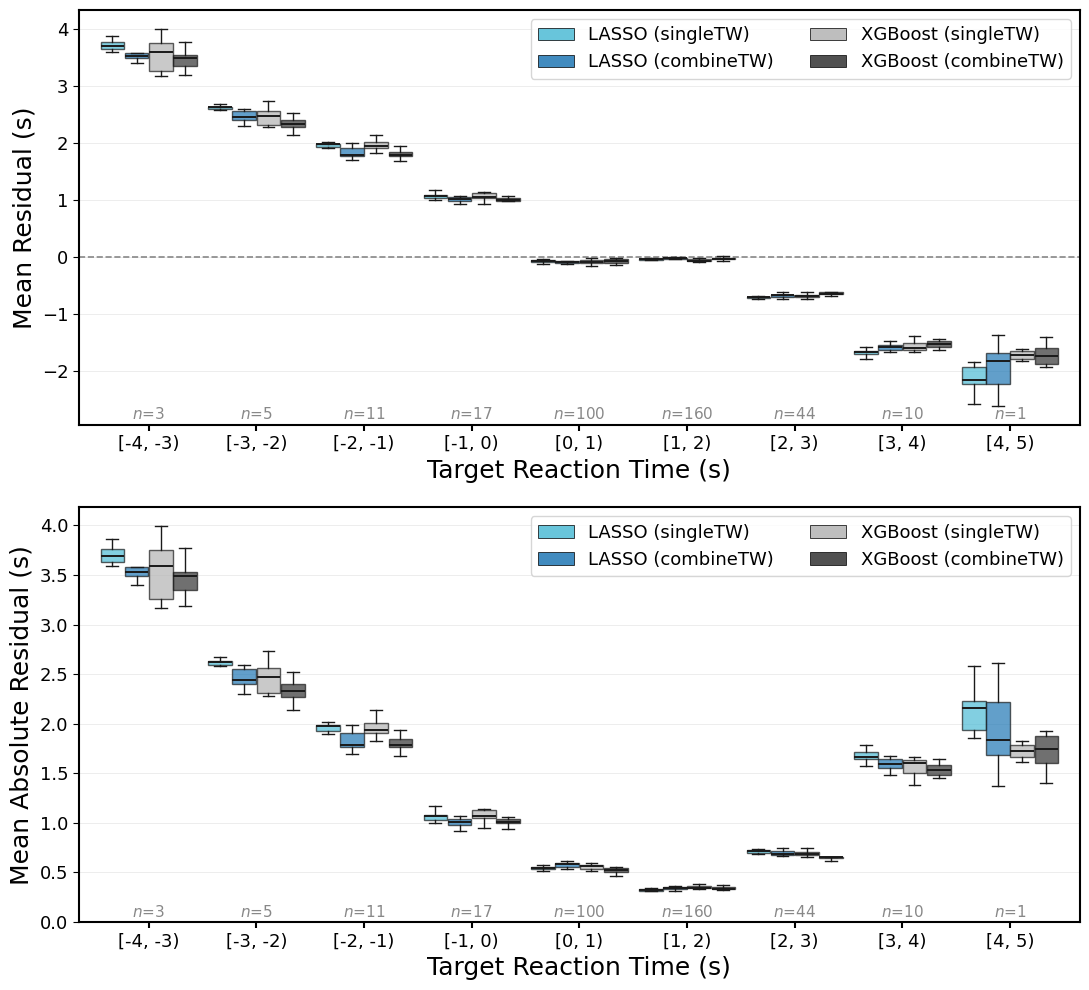

In [ ]:
"""
Residual boxplot — two panels stacked vertically.

Panel A (top):    Signed residuals (predicted − actual) — bias direction
Panel B (bottom): Absolute residuals |predicted − actual| — error magnitude

Per-seed sample count (n) per bin is annotated in grey inside both panels.

Reads from:
    /content/drive/MyDrive/Colab_Backups/regression_results/
        fold_predictions.csv
"""

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches


# =========================================================
# Settings
# =========================================================
DATA_DIR = "/content/drive/MyDrive/Colab_Backups/regression_results"
BIN_WIDTH = 1.0

CONFIG_ORDER = [
    "LASSO (singleTW)",
    "LASSO (combineTW)",
    "XGBoost (singleTW)",
    "XGBoost (combineTW)",
]

CONFIG_COLORS = {
    "LASSO (singleTW)":    "#4DBBD5",
    "LASSO (combineTW)":   "#1F77B4",
    "XGBoost (singleTW)":  "#b3b3b3",
    "XGBoost (combineTW)": "#333333",
}

# Box geometry — same as original
BOX_WIDTH_FRAC = 0.22
GROUP_PAD_FRAC = 0.005
ZERO_LINE_COLOR = "#888888"

# Stroke styling — same as original
STROKE_COLOR = "#000000"
STROKE_WIDTH = 0.6
LINE_WIDTH = 1
SPINE_WIDTH = 1.5

# Grey for the secondary n annotation
N_COLOR = "#888888"
# Vertical position of the n row inside each panel (axes fraction, 0 = bottom)
N_Y_FRAC = 0.005

# =========================================================
# Load + compute residuals
# =========================================================
folds = pd.read_csv(os.path.join(DATA_DIR, "fold_predictions.csv"))
folds["residual"]     = folds["y_pred"] - folds["y_true"]
folds["abs_residual"] = folds["residual"].abs()


# =========================================================
# Bin definition
# =========================================================
all_y_true = folds["y_true"].values
y_low  = np.floor(all_y_true.min() / BIN_WIDTH) * BIN_WIDTH
y_high = np.ceil (all_y_true.max() / BIN_WIDTH) * BIN_WIDTH
bin_edges = np.arange(y_low, y_high + BIN_WIDTH, BIN_WIDTH)
n_bins = len(bin_edges) - 1
bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2

box_width = BIN_WIDTH * BOX_WIDTH_FRAC
group_pad = BIN_WIDTH * GROUP_PAD_FRAC

print(f"Data range: [{all_y_true.min():.3f}, {all_y_true.max():.3f}]")
print(f"Bin edges:  {bin_edges.tolist()}")
print(f"Number of bins: {n_bins}, bin width: {BIN_WIDTH}")

folds["bin"] = pd.cut(folds["y_true"], bins=bin_edges,
                      labels=False, include_lowest=True)


# =========================================================
# Aggregate per (config, seed, bin)
# =========================================================
per_seed_bin = (
    folds.groupby(["config", "seed", "bin"], as_index=False)
         .agg(mean_signed=("residual",     "mean"),
              mean_abs   =("abs_residual", "mean"))
)


# =========================================================
# Per-seed sample count in each bin
# Counts are shared across configs (same y_true points), so take one config.
# =========================================================
ref_cfg = CONFIG_ORDER[0]
seed_bin_counts = (
    folds[folds["config"] == ref_cfg]
        .groupby(["seed", "bin"])
        .size()
        .unstack("bin")
        .reindex(columns=range(n_bins))
)

print("\nPer-seed count per bin (min / median / max):")
print(pd.DataFrame({
    "min":    seed_bin_counts.min(),
    "median": seed_bin_counts.median(),
    "max":    seed_bin_counts.max(),
}).astype("Int64"))

counts     = seed_bin_counts.median().reindex(range(n_bins)).fillna(0).astype(int)
counts_min = seed_bin_counts.min().reindex(range(n_bins)).fillna(0).astype(int)
counts_max = seed_bin_counts.max().reindex(range(n_bins)).fillna(0).astype(int)
counts_stable = bool((counts_min == counts_max).all())
print(f"\nPer-seed counts stable across seeds: {counts_stable}")

if counts_stable:
    n_strings = [f"$n$={counts[i]}" for i in range(n_bins)]
else:
    n_strings = [f"$n$={counts[i]}\n({counts_min[i]}–{counts_max[i]})"
                 for i in range(n_bins)]


# =========================================================
# Build box data per panel
# =========================================================
def build_box_data(df, value_col):
    out = {}
    for cfg in CONFIG_ORDER:
        cfg_data = df[df["config"] == cfg]
        bin_lists = []
        for b in range(n_bins):
            vals = cfg_data.loc[cfg_data["bin"] == b, value_col].values
            bin_lists.append(vals)
        out[cfg] = bin_lists
    return out


signed_box_data = build_box_data(per_seed_bin, "mean_signed")
abs_box_data    = build_box_data(per_seed_bin, "mean_abs")


# =========================================================
# Annotate per-seed n inside a panel (grey, near the bottom)
# =========================================================
def annotate_counts(ax):
    for i, cx in enumerate(bin_centers):
        ax.text(
            cx, N_Y_FRAC, n_strings[i],
            transform=ax.get_xaxis_transform(),  # x in data, y in axes frac
            ha="center", va="bottom", fontsize=11, color=N_COLOR,
            zorder=5,
        )


# =========================================================
# Plot helper — matches original single-panel exactly
# =========================================================
def plot_box_panel(ax, box_data, ylabel, show_zero_line=True, show_legend=False):
    n_configs = len(CONFIG_ORDER)
    offsets = (np.arange(n_configs) - (n_configs - 1) / 2) \
              * (box_width + group_pad)

    if show_zero_line:
        ax.axhline(0, color=ZERO_LINE_COLOR, linestyle="--",
                   linewidth=1.2, zorder=1)

    for cfg_idx, cfg in enumerate(CONFIG_ORDER):
        positions = bin_centers + offsets[cfg_idx]
        cfg_color = CONFIG_COLORS[cfg]
        data_for_cfg = box_data[cfg]

        ax.boxplot(
            data_for_cfg,
            positions=positions,
            widths=box_width,
            patch_artist=True,
            showfliers=False,
            medianprops=dict(color="#1A1A1A", linewidth=1.4),
            whiskerprops=dict(color="#1A1A1A", linewidth=1.0),
            capprops=dict(color="#1A1A1A", linewidth=1.0),
            boxprops=dict(linewidth=1.0, edgecolor="#1A1A1A",
                          facecolor=cfg_color, alpha=0.70),
            manage_ticks=False,
            zorder=3,
        )

    # X-axis ticks with bin range labels
    bin_labels = [f"[{bin_edges[i]:.0f}, {bin_edges[i+1]:.0f})"
                  for i in range(n_bins)]
    ax.set_xticks(bin_centers)
    ax.set_xticklabels(bin_labels, fontsize=13)
    ax.tick_params(axis="y", labelsize=13)

    # Labels
    ax.set_xlabel("Target Reaction Time (s)", fontsize=18)
    ax.set_ylabel(ylabel, fontsize=18)
    ax.grid(False)

    # Gridlines behind boxes
    ax.grid(axis="y", linewidth=0.4, alpha=0.4, zorder=0)
    ax.set_axisbelow(True)

    # Tight x-limits (same as original)
    ax.set_xlim(bin_edges[0] - BIN_WIDTH * 0.15,
                bin_edges[-1] + BIN_WIDTH * 0.15)

    # Legend (same as original — only on the panel that asks for it)
    if show_legend:
        legend_handles = [
            mpatches.Patch(facecolor=CONFIG_COLORS[c], edgecolor=STROKE_COLOR,
                           label=c, linewidth=STROKE_WIDTH, alpha=0.85)
            for c in CONFIG_ORDER
        ]
        ax.legend(
            handles=legend_handles,
            loc="upper right", fontsize=13, frameon=True, ncol=2,
        )


# =========================================================
# Plot — 2×1 stacked layout
# =========================================================
fig, axes = plt.subplots(2, 1, figsize=(11, 10))

# Panel A (top): signed residuals — IDENTICAL to original
plot_box_panel(
    axes[0],
    signed_box_data,
    ylabel="Mean Residual (s)",
    show_zero_line=True,
    show_legend=True,
)

# Panel B (bottom): absolute residuals
plot_box_panel(
    axes[1],
    abs_box_data,
    ylabel="Mean Absolute Residual (s)",
    show_zero_line=False,
    show_legend=True,
)
axes[1].set_ylim(bottom=0)

# Annotate per-seed n inside BOTH panels
annotate_counts(axes[0])
annotate_counts(axes[1])

for ax in axes:
    for spine in ax.spines.values():
        if spine.get_visible():
            spine.set_linewidth(SPINE_WIDTH)
            spine.set_edgecolor("black")

    # X-axis ticks (bottom only)
    ax.tick_params(
        axis="x",
        labelsize=13,
        length=4,
        width=SPINE_WIDTH,
        colors="black",
        direction="out",
        bottom=True,
        top=False,
    )

    # Y-axis ticks (left only)
    ax.tick_params(
        axis="y",
        labelsize=13,
        length=4,
        colors="black",
        direction="out",
        left=True,
        right=False,
    )

plt.tight_layout()
plt.subplots_adjust(hspace=0.2)
plt.show()

Best seed per config (lowest fold-averaged RMSE):
                     seed      RMSE        R2
config                                       
LASSO (combineTW)    3789  0.843378  0.399044
LASSO (singleTW)      285  0.864884  0.402526
XGBoost (combineTW)  3789  0.818345  0.446805
XGBoost (singleTW)   1423  0.860068  0.399660


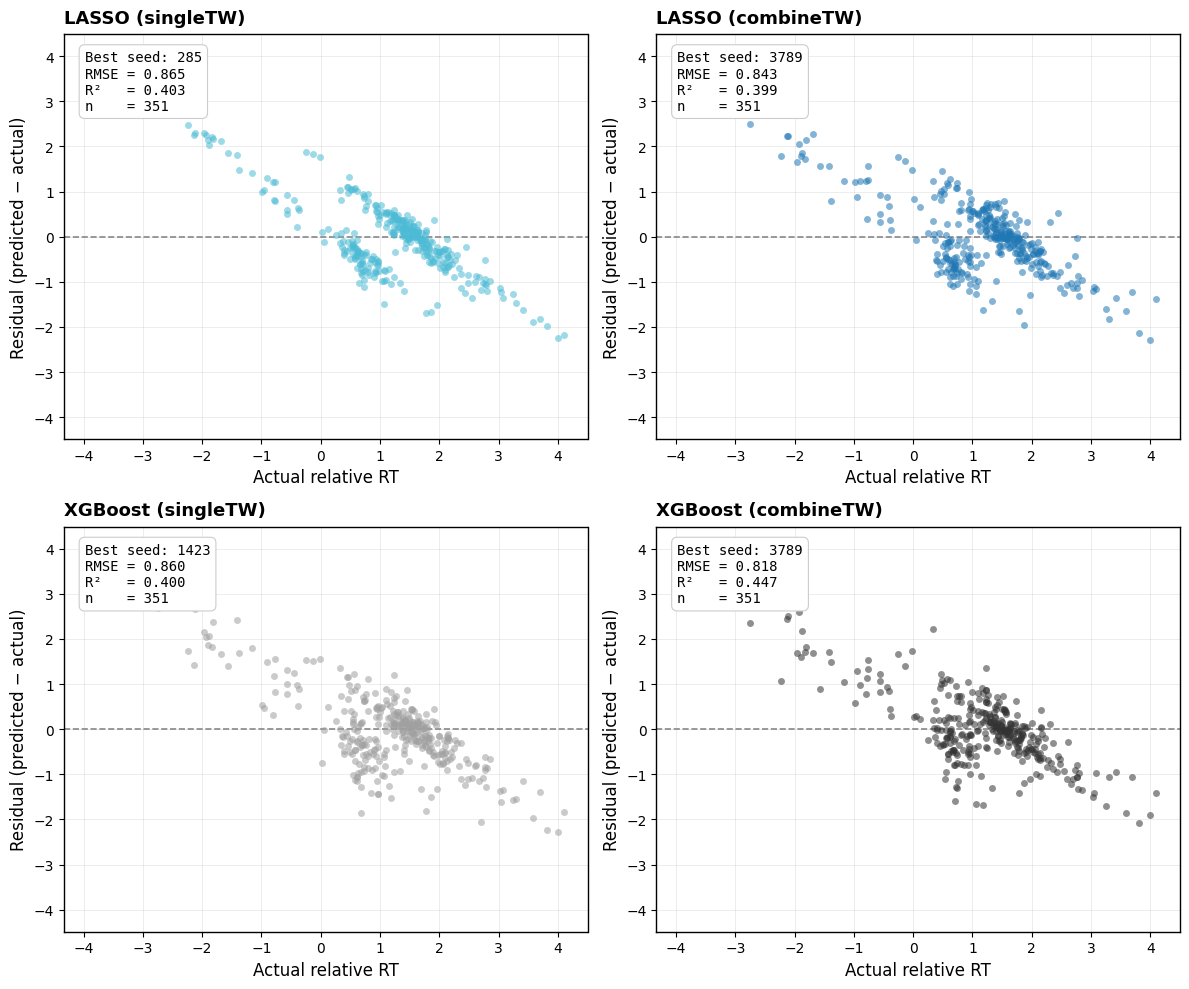

In [ ]:
"""
Residual scatter — 4 panels (2×2), one per config, each showing residuals
from the single best-performing seed (lowest fold-averaged RMSE).

Each sample in the test folds is one dot:
    x = actual y
    y = predicted − actual (residual)

Reads from:
    /content/drive/MyDrive/Colab_Backups/regression_results/
        fold_predictions.csv
        fold_level_metrics.csv
"""

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# =========================================================
# Settings
# =========================================================
DATA_DIR = "/content/drive/MyDrive/Colab_Backups/regression_results"

CONFIG_ORDER = [
    "LASSO (singleTW)",
    "LASSO (combineTW)",
    "XGBoost (singleTW)",
    "XGBoost (combineTW)",
]

CONFIG_COLORS = {
    "LASSO (singleTW)":    "#4DBBD5",
    "LASSO (combineTW)":   "#1F77B4",
    "XGBoost (singleTW)":  "#A0A0A0",
    "XGBoost (combineTW)": "#333333",
}

SCATTER_SIZE  = 25
SCATTER_ALPHA = 0.55
ZERO_LINE_COLOR = "#888888"


# =========================================================
# Load
# =========================================================
folds   = pd.read_csv(os.path.join(DATA_DIR, "fold_predictions.csv"))
metrics = pd.read_csv(os.path.join(DATA_DIR, "fold_level_metrics.csv"))

# Compute residuals
folds["residual"] = folds["y_pred"] - folds["y_true"]


# =========================================================
# Pick best seed per config (lowest fold-averaged RMSE)
# =========================================================
seed_means = (
    metrics.groupby(["config", "seed"], as_index=False)
           .agg(RMSE=("RMSE", "mean"),
                R2  =("R2",   "mean"))
)
best_seed_by_config = (
    seed_means.loc[seed_means.groupby("config")["RMSE"].idxmin()]
    .set_index("config")
)

print("Best seed per config (lowest fold-averaged RMSE):")
print(best_seed_by_config[["seed", "RMSE", "R2"]])


# =========================================================
# Shared axes ranges
# =========================================================
# Use only the best-seed data for ranges, since that's what gets plotted
best_seed_data = pd.concat([
    folds[(folds["config"] == cfg) &
          (folds["seed"] == best_seed_by_config.loc[cfg, "seed"])]
    for cfg in CONFIG_ORDER
])

x_min = best_seed_data["y_true"].min()
x_max = best_seed_data["y_true"].max()
x_pad = 0.05 * (x_max - x_min)
x_min -= x_pad
x_max += x_pad

resid_abs = best_seed_data["residual"].abs().max()
y_pad = 0.1 * resid_abs
y_min = -resid_abs - y_pad
y_max =  resid_abs + y_pad


# =========================================================
# Plot — 2×2
# =========================================================
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.flatten()

for ax, cfg in zip(axes, CONFIG_ORDER):
    seed = int(best_seed_by_config.loc[cfg, "seed"])
    rmse = best_seed_by_config.loc[cfg, "RMSE"]
    r2   = best_seed_by_config.loc[cfg, "R2"]

    sub = folds[(folds["config"] == cfg) & (folds["seed"] == seed)]

    # Zero-error reference
    ax.axhline(0, color=ZERO_LINE_COLOR, linestyle="--",
               linewidth=1.2, zorder=1)

    # Scatter
    ax.scatter(
        sub["y_true"], sub["residual"],
        s=SCATTER_SIZE, color=CONFIG_COLORS[cfg],
        alpha=SCATTER_ALPHA, linewidths=0,
        zorder=2,
    )

    # Annotation
    annotation = (
        f"Best seed: {seed}\n"
        f"RMSE = {rmse:.3f}\n"
        f"R²   = {r2:.3f}\n"
        f"n    = {len(sub)}"
    )
    ax.text(
        0.04, 0.96, annotation,
        transform=ax.transAxes,
        ha="left", va="top",
        fontsize=10,
        family="monospace",
        bbox=dict(boxstyle="round,pad=0.4",
                  facecolor="white",
                  edgecolor="#CCCCCC",
                  linewidth=0.8),
        zorder=10,
    )

    # Axis settings
    ax.set_xlim(x_min, x_max)
    ax.set_ylim(y_min, y_max)
    ax.set_xlabel("Actual relative RT", fontsize=12)
    ax.set_ylabel("Residual (predicted − actual)", fontsize=12)
    ax.set_title(cfg, fontsize=13, fontweight="bold", loc="left", pad=8)

    ax.grid(True, linewidth=0.4, alpha=0.4)
    ax.set_axisbelow(True)
    for spine in ax.spines.values():
        spine.set_linewidth(1.0)
    ax.tick_params(labelsize=10)

plt.tight_layout()
plt.show()

Best seed per config (lowest fold-averaged RMSE):
                     seed      RMSE        R2
config                                       
LASSO (combineTW)    3789  0.843378  0.399044
LASSO (singleTW)      285  0.864884  0.402526
XGBoost (combineTW)  3789  0.818345  0.446805
XGBoost (singleTW)   1423  0.860068  0.399660


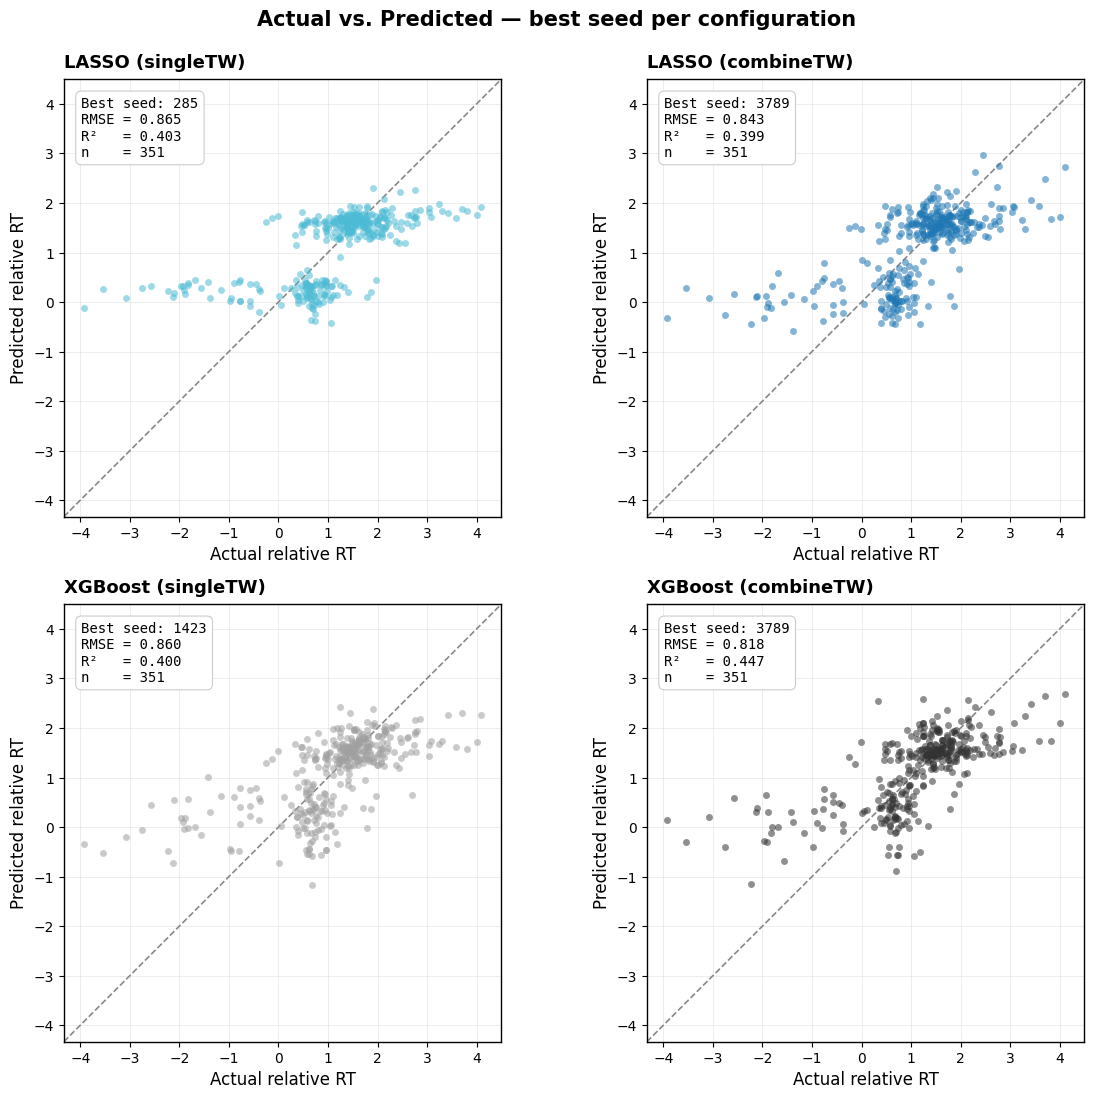

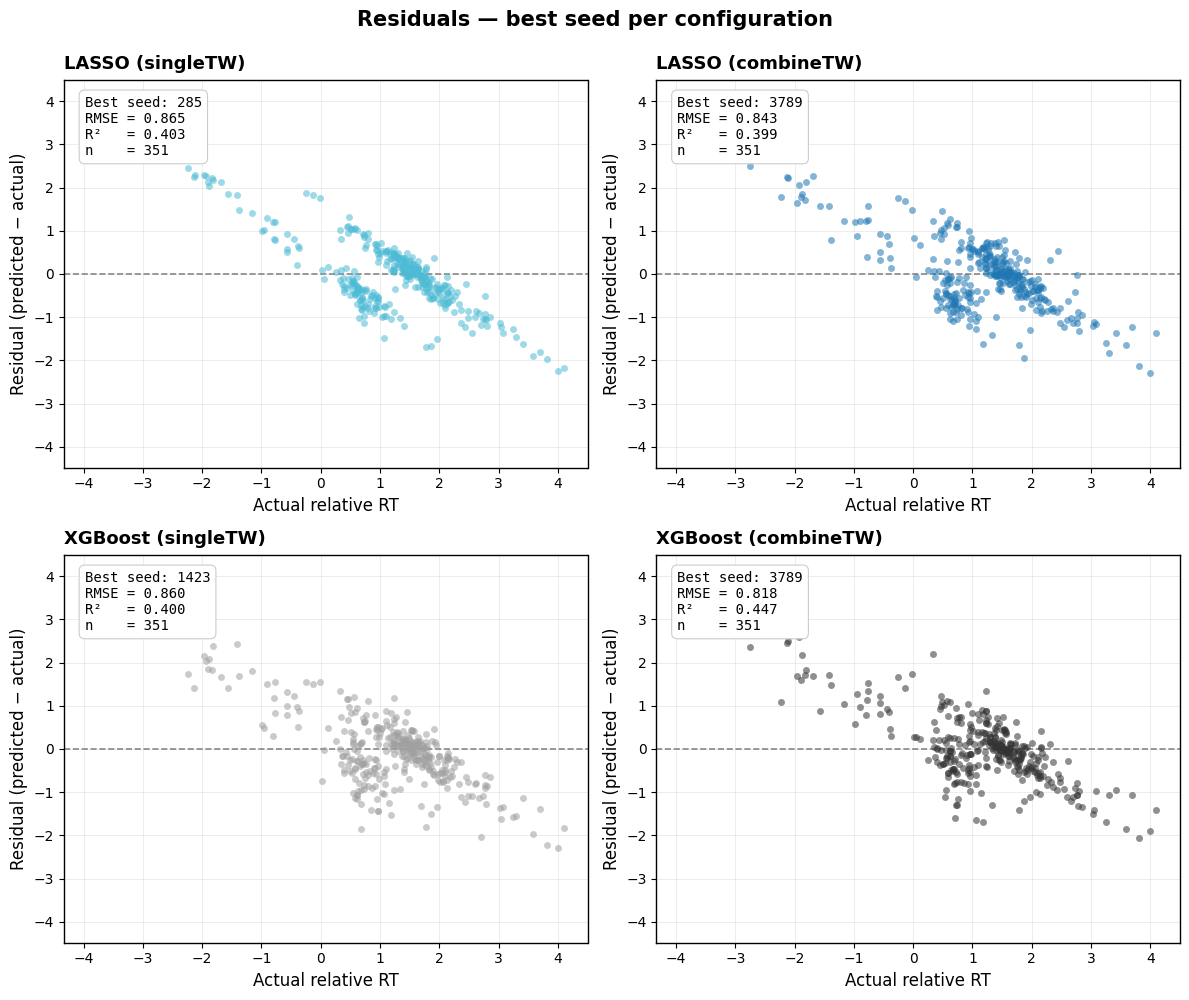

In [ ]:
"""
Best-seed diagnostic plots — two 2×2 figures, one panel per config.

Figure 1: Actual vs. Predicted scatter
    x = actual y_true
    y = predicted y_pred
    + y = x reference line

Figure 2: Residual scatter
    x = actual y_true
    y = predicted − actual (residual)
    + zero-error reference line

Both figures use the best-performing seed for each config (lowest
fold-averaged RMSE).

Reads from:
    /content/drive/MyDrive/Colab_Backups/regression_results/
        fold_predictions.csv
        fold_level_metrics.csv
"""

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# =========================================================
# Settings
# =========================================================
DATA_DIR = "/content/drive/MyDrive/Colab_Backups/regression_results"

CONFIG_ORDER = [
    "LASSO (singleTW)",
    "LASSO (combineTW)",
    "XGBoost (singleTW)",
    "XGBoost (combineTW)",
]

CONFIG_COLORS = {
    "LASSO (singleTW)":    "#4DBBD5",
    "LASSO (combineTW)":   "#1F77B4",
    "XGBoost (singleTW)":  "#A0A0A0",
    "XGBoost (combineTW)": "#333333",
}

SCATTER_SIZE  = 25
SCATTER_ALPHA = 0.55
REF_LINE_COLOR = "#888888"


# =========================================================
# Load
# =========================================================
folds   = pd.read_csv(os.path.join(DATA_DIR, "fold_predictions.csv"))
metrics = pd.read_csv(os.path.join(DATA_DIR, "fold_level_metrics.csv"))

folds["residual"] = folds["y_pred"] - folds["y_true"]


# =========================================================
# Pick best seed per config (lowest fold-averaged RMSE)
# =========================================================
seed_means = (
    metrics.groupby(["config", "seed"], as_index=False)
           .agg(RMSE=("RMSE", "mean"),
                R2  =("R2",   "mean"))
)
best_seed_by_config = (
    seed_means.loc[seed_means.groupby("config")["RMSE"].idxmin()]
    .set_index("config")
)

print("Best seed per config (lowest fold-averaged RMSE):")
print(best_seed_by_config[["seed", "RMSE", "R2"]])


# =========================================================
# Shared axes ranges (based on best-seed data only)
# =========================================================
best_seed_data = pd.concat([
    folds[(folds["config"] == cfg) &
          (folds["seed"] == best_seed_by_config.loc[cfg, "seed"])]
    for cfg in CONFIG_ORDER
])

# For actual-vs-predicted: symmetric square axes
ap_min = min(best_seed_data["y_true"].min(),
             best_seed_data["y_pred"].min())
ap_max = max(best_seed_data["y_true"].max(),
             best_seed_data["y_pred"].max())
ap_pad = 0.05 * (ap_max - ap_min)
ap_min -= ap_pad
ap_max += ap_pad

# For residual: symmetric around zero
resid_abs = best_seed_data["residual"].abs().max()
r_pad = 0.1 * resid_abs
y_resid_lim = (-resid_abs - r_pad, resid_abs + r_pad)

# X range for residual panels (actual RT range)
x_resid_min = best_seed_data["y_true"].min()
x_resid_max = best_seed_data["y_true"].max()
x_pad = 0.05 * (x_resid_max - x_resid_min)
x_resid_lim = (x_resid_min - x_pad, x_resid_max + x_pad)


def annotation_text(seed, rmse, r2, n):
    return (
        f"Best seed: {seed}\n"
        f"RMSE = {rmse:.3f}\n"
        f"R²   = {r2:.3f}\n"
        f"n    = {n}"
    )


def style_panel(ax, cfg):
    ax.set_title(cfg, fontsize=13, fontweight="bold", loc="left", pad=8)
    ax.grid(True, linewidth=0.4, alpha=0.4)
    ax.set_axisbelow(True)
    for spine in ax.spines.values():
        spine.set_linewidth(1.0)
    ax.tick_params(labelsize=10)


# =========================================================
# Figure 1 — Actual vs. Predicted
# =========================================================
fig1, axes1 = plt.subplots(2, 2, figsize=(12, 11))
axes1 = axes1.flatten()

for ax, cfg in zip(axes1, CONFIG_ORDER):
    seed = int(best_seed_by_config.loc[cfg, "seed"])
    rmse = best_seed_by_config.loc[cfg, "RMSE"]
    r2   = best_seed_by_config.loc[cfg, "R2"]

    sub = folds[(folds["config"] == cfg) & (folds["seed"] == seed)]

    # y = x reference
    ax.plot([ap_min, ap_max], [ap_min, ap_max],
            color=REF_LINE_COLOR, linestyle="--",
            linewidth=1.2, zorder=1, label="y = x")

    # Scatter
    ax.scatter(
        sub["y_true"], sub["y_pred"],
        s=SCATTER_SIZE, color=CONFIG_COLORS[cfg],
        alpha=SCATTER_ALPHA, linewidths=0,
        zorder=2,
    )

    # Annotation
    ax.text(
        0.04, 0.96, annotation_text(seed, rmse, r2, len(sub)),
        transform=ax.transAxes,
        ha="left", va="top",
        fontsize=10, family="monospace",
        bbox=dict(boxstyle="round,pad=0.4",
                  facecolor="white", edgecolor="#CCCCCC",
                  linewidth=0.8),
        zorder=10,
    )

    ax.set_xlim(ap_min, ap_max)
    ax.set_ylim(ap_min, ap_max)
    ax.set_aspect("equal", adjustable="box")
    ax.set_xlabel("Actual relative RT", fontsize=12)
    ax.set_ylabel("Predicted relative RT", fontsize=12)
    style_panel(ax, cfg)

fig1.suptitle("Actual vs. Predicted — best seed per configuration",
              fontsize=15, fontweight="bold", y=0.995)
plt.tight_layout()
plt.show()


# =========================================================
# Figure 2 — Residuals
# =========================================================
fig2, axes2 = plt.subplots(2, 2, figsize=(12, 10))
axes2 = axes2.flatten()

for ax, cfg in zip(axes2, CONFIG_ORDER):
    seed = int(best_seed_by_config.loc[cfg, "seed"])
    rmse = best_seed_by_config.loc[cfg, "RMSE"]
    r2   = best_seed_by_config.loc[cfg, "R2"]

    sub = folds[(folds["config"] == cfg) & (folds["seed"] == seed)]

    # Zero-error reference
    ax.axhline(0, color=REF_LINE_COLOR, linestyle="--",
               linewidth=1.2, zorder=1)

    # Scatter
    ax.scatter(
        sub["y_true"], sub["residual"],
        s=SCATTER_SIZE, color=CONFIG_COLORS[cfg],
        alpha=SCATTER_ALPHA, linewidths=0,
        zorder=2,
    )

    # Annotation
    ax.text(
        0.04, 0.96, annotation_text(seed, rmse, r2, len(sub)),
        transform=ax.transAxes,
        ha="left", va="top",
        fontsize=10, family="monospace",
        bbox=dict(boxstyle="round,pad=0.4",
                  facecolor="white", edgecolor="#CCCCCC",
                  linewidth=0.8),
        zorder=10,
    )

    ax.set_xlim(*x_resid_lim)
    ax.set_ylim(*y_resid_lim)
    ax.set_xlabel("Actual relative RT", fontsize=12)
    ax.set_ylabel("Residual (predicted − actual)", fontsize=12)
    style_panel(ax, cfg)

fig2.suptitle("Residuals — best seed per configuration",
              fontsize=15, fontweight="bold", y=0.995)
plt.tight_layout()
plt.show()

# Confusion Matrix - Best perfoming seed

# SHAP/Coefficient Classifier

## Get SHAP - Classifier

In [ ]:
# =========================================================
# XGB BEST-SEED SHAP ACROSS OUTER FOLDS
# Swarm plot + summary bar plot
# =========================================================

import json
import os
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from sklearn.metrics import (
    roc_auc_score,
    roc_curve,
    precision_recall_curve,
    average_precision_score
)

from sklearn.model_selection import StratifiedGroupKFold
from xgboost import XGBClassifier, DMatrix


# =========================================================
# 1. SETTINGS
# =========================================================
data_path = "/content/drive/MyDrive/Colab_Backups/Data_3sMean_IDT_beforeMat.xlsx"

results_path = "/content/drive/MyDrive/Colab_Backups/XGBC/XGBC_combineTW.xlsx"
base_dir = "/content/drive/MyDrive/Colab_Backups/XGBC"
model_dir = "XGB_model_combineTW"

selected_seeds = [
    3558, 6687, 6836, 7862, 11033,
    13285, 22075, 22163, 23858, 30690
]

outer_splits = 5
target_col = "relativeRT"

targetTW = 13
TWs = [0, 13]

cat_names = ["Gender", "automation", "eventType"]

top_n_features = 10


# =========================================================
# 2. HELPERS
# =========================================================
def build_feature_cols(TWs):
    feature_templates = [
        "Age", "License", "Mileage",
        "Gender", "automation", "eventType",
        "visibleSpeed",

        "pdMean_{TW}", "pdSd_{TW}",
        "blinkNumber_{TW}",
        "avgBlinkDuration_{TW}",

        "fixNumber_{TW}",
        "avgFixDuration_{TW}",

        "fixTE_{TW}", "fixSE_{TW}",
        "FixDisperX_{TW}", "FixDisperY_{TW}",
        "FixDisperE_{TW}",
        "FixMeanPosX_{TW}", "FixMeanPosY_{TW}",
    ]

    feature_cols = []
    for c in feature_templates:
        if "{TW}" in c:
            feature_cols.extend([c.format(TW=tw) for tw in TWs])
        else:
            feature_cols.append(c)

    return feature_cols


def ensure_categorical_dtype_from_train(train_df, test_df, cat_cols):
    train_df = train_df.copy()
    test_df = test_df.copy()

    for col in cat_cols:
        if col in train_df.columns:
            cats = pd.Index(train_df[col].dropna().unique())
            dtype = pd.CategoricalDtype(categories=cats, ordered=False)
            train_df[col] = train_df[col].astype(dtype)
            test_df[col] = test_df[col].astype(dtype)

    return train_df, test_df


def load_xgb_params(base_dir, model_dir, seed, tw, outer_fold):
    folder = os.path.join(base_dir, model_dir)

    candidates = glob.glob(os.path.join(
        folder,
        f"xgb_seed_{seed:02d}_*TW_{tw:02d}_outerfold_{outer_fold:02d}_meta.json"
    ))

    if len(candidates) == 0:
        candidates = glob.glob(os.path.join(
            folder,
            f"xgb_seed_{seed:02d}_TW_{tw:02d}_outerfold_{outer_fold:02d}_meta.json"
        ))

    if len(candidates) == 0:
        raise FileNotFoundError(
            f"No XGB metadata found for seed={seed}, TW={tw}, fold={outer_fold}"
        )

    path = sorted(candidates, key=len)[0]

    with open(path, "r", encoding="utf-8") as f:
        meta = json.load(f)

    return meta["best_params"], meta, path


def find_best_seed(results_path, targetTW, selected_seeds):
    res = pd.read_excel(results_path)

    res["outer_fold"] = res["outer_fold"].astype(str)
    res["TW"] = pd.to_numeric(res["TW"], errors="coerce")
    res["AUC"] = pd.to_numeric(res["AUC"], errors="coerce")

    sub = res[
        (res["outer_fold"] == "SUMMARY") &
        (res["TW"] == targetTW) &
        (res["seed"].isin(selected_seeds))
    ].copy()

    if sub.empty:
        raise ValueError(f"No SUMMARY rows found for TW={targetTW}")

    best_row = sub.loc[sub["AUC"].idxmax()]

    return int(best_row["seed"]), float(best_row["AUC"]), sub.sort_values("AUC", ascending=False)


def make_numeric_for_color(X_df):
    """
    Convert feature values to numeric only for beeswarm coloring.
    Original model input remains categorical for XGBoost.
    """
    X_color = X_df.copy()

    for c in X_color.columns:
        if str(X_color[c].dtype) == "category" or X_color[c].dtype == "object":
            X_color[c] = X_color[c].astype("category").cat.codes.replace(-1, np.nan)
        else:
            X_color[c] = pd.to_numeric(X_color[c], errors="coerce")

    return X_color.astype(float)


def get_xgb_shap_values(model, X_proc):
    """
    Uses XGBoost pred_contribs.
    Output includes one SHAP value per feature.
    The final bias column is removed.
    """
    dm = DMatrix(X_proc, enable_categorical=True)
    contribs = model.get_booster().predict(dm, pred_contribs=True)

    shap_values = contribs[:, :-1]
    base_values = contribs[:, -1]

    return shap_values, base_values


def plot_shap_summary_bar(shap_df, top_n=10, title="SHAP Summary Plot"):
    mean_abs = shap_df.abs().mean().sort_values(ascending=False)
    top_features = mean_abs.head(top_n).sort_values(ascending=True)

    fig, ax = plt.subplots(figsize=(7, 5.5))

    ax.barh(
        top_features.index,
        top_features.values,
        color="#3B4CC0",
        alpha=0.9
    )

    ax.set_xlabel("Mean |SHAP value|", fontsize=14)
    ax.set_ylabel("")
    ax.set_title(title, fontsize=15)

    ax.tick_params(axis="both", labelsize=12)
    ax.grid(axis="x", alpha=0.25)

    for spine in ax.spines.values():
        spine.set_linewidth(1.1)

    plt.tight_layout()
    plt.show()


def plot_shap_beeswarm(
    shap_df,
    X_color_df,
    top_n=10,
    title="SHAP Bee Swarm Plot",
    max_points_per_feature=None
):
    mean_abs = shap_df.abs().mean().sort_values(ascending=False)
    top_features = mean_abs.head(top_n).index.tolist()

    plot_features = top_features[::-1]

    # cmap = mcolors.LinearSegmentedColormap.from_list(
    #     "yellow_red_purple",
    #     ["#FFC20A", "#E64B35", "#7A0177", "#2D004B"]
    # )
    cmap = "coolwarm"

    fig, ax = plt.subplots(figsize=(7.5, 6))

    rng = np.random.default_rng(42)

    for y_pos, feature in enumerate(plot_features):
        shap_vals = shap_df[feature].values
        color_vals = X_color_df[feature].values

        valid = ~np.isnan(shap_vals)

        shap_vals = shap_vals[valid]
        color_vals = color_vals[valid]

        if max_points_per_feature is not None and len(shap_vals) > max_points_per_feature:
            idx = rng.choice(len(shap_vals), size=max_points_per_feature, replace=False)
            shap_vals = shap_vals[idx]
            color_vals = color_vals[idx]

        if np.all(np.isnan(color_vals)):
            norm_color = np.full_like(shap_vals, 0.5, dtype=float)
        else:
            lo = np.nanpercentile(color_vals, 1)
            hi = np.nanpercentile(color_vals, 99)

            if hi == lo:
                norm_color = np.full_like(color_vals, 0.5, dtype=float)
            else:
                norm_color = (color_vals - lo) / (hi - lo)
                norm_color = np.clip(norm_color, 0, 1)

        jitter = rng.normal(0, 0.075, size=len(shap_vals))

        ax.scatter(
            shap_vals,
            y_pos + jitter,
            c=norm_color,
            cmap=cmap,
            s=18,
            alpha=0.75,
            linewidths=0
        )

    ax.axvline(0, color="lightgray", linewidth=1.5)

    ax.set_yticks(range(len(plot_features)))
    ax.set_yticklabels(plot_features, fontsize=12)

    ax.set_xlabel("SHAP value", fontsize=14)
    ax.set_ylabel("")
    ax.set_title(title, fontsize=15)

    ax.tick_params(axis="x", labelsize=12)

    for spine in ["top", "right"]:
        ax.spines[spine].set_visible(False)

    ax.spines["left"].set_visible(False)
    ax.spines["bottom"].set_linewidth(1.1)

    sm = plt.cm.ScalarMappable(cmap=cmap, norm=plt.Normalize(0, 1))
    sm.set_array([])

    cbar = plt.colorbar(sm, ax=ax, pad=0.04, shrink=0.4)
    cbar.set_label("Feature value", fontsize=12)
    cbar.set_ticks([0, 1])
    cbar.set_ticklabels(["Low", "High"])

    plt.tight_layout()
    plt.show()


# =========================================================
# 3. LOAD DATA
# =========================================================
df = pd.read_excel(data_path)

allowed_events = {
    "EVENT_MAT_RIGHT_VRU",
    "EVENT_MAT_LEFT_VRU",
    "EVENT_MAT_ONCOMING"
}

unexpected = set(df["eventType"].dropna().unique()) - allowed_events
if unexpected:
    raise ValueError(f"Unexpected eventType(s): {unexpected}")

df[target_col] = pd.to_numeric(df[target_col], errors="coerce")
df = df.dropna(subset=[target_col, "eventType", "subNumber"]).copy()

df["rt85_by_event"] = df.groupby("eventType")[target_col].transform(
    lambda x: x.quantile(0.85)
)

df["RT85_cls"] = (df[target_col] >= df["rt85_by_event"]).astype(int)

tww_cols = [f"perValid_{i}" for i in range(31)]
df = df[df[tww_cols].mean(axis=1) >= 74.5].copy()

y = df["RT85_cls"].values.astype(int)
groups = df["subNumber"].values
y_strat = y.copy()

print(f"Final N = {len(df)}")
print("Class counts:")
print(pd.Series(y).value_counts().sort_index())


# =========================================================
# 4. FIND BEST XGB SEED
# =========================================================
best_seed, best_summary_auc, seed_rank = find_best_seed(
    results_path=results_path,
    targetTW=targetTW,
    selected_seeds=selected_seeds
)
best_seed_xgb = best_seed
print("\nBest XGB seed:", best_seed)
print("Best XGB SUMMARY AUC:", best_summary_auc)
print("\nSeed ranking:")
print(seed_rank[["seed", "TW", "AUC"]])


# =========================================================
# 5. AGGREGATE OUTER-FOLD SHAP VALUES
# =========================================================
feature_cols = build_feature_cols(TWs)
X = df[feature_cols].copy()

outer_cv = StratifiedGroupKFold(
    n_splits=outer_splits,
    shuffle=True,
    random_state=best_seed
)

all_shap = []
all_X_color = []
all_info = []
all_interaction = []
for outer_fold, (train_idx, test_idx) in enumerate(
    outer_cv.split(X, y_strat, groups),
    start=1
):
    print("\n" + "=" * 70)
    print(f"XGB Combined TW | Best seed={best_seed} | Outer fold={outer_fold}")
    print("=" * 70)

    X_train = X.iloc[train_idx].copy()
    X_test = X.iloc[test_idx].copy()

    y_train = y[train_idx]
    y_test = y[test_idx]

    best_params, meta, meta_path = load_xgb_params(
        base_dir=base_dir,
        model_dir=model_dir,
        seed=best_seed,
        tw=targetTW,
        outer_fold=outer_fold
    )

    selected_features = meta.get("selected_features", None)

    if selected_features is not None:
        selected_features = [c for c in selected_features if c in X_train.columns]
        X_train = X_train[selected_features].copy()
        X_test = X_test[selected_features].copy()
    else:
        selected_features = X_train.columns.tolist()

    X_train_proc, X_test_proc = ensure_categorical_dtype_from_train(
        X_train,
        X_test,
        cat_names
    )

    model = XGBClassifier(**best_params)
    model.fit(X_train_proc, y_train)
    y_pred_prob = model.predict_proba(X_test_proc)[:, 1]  # probability for positive class
    fold_auc = roc_auc_score(y_test, y_pred_prob)

    print(f"Outer fold {outer_fold} AUC: {fold_auc:.4f}")

    shap_values, base_values = get_xgb_shap_values(model, X_test_proc)

    # interaction values from the SAME model, SAME rows
    dm_inter = DMatrix(X_test_proc, enable_categorical=True)
    inter = model.get_booster().predict(dm_inter, pred_interactions=True)
    inter = inter[:, :-1, :-1]  # drop bias row/col

    n_feat = X_test_proc.shape[1]
    inter_flat = pd.DataFrame(
        inter.reshape(inter.shape[0], n_feat * n_feat),
        index=X_test_proc.index,
    )
    all_interaction.append(inter_flat)


    shap_df_fold = pd.DataFrame(
        shap_values,
        columns=X_test_proc.columns,
        index=X_test_proc.index
    )

    X_color_fold = make_numeric_for_color(X_test_proc)
    X_color_fold = X_color_fold[shap_df_fold.columns]

    info_fold = pd.DataFrame({
        "outer_fold": outer_fold,
        "subNumber": df.iloc[test_idx]["subNumber"].values,
        "y_true": y_test,
        "base_value": base_values
    }, index=X_test_proc.index)

    all_shap.append(shap_df_fold)
    all_X_color.append(X_color_fold)
    all_info.append(info_fold)

    print(f"Loaded metadata: {os.path.basename(meta_path)}")
    print(f"SHAP fold shape: {shap_df_fold.shape}")


shap_all = pd.concat(all_shap, axis=0)
X_color_all = pd.concat(all_X_color, axis=0)
shap_interaction_all = pd.concat(all_interaction, axis=0)
shap_interaction_all.columns = pd.MultiIndex.from_product(
    [shap_all.columns.tolist(), shap_all.columns.tolist()]
)

Final N = 351
Class counts:
0    304
1     47
Name: count, dtype: int64

Best XGB seed: 11033
Best XGB SUMMARY AUC: 0.7728892886205866

Seed ranking:
       seed  TW       AUC
797   11033  13  0.772889
437    6836  13  0.760621
977   13285  13  0.738380
1337  22163  13  0.737322
1517  23858  13  0.722236
1697  30690  13  0.693755
257    6687  13  0.688507
77     3558  13  0.686537
1157  22075  13  0.680777
617    7862  13  0.667900

XGB Combined TW | Best seed=11033 | Outer fold=1
Outer fold 1 AUC: 0.7402
Loaded metadata: xgb_seed_11033_TW_13_outerfold_01_meta.json
SHAP fold shape: (59, 33)

XGB Combined TW | Best seed=11033 | Outer fold=2
Outer fold 2 AUC: 0.8950
Loaded metadata: xgb_seed_11033_TW_13_outerfold_02_meta.json
SHAP fold shape: (58, 33)

XGB Combined TW | Best seed=11033 | Outer fold=3
Outer fold 3 AUC: 0.7086
Loaded metadata: xgb_seed_11033_TW_13_outerfold_03_meta.json
SHAP fold shape: (80, 33)

XGB Combined TW | Best seed=11033 | Outer fold=4
Outer fold 4 AUC: 0.8672
Loa

## Get LASSO Coefficient - Classifier

In [ ]:
# =========================================================
# LASSO SINGLE TW 11
# Refit best seed and visualize:
# 1) how many outer folds each variable remains non-zero
# 2) coefficient value when retained
# =========================================================

import json
import os
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import re

from sklearn.metrics import (
    roc_auc_score,
    roc_curve,
    precision_recall_curve,
    average_precision_score
)
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

# =========================================================
# SETTINGS
# =========================================================
data_path = "/content/drive/MyDrive/Colab_Backups/Data_3sMean_IDT_beforeMat.xlsx"

results_path = "/content/drive/MyDrive/Colab_Backups/LR_test/LRC_singleTW.xlsx"
base_dir = "/content/drive/MyDrive/Colab_Backups/LR_test"
model_dir = "LRC_model_singleTW"

selected_seeds = [
    3558, 6687, 6836, 7862, 11033,
    13285, 22075, 22163, 23858, 30690
]

outer_splits = 5
target_col = "relativeRT"
cat_names = ["Gender", "automation", "eventType"]

targetTW = 11
TWs = [11]


# =========================================================
# HELPERS
# ========================================================


def build_feature_cols(TWs):
    feature_templates = [
        "Age", "License", "Mileage",
        "Gender", "automation", "eventType",
        "visibleSpeed",
        "pdMean_{TW}", "pdSd_{TW}",
        "blinkNumber_{TW}",
        "avgBlinkDuration_{TW}",
        "fixNumber_{TW}",
        "avgFixDuration_{TW}",
        "fixTE_{TW}", "fixSE_{TW}",
        "FixDisperX_{TW}", "FixDisperY_{TW}",
        "FixDisperE_{TW}",
        "FixMeanPosX_{TW}", "FixMeanPosY_{TW}",
    ]

    feature_cols = []
    for c in feature_templates:
        if "{TW}" in c:
            feature_cols.extend([c.format(TW=tw) for tw in TWs])
        else:
            feature_cols.append(c)

    return feature_cols


def fit_outer_onehot(X_train_raw, X_test_raw, cat_cols):
    X_train_raw = X_train_raw.copy()
    X_test_raw = X_test_raw.copy()

    use_cat = [c for c in cat_cols if c in X_train_raw.columns]

    for c in use_cat:
        train_cats = pd.Index(X_train_raw[c].dropna().unique())
        dtype = pd.CategoricalDtype(categories=train_cats, ordered=False)
        X_train_raw[c] = X_train_raw[c].astype(dtype)
        X_test_raw[c] = X_test_raw[c].astype(dtype)

    X_train_oh = pd.get_dummies(X_train_raw, columns=use_cat, drop_first=False)
    X_test_oh = pd.get_dummies(X_test_raw, columns=use_cat, drop_first=False)

    X_test_oh = X_test_oh.reindex(columns=X_train_oh.columns, fill_value=0)

    return X_train_oh.astype(np.float32), X_test_oh.astype(np.float32)


def load_lasso_params(base_dir, model_dir, seed, tw, outer_fold):
    folder = os.path.join(base_dir, model_dir)

    candidates = glob.glob(os.path.join(
        folder,
        f"lr_seed_{seed:02d}_*TW_{tw:02d}_outerfold_{outer_fold:02d}_meta.json"
    ))

    if len(candidates) == 0:
        candidates = glob.glob(os.path.join(
            folder,
            f"lr_seed_{seed:02d}_TW_{tw:02d}_outerfold_{outer_fold:02d}_meta.json"
        ))

    if len(candidates) == 0:
        raise FileNotFoundError(
            f"No LASSO metadata found for seed={seed}, TW={tw}, fold={outer_fold}"
        )

    path = sorted(candidates, key=len)[0]

    with open(path, "r", encoding="utf-8") as f:
        meta = json.load(f)

    return meta["best_params"], meta, path


def find_best_seed(results_path, targetTW, selected_seeds):
    res = pd.read_excel(results_path)

    res["outer_fold"] = res["outer_fold"].astype(str)
    res["TW"] = pd.to_numeric(res["TW"], errors="coerce")
    res["AUC"] = pd.to_numeric(res["AUC"], errors="coerce")

    sub = res[
        (res["outer_fold"] == "SUMMARY") &
        (res["TW"] == targetTW) &
        (res["seed"].isin(selected_seeds))
    ].copy()

    if sub.empty:
        raise ValueError(f"No SUMMARY rows found for TW={targetTW}")

    best_row = sub.loc[sub["AUC"].idxmax()]

    return int(best_row["seed"]), float(best_row["AUC"]), sub.sort_values("AUC", ascending=False)


def clean_lasso_feature_name(name):
    """
    Optional: makes one-hot names slightly cleaner.
    """
    return (
        name.replace("Gender_", "Gender: ")
            .replace("automation_", "automation: ")
            .replace("eventType_", "eventType: ")
    )


# =========================================================
# LOAD DATA
# =========================================================
df = pd.read_excel(data_path)

allowed_events = {
    "EVENT_MAT_RIGHT_VRU",
    "EVENT_MAT_LEFT_VRU",
    "EVENT_MAT_ONCOMING"
}

unexpected = set(df["eventType"].dropna().unique()) - allowed_events
if unexpected:
    raise ValueError(f"Unexpected eventType(s): {unexpected}")

df[target_col] = pd.to_numeric(df[target_col], errors="coerce")
df = df.dropna(subset=[target_col, "eventType", "subNumber"]).copy()

df["rt85_by_event"] = df.groupby("eventType")[target_col].transform(
    lambda x: x.quantile(0.85)
)

df["RT85_cls"] = (df[target_col] >= df["rt85_by_event"]).astype(int)

tww_cols = [f"perValid_{i}" for i in range(31)]
df = df[df[tww_cols].mean(axis=1) >= 74.5].copy()

y = df["RT85_cls"].values.astype(int)
groups = df["subNumber"].values
y_strat = y.copy()

print(f"Final N = {len(df)}")
print("Class counts:")
print(pd.Series(y).value_counts().sort_index())

print(len(y))
# =========================================================
# FIND BEST LASSO SINGLE-TW SEED
# =========================================================
best_seed, best_summary_auc, seed_rank = find_best_seed(
    results_path=results_path,
    targetTW=targetTW,
    selected_seeds=selected_seeds
)
best_seed_lasso = best_seed
print("\nBest LASSO Single TW seed:", best_seed)
print("Best SUMMARY AUC:", best_summary_auc)
print("\nSeed ranking:")
print(seed_rank[["seed", "TW", "AUC"]])


# =========================================================
# REFIT ACROSS 5 OUTER FOLDS AND COLLECT COEFFICIENTS
# =========================================================
feature_cols = build_feature_cols(TWs)
X = df[feature_cols].copy()

outer_cv = StratifiedGroupKFold(
    n_splits=outer_splits,
    shuffle=True,
    random_state=best_seed
)

coef_rows = []

for outer_fold, (train_idx, test_idx) in enumerate(
    outer_cv.split(X, y_strat, groups),
    start=1
):

    print("\n" + "=" * 70)
    print(f"LASSO Single TW11 | best seed={best_seed} | outer fold={outer_fold}")
    print("=" * 70)

    X_train = X.iloc[train_idx].copy()
    X_test = X.iloc[test_idx].copy()
    y_train = y[train_idx]

    best_params, meta, meta_path = load_lasso_params(
        base_dir=base_dir,
        model_dir=model_dir,
        seed=best_seed,
        tw=targetTW,
        outer_fold=outer_fold
    )

    X_train_proc, X_test_proc = fit_outer_onehot(
        X_train,
        X_test,
        cat_names
    )

    imputer = SimpleImputer(strategy="median")

    X_train_proc = pd.DataFrame(
        imputer.fit_transform(X_train_proc),
        columns=X_train_proc.columns,
        index=X_train_proc.index
    )

    scaler = StandardScaler()

    X_train_proc = pd.DataFrame(
        scaler.fit_transform(X_train_proc),
        columns=X_train_proc.columns,
        index=X_train_proc.index
    )

    # Impute test
    X_test_proc = pd.DataFrame(
        imputer.transform(X_test_proc),
        columns=X_test_proc.columns,
        index=X_test_proc.index
    )

    # Scale test
    X_test_proc = pd.DataFrame(
        scaler.transform(X_test_proc),
        columns=X_test_proc.columns,
        index=X_test_proc.index
    )

    model = LogisticRegression(
        **best_params
    )

    model.fit(X_train_proc, y_train)
    y_test = y[test_idx]
    y_pred_prob = model.predict_proba(X_test_proc)[:, 1]
    fold_auc = roc_auc_score(y_test, y_pred_prob)

    print(f"Outer fold {outer_fold} AUC: {fold_auc:.4f}")

    coefs = model.coef_.ravel()

    fold_coef_df = pd.DataFrame({
        "outer_fold": outer_fold,
        "feature": X_train_proc.columns,
        "coef": coefs
    })

    fold_coef_df["abs_coef"] = fold_coef_df["coef"].abs()
    fold_coef_df["selected"] = fold_coef_df["coef"].abs() > 1e-8
    fold_coef_df["meta_file"] = os.path.basename(meta_path)

    coef_rows.append(fold_coef_df)

    print(f"Loaded metadata: {os.path.basename(meta_path)}")
    print(f"Non-zero coefficients: {fold_coef_df['selected'].sum()} / {len(fold_coef_df)}")


coef_all = pd.concat(coef_rows, ignore_index=True)

coef_all["feature_clean"] = coef_all["feature"].apply(clean_lasso_feature_name)

# =========================================================
# AGGREGATE VARIABLE RETENTION + COEFFICIENTS
# =========================================================
coef_summary = (
    coef_all
    .groupby(["feature", "feature_clean"], as_index=False)
    .agg(
        retained_count=("selected", "sum"),
        mean_coef_all_folds=("coef", "mean"),
        mean_abs_coef_all_folds=("abs_coef", "mean"),
        median_coef_all_folds=("coef", "median"),
        sd_coef_all_folds=("coef", "std")
    )
)

nonzero_only = coef_all[coef_all["selected"]].copy()

coef_when_retained = (
    nonzero_only
    .groupby(["feature", "feature_clean"], as_index=False)
    .agg(
        mean_coef_when_retained=("coef", "mean"),
        median_coef_when_retained=("coef", "median"),
        sd_coef_when_retained=("coef", "std"),
        mean_abs_coef_when_retained=("abs_coef", "mean")
    )
)

coef_summary = coef_summary.merge(
    coef_when_retained,
    on=["feature", "feature_clean"],
    how="left"
)

coef_summary["retention_rate"] = coef_summary["retained_count"] / outer_splits

coef_summary = coef_summary.sort_values(
    ["retained_count", "mean_abs_coef_when_retained"],
    ascending=[False, False]
)


Final N = 351
Class counts:
0    304
1     47
Name: count, dtype: int64
351

Best LASSO Single TW seed: 6836
Best SUMMARY AUC: 0.7389871834273457

Seed ranking:
       seed  TW       AUC
443    6836  11  0.738987
257    6687  11  0.736621
1745  30690  11  0.734300
1373  22163  11  0.733128
1001  13285  11  0.731700
71     3558  11  0.711270
815   11033  11  0.707931
1187  22075  11  0.699093
1559  23858  11  0.698368
629    7862  11  0.681996

LASSO Single TW11 | best seed=6836 | outer fold=1
Outer fold 1 AUC: 0.6858
Loaded metadata: lr_seed_6836_TW_11_outerfold_01_meta.json
Non-zero coefficients: 9 / 24

LASSO Single TW11 | best seed=6836 | outer fold=2
Outer fold 2 AUC: 0.8433
Loaded metadata: lr_seed_6836_TW_11_outerfold_02_meta.json
Non-zero coefficients: 9 / 24

LASSO Single TW11 | best seed=6836 | outer fold=3
Outer fold 3 AUC: 0.7235
Loaded metadata: lr_seed_6836_TW_11_outerfold_03_meta.json
Non-zero coefficients: 5 / 24

LASSO Single TW11 | best seed=6836 | outer fold=4
Outer f

## Plot - Classifier

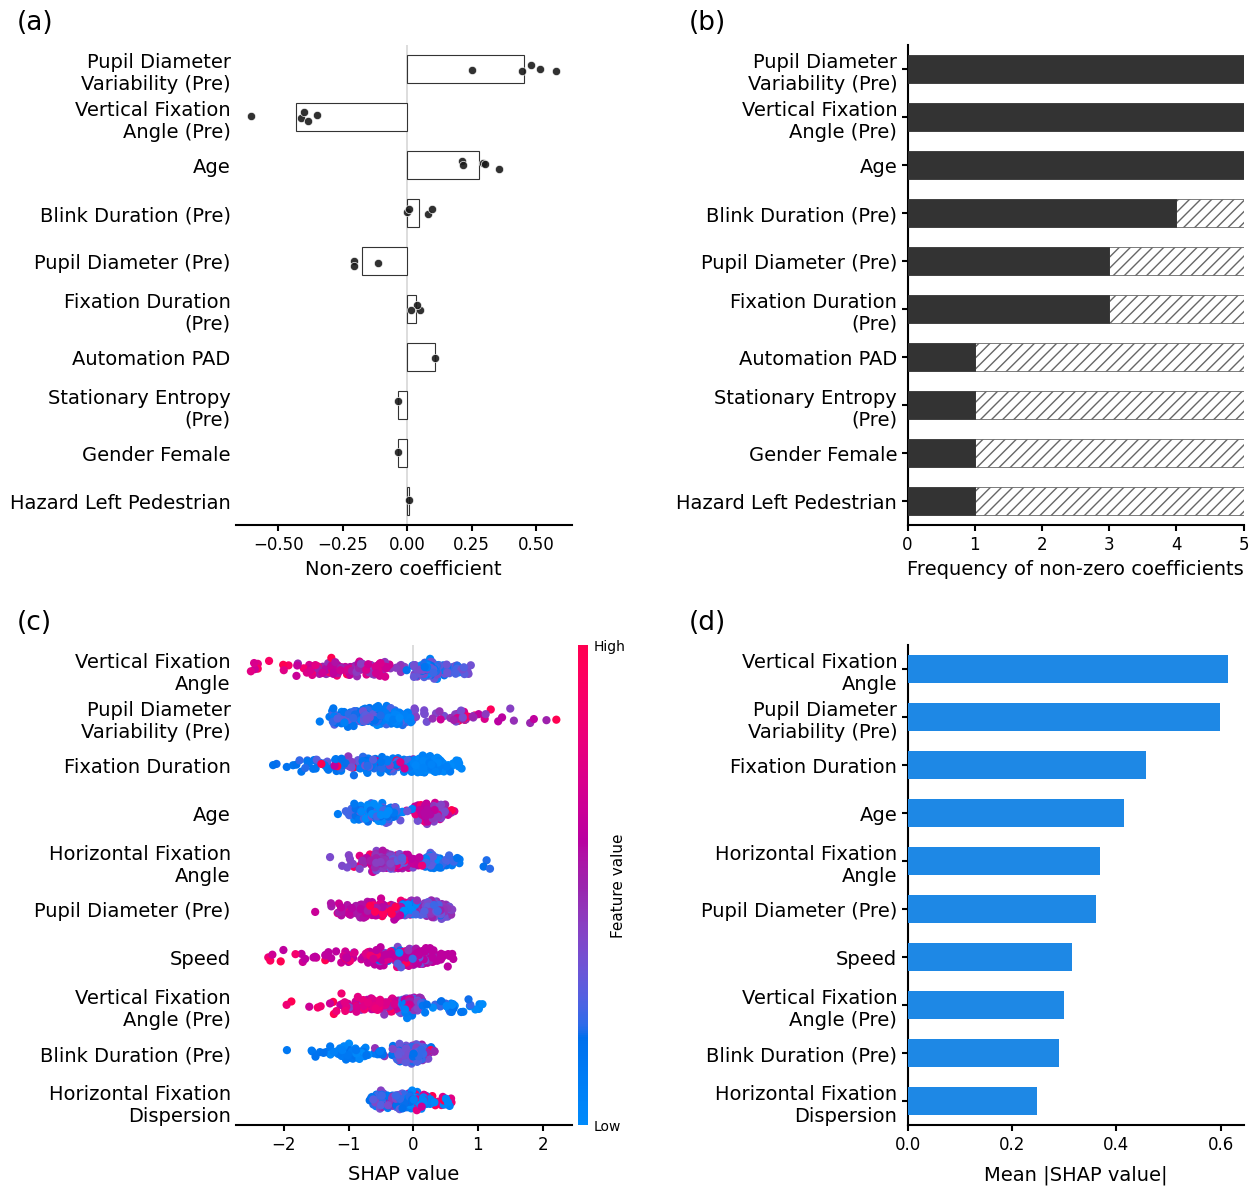

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import shap
import pandas as pd
import re
import textwrap
from matplotlib.gridspec import GridSpec


def clean_feature_name(name):
    # categorical one-hot handling FIRST
    if "_" in name:
        prefix, val = name.split("_", 1)

        if prefix in ["Gender", "automation", "eventType"]:

            if prefix == "automation":
                val_map = {"1": "MD", "2": "PAD"}
                val = val_map.get(val, val)

            elif prefix == "Gender":
                val_map = {"M": "Male", "F": "Female"}
                val = val_map.get(val, val)

            elif prefix == "eventType":
                val_map = {
                    "EVENT_MAT_LEFT_VRU": "Left Pedestrian",
                    "EVENT_MAT_RIGHT_VRU": "Right Pedestrian",
                    "EVENT_MAT_ONCOMING": "Oncoming Vehicle"
                }
                val = val_map.get(val, val)

            return f"{name_map.get(prefix, prefix)} {val}"

    # TW suffix handling SECOND
    match = re.match(r"(.+?)_(\d+)$", name)

    if match:
        base, tw = match.groups()
        tw = int(tw)

        base_clean = name_map.get(base, base)

        if tw == 0:
            return f"{base_clean}"
        else:
            return f"{base_clean} (Pre)"

    return name_map.get(name, name)


# name_map = {
#     "Age": "Age",
#     "License": "DrivingExperience",
#     "Mileage": "Mileage",
#     "Gender": "Gender",
#     "automation": "Automation",
#     "eventType": "Hazard",
#     "visibleSpeed": "VisibleSpeed",
#     "pdMean": "PupilMean",
#     "pdSd": "PupilStd",
#     "blinkNumber": "BlinkNum",
#     "avgBlinkDuration": "BlinkDurMean",
#     "fixNumber": "FixNum",
#     "avgFixDuration": "FixDurMean",
#     "fixTE": "FixTEntropy",
#     "fixSE": "FixSEntropy",
#     "FixDisperX": "FixSDx",
#     "FixDisperY": "FixSDy",
#     "FixDisperE": "FixSDe",
#     "FixMeanPosX": "FixMx",
#     "FixMeanPosY": "FixMy",
# }
name_map = {
    "Age": "Age",
    "License": "Driving Experience",
    "Mileage": "Annual Mileage",
    "Gender": "Gender",
    "automation": "Automation",
    "eventType": "Hazard",
    "visibleSpeed": "Speed",
    "pdMean": "Pupil Diameter",
    "pdSd": "Pupil Diameter Variability",
    "blinkNumber": "Blink Number",
    "avgBlinkDuration": "Blink Duration",
    "fixNumber": "Fixation Number",
    "avgFixDuration": "Fixation Duration",
    "fixTE": "Transition Entropy",
    "fixSE": "Stationary Entropy",
    "FixDisperX": "Horizontal Fixation Dispersion",
    "FixDisperY": "Vertical Fixation Dispersion",
    "FixDisperE": "Euclidean Fixation Dispersion",
    "FixMeanPosX": "Horizontal Fixation Angle",
    "FixMeanPosY": "Vertical Fixation Angle",
}


def wrap_labels(label, width=22):
    """Wrap to at most `width` chars per line."""
    return "\n".join(textwrap.wrap(label, width))


# =========================================================
# Settings
# =========================================================
top_n_lasso = 10
top_n_shap = 10

# Centralized style constants
DOT_COLOR = "#1A1A1A"
DOT_SIZE = 35
DOT_ALPHA = 0.9

# LASSO mean bar styling
LASSO_BAR_FACE_COLOR = "white"
LASSO_BAR_EDGE_COLOR = "#333333"
LASSO_BAR_EDGE_WIDTH = 0.8

SHAP_BAR_COLOR = "#1E88E5"
SHAP_BAR_ALPHA = 1.0
SHAP_DOT_SIZE = 35
SHAP_DOT_ALPHA = 1
LASSO_BAR_ALPHA = 0.8

BAR_HEIGHT = 0.6

# Font sizes
fontsize_x_label = 14
fontsize_x_tick = 12
fontsize_y = 14

# =========================================================
# 1. Prepare LASSO plotting data
# =========================================================
lasso_plot_df = coef_summary[coef_summary["retained_count"] > 0].copy()

lasso_plot_df = lasso_plot_df.sort_values(
    ["retained_count", "mean_abs_coef_when_retained"],
    ascending=[False, False]
).head(top_n_lasso)

lasso_plot_df = lasso_plot_df.sort_values(
    ["retained_count", "mean_abs_coef_when_retained"],
    ascending=[True, True]
).reset_index(drop=True)   # 👈 reset to ensure 0..n-1 positional index

top_lasso_features = lasso_plot_df["feature"].tolist()

lasso_box_df = coef_all[
    (coef_all["feature"].isin(top_lasso_features)) &
    (coef_all["selected"])
].copy()

lasso_plot_df["feature_clean"] = lasso_plot_df["feature"].apply(clean_feature_name)
lasso_box_df["feature_clean"] = lasso_box_df["feature"].apply(clean_feature_name)

lasso_order = lasso_plot_df["feature_clean"].tolist()
n_lasso = len(lasso_order)

# =========================================================
# 2. Prepare SHAP plotting data
# =========================================================
mean_abs_shap_raw = shap_all.abs().mean().sort_values(ascending=False)

top_shap_features_raw = mean_abs_shap_raw.head(top_n_shap).index.tolist()
shap_plot_features_raw = top_shap_features_raw[::-1]
shap_plot_labels = [clean_feature_name(f) for f in shap_plot_features_raw]
n_shap = len(shap_plot_labels)

# =========================================================
# 3. Create combined figure
# =========================================================
fig = plt.figure(figsize=(12, 12))
gs = GridSpec(2, 2, figure=fig, width_ratios=[1, 1])

ax_lasso_coef = fig.add_subplot(gs[0, 0])
ax_lasso_ret  = fig.add_subplot(gs[0, 1])
ax_shap_swarm = fig.add_subplot(gs[1, 0])
ax_shap_bar   = fig.add_subplot(gs[1, 1])

# =========================================================
# Row 1, Left: LASSO coefficient plot
# =========================================================
for i, feature_name in enumerate(lasso_order):
    vals = lasso_box_df[lasso_box_df["feature_clean"] == feature_name]["coef"].dropna().values

    if len(vals) == 0:
        continue

    mean_val = np.mean(vals)
    y_pos = i

    ax_lasso_coef.barh(
        y=y_pos,
        width=mean_val,
        color=LASSO_BAR_FACE_COLOR,
        edgecolor=LASSO_BAR_EDGE_COLOR,
        linewidth=LASSO_BAR_EDGE_WIDTH,
        height=BAR_HEIGHT,
        zorder=2,
    )

    rng = np.random.default_rng(42 + i)
    y_jitter = rng.normal(y_pos, 0.06, size=len(vals))

    ax_lasso_coef.scatter(
        vals, y_jitter,
        color=DOT_COLOR,
        s=DOT_SIZE,
        alpha=DOT_ALPHA,
        edgecolor="white",
        linewidth=0.5,
        zorder=5,
    )

ax_lasso_coef.set_yticks(range(n_lasso))
ax_lasso_coef.set_yticklabels([wrap_labels(f) for f in lasso_order], fontsize=fontsize_y)
ax_lasso_coef.set_xlabel("Non-zero coefficient", fontsize=fontsize_x_label)
ax_lasso_coef.grid(axis="y", linestyle="--", linewidth=0.8, alpha=0.3)
ax_lasso_coef.set_ylim(-0.5, n_lasso - 0.5)


# =========================================================
# Row 1, Right: retention bars — full-length bar with proportion filled
# =========================================================
y_positions = np.arange(n_lasso)

retained_counts = lasso_plot_df["retained_count"].values
total_folds = int(retained_counts.max())
unfilled_counts = total_folds - retained_counts   # 👈 add this line
# Filled portion
ax_lasso_ret.barh(
    y_positions, retained_counts,
    color="#333333",
    edgecolor="#333333",     # 👈 add matching edge
    linewidth=0.6,           # 👈 same linewidth as hatched bar
    height=BAR_HEIGHT,
    zorder=5,
)
# Unfilled portion
ax_lasso_ret.barh(
    y_positions, unfilled_counts,
    left=retained_counts,
    facecolor="white",
    edgecolor="#666666",
    linewidth=0.6,
    hatch="///",
    height=BAR_HEIGHT,
    zorder=4,
)
ax_lasso_ret.set_yticks(y_positions)
ax_lasso_ret.set_yticklabels([wrap_labels(l) for l in lasso_order], fontsize=fontsize_y)
ax_lasso_ret.set_ylim(-0.5, n_lasso - 0.5)
ax_lasso_ret.set_xlim(0, total_folds)
ax_lasso_ret.set_xlabel("Frequency of non-zero coefficients", fontsize=fontsize_x_label)


# =========================================================
# Row 2, Right: XGB SHAP summary bar  ── ALIGN with beeswarm
# =========================================================
shap_bar_values = mean_abs_shap_raw.head(top_n_shap).sort_values(ascending=True)
shap_bar_labels = [clean_feature_name(f) for f in shap_bar_values.index]

y_positions_shap = np.arange(n_shap)

ax_shap_bar.barh(
    y_positions_shap,
    shap_bar_values.values,
    color=SHAP_BAR_COLOR,
    edgecolor="none",
    height=BAR_HEIGHT,
    # alpha=0.9,
    zorder=5
)
ax_shap_bar.set_yticks(y_positions_shap)
ax_shap_bar.set_yticklabels([wrap_labels(l) for l in shap_bar_labels], fontsize=fontsize_y)
ax_shap_bar.set_ylim(-0.5, n_shap - 0.5)
ax_shap_bar.set_xlabel("Mean |SHAP value|", fontsize=fontsize_x_label, labelpad=8)

# =========================================================
# Row 2, Left: XGB SHAP beeswarm
# =========================================================
rng = np.random.default_rng(42)
shap_cmap = shap.plots.colors.red_blue

for y_pos, feature in enumerate(shap_plot_features_raw):
    shap_vals = shap_all[feature].values
    color_vals = X_color_all[feature].values

    valid = ~np.isnan(shap_vals)
    shap_vals = shap_vals[valid]
    color_vals = color_vals[valid]

    lo = np.nanpercentile(color_vals, 1)
    hi = np.nanpercentile(color_vals, 99)

    if hi == lo or np.isnan(hi) or np.isnan(lo):
        norm_color = np.full_like(shap_vals, 0.5, dtype=float)
    else:
        norm_color = (color_vals - lo) / (hi - lo)
        norm_color = np.clip(norm_color, 0, 1)

    jitter = rng.normal(0, 0.075, size=len(shap_vals))

    ax_shap_swarm.scatter(
        shap_vals,
        y_pos + jitter,
        c=norm_color,
        cmap=shap_cmap,
        s=SHAP_DOT_SIZE,
        alpha=SHAP_DOT_ALPHA,
        linewidths=0,
    )

ax_shap_swarm.set_yticks(range(n_shap))
ax_shap_swarm.set_yticklabels([wrap_labels(l) for l in shap_plot_labels], fontsize=fontsize_y)
ax_shap_swarm.set_xlabel("SHAP value", fontsize=fontsize_x_label, labelpad=8)
ax_shap_swarm.set_ylabel("")
ax_shap_swarm.set_ylim(-0.5, n_shap - 0.5)
ax_shap_swarm.grid(axis="y", linestyle="--", linewidth=0.8, alpha=0.3)

# =========================================================
# Colorbar for SHAP swarm
# =========================================================
sm = plt.cm.ScalarMappable(cmap=shap_cmap, norm=plt.Normalize(0, 1))
sm.set_array([])

# cbar = fig.colorbar(sm, ax=ax_shap_swarm, pad=0.02, fraction=0.04)

cax = ax_shap_swarm.inset_axes([1.02, 0.0, 0.03, 1.0])  # x, y, w, h in axes coords
cbar = fig.colorbar(sm, cax=cax)

cbar.set_label("Feature value", fontsize=11, labelpad=-10)
cbar.set_ticks([0, 1])
cbar.set_ticklabels(["Low", "High"])
cbar.outline.set_visible(False)
cbar.ax.tick_params(length=0)
posA = ax_lasso_coef.get_position()
posC = ax_shap_swarm.get_position()
# force C to A's left edge and width
ax_shap_swarm.set_position([posA.x0, posC.y0, posA.width, posC.height])

posB = ax_lasso_ret.get_position()
posD = ax_shap_bar.get_position()
ax_shap_bar.set_position([posB.x0, posD.y0, posB.width, posD.height])
# =========================================================
# Spines, ticks, axis-zero lines
# =========================================================
for ax in [ax_lasso_coef, ax_lasso_ret, ax_shap_swarm, ax_shap_bar]:
# for ax in [ax_lasso_coef,  ax_shap_swarm]:

    ax.tick_params(axis="y", labelsize=fontsize_y)
    ax.tick_params(axis="x", labelsize=fontsize_x_tick)
    # ax.spines["left"].set_linewidth(0.2)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.grid(axis="both", visible=False)

for ax in [ax_lasso_coef, ax_shap_swarm]:
    ax.spines["left"].set_visible(False)

ax_lasso_coef.axvline(0, color="lightgray", linewidth=1.1, zorder=0)
ax_shap_swarm.axvline(0, color="lightgray", linewidth=1.1, zorder=0)

# =========================================================
# Align y-labels across rows
# =========================================================
fig.align_ylabels([ax_lasso_coef, ax_shap_swarm])
fig.align_ylabels([ax_lasso_ret, ax_shap_bar])

# =========================================================
# Layout
# =========================================================
plt.subplots_adjust(
    left=0.12,
    right=0.96,
    hspace=0.25,
    wspace=1,
    top=0.96,
    bottom=0.06,
)

PANEL_LABEL_FONTSIZE = 19

panel_labels = [
    (ax_lasso_coef, "(a)"),
    (ax_lasso_ret,  "(b)"),
    (ax_shap_swarm, "(c)"),
    (ax_shap_bar,   "(d)"),
]

for ax, label in panel_labels:
    ax.text(
        -0.65, 1.02,                # 👈 push further left and slightly up
        label,
        transform=ax.transAxes,
        ha="left", va="bottom",
        fontsize=PANEL_LABEL_FONTSIZE,
        # fontweight="bold",          # 👈 bold makes labels stand out as panel markers
    )

SPINE_WIDTH = 1.5

for ax in [ax_lasso_coef, ax_lasso_ret, ax_shap_swarm, ax_shap_bar]:
    # Spines
    for spine in ax.spines.values():
        if spine.get_visible():
            spine.set_linewidth(SPINE_WIDTH)
            spine.set_edgecolor("black")

    # X-ticks: visible, black, matching spine width
    ax.tick_params(
        axis="x",
        labelsize=fontsize_x_tick,
        length=4,
        width=SPINE_WIDTH,
        colors="black",
        direction="out",
        bottom=True,            # 👈 explicitly enable bottom ticks
        top=False,              # 👈 don't draw on the top (it's hidden anyway)
    )

    # Y-ticks: hide tick marks but keep labels
    ax.tick_params(
        axis="y",
        labelsize=fontsize_y,
        length=0,
    )

# Y-ticks for panels (b) and (d) only
for ax in [ax_lasso_ret, ax_shap_bar]:
    ax.tick_params(
        axis="y",
        labelsize=fontsize_y,
        length=4,
        width=SPINE_WIDTH,
        colors="black",
        direction="out",
        left=True,
        right=False,
    )


plt.show()

## Dependence Plot

Top 8 features for dependence plots (after exclusion):
  1. FixMeanPosY_0 -> Vertical Fixation Angle
  2. pdSd_13 -> Pupil Diameter Variability (Pre) [×1000 for display]
  3. avgFixDuration_0 -> Fixation Duration
  4. Age -> Age
  5. FixMeanPosX_0 -> Horizontal Fixation Angle
  6. pdMean_13 -> Pupil Diameter (Pre) [×1000 for display]
  7. visibleSpeed -> Speed
  8. FixMeanPosY_13 -> Vertical Fixation Angle (Pre)

SHAP interaction-based partner selection:
  Age                            -> avgFixDuration_0                (mean |phi| = 0.0376)
  License                        -> visibleSpeed                    (mean |phi| = 0.0142)
  Mileage                        -> FixMeanPosY_0                   (mean |phi| = 0.0304)
  Gender                         -> FixDisperE_0                    (mean |phi| = 0.0041)
  automation                     -> Age                             (mean |phi| = 0.0073)
  eventType                      -> visibleSpeed                    (mean |phi| = 0.0110)
 

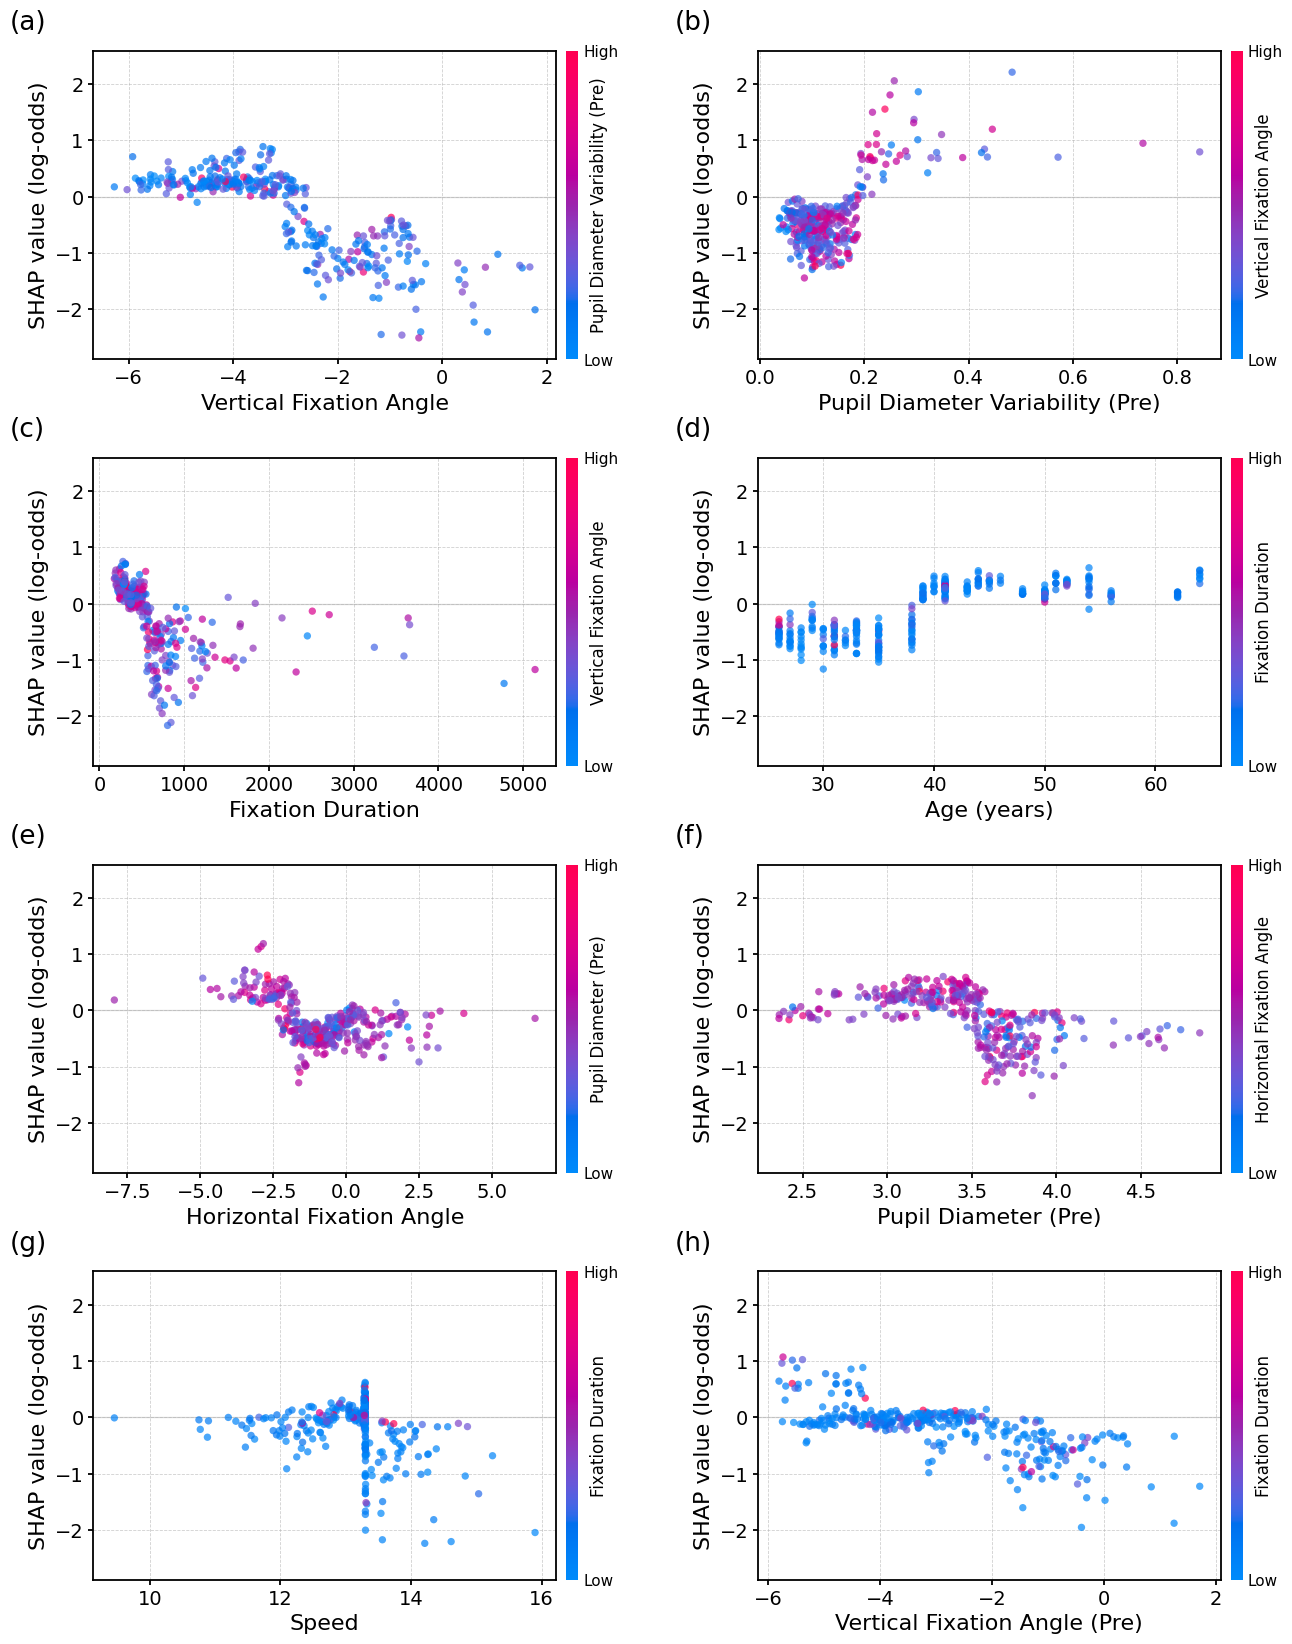

In [ ]:
# =========================================================
# XGB CLASSIFIER — SHAP DEPENDENCE PLOTS (2-column layout)
# Requires shap_all, X_color_all from the SHAP aggregation script.
# Adds: shap_interaction_all (computed here, fold-by-fold).
# =========================================================

import re
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import shap
from xgboost import DMatrix



# =========================================================
# Name mapping
# =========================================================
name_map = {
    "Age": "Age",
    "License": "Driving Experience",
    "Mileage": "Annual Mileage",
    "Gender": "Gender",
    "automation": "Automation",
    "eventType": "Hazard",
    "visibleSpeed": "Speed",
    "pdMean": "Pupil Diameter",
    "pdSd": "Pupil Diameter Variability",
    "blinkNumber": "Blink Number",
    "avgBlinkDuration": "Blink Duration",
    "fixNumber": "Fixation Number",
    "avgFixDuration": "Fixation Duration",
    "fixTE": "Transition Entropy",
    "fixSE": "Stationary Entropy",
    "FixDisperX": "Horizontal Fixation Dispersion",
    "FixDisperY": "Vertical Fixation Dispersion",
    "FixDisperE": "Euclidean Fixation Dispersion",
    "FixMeanPosX": "Horizontal Fixation Angle",
    "FixMeanPosY": "Vertical Fixation Angle",
}

# =========================================================
# Unit lookup for x-axis labels
# =========================================================
# Maps cleaned base names to display units.
UNIT_MAP = {
    "FixMx": "degrees",
    "FixMy": "degrees",
    "VisibleSpeed": "m/s",
    "PupilMean": "mm",
    "PupilStd": "mm",
    "Age": "years",
}


def add_unit(clean_name):
    """Append a unit to a cleaned feature label, if one is defined.
    Handles the '(Pre)' suffix by matching on the base part."""
    # Split off a trailing '(Pre)' so the base can be matched
    base = clean_name.replace(" (Pre)", "").strip()
    unit = UNIT_MAP.get(base)
    if unit is None:
        return clean_name
    return f"{clean_name} ({unit})"


def clean_feature_name(name):
    if "_" in name:
        prefix, val = name.split("_", 1)
        if prefix in ["Gender", "automation", "eventType"]:
            if prefix == "automation":
                val = {"1": "MD", "2": "PAD"}.get(val, val)
            elif prefix == "Gender":
                val = {"M": "Male", "F": "Female"}.get(val, val)
            elif prefix == "eventType":
                val = {
                    "EVENT_MAT_LEFT_VRU": "Left Pedestrian",
                    "EVENT_MAT_RIGHT_VRU": "Right Pedestrian",
                    "EVENT_MAT_ONCOMING": "Oncoming Vehicle",
                }.get(val, val)
            return f"{name_map.get(prefix, prefix)} {val}"
    m = re.match(r"(.+?)_(\d+)$", name)
    if m:
        base, tw = m.groups()
        tw = int(tw)
        return name_map.get(base, base) if tw == 0 else f"{name_map.get(base, base)} (Pre)"
    return name_map.get(name, name)


# =========================================================
# Settings
# =========================================================
N_FEATURES = 8
COLS_PER_ROW = 2
EXCLUDE_BASES = ["avgBlinkDuration", "FixDisperX"]

PUPIL_SCALE_FEATURES_BASE = ["pdMean", "pdSd"]
PUPIL_SCALE_FACTOR = 1000

DOT_SIZE = 28
DOT_ALPHA = 0.7

FONT_AXIS_LABEL = 16
FONT_TICK = 14
FONT_SUBTITLE = 12
FONT_CBAR_LABEL = 12
FONT_CBAR_TICK = 11

PANEL_W = 6.5
PANEL_H = 4.2

SPINE_WIDTH = 1.3
SHAP_CMAP = shap.plots.colors.red_blue

# SHAP values here are in LOG-ODDS space (XGBClassifier pred_contribs)
Y_LABEL = "SHAP value (log-odds)"


def is_excluded(raw_name):
    return any(raw_name.startswith(excl) for excl in EXCLUDE_BASES)


def needs_pupil_scaling(raw_name):
    return any(raw_name.startswith(base) for base in PUPIL_SCALE_FEATURES_BASE)


# =========================================================
# Pick top-N features
# =========================================================
mean_abs_shap = shap_all.abs().mean().sort_values(ascending=False)
all_top = mean_abs_shap.index.tolist()
top_features = [f for f in all_top if not is_excluded(f)][:N_FEATURES]

print(f"Top {N_FEATURES} features for dependence plots (after exclusion):")
for i, f in enumerate(top_features, 1):
    marker = " [×1000 for display]" if needs_pupil_scaling(f) else ""
    print(f"  {i}. {f} -> {clean_feature_name(f)}{marker}")


# =========================================================
# Compute partner features from SHAP interaction values
# =========================================================
feature_names = shap_all.columns.tolist()
n_feats = len(feature_names)

interaction_array = shap_interaction_all.values.reshape(-1, n_feats, n_feats)
mean_abs_inter = np.abs(interaction_array).mean(axis=0)
np.fill_diagonal(mean_abs_inter, -np.inf)

inter_partner = {
    feature_names[i]: feature_names[np.argmax(mean_abs_inter[i])]
    for i in range(n_feats)
}

print("\nSHAP interaction-based partner selection:")
for feat in feature_names:
    partner = inter_partner[feat]
    strength = mean_abs_inter[feature_names.index(feat),
                              feature_names.index(partner)]
    print(f"  {feat:30s} -> {partner:30s}  (mean |phi| = {strength:.4f})")


# =========================================================
# Plot
# =========================================================
n_features = len(top_features)
n_rows = int(np.ceil(n_features / COLS_PER_ROW))

fig, axes = plt.subplots(
    n_rows, COLS_PER_ROW,
    figsize=(COLS_PER_ROW * PANEL_W, n_rows * PANEL_H),
    sharey=False,
)
axes = axes.flatten() if n_features > 1 else [axes]


for i, feat in enumerate(top_features):
    ax = axes[i]

    x_vals = X_color_all[feat].values.astype(float).copy()
    if needs_pupil_scaling(feat):
        x_vals = x_vals * PUPIL_SCALE_FACTOR

    shap_vals = shap_all[feat].values

    interact_feat = inter_partner[feat]
    color_vals = X_color_all[interact_feat].values.astype(float).copy()

    PARTNER_IS_CATEGORICAL = (interact_feat == "eventType")

    if PARTNER_IS_CATEGORICAL:
        norm_color = color_vals  # already 0/1/2

        cat_colors = [
            SHAP_CMAP(0.15),
            SHAP_CMAP(0.50),
            SHAP_CMAP(0.85),
        ]
        cat_cmap = mpl.colors.ListedColormap(cat_colors)
        cat_norm = mpl.colors.BoundaryNorm(
            boundaries=[-0.5, 0.5, 1.5, 2.5], ncolors=3,
        )

        valid_mask = (~np.isnan(x_vals) & ~np.isnan(shap_vals)
                      & ~np.isnan(norm_color))

        sc = ax.scatter(
            x_vals[valid_mask], shap_vals[valid_mask],
            c=norm_color[valid_mask],
            cmap=cat_cmap, norm=cat_norm,
            s=DOT_SIZE, alpha=DOT_ALPHA, linewidths=0,
        )
    else:
        if (~np.isnan(color_vals)).sum() > 0:
            lo = np.nanpercentile(color_vals, 1)
            hi = np.nanpercentile(color_vals, 99)
            if hi > lo:
                norm_color = np.clip((color_vals - lo) / (hi - lo), 0, 1)
            else:
                norm_color = np.full_like(color_vals, 0.5, dtype=float)
        else:
            norm_color = np.full_like(color_vals, 0.5, dtype=float)

        valid_mask = ~np.isnan(x_vals) & ~np.isnan(shap_vals)

        sc = ax.scatter(
            x_vals[valid_mask], shap_vals[valid_mask],
            c=norm_color[valid_mask],
            cmap=SHAP_CMAP,
            s=DOT_SIZE, alpha=DOT_ALPHA, linewidths=0,
        )

    ax.axhline(0, color="lightgray", linewidth=0.8, zorder=0)
    ax.axhline(0, color="lightgray", linewidth=0.8, zorder=0)
    ax.grid(True, linestyle="--", linewidth=0.6, alpha=0.6, zorder=0)
    ax.set_axisbelow(True)

    feat_clean = clean_feature_name(feat)
    interact_clean = clean_feature_name(interact_feat)

    # ax.set_xlabel(feat_clean, fontsize=FONT_AXIS_LABEL)
    ax.set_xlabel(add_unit(feat_clean), fontsize=FONT_AXIS_LABEL)
    ax.set_ylabel(Y_LABEL, fontsize=FONT_AXIS_LABEL)
    ax.tick_params(axis="both", labelsize=FONT_TICK)

    unique_vals = np.unique(x_vals[~np.isnan(x_vals)])
    if len(unique_vals) <= 5:
        ax.set_xticks(unique_vals)
        if feat == "eventType":
            hazard_label_map = {
                0: "Left\nPedestrian",
                1: "Right\nPedestrian",
                2: "Oncoming\nVehicle",
            }
            new_labels = [hazard_label_map.get(int(v), str(int(v)))
                          for v in unique_vals]
            ax.set_xticklabels(new_labels, fontsize=FONT_TICK - 2)


    # Per-panel colourbar
    if PARTNER_IS_CATEGORICAL:
        sm = plt.cm.ScalarMappable(cmap=cat_cmap, norm=cat_norm)
        sm.set_array([])
        cbar = fig.colorbar(sm, ax=ax, pad=0.02, fraction=0.04, aspect=25,
                            ticks=[0, 1, 2], drawedges=False)
        cbar.set_ticklabels(["Left", "Right", "Oncoming"],
                            fontsize=FONT_CBAR_TICK, rotation=90)
        cbar.set_label(interact_clean, fontsize=FONT_CBAR_LABEL, labelpad=2)
        cbar.dividers.set_visible(False)
        cbar.ax.tick_params(axis="y", which="both", length=0, width=0,
                            left=False, right=False)
    else:
        sm = plt.cm.ScalarMappable(cmap=SHAP_CMAP, norm=plt.Normalize(0, 1))
        sm.set_array([])
        cbar = fig.colorbar(sm, ax=ax, pad=0.02, fraction=0.04, aspect=25)
        cbar.set_label(interact_clean, fontsize=FONT_CBAR_LABEL, labelpad=-20)
        cbar.set_ticks([0, 1])
        cbar.set_ticklabels(["Low", "High"])

    cbar.outline.set_visible(False)
    cbar.ax.tick_params(length=0, labelsize=FONT_CBAR_TICK)


# Hide unused subplots
for j in range(n_features, len(axes)):
    axes[j].set_visible(False)

# =========================================================
# Panel labels (A, B, C, ...) in upper-left corner
# =========================================================
import string

PANEL_LABEL_FONTSIZE = 19

for idx in range(n_features):
    ax = axes[idx]
    ax.text(
        -0.18, 1.05, f"({string.ascii_lowercase[idx]})",
        transform=ax.transAxes,
        ha="left", va="bottom",
        fontsize=PANEL_LABEL_FONTSIZE,
        # fontweight="bold",
    )
# =========================================================
# Shared y-axis range across all panels
# =========================================================
# =========================================================
# Shared y-axis range — full data range, with margin
# =========================================================
all_shap_vals = np.concatenate([
    shap_all[feat].values for feat in top_features
])
all_shap_vals = all_shap_vals[~np.isnan(all_shap_vals)]

y_min = all_shap_vals.min()
y_max = all_shap_vals.max()

pad = 0.08 * (y_max - y_min)        # 8% margin on each side
y_lo = y_min - pad
y_hi = y_max + pad

for idx in range(n_features):
    axes[idx].set_ylim(y_lo, y_hi)

print(f"SHAP range: [{y_min:.3f}, {y_max:.3f}] -> ylim [{y_lo:.3f}, {y_hi:.3f}]")

# Layout
plt.subplots_adjust(
    left=0.07, right=0.96, top=0.97, bottom=0.06,
    hspace=0.32, wspace=0.35,
)

# Spines and ticks
for ax in axes:
    if not ax.get_visible():
        continue
    for spine in ax.spines.values():
        if spine.get_visible():
            spine.set_linewidth(SPINE_WIDTH)
            spine.set_edgecolor("black")
    ax.tick_params(axis="x", width=SPINE_WIDTH)
    ax.tick_params(axis="y", width=SPINE_WIDTH)

plt.show()

## Cross-Seed Plot

Final N = 351
0    304
1     47
Name: count, dtype: int64
[LASSO] seed=3558
[LASSO] seed=6687
[LASSO] seed=6836
[LASSO] seed=7862
[LASSO] seed=11033
[LASSO] seed=13285
[LASSO] seed=22075
[LASSO] seed=22163
[LASSO] seed=23858
[LASSO] seed=30690
[XGB] seed=3558
[XGB] seed=6687
[XGB] seed=6836
[XGB] seed=7862
[XGB] seed=11033
[XGB] seed=13285
[XGB] seed=22075
[XGB] seed=22163
[XGB] seed=23858
[XGB] seed=30690

REFIT-vs-RECORDED VERIFICATION

[LASSO (panels a,b)] folds checked: 50
  fold-membership (n_test & n_pos) mismatches: 0
  AUC mismatches (|dAUC| >= 0.001):          0   | max |dAUC| = 0.00000
  >>> PASS: refit reproduces recorded models. LASSO (panels a,b) panels use correct models.

[XGB (panel c)] folds checked: 50
  fold-membership (n_test & n_pos) mismatches: 0
  AUC mismatches (|dAUC| >= 0.001):          0   | max |dAUC| = 0.00000
  >>> PASS: refit reproduces recorded models. XGB (panel c) panels use correct models.

coef_per_seed: (128, 3) | retain_per_seed: (240, 3) | shap_pe

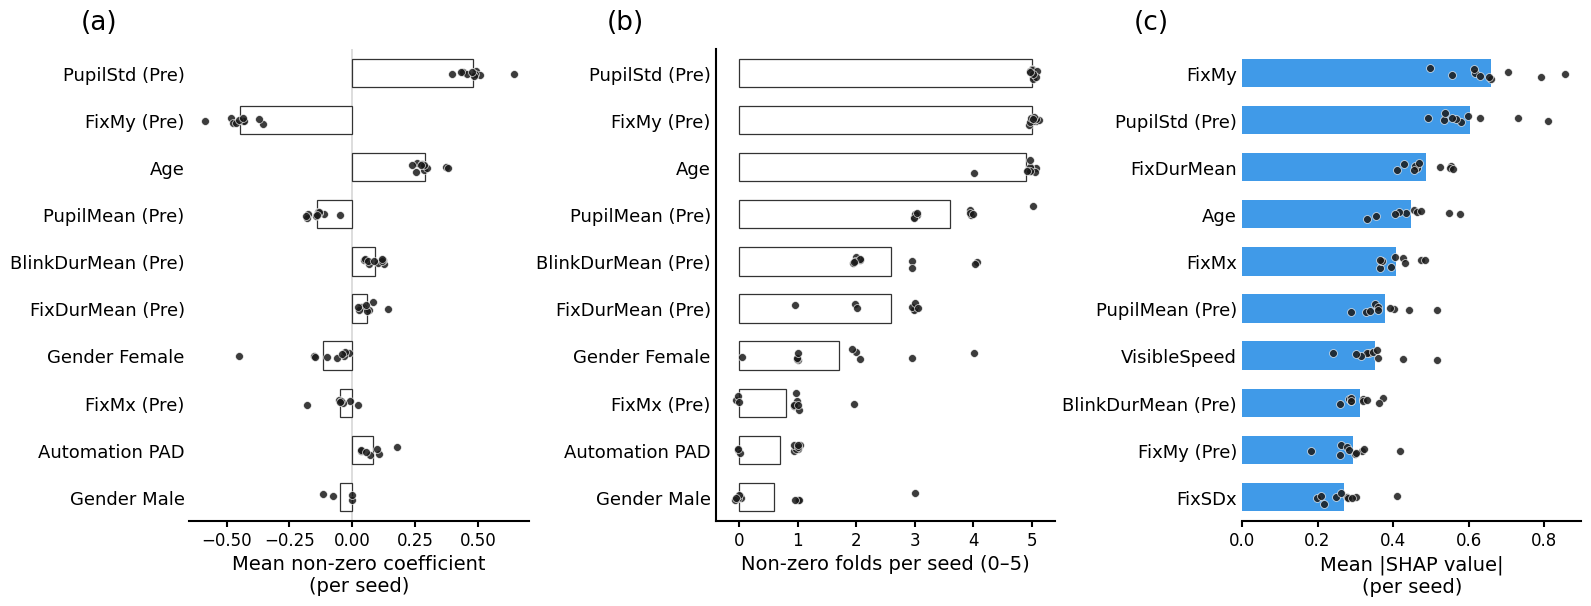

In [ ]:
# =====================================================================
# CROSS-SEED INTERPRETATION FIGURE  +  REFIT-vs-RECORDED CHECK
#   (self-contained: every helper defined in this file)
#
#   Verification (runs inline during the fitting loops):
#     For every seed x fold that feeds the plots, compares the refit
#     test-fold AUC against the AUC recorded in your results xlsx.
#     If all match, the (a)/(b)/(c) plots are built on the recorded models.
#
#   Plots:
#     (a) LASSO single-TW (TW=11): per-seed mean non-zero coefficient,
#                                  distribution across seeds
#     (b) LASSO single-TW (TW=11): per-seed retention count (0..5),
#                                  distribution across seeds
#     (c) XGB   combine-TW (TW=0,13): per-seed mean|SHAP|,
#                                  distribution across seeds
#
#   External inputs only: the Excel data file, the saved per-fold model
#   metadata JSONs, and the two results spreadsheets.
# =====================================================================

import json
import os
import glob
import re
import textwrap
from functools import lru_cache

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec

from sklearn.model_selection import StratifiedGroupKFold
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from xgboost import XGBClassifier, DMatrix


# =====================================================================
# 0. CONFIG  — edit paths here
# =====================================================================
data_path = "/content/drive/MyDrive/Colab_Backups/Data_3sMean_IDT_beforeMat.xlsx"

# LASSO single-TW (panels a, b)
LASSO_BASE_DIR     = "/content/drive/MyDrive/Colab_Backups/LR_test"
LASSO_MODEL_DIR    = "LRC_model_singleTW"
LASSO_RESULTS_PATH = "/content/drive/MyDrive/Colab_Backups/LR_test/LRC_singleTW.xlsx"
LASSO_TWS          = [11]
LASSO_TARGET_TW    = 11

# XGB combine-TW (panel c)
XGB_BASE_DIR     = "/content/drive/MyDrive/Colab_Backups/XGBC"
XGB_MODEL_DIR    = "XGB_model_combineTW"
XGB_RESULTS_PATH = "/content/drive/MyDrive/Colab_Backups/XGBC/XGBC_combineTW.xlsx"
XGB_TWS          = [0, 13]
XGB_TARGET_TW    = 13

SELECTED_SEEDS = [
    3558, 6687, 6836, 7862, 11033,
    13285, 22075, 22163, 23858, 30690,
]

OUTER_SPLITS = 5
TARGET_COL   = "relativeRT"
CAT_NAMES    = ["Gender", "automation", "eventType"]
ZERO_TOL     = 1e-8
TOP_N        = 10
AUC_TOL      = 1e-3          # |refit AUC - recorded AUC| below this counts as a match

# Optional: cache the computed frames so plotting can be re-run without refitting
CACHE_DIR    = "/content/drive/MyDrive/Colab_Backups/crossseed_cache"
SAVE_CACHE   = True     # save computed frames after the (slow) refit
USE_CACHE    = True     # if cache exists, load it and SKIP the refit + verification


# =====================================================================
# 1. HELPERS
# =====================================================================
NAME_MAP = {
    "Age": "Age", "License": "DrivingExperience", "Mileage": "Mileage",
    "Gender": "Gender", "automation": "Automation", "eventType": "Hazard",
    "visibleSpeed": "VisibleSpeed",
    "pdMean": "PupilMean", "pdSd": "PupilStd",
    "blinkNumber": "BlinkNum", "avgBlinkDuration": "BlinkDurMean",
    "fixNumber": "FixNum", "avgFixDuration": "FixDurMean",
    "fixTE": "FixTEntropy", "fixSE": "FixSEntropy",
    "FixDisperX": "FixSDx", "FixDisperY": "FixSDy", "FixDisperE": "FixSDe",
    "FixMeanPosX": "FixMx", "FixMeanPosY": "FixMy",
}


def build_feature_cols(tws):
    templates = [
        "Age", "License", "Mileage",
        "Gender", "automation", "eventType",
        "visibleSpeed",
        "pdMean_{TW}", "pdSd_{TW}",
        "blinkNumber_{TW}", "avgBlinkDuration_{TW}",
        "fixNumber_{TW}", "avgFixDuration_{TW}",
        "fixTE_{TW}", "fixSE_{TW}",
        "FixDisperX_{TW}", "FixDisperY_{TW}", "FixDisperE_{TW}",
        "FixMeanPosX_{TW}", "FixMeanPosY_{TW}",
    ]
    cols = []
    for c in templates:
        if "{TW}" in c:
            cols.extend([c.format(TW=tw) for tw in tws])
        else:
            cols.append(c)
    return cols


def clean_feature_name(name):
    if "_" in name:
        prefix, val = name.split("_", 1)
        if prefix in ["Gender", "automation", "eventType"]:
            if prefix == "automation":
                val = {"1": "MD", "2": "PAD"}.get(val, val)
            elif prefix == "Gender":
                val = {"M": "Male", "F": "Female"}.get(val, val)
            elif prefix == "eventType":
                val = {
                    "EVENT_MAT_LEFT_VRU": "Left Pedestrian",
                    "EVENT_MAT_RIGHT_VRU": "Right Pedestrian",
                    "EVENT_MAT_ONCOMING": "Oncoming Vehicle",
                }.get(val, val)
            return f"{NAME_MAP.get(prefix, prefix)} {val}"
    m = re.match(r"(.+?)_(\d+)$", name)
    if m:
        base, tw = m.groups()
        base_clean = NAME_MAP.get(base, base)
        return base_clean if int(tw) == 0 else f"{base_clean} (Pre)"
    return NAME_MAP.get(name, name)


def wrap_labels(label, width=20):
    return "\n".join(textwrap.wrap(label, width))


def fit_outer_onehot(X_train_raw, X_test_raw, cat_cols):
    X_train_raw = X_train_raw.copy()
    X_test_raw = X_test_raw.copy()
    use_cat = [c for c in cat_cols if c in X_train_raw.columns]
    for c in use_cat:
        cats = pd.Index(X_train_raw[c].dropna().unique())
        dtype = pd.CategoricalDtype(categories=cats, ordered=False)
        X_train_raw[c] = X_train_raw[c].astype(dtype)
        X_test_raw[c] = X_test_raw[c].astype(dtype)
    X_tr = pd.get_dummies(X_train_raw, columns=use_cat, drop_first=False)
    X_te = pd.get_dummies(X_test_raw, columns=use_cat, drop_first=False)
    X_te = X_te.reindex(columns=X_tr.columns, fill_value=0)
    return X_tr.astype(np.float32), X_te.astype(np.float32)


def ensure_categorical_dtype_from_train(train_df, test_df, cat_cols):
    train_df = train_df.copy()
    test_df = test_df.copy()
    for col in cat_cols:
        if col in train_df.columns:
            cats = pd.Index(train_df[col].dropna().unique())
            dtype = pd.CategoricalDtype(categories=cats, ordered=False)
            train_df[col] = train_df[col].astype(dtype)
            test_df[col] = test_df[col].astype(dtype)
    return train_df, test_df


def _load_meta(base_dir, model_dir, prefix, seed, tw, outer_fold):
    folder = os.path.join(base_dir, model_dir)
    patterns = [
        f"{prefix}_seed_{seed:02d}_*TW_{tw:02d}_outerfold_{outer_fold:02d}_meta.json",
        f"{prefix}_seed_{seed:02d}_TW_{tw:02d}_outerfold_{outer_fold:02d}_meta.json",
    ]
    candidates = []
    for p in patterns:
        candidates = glob.glob(os.path.join(folder, p))
        if candidates:
            break
    if not candidates:
        raise FileNotFoundError(
            f"No {prefix} metadata for seed={seed}, TW={tw}, fold={outer_fold} in {folder}"
        )
    path = sorted(candidates, key=len)[0]
    with open(path, "r", encoding="utf-8") as f:
        meta = json.load(f)
    return meta, path


def get_xgb_shap_values(model, X_proc):
    dm = DMatrix(X_proc, enable_categorical=True)
    contribs = model.get_booster().predict(dm, pred_contribs=True)
    return contribs[:, :-1], contribs[:, -1]


@lru_cache(maxsize=None)
def _load_results(path):
    res = pd.read_excel(path)
    res["outer_fold"] = res["outer_fold"].astype(str)
    res["TW"]   = pd.to_numeric(res["TW"], errors="coerce")
    res["AUC"]  = pd.to_numeric(res["AUC"], errors="coerce")
    res["seed"] = pd.to_numeric(res["seed"], errors="coerce")
    return res


def recorded_row(path, seed, tw, outer_fold):
    res = _load_results(path)
    r = res[(res["seed"] == seed) & (res["TW"] == tw) &
            (res["outer_fold"] == str(outer_fold))]
    return None if r.empty else r.iloc[0]


# =====================================================================
# 2. LOAD + FILTER DATA
# =====================================================================
df = pd.read_excel(data_path)

allowed_events = {"EVENT_MAT_RIGHT_VRU", "EVENT_MAT_LEFT_VRU", "EVENT_MAT_ONCOMING"}
unexpected = set(df["eventType"].dropna().unique()) - allowed_events
if unexpected:
    raise ValueError(f"Unexpected eventType(s): {unexpected}")

df[TARGET_COL] = pd.to_numeric(df[TARGET_COL], errors="coerce")
df = df.dropna(subset=[TARGET_COL, "eventType", "subNumber"]).copy()

df["rt85_by_event"] = df.groupby("eventType")[TARGET_COL].transform(
    lambda x: x.quantile(0.85)
)
df["RT85_cls"] = (df[TARGET_COL] >= df["rt85_by_event"]).astype(int)

tww_cols = [f"perValid_{i}" for i in range(31)]
df = df[df[tww_cols].mean(axis=1) >= 74.5].copy()

y = df["RT85_cls"].values.astype(int)
groups = df["subNumber"].values
y_strat = y.copy()

print(f"Final N = {len(df)}")
print(pd.Series(y).value_counts().sort_index())


# =====================================================================
# 2b. CACHE PROBE — if cached frames exist and USE_CACHE, load & skip refit
# =====================================================================
_CACHE_FILES = {
    "coef":   os.path.join(CACHE_DIR, "coef_per_seed.parquet"),
    "retain": os.path.join(CACHE_DIR, "retain_per_seed.parquet"),
    "shap":   os.path.join(CACHE_DIR, "shap_per_seed.parquet"),
}
_CACHE_HIT = USE_CACHE and all(os.path.exists(f) for f in _CACHE_FILES.values())

if _CACHE_HIT:
    coef_per_seed   = pd.read_parquet(_CACHE_FILES["coef"])
    retain_per_seed = pd.read_parquet(_CACHE_FILES["retain"])
    shap_per_seed   = pd.read_parquet(_CACHE_FILES["shap"])
    print("\n[cache] Loaded coef/retain/shap from", CACHE_DIR,
          "-> skipping refit + verification.")


if not _CACHE_HIT:
    # =====================================================================
    # 3. LASSO loop  -> coef_per_seed, retain_per_seed  (+ inline AUC check)
    # =====================================================================
    X_lasso = df[build_feature_cols(LASSO_TWS)].copy()
    coef_records = []
    lasso_check = []

    for seed in SELECTED_SEEDS:
        print(f"[LASSO] seed={seed}")
        cv = StratifiedGroupKFold(n_splits=OUTER_SPLITS, shuffle=True, random_state=seed)
        for outer_fold, (tr, te) in enumerate(cv.split(X_lasso, y_strat, groups), start=1):
            X_tr, X_te = X_lasso.iloc[tr].copy(), X_lasso.iloc[te].copy()
            y_tr, y_te = y[tr], y[te]

            meta, _ = _load_meta(LASSO_BASE_DIR, LASSO_MODEL_DIR, "lr",
                                 seed, LASSO_TARGET_TW, outer_fold)
            best_params = meta["best_params"]

            X_tr_oh, X_te_oh = fit_outer_onehot(X_tr, X_te, CAT_NAMES)

            imp = SimpleImputer(strategy="median")
            X_tr_oh = pd.DataFrame(imp.fit_transform(X_tr_oh),
                                   columns=X_tr_oh.columns, index=X_tr_oh.index)
            X_te_oh = pd.DataFrame(imp.transform(X_te_oh),
                                   columns=X_te_oh.columns, index=X_te_oh.index)
            sc = StandardScaler()
            X_tr_oh = pd.DataFrame(sc.fit_transform(X_tr_oh),
                                   columns=X_tr_oh.columns, index=X_tr_oh.index)
            X_te_oh = pd.DataFrame(sc.transform(X_te_oh),
                                   columns=X_te_oh.columns, index=X_te_oh.index)

            model = LogisticRegression(**best_params)
            model.fit(X_tr_oh, y_tr)

            # coefficients (panels a, b)
            for feat, c in zip(X_tr_oh.columns, model.coef_.ravel()):
                coef_records.append({
                    "seed": seed, "outer_fold": outer_fold, "feature": feat,
                    "coef": c, "selected": abs(c) > ZERO_TOL,
                })

            # inline refit-vs-recorded AUC check
            refit_auc = roc_auc_score(y_te, model.predict_proba(X_te_oh)[:, 1])
            rec = recorded_row(LASSO_RESULTS_PATH, seed, LASSO_TARGET_TW, outer_fold)
            lasso_check.append({
                "seed": seed, "fold": outer_fold,
                "refit_AUC": refit_auc,
                "rec_AUC": float(rec["AUC"]) if rec is not None else np.nan,
                "rec_n": int(rec["n_test"]) if rec is not None else -1,
                "refit_n": len(te),
                "rec_pos": int(rec["n_pos_test"]) if rec is not None else -1,
                "refit_pos": int(y_te.sum()),
            })

    coef_long = pd.DataFrame(coef_records)

    coef_per_seed = (
        coef_long[coef_long["selected"]]
        .groupby(["seed", "feature"], as_index=False)
        .agg(mean_coef_when_retained=("coef", "mean"))
    )
    retain_per_seed = (
        coef_long.groupby(["seed", "feature"], as_index=False)
        .agg(retained_count=("selected", "sum"))
    )


    # =====================================================================
    # 4. XGB loop  -> shap_per_seed  (+ inline AUC check)
    # =====================================================================
    X_xgb = df[build_feature_cols(XGB_TWS)].copy()
    shap_records = []
    xgb_check = []

    for seed in SELECTED_SEEDS:
        print(f"[XGB] seed={seed}")
        cv = StratifiedGroupKFold(n_splits=OUTER_SPLITS, shuffle=True, random_state=seed)
        seed_abs_shap = []
        for outer_fold, (tr, te) in enumerate(cv.split(X_xgb, y_strat, groups), start=1):
            X_tr, X_te = X_xgb.iloc[tr].copy(), X_xgb.iloc[te].copy()
            y_tr, y_te = y[tr], y[te]

            meta, _ = _load_meta(XGB_BASE_DIR, XGB_MODEL_DIR, "xgb",
                                 seed, XGB_TARGET_TW, outer_fold)
            best_params = meta["best_params"]

            sel_feats = meta.get("selected_features", None)
            if sel_feats is not None:
                sel_feats = [c for c in sel_feats if c in X_tr.columns]
                X_tr, X_te = X_tr[sel_feats].copy(), X_te[sel_feats].copy()

            X_tr_proc, X_te_proc = ensure_categorical_dtype_from_train(X_tr, X_te, CAT_NAMES)

            model = XGBClassifier(**best_params)
            model.fit(X_tr_proc, y_tr)

            # SHAP (panel c)
            shap_values, _ = get_xgb_shap_values(model, X_te_proc)
            seed_abs_shap.append(pd.DataFrame(
                np.abs(shap_values), columns=X_te_proc.columns, index=X_te_proc.index
            ))

            # inline refit-vs-recorded AUC check
            refit_auc = roc_auc_score(y_te, model.predict_proba(X_te_proc)[:, 1])
            rec = recorded_row(XGB_RESULTS_PATH, seed, XGB_TARGET_TW, outer_fold)
            xgb_check.append({
                "seed": seed, "fold": outer_fold,
                "refit_AUC": refit_auc,
                "rec_AUC": float(rec["AUC"]) if rec is not None else np.nan,
                "rec_n": int(rec["n_test"]) if rec is not None else -1,
                "refit_n": len(te),
                "rec_pos": int(rec["n_pos_test"]) if rec is not None else -1,
                "refit_pos": int(y_te.sum()),
            })

        seed_abs_all = pd.concat(seed_abs_shap, axis=0)
        mean_abs = seed_abs_all.mean(axis=0)
        for feat, v in mean_abs.items():
            shap_records.append({"seed": seed, "feature": feat, "mean_abs_shap": v})

    shap_per_seed = pd.DataFrame(shap_records)


    # =====================================================================
    # 4b. VERIFICATION VERDICT
    # =====================================================================
    def _report(name, recs):
        chk = pd.DataFrame(recs)
        chk["dAUC"] = (chk["refit_AUC"] - chk["rec_AUC"]).abs()
        chk["size_OK"] = (chk["rec_n"] == chk["refit_n"]) & (chk["rec_pos"] == chk["refit_pos"])
        chk["AUC_OK"] = chk["dAUC"] < AUC_TOL
        n_size_bad = (~chk["size_OK"]).sum()
        n_auc_bad = (~chk["AUC_OK"]).sum()
        print(f"\n[{name}] folds checked: {len(chk)}")
        print(f"  fold-membership (n_test & n_pos) mismatches: {n_size_bad}")
        print(f"  AUC mismatches (|dAUC| >= {AUC_TOL}):          {n_auc_bad}"
              f"   | max |dAUC| = {chk['dAUC'].max():.5f}")
        if n_size_bad == 0 and n_auc_bad == 0:
            print(f"  >>> PASS: refit reproduces recorded models. {name} panels use correct models.")
        else:
            print(f"  >>> MISMATCH — offending folds:")
            print(chk[(~chk['size_OK']) | (~chk['AUC_OK'])].to_string(index=False))
        return chk

    print("\n" + "=" * 70)
    print("REFIT-vs-RECORDED VERIFICATION")
    print("=" * 70)
    lasso_chk = _report("LASSO (panels a,b)", lasso_check)
    xgb_chk   = _report("XGB (panel c)",      xgb_check)

    print("\ncoef_per_seed:", coef_per_seed.shape,
          "| retain_per_seed:", retain_per_seed.shape,
          "| shap_per_seed:", shap_per_seed.shape)


    # =====================================================================
    # 4c. OPTIONAL CACHE
    # =====================================================================
    if SAVE_CACHE:
        try:
            os.makedirs(CACHE_DIR, exist_ok=True)
            coef_per_seed.to_parquet(os.path.join(CACHE_DIR, "coef_per_seed.parquet"))
            retain_per_seed.to_parquet(os.path.join(CACHE_DIR, "retain_per_seed.parquet"))
            shap_per_seed.to_parquet(os.path.join(CACHE_DIR, "shap_per_seed.parquet"))
            print(f"\nCached frames saved to {CACHE_DIR}")
        except Exception as e:
            print(f"\n[warn] cache save skipped: {e}")


# =====================================================================
# 5. ORDER FEATURES
# =====================================================================
ret_mean = retain_per_seed.groupby("feature")["retained_count"].mean().rename("ret_mean")
coef_absmean = (
    coef_per_seed.assign(abs_c=coef_per_seed["mean_coef_when_retained"].abs())
    .groupby("feature")["abs_c"].mean().rename("coef_absmean")
)
lasso_rank = pd.concat([ret_mean, coef_absmean], axis=1).fillna(0.0)
lasso_rank = lasso_rank.sort_values(["ret_mean", "coef_absmean"], ascending=[False, False])
lasso_features_plot = lasso_rank.head(TOP_N).index.tolist()[::-1]
lasso_labels = [clean_feature_name(f) for f in lasso_features_plot]
n_lasso = len(lasso_features_plot)

shap_rank = shap_per_seed.groupby("feature")["mean_abs_shap"].mean().sort_values(ascending=False)
shap_features_plot = shap_rank.head(TOP_N).index.tolist()[::-1]
shap_labels = [clean_feature_name(f) for f in shap_features_plot]
n_shap = len(shap_features_plot)


# =====================================================================
# 6. PLOT — three panels in one row
# =====================================================================
DOT_COLOR, DOT_SIZE, DOT_ALPHA = "#1A1A1A", 32, 0.85
BAR_FACE, BAR_EDGE, BAR_EDGEW = "white", "#333333", 0.9
SHAP_BAR_FACE = "#1E88E5"
BAR_HEIGHT = 0.6
FS_XLAB, FS_XTICK, FS_Y = 14, 12, 13
PANEL_FS, SPINE_W = 19, 1.5
N_SEEDS = len(SELECTED_SEEDS)
rng = np.random.default_rng(42)

fig = plt.figure(figsize=(16, 6.2))
gs = GridSpec(1, 3, figure=fig, width_ratios=[1, 1, 1], wspace=0.55)
ax_coef = fig.add_subplot(gs[0, 0])
ax_ret  = fig.add_subplot(gs[0, 1])
ax_shap = fig.add_subplot(gs[0, 2])

# (a) coefficient distribution
for i, feat in enumerate(lasso_features_plot):
    vals = coef_per_seed.loc[coef_per_seed["feature"] == feat,
                             "mean_coef_when_retained"].dropna().values
    if len(vals) == 0:
        continue
    ax_coef.barh(i, np.mean(vals), color=BAR_FACE, edgecolor=BAR_EDGE,
                 linewidth=BAR_EDGEW, height=BAR_HEIGHT, zorder=2)
    ax_coef.scatter(vals, rng.normal(i, 0.06, size=len(vals)),
                    color=DOT_COLOR, s=DOT_SIZE, alpha=DOT_ALPHA,
                    edgecolor="white", linewidth=0.5, zorder=5)
ax_coef.axvline(0, color="lightgray", linewidth=1.1, zorder=0)
ax_coef.set_yticks(range(n_lasso))
ax_coef.set_yticklabels([wrap_labels(l) for l in lasso_labels], fontsize=FS_Y)
ax_coef.set_xlabel("Mean non-zero coefficient\n(per seed)", fontsize=FS_XLAB)
ax_coef.set_ylim(-0.5, n_lasso - 0.5)

# (b) retention-count distribution
for i, feat in enumerate(lasso_features_plot):
    vals = retain_per_seed.loc[retain_per_seed["feature"] == feat,
                               "retained_count"].values.astype(float)
    if len(vals) == 0:
        vals = np.zeros(N_SEEDS)
    ax_ret.barh(i, np.mean(vals), color=BAR_FACE, edgecolor=BAR_EDGE,
                linewidth=BAR_EDGEW, height=BAR_HEIGHT, zorder=2)
    xj = vals + rng.normal(0, 0.04, size=len(vals))
    ax_ret.scatter(xj, rng.normal(i, 0.07, size=len(vals)),
                   color=DOT_COLOR, s=DOT_SIZE, alpha=DOT_ALPHA,
                   edgecolor="white", linewidth=0.5, zorder=5)
ax_ret.set_yticks(range(n_lasso))
ax_ret.set_yticklabels([wrap_labels(l) for l in lasso_labels], fontsize=FS_Y)
ax_ret.set_xlabel(f"Non-zero folds per seed (0\u2013{OUTER_SPLITS})", fontsize=FS_XLAB)
ax_ret.set_xlim(-0.4, OUTER_SPLITS + 0.4)
ax_ret.set_xticks(range(OUTER_SPLITS + 1))
ax_ret.set_ylim(-0.5, n_lasso - 0.5)

# (c) mean|SHAP| distribution
for i, feat in enumerate(shap_features_plot):
    vals = shap_per_seed.loc[shap_per_seed["feature"] == feat,
                             "mean_abs_shap"].dropna().values
    if len(vals) == 0:
        continue
    ax_shap.barh(i, np.mean(vals), color=SHAP_BAR_FACE, edgecolor="none",
                 height=BAR_HEIGHT, alpha=0.85, zorder=2)
    ax_shap.scatter(vals, rng.normal(i, 0.06, size=len(vals)),
                    color=DOT_COLOR, s=DOT_SIZE, alpha=DOT_ALPHA,
                    edgecolor="white", linewidth=0.5, zorder=5)
ax_shap.set_yticks(range(n_shap))
ax_shap.set_yticklabels([wrap_labels(l) for l in shap_labels], fontsize=FS_Y)
ax_shap.set_xlabel("Mean |SHAP value|\n(per seed)", fontsize=FS_XLAB)
ax_shap.set_xlim(left=0)
ax_shap.set_ylim(-0.5, n_shap - 0.5)

# spines / ticks / panel labels
for ax in [ax_coef, ax_ret, ax_shap]:
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.grid(axis="both", visible=False)
    for spine in ax.spines.values():
        if spine.get_visible():
            spine.set_linewidth(SPINE_W)
            spine.set_edgecolor("black")
    ax.tick_params(axis="x", labelsize=FS_XTICK, length=4, width=SPINE_W,
                   colors="black", direction="out", bottom=True, top=False)
    ax.tick_params(axis="y", labelsize=FS_Y, length=0)

for ax in [ax_coef, ax_shap]:
    ax.spines["left"].set_visible(False)

for ax, lab in [(ax_coef, "(a)"), (ax_ret, "(b)"), (ax_shap, "(c)")]:
    ax.text(-0.32, 1.03, lab, transform=ax.transAxes,
            ha="left", va="bottom", fontsize=PANEL_FS)

fig.subplots_adjust(left=0.10, right=0.97, top=0.92, bottom=0.16, wspace=0.55)
plt.show()

In [ ]:

# If the frames aren't in memory (e.g., fresh kernel), load them from cache.
CACHE_DIR = "/content/drive/MyDrive/Colab_Backups/crossseed_cache"
if "coef_per_seed" not in globals():
    coef_per_seed   = pd.read_parquet(os.path.join(CACHE_DIR, "coef_per_seed.parquet"))
    retain_per_seed = pd.read_parquet(os.path.join(CACHE_DIR, "retain_per_seed.parquet"))
    shap_per_seed   = pd.read_parquet(os.path.join(CACHE_DIR, "shap_per_seed.parquet"))
    print("Loaded cached frames from", CACHE_DIR)

# =====================================================================
# 5. ORDER FEATURES
# =====================================================================
# LASSO (a & b share order): mean retention across seeds, then mean|coef|
ret_mean = retain_per_seed.groupby("feature")["retained_count"].mean().rename("ret_mean")
coef_absmean = (
    coef_per_seed.assign(abs_c=coef_per_seed["mean_coef_when_retained"].abs())
    .groupby("feature")["abs_c"].mean().rename("coef_absmean")
)
lasso_rank = pd.concat([ret_mean, coef_absmean], axis=1).fillna(0.0)
lasso_rank = lasso_rank.sort_values(["ret_mean", "coef_absmean"], ascending=[False, False])
lasso_features_plot = lasso_rank.head(TOP_N).index.tolist()[::-1]   # least->most for barh
lasso_labels = [clean_feature_name(f) for f in lasso_features_plot]
n_lasso = len(lasso_features_plot)

# SHAP (c): mean of per-seed mean|SHAP| across seeds
shap_rank = shap_per_seed.groupby("feature")["mean_abs_shap"].mean().sort_values(ascending=False)
shap_features_plot = shap_rank.head(TOP_N).index.tolist()[::-1]
shap_labels = [clean_feature_name(f) for f in shap_features_plot]
n_shap = len(shap_features_plot)



# =====================================================================
# 6. PLOT  — three panels in one row
# =====================================================================
DOT_COLOR, DOT_SIZE, DOT_ALPHA = "#1A1A1A", 32, 0.85
BAR_FACE, BAR_EDGE, BAR_EDGEW = "white", "#333333", 0.9
SHAP_BAR_FACE = "#1E88E5"
BAR_HEIGHT = 0.6
FS_XLAB, FS_XTICK, FS_Y = 14, 12, 13
PANEL_FS, SPINE_W = 19, 1.5
N_SEEDS = len(SELECTED_SEEDS)
rng = np.random.default_rng(42)

fig = plt.figure(figsize=(16, 6.2))
gs = GridSpec(1, 3, figure=fig, width_ratios=[1, 1, 1], wspace=0.55)
ax_coef = fig.add_subplot(gs[0, 0])
ax_ret  = fig.add_subplot(gs[0, 1])
ax_shap = fig.add_subplot(gs[0, 2])

# ---- (a) coefficient distribution ----
for i, feat in enumerate(lasso_features_plot):
    vals = coef_per_seed.loc[coef_per_seed["feature"] == feat,
                             "mean_coef_when_retained"].dropna().values
    if len(vals) == 0:
        continue
    ax_coef.barh(i, np.mean(vals), color=BAR_FACE, edgecolor=BAR_EDGE,
                 linewidth=BAR_EDGEW, height=BAR_HEIGHT, zorder=2)
    ax_coef.scatter(vals, rng.normal(i, 0.06, size=len(vals)),
                    color=DOT_COLOR, s=DOT_SIZE, alpha=DOT_ALPHA,
                    edgecolor="white", linewidth=0.5, zorder=5)
ax_coef.axvline(0, color="lightgray", linewidth=1.1, zorder=0)
ax_coef.set_yticks(range(n_lasso))
ax_coef.set_yticklabels([wrap_labels(l) for l in lasso_labels], fontsize=FS_Y)
ax_coef.set_xlabel("Mean non-zero coefficient\n(per seed)", fontsize=FS_XLAB)
ax_coef.set_ylim(-0.5, n_lasso - 0.5)

# ---- (b) retention-count distribution ----
for i, feat in enumerate(lasso_features_plot):
    vals = retain_per_seed.loc[retain_per_seed["feature"] == feat,
                               "retained_count"].values.astype(float)
    if len(vals) == 0:
        vals = np.zeros(N_SEEDS)
    ax_ret.barh(i, np.mean(vals), color=BAR_FACE, edgecolor=BAR_EDGE,
                linewidth=BAR_EDGEW, height=BAR_HEIGHT, zorder=2)
    xj = vals + rng.normal(0, 0.04, size=len(vals))   # x-jitter separates ties
    ax_ret.scatter(xj, rng.normal(i, 0.07, size=len(vals)),
                   color=DOT_COLOR, s=DOT_SIZE, alpha=DOT_ALPHA,
                   edgecolor="white", linewidth=0.5, zorder=5)
ax_ret.set_yticks(range(n_lasso))
ax_ret.set_yticklabels([wrap_labels(l) for l in lasso_labels], fontsize=FS_Y)
ax_ret.set_xlabel(f"Non-zero folds per seed (0\u2013{OUTER_SPLITS})", fontsize=FS_XLAB)
ax_ret.set_xlim(-0.4, OUTER_SPLITS + 0.4)
ax_ret.set_xticks(range(OUTER_SPLITS + 1))
ax_ret.set_ylim(-0.5, n_lasso - 0.5)

# ---- (c) mean|SHAP| distribution ----
for i, feat in enumerate(shap_features_plot):
    vals = shap_per_seed.loc[shap_per_seed["feature"] == feat,
                             "mean_abs_shap"].dropna().values
    if len(vals) == 0:
        continue
    ax_shap.barh(i, np.mean(vals), color=SHAP_BAR_FACE, edgecolor="none",
                 height=BAR_HEIGHT, alpha=0.85, zorder=2)
    ax_shap.scatter(vals, rng.normal(i, 0.06, size=len(vals)),
                    color=DOT_COLOR, s=DOT_SIZE, alpha=DOT_ALPHA,
                    edgecolor="white", linewidth=0.5, zorder=5)
ax_shap.set_yticks(range(n_shap))
ax_shap.set_yticklabels([wrap_labels(l) for l in shap_labels], fontsize=FS_Y)
ax_shap.set_xlabel("Mean |SHAP value|\n(per seed)", fontsize=FS_XLAB)
ax_shap.set_xlim(left=0)
ax_shap.set_ylim(-0.5, n_shap - 0.5)

# ---- spines / ticks / panel labels ----
for ax in [ax_coef, ax_ret, ax_shap]:
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.grid(axis="both", visible=False)
    for spine in ax.spines.values():
        if spine.get_visible():
            spine.set_linewidth(SPINE_W)
            spine.set_edgecolor("black")
    ax.tick_params(axis="x", labelsize=FS_XTICK, length=4, width=SPINE_W,
                   colors="black", direction="out", bottom=True, top=False)
    ax.tick_params(axis="y", labelsize=FS_Y, length=0)

for ax in [ax_coef, ax_shap]:        # zero-line panels: hide left spine
    ax.spines["left"].set_visible(False)

for ax, lab in [(ax_coef, "(a)"), (ax_ret, "(b)"), (ax_shap, "(c)")]:
    ax.text(-0.32, 1.03, lab, transform=ax.transAxes,
            ha="left", va="bottom", fontsize=PANEL_FS)

fig.subplots_adjust(left=0.10, right=0.97, top=0.92, bottom=0.16, wspace=0.55)
plt.show()

# SHAP/Coefficient Regression

## Get Data

In [ ]:
# =========================================================
# REGRESSION: refit XGB & LASSO best-seed across outer folds
# Collect SHAP (XGB) + coefficients (LASSO)
# Then 4-panel plot mirroring the classifier figure
# =========================================================

import json
import os
import glob
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import shap
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import GroupKFold
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Lasso
from xgboost import XGBRegressor, DMatrix


# =========================================================
# 1. SETTINGS
# =========================================================
# --- shared ---
selected_seeds_reg = [
    261, 452, 285, 966, 786,
    1423, 3789, 5602, 8741, 11905
]

outer_splits = 5
target_col   = "relativeRT"
cat_names    = ["Gender", "automation", "eventType"]
top_n_features = 10

# --- XGB regression ---
xgb_data_path    = "/content/drive/MyDrive/Colab_Backups/Data_3sMean_IDT_beforeMat.xlsx"
xgb_results_path = "/content/drive/MyDrive/Colab_Backups/XGBR/XGBR_combineTW.xlsx"
xgb_base_dir     = "/content/drive/MyDrive/Colab_Backups/XGBR"
xgb_model_dir    = "XGB_model_combineTW"
xgb_targetTW     = 21
xgb_TWs          = [0, 21]

# --- LASSO regression ---
lasso_data_path    = "/content/drive/MyDrive/Colab_Backups/Data_3sMean_IDT_beforeMat.xlsx"
lasso_results_path = "/content/drive/MyDrive/Colab_Backups/LRR/LRR_combineTW.xlsx"
lasso_base_dir     = "/content/drive/MyDrive/Colab_Backups/LRR"
lasso_model_dir    = "LR_model_combineTW"
lasso_targetTW     = 20
lasso_TWs          = [0, 20]


# =========================================================
# 2. HELPERS
# =========================================================
def build_feature_cols(TWs):
    feature_templates = [
        "Age", "License", "Mileage",
        "Gender", "automation", "eventType",
        "visibleSpeed",
        "pdMean_{TW}", "pdSd_{TW}",
        "blinkNumber_{TW}",
        "avgBlinkDuration_{TW}",
        "fixNumber_{TW}",
        "avgFixDuration_{TW}",
        "fixTE_{TW}", "fixSE_{TW}",
        "FixDisperX_{TW}", "FixDisperY_{TW}",
        "FixDisperE_{TW}",
        "FixMeanPosX_{TW}", "FixMeanPosY_{TW}",
    ]
    feature_cols = []
    for c in feature_templates:
        if "{TW}" in c:
            feature_cols.extend([c.format(TW=tw) for tw in TWs])
        else:
            feature_cols.append(c)
    return feature_cols


def ensure_categorical_dtype_from_train(train_df, test_df, cat_cols):
    train_df = train_df.copy()
    test_df  = test_df.copy()
    for col in cat_cols:
        if col in train_df.columns:
            cats = pd.Index(train_df[col].dropna().unique())
            dtype = pd.CategoricalDtype(categories=cats, ordered=False)
            train_df[col] = train_df[col].astype(dtype)
            test_df[col]  = test_df[col].astype(dtype)
    return train_df, test_df


def fit_outer_onehot(X_train_raw, X_test_raw, cat_cols):
    X_train_raw = X_train_raw.copy()
    X_test_raw  = X_test_raw.copy()
    use_cat = [c for c in cat_cols if c in X_train_raw.columns]
    for c in use_cat:
        train_cats = pd.Index(X_train_raw[c].dropna().unique())
        dtype = pd.CategoricalDtype(categories=train_cats, ordered=False)
        X_train_raw[c] = X_train_raw[c].astype(dtype)
        X_test_raw[c]  = X_test_raw[c].astype(dtype)
    X_train_oh = pd.get_dummies(X_train_raw, columns=use_cat, drop_first=False)
    X_test_oh  = pd.get_dummies(X_test_raw,  columns=use_cat, drop_first=False)
    X_test_oh  = X_test_oh.reindex(columns=X_train_oh.columns, fill_value=0)
    return X_train_oh.astype(np.float32), X_test_oh.astype(np.float32)


def find_best_seed_reg(results_path, targetTW, selected_seeds, metric="RMSE", direction="min"):
    res = pd.read_excel(results_path)
    res["outer_fold"] = res["outer_fold"].astype(str)
    res["TW"]     = pd.to_numeric(res["TW"], errors="coerce")
    res[metric]   = pd.to_numeric(res[metric], errors="coerce")

    sub = res[
        (res["outer_fold"] == "SUMMARY") &
        (res["TW"] == targetTW) &
        (res["seed"].isin(selected_seeds))
    ].copy()
    if sub.empty:
        raise ValueError(f"No SUMMARY rows for TW={targetTW}")

    if direction == "min":
        best_row = sub.loc[sub[metric].idxmin()]
        sort_asc = True
    else:
        best_row = sub.loc[sub[metric].idxmax()]
        sort_asc = False
    return int(best_row["seed"]), float(best_row[metric]), sub.sort_values(metric, ascending=sort_asc)


def load_xgb_params_reg(base_dir, model_dir, seed, tw, outer_fold):
    folder = os.path.join(base_dir, model_dir)
    candidates = glob.glob(os.path.join(
        folder,
        f"xgb_seed_{seed:02d}_*TW_{tw:02d}_outerfold_{outer_fold:02d}_meta.json"
    ))
    if len(candidates) == 0:
        candidates = glob.glob(os.path.join(
            folder,
            f"xgb_seed_{seed:02d}_TW_{tw:02d}_outerfold_{outer_fold:02d}_meta.json"
        ))
    if len(candidates) == 0:
        raise FileNotFoundError(f"No XGB metadata: seed={seed}, TW={tw}, fold={outer_fold}")
    path = sorted(candidates, key=len)[0]
    with open(path, "r", encoding="utf-8") as f:
        meta = json.load(f)
    return meta["best_params"], meta, path


def load_lasso_params_reg(base_dir, model_dir, seed, tw, outer_fold):
    folder = os.path.join(base_dir, model_dir)
    candidates = glob.glob(os.path.join(
        folder,
        f"lr_seed_{seed:02d}_*TW_{tw:02d}_outerfold_{outer_fold:02d}_meta.json"
    ))
    if len(candidates) == 0:
        candidates = glob.glob(os.path.join(
            folder,
            f"lr_seed_{seed:02d}_TW_{tw:02d}_outerfold_{outer_fold:02d}_meta.json"
        ))
    if len(candidates) == 0:
        raise FileNotFoundError(f"No LASSO metadata: seed={seed}, TW={tw}, fold={outer_fold}")
    path = sorted(candidates, key=len)[0]
    with open(path, "r", encoding="utf-8") as f:
        meta = json.load(f)
    return meta["best_params"], meta, path


# def make_numeric_for_color(X_df):
#     """Convert features to numeric for beeswarm coloring."""
#     X_color = X_df.copy()
#     for c in X_color.columns:
#         if str(X_color[c].dtype) == "category" or X_color[c].dtype == "object":
#             X_color[c] = X_color[c].astype("category").cat.codes.replace(-1, np.nan)
#         else:
#             X_color[c] = pd.to_numeric(X_color[c], errors="coerce")
#     return X_color.astype(float)
def make_numeric_for_color(X_df):
    """Convert features to numeric for beeswarm coloring."""
    X_color = X_df.copy()
    for c in X_color.columns:
        if c == "eventType":
            # Force canonical order so codes are stable across folds
            X_color[c] = pd.Categorical(
                X_color[c].astype(str),                    # strip categorical dtype first
                categories=HAZARD_ORDER,
                ordered=False,
            ).codes
            X_color[c] = X_color[c].replace(-1, np.nan).astype(float)
        elif str(X_color[c].dtype) == "category" or X_color[c].dtype == "object":
            X_color[c] = X_color[c].astype("category").cat.codes.replace(-1, np.nan)
        else:
            X_color[c] = pd.to_numeric(X_color[c], errors="coerce")
    return X_color.astype(float)

def get_xgb_shap_values(model, X_proc):
    """SHAP via XGBoost pred_contribs. For regression, output is in target units."""
    dm = DMatrix(X_proc, enable_categorical=True)
    contribs = model.get_booster().predict(dm, pred_contribs=True)
    shap_values = contribs[:, :-1]
    base_values = contribs[:, -1]
    return shap_values, base_values


def make_groupkfold(n_splits, seed):
    """
    Wrap GroupKFold to handle older sklearn that doesn't accept random_state/shuffle.
    Your training script passes them, so newer sklearn — but this fallback keeps it portable.
    """
    try:
        return GroupKFold(n_splits=n_splits, shuffle=True, random_state=seed)
    except TypeError:
        return GroupKFold(n_splits=n_splits)


def load_and_prepare_data(data_path, target_col):
    df = pd.read_excel(data_path)
    allowed_events = {"EVENT_MAT_RIGHT_VRU", "EVENT_MAT_LEFT_VRU", "EVENT_MAT_ONCOMING"}
    unexpected = set(df["eventType"].dropna().unique()) - allowed_events
    if unexpected:
        raise ValueError(f"Unexpected eventType(s): {unexpected}")

    df[target_col] = pd.to_numeric(df[target_col], errors="coerce")
    df = df.dropna(subset=[target_col, "eventType", "subNumber"]).copy()

    tww_cols = [f"perValid_{i}" for i in range(31)]
    df = df[df[tww_cols].mean(axis=1) >= 74.5].copy()

    y = df[target_col].values.astype(float)
    groups = df["subNumber"].values
    return df, y, groups

# NEW:
HAZARD_ORDER  = ["EVENT_MAT_LEFT_VRU", "EVENT_MAT_RIGHT_VRU", "EVENT_MAT_ONCOMING"]
HAZARD_LABELS = ["Left\nPedestrian", "Right\nPedestrian", "Oncoming\nVehicle"]
# =========================================================
# 3. XGB: find best seed → refit folds → collect SHAP
# =========================================================
df_xgb, y_xgb, groups_xgb = load_and_prepare_data(xgb_data_path, target_col)
print(f"[XGB] N = {len(df_xgb)}")

best_seed_xgb, best_xgb_rmse, _ = find_best_seed_reg(
    xgb_results_path, xgb_targetTW, selected_seeds_reg, metric="RMSE", direction="min"
)
print(f"[XGB] Best seed = {best_seed_xgb}, SUMMARY RMSE = {best_xgb_rmse:.4f}")

xgb_feature_cols = build_feature_cols(xgb_TWs)
X_xgb = df_xgb[xgb_feature_cols].copy()

outer_cv_xgb = make_groupkfold(outer_splits, best_seed_xgb)

all_shap = []
all_X_color = []
all_shap_interaction = []   # 👈 add this before the loop
for outer_fold, (tr_idx, te_idx) in enumerate(
    outer_cv_xgb.split(X_xgb, y_xgb, groups_xgb), start=1
):
    print(f"\n[XGB] Outer fold {outer_fold}/{outer_splits}")

    X_train = X_xgb.iloc[tr_idx].copy()
    X_test  = X_xgb.iloc[te_idx].copy()
    y_train = y_xgb[tr_idx]
    y_test  = y_xgb[te_idx]

    best_params, meta, meta_path = load_xgb_params_reg(
        xgb_base_dir, xgb_model_dir, best_seed_xgb, xgb_targetTW, outer_fold
    )

    selected_features = meta.get("selected_features", None)
    if selected_features is not None:
        selected_features = [c for c in selected_features if c in X_train.columns]
        X_train = X_train[selected_features].copy()
        X_test  = X_test[selected_features].copy()

    X_train_proc, X_test_proc = ensure_categorical_dtype_from_train(
        X_train, X_test, cat_names
    )

    model = XGBRegressor(**best_params)
    model.fit(X_train_proc, y_train, verbose=False)

    y_pred = model.predict(X_test_proc)
    fold_rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    fold_r2   = r2_score(y_test, y_pred)
    print(f"   Fold {outer_fold}: RMSE = {fold_rmse:.4f}, R² = {fold_r2:.4f}")

    # Regular SHAP values via XGBoost's pred_contribs (this still works with category dtype)
    shap_values, _ = get_xgb_shap_values(model, X_test_proc)

    # For SHAP interaction values: convert categoricals to numeric codes
    # (TreeExplainer doesn't accept category dtype directly)
    X_test_for_shap = X_test_proc.copy()
    for col in cat_names:
        if col in X_test_for_shap.columns:
            X_test_for_shap[col] = X_test_for_shap[col].cat.codes.astype(np.float32)

    # Now compute interaction values
    explainer = shap.TreeExplainer(model)
    shap_inter_fold = explainer.shap_interaction_values(X_test_for_shap)

    shap_inter_df_fold = pd.DataFrame(
        index=X_test_proc.index,
        columns=pd.MultiIndex.from_product(
            [X_test_proc.columns, X_test_proc.columns],
            names=["feat_i", "feat_j"]
        ),
        data=shap_inter_fold.reshape(shap_inter_fold.shape[0], -1)
    )
    all_shap_interaction.append(shap_inter_df_fold)


    shap_df_fold = pd.DataFrame(
        shap_values, columns=X_test_proc.columns, index=X_test_proc.index
    )
    X_color_fold = make_numeric_for_color(X_test_proc)[shap_df_fold.columns]

    all_shap.append(shap_df_fold)
    all_X_color.append(X_color_fold)

shap_all    = pd.concat(all_shap, axis=0)
X_color_all = pd.concat(all_X_color, axis=0)
shap_interaction_all = pd.concat(all_shap_interaction, axis=0)

# =========================================================
# 4. LASSO: find best seed → refit folds → collect coefficients
# =========================================================
df_lasso, y_lasso, groups_lasso = load_and_prepare_data(lasso_data_path, target_col)
print(f"\n[LASSO] N = {len(df_lasso)}")

best_seed_lasso, best_lasso_rmse, _ = find_best_seed_reg(
    lasso_results_path, lasso_targetTW, selected_seeds_reg, metric="RMSE", direction="min"
)
print(f"[LASSO] Best seed = {best_seed_lasso}, SUMMARY RMSE = {best_lasso_rmse:.4f}")

lasso_feature_cols = build_feature_cols(lasso_TWs)
X_lasso = df_lasso[lasso_feature_cols].copy()

outer_cv_lasso = make_groupkfold(outer_splits, best_seed_lasso)

coef_rows = []


for outer_fold, (tr_idx, te_idx) in enumerate(
    outer_cv_lasso.split(X_lasso, y_lasso, groups_lasso), start=1
):
    print(f"\n[LASSO] Outer fold {outer_fold}/{outer_splits}")

    X_train = X_lasso.iloc[tr_idx].copy()
    X_test  = X_lasso.iloc[te_idx].copy()
    y_train = y_lasso[tr_idx]
    y_test  = y_lasso[te_idx]

    best_params, meta, meta_path = load_lasso_params_reg(
        lasso_base_dir, lasso_model_dir, best_seed_lasso, lasso_targetTW, outer_fold
    )

    X_train_proc, X_test_proc = fit_outer_onehot(X_train, X_test, cat_names)

    imputer = SimpleImputer(strategy="median")
    X_train_proc = pd.DataFrame(
        imputer.fit_transform(X_train_proc),
        columns=X_train_proc.columns, index=X_train_proc.index,
    )
    X_test_proc = pd.DataFrame(
        imputer.transform(X_test_proc),
        columns=X_test_proc.columns, index=X_test_proc.index,
    )

    scaler = StandardScaler()
    X_train_proc = pd.DataFrame(
        scaler.fit_transform(X_train_proc),
        columns=X_train_proc.columns, index=X_train_proc.index,
    )
    X_test_proc = pd.DataFrame(
        scaler.transform(X_test_proc),
        columns=X_test_proc.columns, index=X_test_proc.index,
    )

    model = Lasso(**best_params)
    model.fit(X_train_proc, y_train)

    y_pred = model.predict(X_test_proc)
    fold_rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    fold_r2   = r2_score(y_test, y_pred)
    print(f"   Fold {outer_fold}: RMSE = {fold_rmse:.4f}, R² = {fold_r2:.4f}")

    # Lasso.coef_ shape (n_features,) — already 1-D
    coefs = np.asarray(model.coef_).ravel()

    fold_coef_df = pd.DataFrame({
        "outer_fold": outer_fold,
        "feature":    X_train_proc.columns,
        "coef":       coefs,
    })
    fold_coef_df["abs_coef"] = fold_coef_df["coef"].abs()
    fold_coef_df["selected"] = fold_coef_df["coef"].abs() > 1e-8
    coef_rows.append(fold_coef_df)

coef_all = pd.concat(coef_rows, ignore_index=True)


# =========================================================
# 5. Aggregate LASSO retention + coefficients
# =========================================================
coef_summary = (
    coef_all.groupby("feature", as_index=False)
            .agg(
                retained_count          = ("selected", "sum"),
                mean_coef_all_folds     = ("coef", "mean"),
                mean_abs_coef_all_folds = ("abs_coef", "mean"),
                sd_coef_all_folds       = ("coef", "std"),
            )
)
nonzero = coef_all[coef_all["selected"]].copy()
coef_when_retained = (
    nonzero.groupby("feature", as_index=False)
           .agg(
               mean_coef_when_retained     = ("coef", "mean"),
               mean_abs_coef_when_retained = ("abs_coef", "mean"),
               sd_coef_when_retained       = ("coef", "std"),
           )
)
coef_summary = coef_summary.merge(coef_when_retained, on="feature", how="left")
coef_summary["retention_rate"] = coef_summary["retained_count"] / outer_splits


[XGB] N = 351
[XGB] Best seed = 3789, SUMMARY RMSE = 0.8183

[XGB] Outer fold 1/5
   Fold 1: RMSE = 0.7832, R² = 0.5240

[XGB] Outer fold 2/5
   Fold 2: RMSE = 0.6654, R² = 0.4073

[XGB] Outer fold 3/5
   Fold 3: RMSE = 0.9097, R² = 0.4311

[XGB] Outer fold 4/5
   Fold 4: RMSE = 1.0129, R² = 0.4166

[XGB] Outer fold 5/5
   Fold 5: RMSE = 0.7206, R² = 0.4549

[LASSO] N = 351
[LASSO] Best seed = 3789, SUMMARY RMSE = 0.8434

[LASSO] Outer fold 1/5
   Fold 1: RMSE = 0.7847, R² = 0.5222

[LASSO] Outer fold 2/5
   Fold 2: RMSE = 0.7620, R² = 0.2227

[LASSO] Outer fold 3/5
   Fold 3: RMSE = 0.9367, R² = 0.3969

[LASSO] Outer fold 4/5
   Fold 4: RMSE = 0.9709, R² = 0.4640

[LASSO] Outer fold 5/5
   Fold 5: RMSE = 0.7627, R² = 0.3894


## Plot

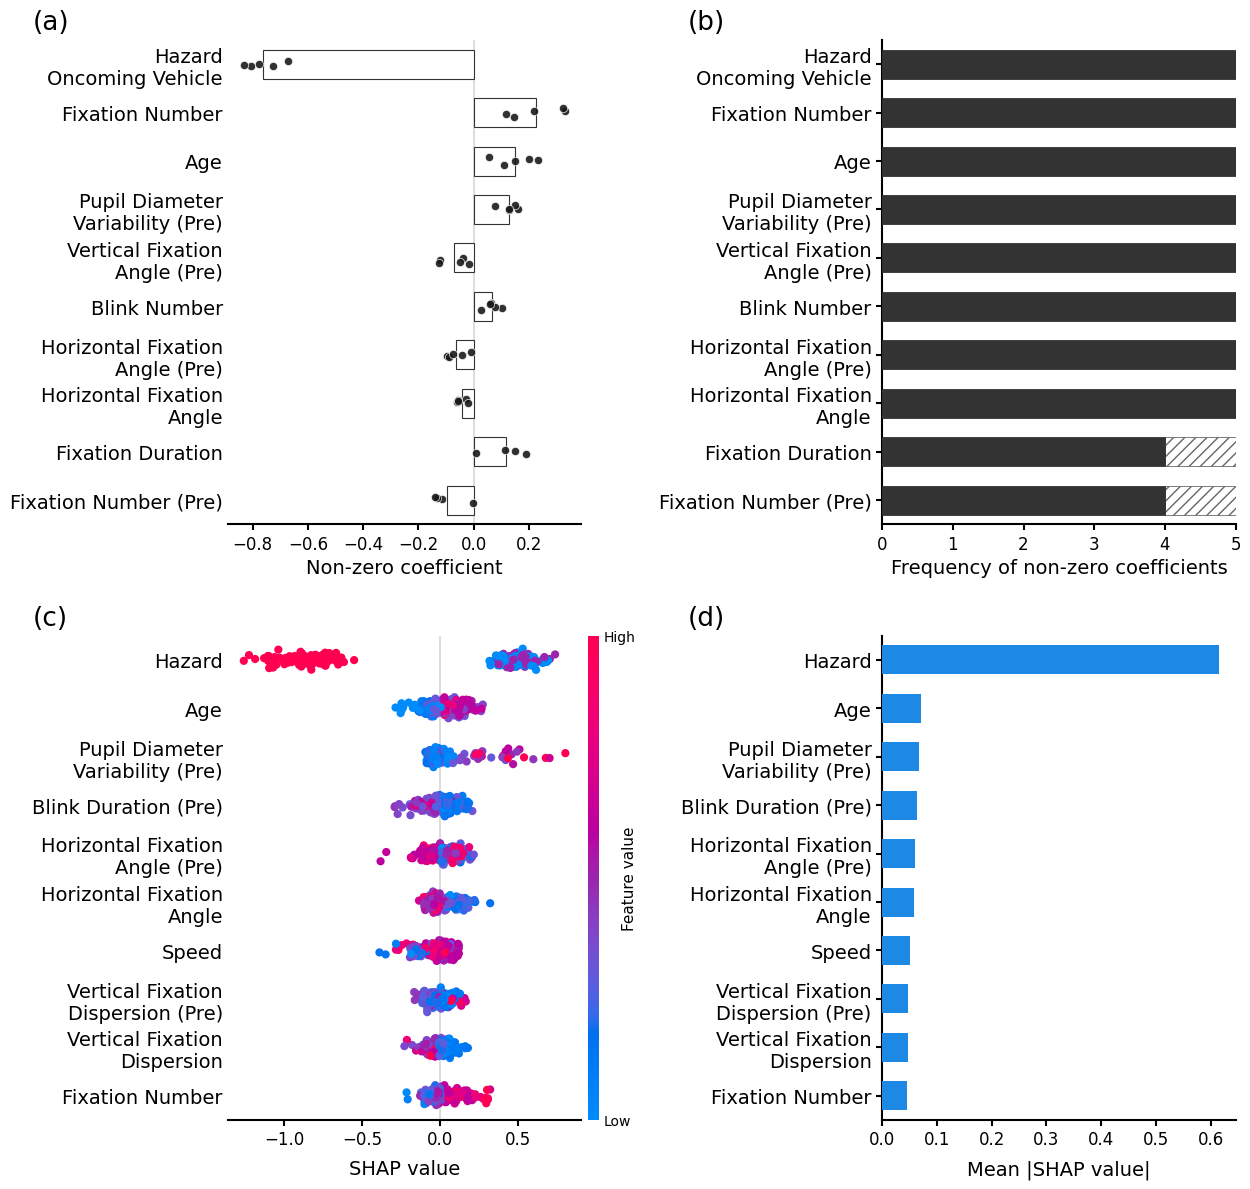

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import matplotlib.colors as mcolors
from matplotlib.gridspec import GridSpec
import re
import textwrap
import shap

# --- Name mapping and label cleaning ---
# name_map = {
#     "Age": "Age", "License": "DrivingExperience", "Mileage": "Mileage",
#     "Gender": "Gender", "automation": "Automation", "eventType": "Hazard",
#     "visibleSpeed": "VisibleSpeed",
#     "pdMean": "PupilMean", "pdSd": "PupilStd",
#     "blinkNumber": "BlinkNum", "avgBlinkDuration": "BlinkDurMean",
#     "fixNumber": "FixNum", "avgFixDuration": "FixDurMean",
#     "fixTE": "FixTEntropy", "fixSE": "FixSEntropy",
#     "FixDisperX": "FixSDx", "FixDisperY": "FixSDy", "FixDisperE": "FixSDe",
#     "FixMeanPosX": "FixMx", "FixMeanPosY": "FixMy"
# }

name_map = {
    "Age": "Age",
    "License": "Driving Experience",
    "Mileage": "Annual Mileage",
    "Gender": "Gender",
    "automation": "Automation",
    "eventType": "Hazard",
    "visibleSpeed": "Speed",
    "pdMean": "Pupil Diameter",
    "pdSd": "Pupil Diameter Variability",
    "blinkNumber": "Blink Number",
    "avgBlinkDuration": "Blink Duration",
    "fixNumber": "Fixation Number",
    "avgFixDuration": "Fixation Duration",
    "fixTE": "Transition Entropy",
    "fixSE": "Stationary Entropy",
    "FixDisperX": "Horizontal Fixation Dispersion",
    "FixDisperY": "Vertical Fixation Dispersion",
    "FixDisperE": "Euclidean Fixation Dispersion",
    "FixMeanPosX": "Horizontal Fixation Angle",
    "FixMeanPosY": "Vertical Fixation Angle",
}


def clean_feature_name(name):
    if "_" in name:
        prefix, val = name.split("_", 1)
        if prefix in ["Gender", "automation", "eventType"]:
            if prefix == "automation": val = {"1":"MD","2":"PAD"}.get(val,val)
            if prefix == "Gender": val = {"M":"Male","F":"Female"}.get(val,val)
            if prefix == "eventType": val = {"EVENT_MAT_LEFT_VRU":"Left Pedestrian",
                                             "EVENT_MAT_RIGHT_VRU":"Right Pedestrian",
                                             "EVENT_MAT_ONCOMING":"Oncoming Vehicle"}.get(val,val)
            return f"{name_map.get(prefix,prefix)} {val}"
    m = re.match(r"(.+?)_(\d+)$", name)
    if m: base, tw = m.groups(); return name_map.get(base, base) if int(tw)==0 else f"{name_map.get(base,base)} (Pre)"
    return name_map.get(name,name)

def wrap_labels(label, width=22):
    if label == "Hazard Oncoming Vehicle":
        return "Hazard\nOncoming Vehicle"
    return "\n".join(textwrap.wrap(label, width))

# --- Styling constants ---
top_n_lasso = 10
top_n_shap  = 10
DOT_COLOR = "#1A1A1A"; DOT_SIZE=35; DOT_ALPHA=0.9
LASSO_BAR_FACE_COLOR="white"; LASSO_BAR_EDGE_COLOR="#333333"; LASSO_BAR_EDGE_WIDTH=0.8
SHAP_BAR_COLOR="#1E88E5"; SHAP_BAR_ALPHA=1.0
SHAP_DOT_SIZE=35; SHAP_DOT_ALPHA=1
BAR_HEIGHT=0.6
fontsize_x_label=14; fontsize_x_tick=12; fontsize_y=14

# --- Prepare LASSO data ---
lasso_plot_df = coef_summary[coef_summary["retained_count"]>0].copy()
lasso_plot_df = lasso_plot_df.sort_values(["retained_count","mean_abs_coef_when_retained"], ascending=[False,False]).head(top_n_lasso)
lasso_plot_df = lasso_plot_df.sort_values(["retained_count","mean_abs_coef_when_retained"], ascending=[True,True]).reset_index(drop=True)
top_lasso_features = lasso_plot_df["feature"].tolist()
lasso_box_df = coef_all[(coef_all["feature"].isin(top_lasso_features)) & coef_all["selected"]].copy()
lasso_plot_df["feature_clean"] = lasso_plot_df["feature"].apply(clean_feature_name)
lasso_box_df["feature_clean"] = lasso_box_df["feature"].apply(clean_feature_name)
lasso_order = lasso_plot_df["feature_clean"].tolist()
n_lasso = len(lasso_order)
max_ret = lasso_plot_df["retained_count"].max()

# --- Prepare SHAP data ---
mean_abs_shap_raw = shap_all.abs().mean().sort_values(ascending=False)
top_shap_features_raw = mean_abs_shap_raw.head(top_n_shap).index.tolist()
shap_plot_features_raw = top_shap_features_raw[::-1]
shap_plot_labels = [clean_feature_name(f) for f in shap_plot_features_raw]
n_shap = len(shap_plot_labels)

# --- Figure setup ---
fig = plt.figure(figsize=(12,12))
gs = GridSpec(2,2,figure=fig,width_ratios=[1,1])
ax_lasso_coef = fig.add_subplot(gs[0,0])
ax_lasso_ret  = fig.add_subplot(gs[0,1])
ax_shap_swarm = fig.add_subplot(gs[1,0])
ax_shap_bar   = fig.add_subplot(gs[1,1])

# --- LASSO coefficient bars + fold dots ---
for i,fname in enumerate(lasso_order):
    vals = lasso_box_df[lasso_box_df["feature_clean"]==fname]["coef"].dropna().values
    if len(vals)==0: continue
    mean_val = np.mean(vals)
    ax_lasso_coef.barh(y=i,width=mean_val,color=LASSO_BAR_FACE_COLOR, edgecolor=LASSO_BAR_EDGE_COLOR,
                       linewidth=LASSO_BAR_EDGE_WIDTH,height=BAR_HEIGHT,zorder=2)
    rng = np.random.default_rng(42+i)
    y_jitter = rng.normal(i,0.06,size=len(vals))
    ax_lasso_coef.scatter(vals,y_jitter,color=DOT_COLOR,s=DOT_SIZE,alpha=DOT_ALPHA,
                          edgecolor="white",linewidth=0.5,zorder=5)

ax_lasso_coef.set_yticks(range(n_lasso))
ax_lasso_coef.set_yticklabels([wrap_labels(f) for f in lasso_order],fontsize=fontsize_y)
ax_lasso_coef.set_xlabel("Non-zero coefficient",fontsize=fontsize_x_label)
ax_lasso_coef.grid(axis="y",linestyle="--",linewidth=0.8,alpha=0.3)
ax_lasso_coef.set_ylim(-0.5,n_lasso-0.5)

# --- LASSO retention bars — full-length bar with proportion filled ---
y_pos = np.arange(n_lasso)
retained_counts = lasso_plot_df["retained_count"].values
total_folds = int(retained_counts.max())
unfilled_counts = total_folds - retained_counts

ax_lasso_ret.barh(
    y_pos, retained_counts,
    color="#333333", edgecolor="#333333", linewidth=0.6,
    height=BAR_HEIGHT, zorder=5,
)
ax_lasso_ret.barh(
    y_pos, unfilled_counts, left=retained_counts,
    facecolor="white", edgecolor="#666666", linewidth=0.6,
    hatch="///", height=BAR_HEIGHT, zorder=4,
)
ax_lasso_ret.set_yticks(y_pos)
ax_lasso_ret.set_yticklabels([wrap_labels(f) for f in lasso_order], fontsize=fontsize_y)
ax_lasso_ret.set_ylim(-0.5, n_lasso - 0.5)
ax_lasso_ret.set_xlim(0, total_folds)
ax_lasso_ret.set_xlabel("Frequency of non-zero coefficients", fontsize=fontsize_x_label)

# --- SHAP summary bars ---
y_pos_shap = np.arange(n_shap)
shap_bar_values = mean_abs_shap_raw.head(top_n_shap).sort_values(ascending=True)
ax_shap_bar.barh(y_pos_shap, shap_bar_values.values, color=SHAP_BAR_COLOR, edgecolor="none",
                 height=BAR_HEIGHT, zorder=5)
ax_shap_bar.set_yticks(y_pos_shap)
ax_shap_bar.set_yticklabels([wrap_labels(l) for l in shap_plot_labels], fontsize=fontsize_y)
ax_shap_bar.set_ylim(-0.5, n_shap-0.5)
ax_shap_bar.set_xlabel("Mean |SHAP value|", fontsize=fontsize_x_label, labelpad=8)

# --- SHAP beeswarm ---
rng = np.random.default_rng(42)
shap_cmap = shap.plots.colors.red_blue
for y_pos, f in enumerate(shap_plot_features_raw):
    sv = shap_all[f].values; cv = X_color_all[f].values
    valid = ~np.isnan(sv)
    sv = sv[valid]; cv=cv[valid]
    lo, hi = np.nanpercentile(cv,1), np.nanpercentile(cv,99)
    nc = np.full_like(sv,0.5,dtype=float) if hi==lo else np.clip((cv-lo)/(hi-lo),0,1)
    jitter = rng.normal(0,0.075,size=len(sv))
    ax_shap_swarm.scatter(sv, y_pos+jitter, c=nc, cmap=shap_cmap, s=SHAP_DOT_SIZE,
                          alpha=SHAP_DOT_ALPHA, linewidths=0)
ax_shap_swarm.set_yticks(range(n_shap))
ax_shap_swarm.set_yticklabels([wrap_labels(l) for l in shap_plot_labels], fontsize=fontsize_y)
ax_shap_swarm.set_xlabel("SHAP value", fontsize=fontsize_x_label, labelpad=8)
ax_shap_swarm.set_ylim(-0.5, n_shap-0.5)
ax_shap_swarm.grid(axis="y", linestyle="--", linewidth=0.8, alpha=0.3)

# --- SHAP colorbar ---
sm = plt.cm.ScalarMappable(cmap=shap_cmap, norm=plt.Normalize(0,1))
sm.set_array([])
# cbar = fig.colorbar(sm, ax=ax_shap_swarm, pad=0.02, fraction=0.04)
cax = ax_shap_swarm.inset_axes([1.02, 0.0, 0.03, 1.0])  # x, y, w, h in axes coords
cbar = fig.colorbar(sm, cax=cax)
cbar.set_label("Feature value", fontsize=11, labelpad=-10)
cbar.set_ticks([0,1])
cbar.set_ticklabels(["Low","High"])
cbar.outline.set_visible(False)
cbar.ax.tick_params(length=0)

posA = ax_lasso_coef.get_position()
posC = ax_shap_swarm.get_position()
# force C to A's left edge and width
ax_shap_swarm.set_position([posA.x0, posC.y0, posA.width, posC.height])

posB = ax_lasso_ret.get_position()
posD = ax_shap_bar.get_position()
ax_shap_bar.set_position([posB.x0, posD.y0, posB.width, posD.height])
# --- Initial spine hiding and zero lines ---
for ax in [ax_lasso_coef, ax_lasso_ret, ax_shap_swarm, ax_shap_bar]:
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.grid(axis="both", visible=False)

for ax in [ax_lasso_coef, ax_shap_swarm]:
    ax.spines["left"].set_visible(False)

ax_lasso_coef.axvline(0, color="lightgray", linewidth=1.1, zorder=0)
ax_shap_swarm.axvline(0, color="lightgray", linewidth=1.1, zorder=0)

# --- Align labels / layout ---
fig.align_ylabels([ax_lasso_coef, ax_shap_swarm])
fig.align_ylabels([ax_lasso_ret, ax_shap_bar])
plt.subplots_adjust(left=0.12, right=0.96, hspace=0.27, wspace=0.75, top=0.96, bottom=0.06)

# --- Panel labels (a) (b) (c) (d) ---
plt.subplots_adjust(
    left=0.12,
    right=0.96,
    hspace=0.23,
    wspace=0.85,
    top=0.96,
    bottom=0.06,
)

PANEL_LABEL_FONTSIZE = 19

panel_labels = [
    (ax_lasso_coef, "(a)"),
    (ax_lasso_ret,  "(b)"),
    (ax_shap_swarm, "(c)"),
    (ax_shap_bar,   "(d)"),
]

for ax, label in panel_labels:
    ax.text(
        -0.55, 1.01,                # 👈 push further left and slightly up
        label,
        transform=ax.transAxes,
        ha="left", va="bottom",
        fontsize=PANEL_LABEL_FONTSIZE,
        # fontweight="bold",          # 👈 bold makes labels stand out as panel markers
    )

# --- Final spine and tick styling ---
SPINE_WIDTH = 1.5

for ax in [ax_lasso_coef, ax_lasso_ret, ax_shap_swarm, ax_shap_bar]:
    # Spines
    for spine in ax.spines.values():
        if spine.get_visible():
            spine.set_linewidth(SPINE_WIDTH)
            spine.set_edgecolor("black")

    # X-ticks: visible, black, matching spine width
    ax.tick_params(
        axis="x",
        labelsize=fontsize_x_tick,
        length=4,
        width=SPINE_WIDTH,
        colors="black",
        direction="out",
        bottom=True,
        top=False,
    )

    # Y-ticks default: hide tick marks but keep labels
    ax.tick_params(
        axis="y",
        labelsize=fontsize_y,
        length=0,
    )

# Y-ticks for panels (b) and (d) only — visible black ticks
for ax in [ax_lasso_ret, ax_shap_bar]:
    ax.tick_params(
        axis="y",
        labelsize=fontsize_y,
        length=4,
        width=SPINE_WIDTH,
        colors="black",
        direction="out",
        left=True,
        right=False,
    )

plt.show()

## Dependence Plot

Top 8 features for dependence plots (after exclusion):
  1. eventType -> Hazard
  2. Age -> Age
  3. pdSd_21 -> Pupil Diameter Variability (Pre) [x1000 for display]
  4. avgBlinkDuration_21 -> Blink Duration (Pre)
  5. FixMeanPosX_21 -> Horizontal Fixation Angle (Pre)
  6. FixDisperY_21 -> Vertical Fixation Dispersion (Pre)
  7. FixDisperY_0 -> Vertical Fixation Dispersion
  8. fixNumber_0 -> Fixation Number

SHAP interaction-based partner selection:
  Age                            -> eventType                       (mean |phi| = 0.0128)
  License                        -> Age                             (mean |phi| = 0.0030)
  Mileage                        -> eventType                       (mean |phi| = 0.0049)
  Gender                         -> eventType                       (mean |phi| = 0.0014)
  automation                     -> visibleSpeed                    (mean |phi| = 0.0005)
  eventType                      -> avgBlinkDuration_21             (mean |phi| = 0.0262)
  vis

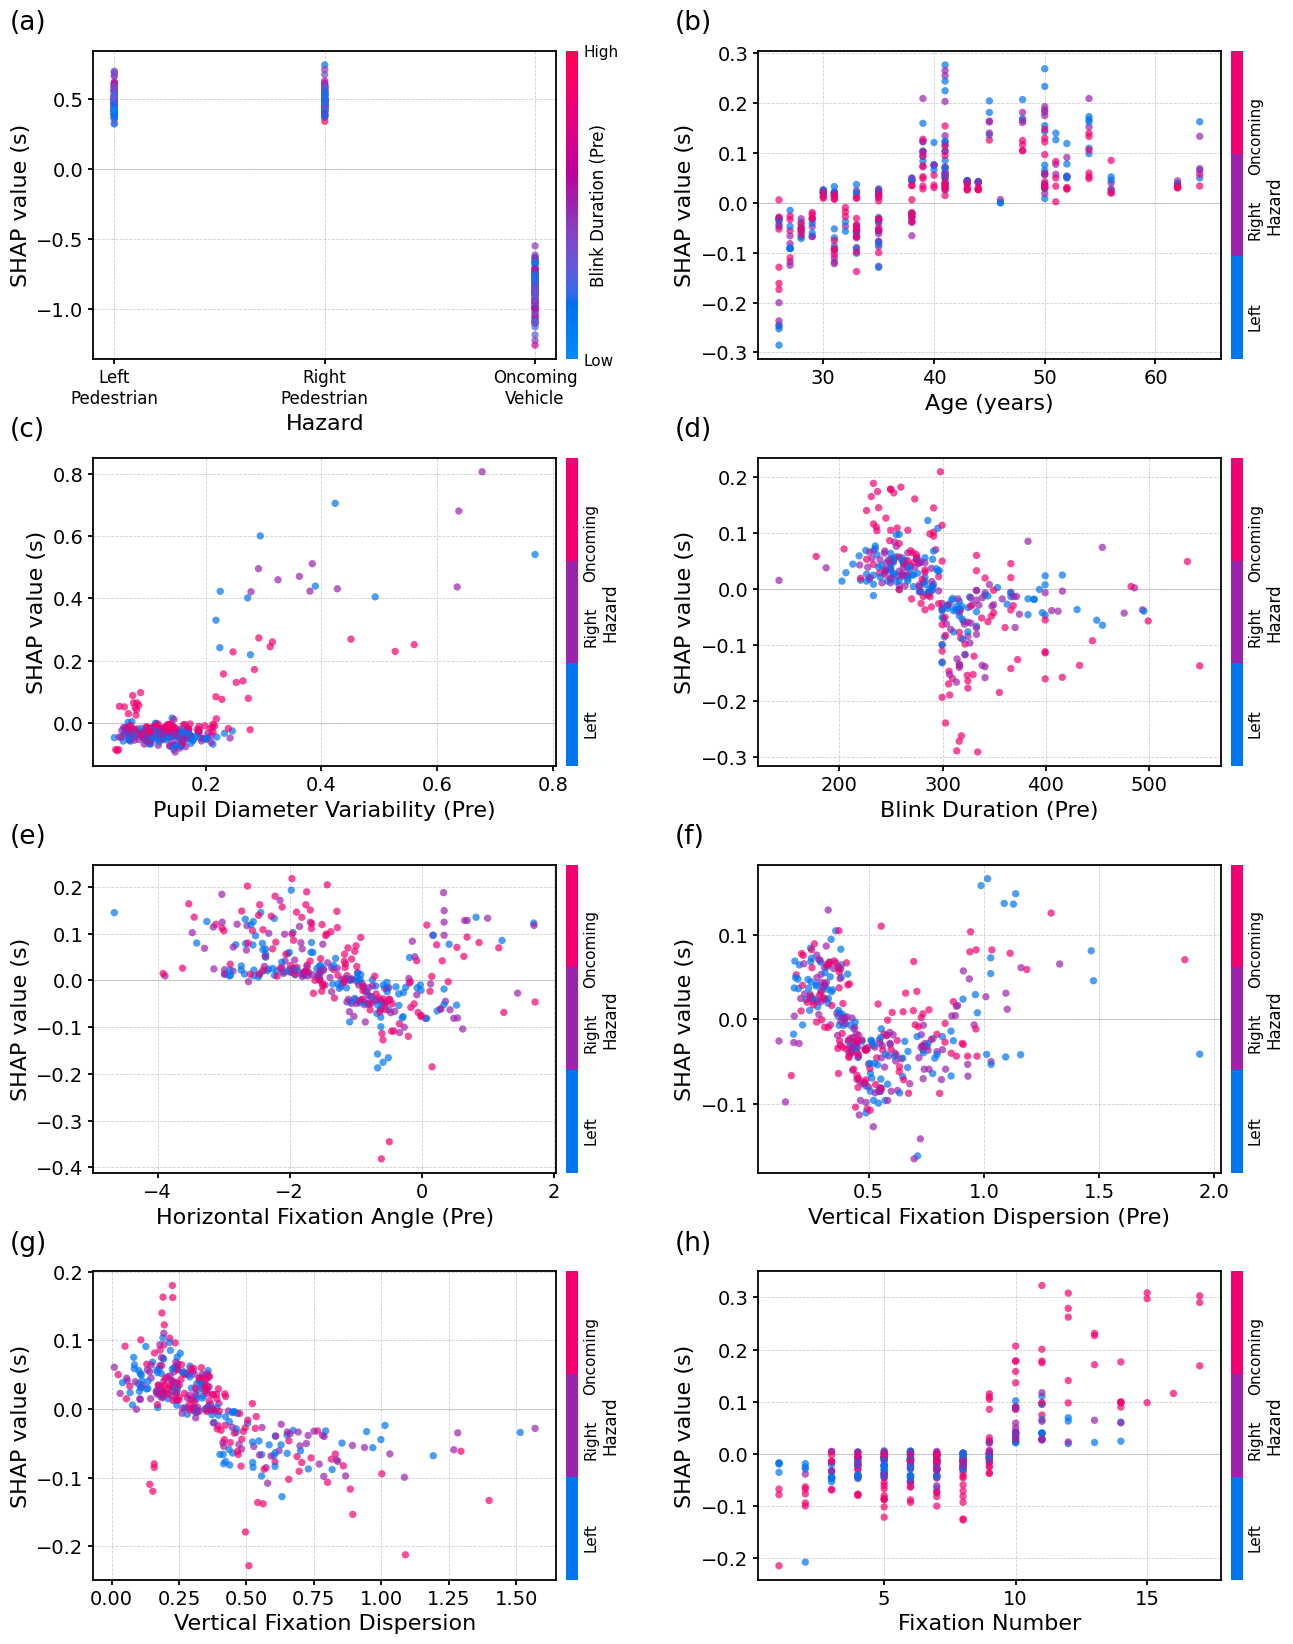

In [ ]:
"""
SHAP dependence plots for XGBoost (combineTW) regression — 2-column layout.

Reuses shap_all, X_color_all, shap_interaction_all from the regression
refit pipeline. No refitting needed.
"""

import re
import string
import matplotlib as mpl
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap


# =========================================================
# Name mapping
# =========================================================
name_map = {
    "Age": "Age",
    "License": "Driving Experience",
    "Mileage": "Annual Mileage",
    "Gender": "Gender",
    "automation": "Automation",
    "eventType": "Hazard",
    "visibleSpeed": "Speed",
    "pdMean": "Pupil Diameter",
    "pdSd": "Pupil Diameter Variability",
    "blinkNumber": "Blink Number",
    "avgBlinkDuration": "Blink Duration",
    "fixNumber": "Fixation Number",
    "avgFixDuration": "Fixation Duration",
    "fixTE": "Transition Entropy",
    "fixSE": "Stationary Entropy",
    "FixDisperX": "Horizontal Fixation Dispersion",
    "FixDisperY": "Vertical Fixation Dispersion",
    "FixDisperE": "Euclidean Fixation Dispersion",
    "FixMeanPosX": "Horizontal Fixation Angle",
    "FixMeanPosY": "Vertical Fixation Angle",
}

# =========================================================
# Unit lookup for x-axis labels
# =========================================================
UNIT_MAP = {
    "FixMx": "degrees",
    "FixMy": "degrees",
    "VisibleSpeed": "m/s",
    "PupilMean": "mm",
    "PupilStd": "mm",
    "Age": "years",
}


def add_unit(clean_name):
    """Append a unit to a cleaned feature label, if one is defined.
    Handles the '(Pre)' suffix by matching on the base part."""
    base = clean_name.replace(" (Pre)", "").strip()
    unit = UNIT_MAP.get(base)
    if unit is None:
        return clean_name
    return f"{clean_name} ({unit})"


def clean_feature_name(name):
    if "_" in name:
        prefix, val = name.split("_", 1)
        if prefix in ["Gender", "automation", "eventType"]:
            if prefix == "automation":
                val = {"1": "MD", "2": "PAD"}.get(val, val)
            elif prefix == "Gender":
                val = {"M": "Male", "F": "Female"}.get(val, val)
            elif prefix == "eventType":
                val = {
                    "EVENT_MAT_LEFT_VRU": "Left Pedestrian",
                    "EVENT_MAT_RIGHT_VRU": "Right Pedestrian",
                    "EVENT_MAT_ONCOMING": "Oncoming Vehicle",
                }.get(val, val)
            return f"{name_map.get(prefix, prefix)} {val}"
    m = re.match(r"(.+?)_(\d+)$", name)
    if m:
        base, tw = m.groups()
        tw = int(tw)
        return name_map.get(base, base) if tw == 0 else f"{name_map.get(base, base)} (Pre)"
    return name_map.get(name, name)


# =========================================================
# Settings
# =========================================================
N_FEATURES = 8
COLS_PER_ROW = 2
EXCLUDE_BASES = ["FixMeanPosX_0", "visibleSpeed"]

PUPIL_SCALE_FEATURES_BASE = ["pdMean", "pdSd"]
PUPIL_SCALE_FACTOR = 1000

DOT_SIZE = 28
DOT_ALPHA = 0.7

FONT_AXIS_LABEL = 16
FONT_TICK = 14
FONT_SUBTITLE = 12
FONT_CBAR_LABEL = 12
FONT_CBAR_TICK = 11

PANEL_W = 6.5
PANEL_H = 4.2

SPINE_WIDTH = 1.3
SHAP_CMAP = shap.plots.colors.red_blue

PANEL_LABEL_FONTSIZE = 19

# Regression: SHAP values are in seconds of reaction time
Y_LABEL = "SHAP value (s)"


def is_excluded(raw_name):
    return any(raw_name.startswith(excl) for excl in EXCLUDE_BASES)


def needs_pupil_scaling(raw_name):
    return any(raw_name.startswith(base) for base in PUPIL_SCALE_FEATURES_BASE)


# =========================================================
# Pick top-N features
# =========================================================
mean_abs_shap = shap_all.abs().mean().sort_values(ascending=False)
all_top = mean_abs_shap.index.tolist()
top_features = [f for f in all_top if not is_excluded(f)][:N_FEATURES]

print(f"Top {N_FEATURES} features for dependence plots (after exclusion):")
for i, f in enumerate(top_features, 1):
    marker = " [x1000 for display]" if needs_pupil_scaling(f) else ""
    print(f"  {i}. {f} -> {clean_feature_name(f)}{marker}")


# =========================================================
# Compute partner features from SHAP interaction values
# =========================================================
feature_names = shap_all.columns.tolist()
n_feats = len(feature_names)

interaction_array = shap_interaction_all.values.reshape(-1, n_feats, n_feats)
mean_abs_inter = np.abs(interaction_array).mean(axis=0)
np.fill_diagonal(mean_abs_inter, -np.inf)

inter_partner = {
    feature_names[i]: feature_names[np.argmax(mean_abs_inter[i])]
    for i in range(n_feats)
}

print("\nSHAP interaction-based partner selection:")
for feat in feature_names:
    partner = inter_partner[feat]
    strength = mean_abs_inter[feature_names.index(feat),
                              feature_names.index(partner)]
    print(f"  {feat:30s} -> {partner:30s}  (mean |phi| = {strength:.4f})")


# =========================================================
# Plot
# =========================================================
n_features = len(top_features)
n_rows = int(np.ceil(n_features / COLS_PER_ROW))

fig, axes = plt.subplots(
    n_rows, COLS_PER_ROW,
    figsize=(COLS_PER_ROW * PANEL_W, n_rows * PANEL_H),
    sharey=False,
)
axes = axes.flatten() if n_features > 1 else [axes]


for i, feat in enumerate(top_features):
    ax = axes[i]

    x_vals = X_color_all[feat].values.astype(float).copy()
    if needs_pupil_scaling(feat):
        x_vals = x_vals * PUPIL_SCALE_FACTOR

    shap_vals = shap_all[feat].values

    interact_feat = inter_partner[feat]
    color_vals = X_color_all[interact_feat].values.astype(float).copy()

    PARTNER_IS_CATEGORICAL = (interact_feat == "eventType")

    if PARTNER_IS_CATEGORICAL:
        norm_color = color_vals  # already 0/1/2

        cat_colors = [
            SHAP_CMAP(0.15),
            SHAP_CMAP(0.50),
            SHAP_CMAP(0.85),
        ]
        cat_cmap = mpl.colors.ListedColormap(cat_colors)
        cat_norm = mpl.colors.BoundaryNorm(
            boundaries=[-0.5, 0.5, 1.5, 2.5], ncolors=3,
        )

        valid_mask = (~np.isnan(x_vals) & ~np.isnan(shap_vals)
                      & ~np.isnan(norm_color))

        sc = ax.scatter(
            x_vals[valid_mask], shap_vals[valid_mask],
            c=norm_color[valid_mask],
            cmap=cat_cmap, norm=cat_norm,
            s=DOT_SIZE, alpha=DOT_ALPHA, linewidths=0,
        )
    else:
        if (~np.isnan(color_vals)).sum() > 0:
            lo = np.nanpercentile(color_vals, 1)
            hi = np.nanpercentile(color_vals, 99)
            if hi > lo:
                norm_color = np.clip((color_vals - lo) / (hi - lo), 0, 1)
            else:
                norm_color = np.full_like(color_vals, 0.5, dtype=float)
        else:
            norm_color = np.full_like(color_vals, 0.5, dtype=float)

        valid_mask = ~np.isnan(x_vals) & ~np.isnan(shap_vals)

        sc = ax.scatter(
            x_vals[valid_mask], shap_vals[valid_mask],
            c=norm_color[valid_mask],
            cmap=SHAP_CMAP,
            s=DOT_SIZE, alpha=DOT_ALPHA, linewidths=0,
        )

    ax.axhline(0, color="lightgray", linewidth=0.8, zorder=0)
    ax.grid(True, linestyle="--", linewidth=0.6, alpha=0.6, zorder=0)
    ax.set_axisbelow(True)

    feat_clean = clean_feature_name(feat)
    interact_clean = clean_feature_name(interact_feat)

    ax.set_xlabel(add_unit(feat_clean), fontsize=FONT_AXIS_LABEL)
    ax.set_ylabel(Y_LABEL, fontsize=FONT_AXIS_LABEL)
    ax.tick_params(axis="both", labelsize=FONT_TICK)

    unique_vals = np.unique(x_vals[~np.isnan(x_vals)])
    if len(unique_vals) <= 5:
        ax.set_xticks(unique_vals)
        if feat == "eventType":
            hazard_label_map = {
                0: "Left\nPedestrian",
                1: "Right\nPedestrian",
                2: "Oncoming\nVehicle",
            }
            new_labels = [hazard_label_map.get(int(v), str(int(v)))
                          for v in unique_vals]
            ax.set_xticklabels(new_labels, fontsize=FONT_TICK - 2)

    # Per-panel colourbar
    if PARTNER_IS_CATEGORICAL:
        sm = plt.cm.ScalarMappable(cmap=cat_cmap, norm=cat_norm)
        sm.set_array([])
        cbar = fig.colorbar(sm, ax=ax, pad=0.02, fraction=0.04, aspect=25,
                            ticks=[0, 1, 2], drawedges=False)
        cbar.set_ticklabels(["Left", "Right", "Oncoming"],
                            fontsize=FONT_CBAR_TICK, rotation=90)
        cbar.set_label(interact_clean, fontsize=FONT_CBAR_LABEL, labelpad=2)
        cbar.dividers.set_visible(False)
        cbar.ax.tick_params(axis="y", which="both", length=0, width=0,
                            left=False, right=False)
    else:
        sm = plt.cm.ScalarMappable(cmap=SHAP_CMAP, norm=plt.Normalize(0, 1))
        sm.set_array([])
        cbar = fig.colorbar(sm, ax=ax, pad=0.02, fraction=0.04, aspect=25)
        cbar.set_label(interact_clean, fontsize=FONT_CBAR_LABEL, labelpad=-20)
        cbar.set_ticks([0, 1])
        cbar.set_ticklabels(["Low", "High"])

    cbar.outline.set_visible(False)
    cbar.ax.tick_params(length=0, labelsize=FONT_CBAR_TICK)


# Hide unused subplots
for j in range(n_features, len(axes)):
    axes[j].set_visible(False)

# =========================================================
# Panel labels (A, B, C, ...) in upper-left corner
# =========================================================
for idx in range(n_features):
    ax = axes[idx]
    ax.text(
        -0.18, 1.05, f"({string.ascii_lowercase[idx]})",
        transform=ax.transAxes,
        ha="left", va="bottom",
        fontsize=PANEL_LABEL_FONTSIZE,
        # fontweight="bold",
    )

# =========================================================
# Shared y-axis range — full data range, with margin
# =========================================================
# all_shap_vals = np.concatenate([
#     shap_all[feat].values for feat in top_features
# ])
# all_shap_vals = all_shap_vals[~np.isnan(all_shap_vals)]

# y_min = all_shap_vals.min()
# y_max = all_shap_vals.max()

# pad = 0.08 * (y_max - y_min)
# y_lo = y_min - pad
# y_hi = y_max + pad

# for idx in range(n_features):
#     axes[idx].set_ylim(y_lo, y_hi)

# print(f"SHAP range: [{y_min:.3f}, {y_max:.3f}] -> ylim [{y_lo:.3f}, {y_hi:.3f}]")

# =========================================================
# Layout
# =========================================================
plt.subplots_adjust(
    left=0.07, right=0.96, top=0.97, bottom=0.06,
    hspace=0.32, wspace=0.35,
)

# =========================================================
# Spines and ticks
# =========================================================
for ax in axes:
    if not ax.get_visible():
        continue
    for spine in ax.spines.values():
        if spine.get_visible():
            spine.set_linewidth(SPINE_WIDTH)
            spine.set_edgecolor("black")
    ax.tick_params(axis="x", width=SPINE_WIDTH)
    ax.tick_params(axis="y", width=SPINE_WIDTH)

plt.show()

## Cross-Seed Plot

Final N = 351
[LASSO] seed=261
[LASSO] seed=452
[LASSO] seed=285
[LASSO] seed=966
[LASSO] seed=786
[LASSO] seed=1423
[LASSO] seed=3789
[LASSO] seed=5602
[LASSO] seed=8741
[LASSO] seed=11905
[XGB] seed=261
[XGB] seed=452
[XGB] seed=285
[XGB] seed=966
[XGB] seed=786
[XGB] seed=1423
[XGB] seed=3789
[XGB] seed=5602
[XGB] seed=8741
[XGB] seed=11905

REFIT-vs-RECORDED VERIFICATION (REGRESSION, RMSE)

[LASSO (panels a,b)] folds checked: 50
  fold-membership (n_test) mismatches: 0
  RMSE mismatches (|dRMSE| >= 0.001): 0   | max |dRMSE| = 0.00000
  >>> PASS: refit reproduces recorded models. LASSO (panels a,b) panels use correct models.

[XGB (panel c)] folds checked: 50
  fold-membership (n_test) mismatches: 0
  RMSE mismatches (|dRMSE| >= 0.001): 0   | max |dRMSE| = 0.00000
  >>> PASS: refit reproduces recorded models. XGB (panel c) panels use correct models.

coef_per_seed: (293, 3) | retain_per_seed: (370, 3) | shap_per_seed: (330, 3)

Cached frames saved to /content/drive/MyDrive/Colab_Bac

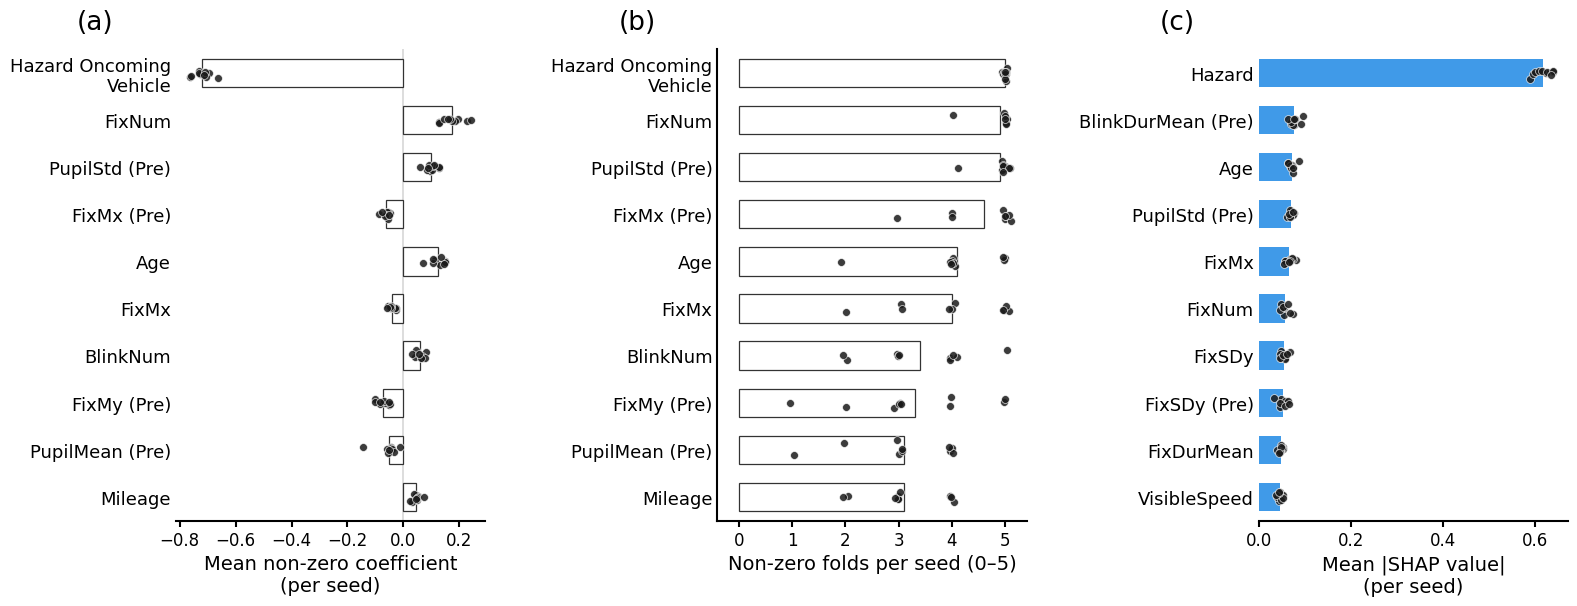

In [ ]:
# =====================================================================
# CROSS-SEED INTERPRETATION FIGURE (REGRESSION)  +  REFIT-vs-RECORDED CHECK
#   self-contained: every helper defined here.
#
#   (a) LASSO combine-TW (TW=0,20): per-seed mean non-zero coefficient,
#                                   distribution across seeds
#   (b) LASSO combine-TW (TW=0,20): per-seed retention count (0..5),
#                                   distribution across seeds
#   (c) XGB   combine-TW (TW=0,21): per-seed mean|SHAP|,
#                                   distribution across seeds
#
#   Verification: per seed x fold, refit RMSE vs recorded RMSE.
#   Uses GroupKFold (regression), Lasso, XGBRegressor.
# =====================================================================

import json
import os
import glob
import re
import textwrap
from functools import lru_cache

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec

from sklearn.model_selection import GroupKFold
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Lasso
from sklearn.metrics import mean_squared_error
from xgboost import XGBRegressor, DMatrix


# =====================================================================
# 0. CONFIG  — edit paths here
# =====================================================================
data_path = "/content/drive/MyDrive/Colab_Backups/Data_3sMean_IDT_beforeMat.xlsx"

# LASSO combine-TW (panels a, b)
LASSO_BASE_DIR     = "/content/drive/MyDrive/Colab_Backups/LRR"
LASSO_MODEL_DIR    = "LR_model_combineTW"
LASSO_RESULTS_PATH = "/content/drive/MyDrive/Colab_Backups/LRR/LRR_combineTW.xlsx"
LASSO_TWS          = [0, 20]
LASSO_TARGET_TW    = 20

# XGB combine-TW (panel c)
XGB_BASE_DIR     = "/content/drive/MyDrive/Colab_Backups/XGBR"
XGB_MODEL_DIR    = "XGB_model_combineTW"
XGB_RESULTS_PATH = "/content/drive/MyDrive/Colab_Backups/XGBR/XGBR_combineTW.xlsx"
XGB_TWS          = [0, 21]
XGB_TARGET_TW    = 21

SELECTED_SEEDS = [
    261, 452, 285, 966, 786,
    1423, 3789, 5602, 8741, 11905,
]

OUTER_SPLITS = 5
TARGET_COL   = "relativeRT"
CAT_NAMES    = ["Gender", "automation", "eventType"]
ZERO_TOL     = 1e-8
TOP_N        = 10
RMSE_TOL     = 1e-3          # |refit RMSE - recorded RMSE| below this counts as a match

CACHE_DIR    = "/content/drive/MyDrive/Colab_Backups/crossseed_cache_reg"
SAVE_CACHE   = True
USE_CACHE    = True          # if cache exists, load it and SKIP refit + verification


# =====================================================================
# 1. HELPERS
# =====================================================================
NAME_MAP = {
    "Age": "Age", "License": "DrivingExperience", "Mileage": "Mileage",
    "Gender": "Gender", "automation": "Automation", "eventType": "Hazard",
    "visibleSpeed": "VisibleSpeed",
    "pdMean": "PupilMean", "pdSd": "PupilStd",
    "blinkNumber": "BlinkNum", "avgBlinkDuration": "BlinkDurMean",
    "fixNumber": "FixNum", "avgFixDuration": "FixDurMean",
    "fixTE": "FixTEntropy", "fixSE": "FixSEntropy",
    "FixDisperX": "FixSDx", "FixDisperY": "FixSDy", "FixDisperE": "FixSDe",
    "FixMeanPosX": "FixMx", "FixMeanPosY": "FixMy",
}


def build_feature_cols(tws):
    templates = [
        "Age", "License", "Mileage",
        "Gender", "automation", "eventType",
        "visibleSpeed",
        "pdMean_{TW}", "pdSd_{TW}",
        "blinkNumber_{TW}", "avgBlinkDuration_{TW}",
        "fixNumber_{TW}", "avgFixDuration_{TW}",
        "fixTE_{TW}", "fixSE_{TW}",
        "FixDisperX_{TW}", "FixDisperY_{TW}", "FixDisperE_{TW}",
        "FixMeanPosX_{TW}", "FixMeanPosY_{TW}",
    ]
    cols = []
    for c in templates:
        if "{TW}" in c:
            cols.extend([c.format(TW=tw) for tw in tws])
        else:
            cols.append(c)
    return cols


def clean_feature_name(name):
    if "_" in name:
        prefix, val = name.split("_", 1)
        if prefix in ["Gender", "automation", "eventType"]:
            if prefix == "automation":
                val = {"1": "MD", "2": "PAD"}.get(val, val)
            elif prefix == "Gender":
                val = {"M": "Male", "F": "Female"}.get(val, val)
            elif prefix == "eventType":
                val = {
                    "EVENT_MAT_LEFT_VRU": "Left Pedestrian",
                    "EVENT_MAT_RIGHT_VRU": "Right Pedestrian",
                    "EVENT_MAT_ONCOMING": "Oncoming Vehicle",
                }.get(val, val)
            return f"{NAME_MAP.get(prefix, prefix)} {val}"
    m = re.match(r"(.+?)_(\d+)$", name)
    if m:
        base, tw = m.groups()
        base_clean = NAME_MAP.get(base, base)
        return base_clean if int(tw) == 0 else f"{base_clean} (Pre)"
    return NAME_MAP.get(name, name)


def wrap_labels(label, width=20):
    return "\n".join(textwrap.wrap(label, width))


def fit_outer_onehot(X_train_raw, X_test_raw, cat_cols):
    X_train_raw = X_train_raw.copy()
    X_test_raw = X_test_raw.copy()
    use_cat = [c for c in cat_cols if c in X_train_raw.columns]
    for c in use_cat:
        cats = pd.Index(X_train_raw[c].dropna().unique())
        dtype = pd.CategoricalDtype(categories=cats, ordered=False)
        X_train_raw[c] = X_train_raw[c].astype(dtype)
        X_test_raw[c] = X_test_raw[c].astype(dtype)
    X_tr = pd.get_dummies(X_train_raw, columns=use_cat, drop_first=False)
    X_te = pd.get_dummies(X_test_raw, columns=use_cat, drop_first=False)
    X_te = X_te.reindex(columns=X_tr.columns, fill_value=0)
    return X_tr.astype(np.float32), X_te.astype(np.float32)


def ensure_categorical_dtype_from_train(train_df, test_df, cat_cols):
    train_df = train_df.copy()
    test_df = test_df.copy()
    for col in cat_cols:
        if col in train_df.columns:
            cats = pd.Index(train_df[col].dropna().unique())
            dtype = pd.CategoricalDtype(categories=cats, ordered=False)
            train_df[col] = train_df[col].astype(dtype)
            test_df[col] = test_df[col].astype(dtype)
    return train_df, test_df


def make_groupkfold(n_splits, seed):
    """GroupKFold with shuffle/random_state if the installed sklearn supports it."""
    try:
        return GroupKFold(n_splits=n_splits, shuffle=True, random_state=seed)
    except TypeError:
        return GroupKFold(n_splits=n_splits)


def _load_meta(base_dir, model_dir, prefix, seed, tw, outer_fold):
    folder = os.path.join(base_dir, model_dir)
    patterns = [
        f"{prefix}_seed_{seed:02d}_*TW_{tw:02d}_outerfold_{outer_fold:02d}_meta.json",
        f"{prefix}_seed_{seed:02d}_TW_{tw:02d}_outerfold_{outer_fold:02d}_meta.json",
    ]
    candidates = []
    for p in patterns:
        candidates = glob.glob(os.path.join(folder, p))
        if candidates:
            break
    if not candidates:
        raise FileNotFoundError(
            f"No {prefix} metadata for seed={seed}, TW={tw}, fold={outer_fold} in {folder}"
        )
    path = sorted(candidates, key=len)[0]
    with open(path, "r", encoding="utf-8") as f:
        meta = json.load(f)
    return meta, path


def get_xgb_shap_values(model, X_proc):
    dm = DMatrix(X_proc, enable_categorical=True)
    contribs = model.get_booster().predict(dm, pred_contribs=True)
    return contribs[:, :-1], contribs[:, -1]


@lru_cache(maxsize=None)
def _load_results(path):
    res = pd.read_excel(path)
    res["outer_fold"] = res["outer_fold"].astype(str)
    res["TW"]   = pd.to_numeric(res["TW"], errors="coerce")
    res["seed"] = pd.to_numeric(res["seed"], errors="coerce")
    if "RMSE" in res.columns:
        res["RMSE"] = pd.to_numeric(res["RMSE"], errors="coerce")
    return res


def recorded_row(path, seed, tw, outer_fold):
    res = _load_results(path)
    r = res[(res["seed"] == seed) & (res["TW"] == tw) &
            (res["outer_fold"] == str(outer_fold))]
    return None if r.empty else r.iloc[0]


def find_best_seed_reg(path, tw, seeds):
    """Best seed = lowest SUMMARY RMSE at the target TW."""
    res = _load_results(path)
    sub = res[(res["outer_fold"] == "SUMMARY") & (res["TW"] == tw) &
              (res["seed"].isin(seeds))]
    if sub.empty:
        raise ValueError(f"No SUMMARY rows for TW={tw} in {path}")
    return int(sub.loc[sub["RMSE"].idxmin(), "seed"])


# =====================================================================
# 2. LOAD + FILTER DATA  (regression: no class label, keep continuous target)
# =====================================================================
df = pd.read_excel(data_path)

allowed_events = {"EVENT_MAT_RIGHT_VRU", "EVENT_MAT_LEFT_VRU", "EVENT_MAT_ONCOMING"}
unexpected = set(df["eventType"].dropna().unique()) - allowed_events
if unexpected:
    raise ValueError(f"Unexpected eventType(s): {unexpected}")

df[TARGET_COL] = pd.to_numeric(df[TARGET_COL], errors="coerce")
df = df.dropna(subset=[TARGET_COL, "eventType", "subNumber"]).copy()

tww_cols = [f"perValid_{i}" for i in range(31)]
df = df[df[tww_cols].mean(axis=1) >= 74.5].copy()

y = df[TARGET_COL].values.astype(float)
groups = df["subNumber"].values

print(f"Final N = {len(df)}")


# =====================================================================
# 2b. CACHE PROBE — if cached frames exist and USE_CACHE, load & skip refit
# =====================================================================
_CACHE_FILES = {
    "coef":   os.path.join(CACHE_DIR, "coef_per_seed.parquet"),
    "retain": os.path.join(CACHE_DIR, "retain_per_seed.parquet"),
    "shap":   os.path.join(CACHE_DIR, "shap_per_seed.parquet"),
}
_CACHE_HIT = USE_CACHE and all(os.path.exists(f) for f in _CACHE_FILES.values())

if _CACHE_HIT:
    coef_per_seed   = pd.read_parquet(_CACHE_FILES["coef"])
    retain_per_seed = pd.read_parquet(_CACHE_FILES["retain"])
    shap_per_seed   = pd.read_parquet(_CACHE_FILES["shap"])
    print("\n[cache] Loaded coef/retain/shap from", CACHE_DIR,
          "-> skipping refit + verification.")


if not _CACHE_HIT:
    # =================================================================
    # 3. LASSO loop -> coef_per_seed, retain_per_seed  (+ inline RMSE check)
    # =================================================================
    X_lasso = df[build_feature_cols(LASSO_TWS)].copy()
    coef_records = []
    lasso_check = []

    for seed in SELECTED_SEEDS:
        print(f"[LASSO] seed={seed}")
        cv = make_groupkfold(OUTER_SPLITS, seed)
        for outer_fold, (tr, te) in enumerate(cv.split(X_lasso, y, groups), start=1):
            X_tr, X_te = X_lasso.iloc[tr].copy(), X_lasso.iloc[te].copy()
            y_tr, y_te = y[tr], y[te]

            meta, _ = _load_meta(LASSO_BASE_DIR, LASSO_MODEL_DIR, "lr",
                                 seed, LASSO_TARGET_TW, outer_fold)
            best_params = meta["best_params"]

            X_tr_oh, X_te_oh = fit_outer_onehot(X_tr, X_te, CAT_NAMES)

            imp = SimpleImputer(strategy="median")
            X_tr_oh = pd.DataFrame(imp.fit_transform(X_tr_oh),
                                   columns=X_tr_oh.columns, index=X_tr_oh.index)
            X_te_oh = pd.DataFrame(imp.transform(X_te_oh),
                                   columns=X_te_oh.columns, index=X_te_oh.index)
            sc = StandardScaler()
            X_tr_oh = pd.DataFrame(sc.fit_transform(X_tr_oh),
                                   columns=X_tr_oh.columns, index=X_tr_oh.index)
            X_te_oh = pd.DataFrame(sc.transform(X_te_oh),
                                   columns=X_te_oh.columns, index=X_te_oh.index)

            model = Lasso(**best_params)
            model.fit(X_tr_oh, y_tr)

            for feat, c in zip(X_tr_oh.columns, np.asarray(model.coef_).ravel()):
                coef_records.append({
                    "seed": seed, "outer_fold": outer_fold, "feature": feat,
                    "coef": c, "selected": abs(c) > ZERO_TOL,
                })

            refit_rmse = float(np.sqrt(mean_squared_error(y_te, model.predict(X_te_oh))))
            rec = recorded_row(LASSO_RESULTS_PATH, seed, LASSO_TARGET_TW, outer_fold)
            lasso_check.append({
                "seed": seed, "fold": outer_fold,
                "refit_RMSE": refit_rmse,
                "rec_RMSE": float(rec["RMSE"]) if rec is not None and "RMSE" in rec else np.nan,
                "rec_n": int(rec["n_test"]) if rec is not None and "n_test" in rec else -1,
                "refit_n": len(te),
            })

    coef_long = pd.DataFrame(coef_records)
    coef_per_seed = (
        coef_long[coef_long["selected"]]
        .groupby(["seed", "feature"], as_index=False)
        .agg(mean_coef_when_retained=("coef", "mean"))
    )
    retain_per_seed = (
        coef_long.groupby(["seed", "feature"], as_index=False)
        .agg(retained_count=("selected", "sum"))
    )

    # =================================================================
    # 4. XGB loop -> shap_per_seed  (+ inline RMSE check)
    # =================================================================
    X_xgb = df[build_feature_cols(XGB_TWS)].copy()
    shap_records = []
    xgb_check = []

    for seed in SELECTED_SEEDS:
        print(f"[XGB] seed={seed}")
        cv = make_groupkfold(OUTER_SPLITS, seed)
        seed_abs_shap = []
        for outer_fold, (tr, te) in enumerate(cv.split(X_xgb, y, groups), start=1):
            X_tr, X_te = X_xgb.iloc[tr].copy(), X_xgb.iloc[te].copy()
            y_tr, y_te = y[tr], y[te]

            meta, _ = _load_meta(XGB_BASE_DIR, XGB_MODEL_DIR, "xgb",
                                 seed, XGB_TARGET_TW, outer_fold)
            best_params = meta["best_params"]

            sel_feats = meta.get("selected_features", None)
            if sel_feats is not None:
                sel_feats = [c for c in sel_feats if c in X_tr.columns]
                X_tr, X_te = X_tr[sel_feats].copy(), X_te[sel_feats].copy()

            X_tr_proc, X_te_proc = ensure_categorical_dtype_from_train(X_tr, X_te, CAT_NAMES)

            model = XGBRegressor(**best_params)
            model.fit(X_tr_proc, y_tr, verbose=False)

            shap_values, _ = get_xgb_shap_values(model, X_te_proc)
            seed_abs_shap.append(pd.DataFrame(
                np.abs(shap_values), columns=X_te_proc.columns, index=X_te_proc.index
            ))

            refit_rmse = float(np.sqrt(mean_squared_error(y_te, model.predict(X_te_proc))))
            rec = recorded_row(XGB_RESULTS_PATH, seed, XGB_TARGET_TW, outer_fold)
            xgb_check.append({
                "seed": seed, "fold": outer_fold,
                "refit_RMSE": refit_rmse,
                "rec_RMSE": float(rec["RMSE"]) if rec is not None and "RMSE" in rec else np.nan,
                "rec_n": int(rec["n_test"]) if rec is not None and "n_test" in rec else -1,
                "refit_n": len(te),
            })

        seed_abs_all = pd.concat(seed_abs_shap, axis=0)
        mean_abs = seed_abs_all.mean(axis=0)
        for feat, v in mean_abs.items():
            shap_records.append({"seed": seed, "feature": feat, "mean_abs_shap": v})

    shap_per_seed = pd.DataFrame(shap_records)

    # =================================================================
    # 4b. VERIFICATION VERDICT (RMSE)
    # =================================================================
    def _report(name, recs):
        chk = pd.DataFrame(recs)
        chk["dRMSE"] = (chk["refit_RMSE"] - chk["rec_RMSE"]).abs()
        chk["size_OK"] = (chk["rec_n"] == chk["refit_n"])
        chk["RMSE_OK"] = chk["dRMSE"] < RMSE_TOL
        n_size_bad = (~chk["size_OK"]).sum()
        n_rmse_bad = (~chk["RMSE_OK"]).sum()
        print(f"\n[{name}] folds checked: {len(chk)}")
        print(f"  fold-membership (n_test) mismatches: {n_size_bad}")
        print(f"  RMSE mismatches (|dRMSE| >= {RMSE_TOL}): {n_rmse_bad}"
              f"   | max |dRMSE| = {chk['dRMSE'].max():.5f}")
        if n_size_bad == 0 and n_rmse_bad == 0:
            print(f"  >>> PASS: refit reproduces recorded models. {name} panels use correct models.")
        else:
            print(f"  >>> MISMATCH — offending folds:")
            print(chk[(~chk['size_OK']) | (~chk['RMSE_OK'])].to_string(index=False))
        return chk

    print("\n" + "=" * 70)
    print("REFIT-vs-RECORDED VERIFICATION (REGRESSION, RMSE)")
    print("=" * 70)
    lasso_chk = _report("LASSO (panels a,b)", lasso_check)
    xgb_chk   = _report("XGB (panel c)",      xgb_check)

    print("\ncoef_per_seed:", coef_per_seed.shape,
          "| retain_per_seed:", retain_per_seed.shape,
          "| shap_per_seed:", shap_per_seed.shape)

    # =================================================================
    # 4c. OPTIONAL CACHE
    # =================================================================
    if SAVE_CACHE:
        try:
            os.makedirs(CACHE_DIR, exist_ok=True)
            coef_per_seed.to_parquet(_CACHE_FILES["coef"])
            retain_per_seed.to_parquet(_CACHE_FILES["retain"])
            shap_per_seed.to_parquet(_CACHE_FILES["shap"])
            print(f"\nCached frames saved to {CACHE_DIR}")
        except Exception as e:
            print(f"\n[warn] cache save skipped: {e}")


# =====================================================================
# 5. ORDER FEATURES
# =====================================================================
ret_mean = retain_per_seed.groupby("feature")["retained_count"].mean().rename("ret_mean")
coef_absmean = (
    coef_per_seed.assign(abs_c=coef_per_seed["mean_coef_when_retained"].abs())
    .groupby("feature")["abs_c"].mean().rename("coef_absmean")
)
lasso_rank = pd.concat([ret_mean, coef_absmean], axis=1).fillna(0.0)
lasso_rank = lasso_rank.sort_values(["ret_mean", "coef_absmean"], ascending=[False, False])
lasso_features_plot = lasso_rank.head(TOP_N).index.tolist()[::-1]
lasso_labels = [clean_feature_name(f) for f in lasso_features_plot]
n_lasso = len(lasso_features_plot)

shap_rank = shap_per_seed.groupby("feature")["mean_abs_shap"].mean().sort_values(ascending=False)
shap_features_plot = shap_rank.head(TOP_N).index.tolist()[::-1]
shap_labels = [clean_feature_name(f) for f in shap_features_plot]
n_shap = len(shap_features_plot)


# =====================================================================
# 6. PLOT — three panels in one row
# =====================================================================
DOT_COLOR, DOT_SIZE, DOT_ALPHA = "#1A1A1A", 32, 0.85
BAR_FACE, BAR_EDGE, BAR_EDGEW = "white", "#333333", 0.9
SHAP_BAR_FACE = "#1E88E5"
BAR_HEIGHT = 0.6
FS_XLAB, FS_XTICK, FS_Y = 14, 12, 13
PANEL_FS, SPINE_W = 19, 1.5
N_SEEDS = len(SELECTED_SEEDS)
rng = np.random.default_rng(42)

fig = plt.figure(figsize=(16, 6.2))
gs = GridSpec(1, 3, figure=fig, width_ratios=[1, 1, 1], wspace=0.75)
ax_coef = fig.add_subplot(gs[0, 0])
ax_ret  = fig.add_subplot(gs[0, 1])
ax_shap = fig.add_subplot(gs[0, 2])

# (a) coefficient distribution
for i, feat in enumerate(lasso_features_plot):
    vals = coef_per_seed.loc[coef_per_seed["feature"] == feat,
                             "mean_coef_when_retained"].dropna().values
    if len(vals) == 0:
        continue
    ax_coef.barh(i, np.mean(vals), color=BAR_FACE, edgecolor=BAR_EDGE,
                 linewidth=BAR_EDGEW, height=BAR_HEIGHT, zorder=2)
    ax_coef.scatter(vals, rng.normal(i, 0.06, size=len(vals)),
                    color=DOT_COLOR, s=DOT_SIZE, alpha=DOT_ALPHA,
                    edgecolor="white", linewidth=0.5, zorder=5)
ax_coef.axvline(0, color="lightgray", linewidth=1.1, zorder=0)
ax_coef.set_yticks(range(n_lasso))
ax_coef.set_yticklabels([wrap_labels(l) for l in lasso_labels], fontsize=FS_Y)
ax_coef.set_xlabel("Mean non-zero coefficient\n(per seed)", fontsize=FS_XLAB)
ax_coef.set_ylim(-0.5, n_lasso - 0.5)

# (b) retention-count distribution
for i, feat in enumerate(lasso_features_plot):
    vals = retain_per_seed.loc[retain_per_seed["feature"] == feat,
                               "retained_count"].values.astype(float)
    if len(vals) == 0:
        vals = np.zeros(N_SEEDS)
    ax_ret.barh(i, np.mean(vals), color=BAR_FACE, edgecolor=BAR_EDGE,
                linewidth=BAR_EDGEW, height=BAR_HEIGHT, zorder=2)
    xj = vals + rng.normal(0, 0.04, size=len(vals))
    ax_ret.scatter(xj, rng.normal(i, 0.07, size=len(vals)),
                   color=DOT_COLOR, s=DOT_SIZE, alpha=DOT_ALPHA,
                   edgecolor="white", linewidth=0.5, zorder=5)
ax_ret.set_yticks(range(n_lasso))
ax_ret.set_yticklabels([wrap_labels(l) for l in lasso_labels], fontsize=FS_Y)
ax_ret.set_xlabel(f"Non-zero folds per seed (0\u2013{OUTER_SPLITS})", fontsize=FS_XLAB)
ax_ret.set_xlim(-0.4, OUTER_SPLITS + 0.4)
ax_ret.set_xticks(range(OUTER_SPLITS + 1))
ax_ret.set_ylim(-0.5, n_lasso - 0.5)

# (c) mean|SHAP| distribution
for i, feat in enumerate(shap_features_plot):
    vals = shap_per_seed.loc[shap_per_seed["feature"] == feat,
                             "mean_abs_shap"].dropna().values
    if len(vals) == 0:
        continue
    ax_shap.barh(i, np.mean(vals), color=SHAP_BAR_FACE, edgecolor="none",
                 height=BAR_HEIGHT, alpha=0.85, zorder=2)
    ax_shap.scatter(vals, rng.normal(i, 0.06, size=len(vals)),
                    color=DOT_COLOR, s=DOT_SIZE, alpha=DOT_ALPHA,
                    edgecolor="white", linewidth=0.5, zorder=5)
ax_shap.set_yticks(range(n_shap))
ax_shap.set_yticklabels([wrap_labels(l) for l in shap_labels], fontsize=FS_Y)
ax_shap.set_xlabel("Mean |SHAP value|\n(per seed)", fontsize=FS_XLAB)
ax_shap.set_xlim(left=0)
ax_shap.set_ylim(-0.5, n_shap - 0.5)

# spines / ticks / panel labels
for ax in [ax_coef, ax_ret, ax_shap]:
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.grid(axis="both", visible=False)
    for spine in ax.spines.values():
        if spine.get_visible():
            spine.set_linewidth(SPINE_W)
            spine.set_edgecolor("black")
    ax.tick_params(axis="x", labelsize=FS_XTICK, length=4, width=SPINE_W,
                   colors="black", direction="out", bottom=True, top=False)
    ax.tick_params(axis="y", labelsize=FS_Y, length=0, labelleft=True)

for ax in [ax_coef, ax_shap]:        # zero-line panels: hide left spine
    ax.spines["left"].set_visible(False)

for ax, lab in [(ax_coef, "(a)"), (ax_ret, "(b)"), (ax_shap, "(c)")]:
    ax.text(-0.32, 1.03, lab, transform=ax.transAxes,
            ha="left", va="bottom", fontsize=PANEL_FS)

fig.subplots_adjust(left=0.10, right=0.97, top=0.92, bottom=0.16, wspace=0.75)
plt.show()

# PFI

Number of samples: 351
Class counts: {0: 304, 1: 47}
Number of groups: 40


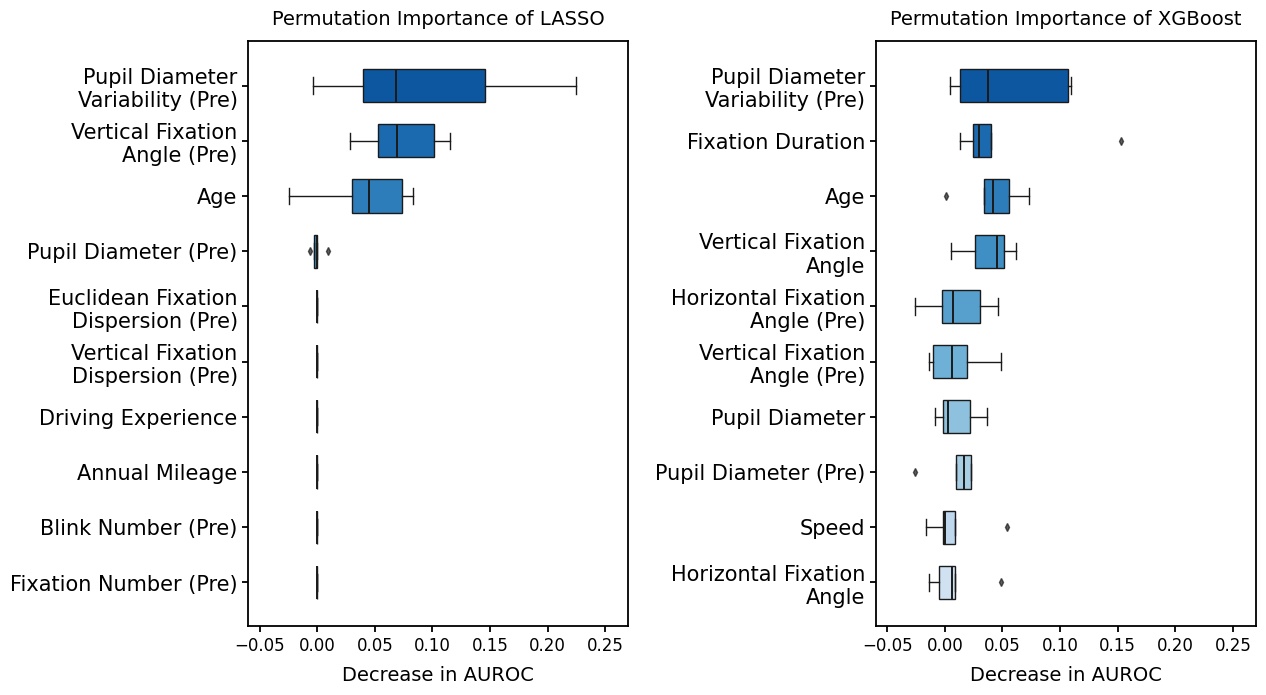

In [ ]:
import os,re
import json
import glob
import numpy as np
import pandas as pd
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from xgboost import XGBClassifier
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.inspection import permutation_importance
from sklearn.metrics import roc_auc_score
import matplotlib.pyplot as plt
import shap
import textwrap

def wrap_labels(label, width=22):
    """Wrap to at most `width` chars per line."""
    return "\n".join(textwrap.wrap(label, width))

# -------------------------
# SETTINGS
# -------------------------
selected_seeds = [
    3558, 6687, 6836, 7862, 11033,
    13285, 22075, 22163, 23858, 30690
]

outer_splits = 5
cat_names = ["Gender", "automation", "eventType"]

# df, y, groups, feature_cols already exist
# LASSO
lasso_base_dir = "/content/drive/MyDrive/Colab_Backups/LR_test"
lasso_results_path = "/content/drive/MyDrive/Colab_Backups/LR_test/LRC_singleTW.xlsx"
lasso_model_dir = "LRC_model_singleTW"
lasso_targetTW = 11
lasso_TWs = [lasso_targetTW]

# XGB
xgb_base_dir = "/content/drive/MyDrive/Colab_Backups/XGBC"
xgb_results_path = "/content/drive/MyDrive/Colab_Backups/XGBC/XGBC_combineTW.xlsx"
xgb_model_dir = "XGB_model_combineTW"
xgb_targetTW = 13
xgb_TWs = [0,xgb_targetTW]

TWs = lasso_TWs + xgb_TWs

# --- Load data ---
df = pd.read_excel("/content/drive/MyDrive/Colab_Backups/Data_3sMean_IDT_beforeMat.xlsx")
allowed_events = {"EVENT_MAT_RIGHT_VRU", "EVENT_MAT_LEFT_VRU", "EVENT_MAT_ONCOMING"}
df = df[df["eventType"].isin(allowed_events)].copy()
target_col = "relativeRT"
df[target_col] = pd.to_numeric(df[target_col], errors="coerce")
df = df.dropna(subset=[target_col, "eventType", "subNumber"]).copy()
df["rt85_by_event"] = df.groupby("eventType")[target_col].transform(lambda x: x.quantile(0.85))
df["RT85_cls"] = (df[target_col] >= df["rt85_by_event"]).astype(int)
tww_cols = [f"perValid_{i}" for i in range(31)]
df = df[df[tww_cols].mean(axis=1) >= 74.5].copy()

feature_templates = [
    "Age", "License", "Mileage",
    "Gender", "automation", "eventType",
    "visibleSpeed",
    "pdMean_{TW}", "pdSd_{TW}",
    "blinkNumber_{TW}",
    "avgBlinkDuration_{TW}",
    "fixNumber_{TW}",
    "avgFixDuration_{TW}",
    "fixTE_{TW}", "fixSE_{TW}",
    "FixDisperX_{TW}", "FixDisperY_{TW}",
    "FixDisperE_{TW}",
    "FixMeanPosX_{TW}", "FixMeanPosY_{TW}",
]

feature_cols = []
for c in feature_templates:
    if "{TW}" in c:
        feature_cols.extend([c.format(TW=tw) for tw in TWs])
    else:
        feature_cols.append(c)

X = df[feature_cols].copy()
y = df["RT85_cls"].values.astype(int)
groups = df["subNumber"].values

print(f"Number of samples: {len(df)}")
print("Class counts:", pd.Series(y).value_counts().to_dict())
print("Number of groups:", len(np.unique(groups)))

def clean_feature_name(name):
    # categorical one-hot handling FIRST
    if "_" in name:
        prefix, val = name.split("_", 1)

        if prefix in ["Gender", "automation", "eventType"]:

            if prefix == "automation":
                val_map = {
                    "1": "MD",
                    "2": "PAD"
                }
                val = val_map.get(val, val)

            elif prefix == "Gender":
                val_map = {
                    "M": "Male",
                    "F": "Female"
                }
                val = val_map.get(val, val)

            return f"{name_map.get(prefix, prefix)} {val}"

    # TW suffix handling SECOND
    match = re.match(r"(.+?)_(\d+)$", name)

    if match:
        base, tw = match.groups()
        tw = int(tw)

        base_clean = name_map.get(base, base)

        if tw == 0:
            return f"{base_clean}"
        else:
            return f"{base_clean} (Pre)"

    return name_map.get(name, name)

# name_map = {
#     # demographics / context
#     "Age": "Age",
#     "License": "DrivingExperience",
#     "Mileage": "Mileage",
#     "Gender": "Gender",
#     "automation": "Automation",
#     "eventType": "EventType",
#     "visibleSpeed": "VisibleSpeed",

#     # pupil
#     "pdMean": "PupilMean",
#     "pdSd": "PupilStd",

#     # blink
#     "blinkNumber": "BlinkNum",
#     "avgBlinkDuration": "BlinkDurMean",

#     # fixation count/duration
#     "fixNumber": "FixNum",
#     "avgFixDuration": "FixDurMean",

#     # entropy
#     "fixTE": "FixTEntropy",
#     "fixSE": "FixSEntropy",

#     # dispersion (SD)
#     "FixDisperX": "FixSDx",
#     "FixDisperY": "FixSDy",
#     "FixDisperE": "FixSDe",

#     # mean position
#     "FixMeanPosX": "FixMx",
#     "FixMeanPosY": "FixMy",
# }

name_map = {
    "Age": "Age",
    "License": "Driving Experience",
    "Mileage": "Annual Mileage",
    "Gender": "Gender",
    "automation": "Automation",
    "eventType": "Hazard",
    "visibleSpeed": "Speed",
    "pdMean": "Pupil Diameter",
    "pdSd": "Pupil Diameter Variability",
    "blinkNumber": "Blink Number",
    "avgBlinkDuration": "Blink Duration",
    "fixNumber": "Fixation Number",
    "avgFixDuration": "Fixation Duration",
    "fixTE": "Transition Entropy",
    "fixSE": "Stationary Entropy",
    "FixDisperX": "Horizontal Fixation Dispersion",
    "FixDisperY": "Vertical Fixation Dispersion",
    "FixDisperE": "Euclidean Fixation Dispersion",
    "FixMeanPosX": "Horizontal Fixation Angle",
    "FixMeanPosY": "Vertical Fixation Angle",
}


def find_best_seed(results_path, targetTW, selected_seeds):
    res = pd.read_excel(results_path)

    res["outer_fold"] = res["outer_fold"].astype(str)
    res["TW"] = pd.to_numeric(res["TW"], errors="coerce")
    res["AUC"] = pd.to_numeric(res["AUC"], errors="coerce")

    sub = res[
        (res["outer_fold"] == "SUMMARY") &
        (res["TW"] == targetTW) &
        (res["seed"].isin(selected_seeds))
    ].copy()

    if sub.empty:
        raise ValueError(f"No SUMMARY rows found for TW={targetTW}")

    best_row = sub.loc[sub["AUC"].idxmax()]

    return int(best_row["seed"]), float(best_row["AUC"]), sub.sort_values("AUC", ascending=False)


def fit_outer_onehot(X_train_raw, X_test_raw, cat_cols):
    """
    Fit category levels from outer-train only, then one-hot outer-train and outer-test once.
    Returns aligned float32 matrices.
    """
    X_train_raw = X_train_raw.copy()
    X_test_raw = X_test_raw.copy()

    use_cat = [c for c in cat_cols if c in X_train_raw.columns]

    # lock category levels using OUTER TRAIN only
    for c in use_cat:
        train_cats = pd.Index(X_train_raw[c].dropna().unique())
        dtype = pd.CategoricalDtype(categories=train_cats, ordered=False)
        X_train_raw[c] = X_train_raw[c].astype(dtype)
        X_test_raw[c] = X_test_raw[c].astype(dtype)

    X_train_oh = pd.get_dummies(
        X_train_raw,
        columns=use_cat,
        drop_first=False
    )

    X_test_oh = pd.get_dummies(
        X_test_raw,
        columns=use_cat,
        drop_first=False
    )

    X_test_oh = X_test_oh.reindex(columns=X_train_oh.columns, fill_value=0)

    # keep exact same column order
    X_train_oh = X_train_oh.astype(np.float32)
    X_test_oh = X_test_oh.astype(np.float32)

    return X_train_oh, X_test_oh

# -------------------------
# HELPER: load fold-specific params
# -------------------------
def load_lasso_params(base_dir, model_dir, seed, tw, outer_fold):
    folder = os.path.join(base_dir, model_dir)

    # First pattern
    candidates = glob.glob(os.path.join(
        folder,
        f"lr_seed_{seed:02d}_*TW_{tw:02d}_outerfold_{outer_fold:02d}_meta.json"
    ))

    # Fallback pattern if none found
    if len(candidates) == 0:
        candidates = glob.glob(os.path.join(
            folder,
            f"lr_seed_{seed:02d}_TW_{tw:02d}_outerfold_{outer_fold:02d}_meta.json"
        ))

    # Sort candidates by length (or any rule you prefer)
    selected_file = sorted(candidates, key=len)[0]

    # Print the file being loaded
    print("Loading best params from file:", selected_file)

    # Load JSON
    with open(selected_file, "r") as f:
        meta_json = json.load(f)

    # Print best parameters
    best_params = meta_json["best_params"]
    print("Best parameters:", best_params)

    return best_params

def load_xgb_params(base_dir, model_dir, seed, tw, outer_fold):
    folder = os.path.join(base_dir, model_dir)
    candidates = glob.glob(os.path.join(
        folder,
        f"xgb_seed_{seed:02d}_*TW_{tw:02d}_outerfold_{outer_fold:02d}_meta.json"
    ))
    if len(candidates) == 0:
        candidates = glob.glob(os.path.join(
            folder,
            f"xgb_seed_{seed:02d}_TW_{tw:02d}_outerfold_{outer_fold:02d}_meta.json"
        ))
    import json
    with open(sorted(candidates, key=len)[0], "r") as f:
        meta_json = json.load(f)
    return meta_json["best_params"]

def ensure_categorical_dtype_from_train(train_df, test_df, cat_cols):
    train_df = train_df.copy()
    test_df = test_df.copy()

    for col in cat_cols:
        if col in train_df.columns:
            cats = pd.Index(train_df[col].dropna().unique())
            dtype = pd.CategoricalDtype(categories=cats, ordered=False)
            train_df[col] = train_df[col].astype(dtype)
            test_df[col] = test_df[col].astype(dtype)

    return train_df, test_df

def find_best_seed(results_path, targetTW, selected_seeds):
    res = pd.read_excel(results_path)

    res["outer_fold"] = res["outer_fold"].astype(str)
    res["TW"] = pd.to_numeric(res["TW"], errors="coerce")
    res["AUC"] = pd.to_numeric(res["AUC"], errors="coerce")

    sub = res[
        (res["outer_fold"] == "SUMMARY") &
        (res["TW"] == targetTW) &
        (res["seed"].isin(selected_seeds))
    ].copy()

    if sub.empty:
        raise ValueError(f"No SUMMARY rows found for TW={targetTW}")

    best_row = sub.loc[sub["AUC"].idxmax()]

    return int(best_row["seed"]), float(best_row["AUC"]), sub.sort_values("AUC", ascending=False)

# --- Helper: shuffle group of dummy columns together ---
# =========================================================
# FIX 1: Seed the permutation RNG (reproducibility)
# FIX 2: Verify permutation actually changes values
# =========================================================

# --- Helper: shuffle group of dummy columns together ---
def permute_group(X, cols, rng):
    """
    Shuffle the rows of the specified columns together using a seeded RNG.

    Parameters
    ----------
    X : pd.DataFrame
    cols : list of column names to permute jointly (e.g. one-hot dummies of a
           categorical variable, or a single continuous column).
    rng : np.random.Generator
        Seeded random generator for reproducibility.

    Returns
    -------
    X_permuted : pd.DataFrame
    """
    X_permuted = X.copy()
    perm_idx = rng.permutation(X.shape[0])

    # Capture original dtypes for the columns being permuted (handles category dtype)
    original_dtypes = {c: X_permuted[c].dtype for c in cols}

    # Shuffle as numpy values, then reassign while preserving dtypes
    shuffled_values = X_permuted[cols].to_numpy()[perm_idx]
    for j, c in enumerate(cols):
        X_permuted[c] = pd.Series(shuffled_values[:, j], index=X_permuted.index) \
                          .astype(original_dtypes[c])

    return X_permuted


def compute_grouped_pfi(model, X_test, y_test, cat_dummies, n_repeats=20,
                         base_seed=0, debug=False):
    """
    Compute grouped PFI: shuffle all dummies of a categorical variable together.

    Parameters
    ----------
    model : fitted classifier with predict_proba
    X_test : pd.DataFrame (test set, same column order as training)
    y_test : array-like of binary labels
    cat_dummies : dict {feature_group_name: [columns_to_permute_together]}
    n_repeats : int, number of permutation repeats per feature group
    base_seed : int, seeds the RNG (feature group index and repeat index are
                folded in so each (feature, repeat) gets a unique stream).
    debug : bool, print verification info

    Returns
    -------
    pfi_results : dict {feature: mean_drop_in_AUC}
    """
    pfi_results = {}

    # Base AUC with original (unpermuted) test data
    base_auc = roc_auc_score(y_test, model.predict_proba(X_test)[:, 1])
    if debug:
        print(f"Base AUC: {base_auc:.4f}")

    for cat_idx, (cat, cols) in enumerate(cat_dummies.items()):
        scores = []

        for i in range(n_repeats):
            # Unique, reproducible seed per (feature_group, repeat)
            repeat_seed = base_seed * 10_000 + cat_idx * 100 + i
            rng = np.random.default_rng(repeat_seed)

            X_perm = permute_group(X_test, cols, rng=rng)

            # ---- ASSERTION: permutation must actually change values ----
            # (skip for constant columns where permutation is a no-op)
            for c in cols:
                if X_test[c].nunique(dropna=False) > 1:
                    # Count rows where the permuted value differs from original
                    n_changed = (X_test[c].values != X_perm[c].values).sum()
                    assert n_changed > 0, (
                        f"Permutation produced no changes for column '{c}' "
                        f"in group '{cat}' (repeat {i+1}). "
                        f"Check dtype handling in permute_group."
                    )

            if debug:
                for c in cols:
                    if X_test[c].nunique(dropna=False) > 1:
                        n_changed = (X_test[c].values != X_perm[c].values).sum()
                        print(f"  Group '{cat}' | col '{c}' | repeat {i+1}: "
                              f"{n_changed}/{len(X_test)} rows changed")

            y_pred = model.predict_proba(X_perm)[:, 1]
            perm_auc = roc_auc_score(y_test, y_pred)
            scores.append(perm_auc)

        mean_drop = base_auc - np.mean(scores)
        pfi_results[cat] = mean_drop

        if debug:
            print(f"  Group '{cat}' final PFI (mean AUC drop): {mean_drop:.6f}\n")

    return pfi_results


# --- Main PFI function ---
def compute_pfi(model_type, best_seed, base_dir, model_dir, targetTW,
                X, y, groups, cat_names, outer_splits=5, n_repeats=10,
                debug_permutation=False):

    pfi_rows = []
    fold_auc_list = []
    outer_cv = StratifiedGroupKFold(n_splits=outer_splits, shuffle=True,
                                     random_state=best_seed)

    for outer_fold, (train_idx, test_idx) in enumerate(outer_cv.split(X, y, groups),
                                                       start=1):
        print(f"\n=== {model_type} | Outer Fold {outer_fold} ===")
        X_train = X.iloc[train_idx].copy()
        X_test = X.iloc[test_idx].copy()
        y_train = y[train_idx]
        y_test = y[test_idx]

        # Load fold-specific params
        if model_type.lower() == "lasso":
            best_params = load_lasso_params(base_dir, model_dir, best_seed,
                                             targetTW, outer_fold)
            local_feature_cols = []
            for c in feature_templates:
                if "{TW}" in c:
                    local_feature_cols.extend([c.format(TW=tw) for tw in lasso_TWs])
                else:
                    local_feature_cols.append(c)

            X_out_train = X_train[local_feature_cols].copy()
            X_out_test  = X_test[local_feature_cols].copy()
            X_out_train_oh, X_out_test_oh = fit_outer_onehot(X_out_train, X_out_test,
                                                              cat_names)

            # Impute and scale
            imputer = SimpleImputer(strategy="median")
            X_out_train_oh = pd.DataFrame(
                imputer.fit_transform(X_out_train_oh),
                columns=X_out_train_oh.columns,
                index=X_out_train_oh.index,
            )
            X_out_test_oh = pd.DataFrame(
                imputer.transform(X_out_test_oh),
                columns=X_out_test_oh.columns,
                index=X_out_test_oh.index,
            )
            scaler = StandardScaler()
            X_out_train_oh = pd.DataFrame(
                scaler.fit_transform(X_out_train_oh),
                columns=X_out_train_oh.columns,
                index=X_out_train_oh.index,
            )
            X_out_test_oh = pd.DataFrame(
                scaler.transform(X_out_test_oh),
                columns=X_out_test_oh.columns,
                index=X_out_test_oh.index,
            )

            model = LogisticRegression(**best_params)

        else:  # XGB
            best_params = load_xgb_params(base_dir, model_dir, best_seed,
                                           targetTW, outer_fold)
            local_feature_cols = []
            for c in feature_templates:
                if "{TW}" in c:
                    local_feature_cols.extend([c.format(TW=tw) for tw in xgb_TWs])
                else:
                    local_feature_cols.append(c)

            X_out_train = X_train[local_feature_cols].copy()
            X_out_test  = X_test[local_feature_cols].copy()

            X_out_train_oh, X_out_test_oh = ensure_categorical_dtype_from_train(
                X_out_train, X_out_test, cat_names
            )

            model = XGBClassifier(**best_params)

        # Fit model
        model.fit(X_out_train_oh, y_train)

        # Compute fold AUC
        y_pred_prob = model.predict_proba(X_out_test_oh)[:, 1]
        fold_auc = roc_auc_score(y_test, y_pred_prob)
        print(f"Fold {outer_fold} AUC: {fold_auc:.4f}")
        fold_auc_list.append({"outer_fold": outer_fold, "model": model_type,
                              "AUC": fold_auc})

        # --- define categorical dummy groups ---
        cat_dummies = {}
        for cat in cat_names:
            cat_dummies[cat] = [col for col in X_out_test_oh.columns
                                if col.startswith(cat + "_")
                                or col == cat]   # 👈 handles XGB native-category case
            # If no matching columns found, drop the entry to avoid empty group
            if len(cat_dummies[cat]) == 0:
                del cat_dummies[cat]

        # Continuous columns
        cat_col_names_flat = {c for cols in cat_dummies.values() for c in cols}
        cont_cols = [col for col in X_out_test_oh.columns
                     if col not in cat_col_names_flat]

        # Combine categorical and continuous columns into permutation groups
        pf_groups = {}
        for cat, cols in cat_dummies.items():
            pf_groups[cat] = cols
        for col in cont_cols:
            pf_groups[col] = [col]

        # Compute grouped PFI — seed RNG per fold for reproducibility
        # (combines best_seed and outer_fold so each fold gets a unique stream)
        fold_base_seed = best_seed * 100 + outer_fold

        grouped_pfi_dict = compute_grouped_pfi(
            model, X_out_test_oh, y_test, pf_groups,
            n_repeats=n_repeats,
            base_seed=fold_base_seed,
            debug=debug_permutation,
        )

        fold_df = pd.DataFrame({
            "feature": list(grouped_pfi_dict.keys()),
            "pfi_mean": list(grouped_pfi_dict.values()),
        })
        fold_df["outer_fold"] = outer_fold
        fold_df["model"] = model_type
        pfi_rows.append(fold_df)

    return pd.concat(pfi_rows, ignore_index=True), pd.DataFrame(fold_auc_list)

# -------------------------
# Find Best Seed
# # -------------------------
# best_seed_lasso, best_summary_auc, seed_rank = find_best_seed(
#     results_path=lasso_results_path,
#     targetTW=lasso_targetTW,
#     selected_seeds=selected_seeds
# )
# print(f"\nBest {lasso_model_dir} seed:", best_seed_lasso)
# print("Best SUMMARY AUC:", best_summary_auc)
# print("\nSeed ranking:")
# print(seed_rank[["seed", "TW", "AUC"]])

# best_seed_xgb, best_summary_auc, seed_rank = find_best_seed(
#     results_path=xgb_results_path,
#     targetTW=xgb_targetTW,
#     selected_seeds=selected_seeds
# )

# print(f"\nBest {xgb_model_dir} seed:", best_seed_xgb)
# print("Best SUMMARY AUC:", best_summary_auc)
# print("\nSeed ranking:")
# print(seed_rank[["seed", "TW", "AUC"]])
# # -------------------------
# # RUN PFI
# # -------------------------

# pfi_lasso_df, lasso_fold_auc = compute_pfi(
#     model_type="LASSO",
#     best_seed=best_seed_lasso,
#     base_dir=lasso_base_dir,
#     model_dir=lasso_model_dir,
#     targetTW=lasso_targetTW,
#     X=X,
#     y=y,
#     groups=groups,
#     cat_names=cat_names,
#     outer_splits=outer_splits
# )

# pfi_xgb_df, xgb_fold_auc = compute_pfi(
#     model_type="XGB",
#     best_seed=best_seed_xgb,
#     base_dir=xgb_base_dir,
#     model_dir=xgb_model_dir,
#     targetTW=xgb_targetTW,
#     X=X,
#     y=y,
#     groups=groups,
#     cat_names=cat_names,
#     outer_splits=outer_splits
# )

# # print fold AUCs for verification
# print("\n=== LASSO fold AUCs ===")
# print(lasso_fold_auc)
# print("\n=== XGB fold AUCs ===")
# print(xgb_fold_auc)

# -------------------------
# AGGREGATE PFI
# -------------------------
# =========================================================
# PFI plot — matched to right-side bars in main figure
# =========================================================

pfi_all = pd.concat([pfi_lasso_df, pfi_xgb_df], ignore_index=True)

pfi_summary = (
    pfi_all.groupby(["feature", "model"], as_index=False)
           .agg(mean_pfi=("pfi_mean", "mean"),
                sd_pfi=("pfi_mean", "std"))
)

top_n = 10

# Style constants (matching your main figure)

PFI_BAR_COLORS = {
    # "LASSO": "#FF0D57",   # SHAP red
    "LASSO": "#1E88E5",   # SHAP blue (unchanged)
    "XGB":   "#1E88E5",   # SHAP blue (unchanged)
}
PFI_BAR_ALPHA = 0.9
BAR_HEIGHT = 0.7
ERR_COLOR = "#1A1A1A"
ERR_LW = 1.0
ERR_CAPSIZE = 3
SPINE_WIDTH=1.3

fontsize_x_label = 14
fontsize_x_tick  = 12
fontsize_y       = 15

fig, axes = plt.subplots(1, 2, figsize=(12, 7.5))

global_x_min = 0
global_x_max = 0
for model_type in ["LASSO", "XGB"]:
    df_m = pfi_summary[pfi_summary["model"] == model_type]
    top_features = df_m.nlargest(top_n, "mean_pfi")["feature"].tolist()

    fold_vals = pfi_all[
        (pfi_all["model"] == model_type) &
        (pfi_all["feature"].isin(top_features))
    ]["pfi_mean"].values

    if len(fold_vals) > 0:
        global_x_min = min(global_x_min, fold_vals.min())
        global_x_max = max(global_x_max, fold_vals.max())

# Headroom on both sides
total_range = global_x_max - global_x_min
global_x_min -= 0.02 * total_range   # 👈 was 0.05 — half the padding
global_x_max += 0.10 * total_range   # unchanged

# Round to clean tick boundaries
tick_step = 0.03
global_x_min = np.floor(global_x_min / tick_step) * tick_step
global_x_max = np.ceil(global_x_max / tick_step) * tick_step


import matplotlib as mpl
from matplotlib.ticker import MultipleLocator

for i, model_type in enumerate(["LASSO", "XGB"]):
    ax = axes[i]

    # Pick the top-N features by mean PFI
    df_model = pfi_summary[pfi_summary["model"] == model_type].copy()
    # df_model = df_model[df_model["mean_pfi"] >= 0.001]   # 👈 minimum to make the cut

    top_feats = df_model.nlargest(top_n, "mean_pfi")
    top_feature_names = top_feats["feature"].tolist()

    # Pull per-fold PFI values for those top features (one box per feature)
    fold_df = pfi_all[
        (pfi_all["model"] == model_type) &
        (pfi_all["feature"].isin(top_feature_names))
    ].copy()

    # Reverse for horizontal bar/box (largest at top)
    features_clean = [clean_feature_name(f) for f in top_feature_names][::-1]
    raw_features_ordered = top_feature_names[::-1]

    # Build the list-of-arrays in the same order as features_clean
    box_data = [
        fold_df.loc[fold_df["feature"] == f, "pfi_mean"].values
        for f in raw_features_ordered
    ]

    # Blue gradient — darkest for largest importance (top of plot)
    cmap = plt.get_cmap("Blues")
    # Span the gradient from a strong dark (top) down to light (bottom)
    color_levels = np.linspace(0.85, 0.20, len(box_data))
    box_colors = [cmap(c) for c in color_levels]
    # The plotted box order is bottom → top, so reverse the colour assignment
    box_colors = box_colors[::-1]

    y_positions = np.arange(len(box_data))

    bp = ax.boxplot(
        box_data,
        positions=y_positions,
        vert=False,
        widths=0.6,
        patch_artist=True,
        showfliers=True,
        flierprops=dict(
            marker="d",
            markersize=4,
            markerfacecolor="#1A1A1A",
            markeredgecolor="#1A1A1A",
            alpha=0.7,
        ),
        medianprops=dict(color="#1A1A1A", linewidth=1.4),
        whiskerprops=dict(color="#1A1A1A", linewidth=1.0),
        capprops=dict(color="#1A1A1A", linewidth=1.0),
        boxprops=dict(linewidth=1.0, edgecolor="#1A1A1A"),
    )

    for patch, c in zip(bp["boxes"], box_colors):
        patch.set_facecolor(c)

    ax.set_yticks(y_positions)
    # ax.set_yticklabels(features_clean)
    ax.set_yticklabels([wrap_labels(f) for f in features_clean])


    ax.set_xlim(global_x_min, global_x_max)
    ax.tick_params(axis="x", labelsize=fontsize_x_tick)
    ax.xaxis.set_major_locator(MultipleLocator(0.05))
    ax.grid(False)
    ax.set_axisbelow(True)

# PANEL_LABEL_FONTSIZE = 16

# panel_labels = [
#     (axes[0], "(a)"),
#     (axes[1], "(b)"),
# ]

# for ax, label in panel_labels:
#     ax.text(
#         -0.45, 1.05,
#         label,
#         transform=ax.transAxes,
#         ha="left", va="bottom",
#         fontsize=PANEL_LABEL_FONTSIZE,
#         fontweight="bold",
#     )

plt.subplots_adjust(
    left=0.14,
    right=0.98,
    top=0.92,
    bottom=0.14,
    wspace=0.65,
)
for ax in axes:
    ax.tick_params(axis="y", labelsize=fontsize_y)
    ax.set_xlabel("Decrease in AUROC", fontsize=fontsize_x_label, labelpad=8)

SPINE_WIDTH = 1.3

for ax in axes:
    for spine in ax.spines.values():
        if spine.get_visible():
            spine.set_linewidth(SPINE_WIDTH)
            spine.set_edgecolor("black")

    # X-axis ticks (bottom only)
    ax.tick_params(
        axis="x",
        labelsize=fontsize_x_tick,
        length=4,
        width=SPINE_WIDTH,
        colors="black",
        direction="out",
        bottom=True,
        top=False,
    )

    # Y-axis ticks (left only)
    ax.tick_params(
        axis="y",
        labelsize=fontsize_y,
        length=4,
        width=SPINE_WIDTH,
        colors="black",
        direction="out",
        left=True,
        right=False,
    )
    padding = 0.3

    ax.set_ylim(
        -0.5  - padding,
        len(y_positions) - 0.5 + padding
    )

titles = {
    "LASSO": "Permutation Importance of LASSO",
    "XGB": "Permutation Importance of XGBoost"
}

for i, model_type in enumerate(["LASSO", "XGB"]):

    ax = axes[i]

    ax.set_title(
        titles[model_type],
        fontsize=fontsize_x_label,
        pad=12
    )

plt.show()

Final N = 351 | class counts: {0: 304, 1: 47}
[LASSO PFI] seed=3558
[XGB PFI]   seed=3558
[LASSO PFI] seed=6687
[XGB PFI]   seed=6687
[LASSO PFI] seed=6836
[XGB PFI]   seed=6836
[LASSO PFI] seed=7862
[XGB PFI]   seed=7862
[LASSO PFI] seed=11033
[XGB PFI]   seed=11033
[LASSO PFI] seed=13285
[XGB PFI]   seed=13285
[LASSO PFI] seed=22075
[XGB PFI]   seed=22075
[LASSO PFI] seed=22163
[XGB PFI]   seed=22163
[LASSO PFI] seed=23858
[XGB PFI]   seed=23858
[LASSO PFI] seed=30690
[XGB PFI]   seed=30690

pfi_long (per seed): (530, 4)
Cached PFI table saved to /content/drive/MyDrive/Colab_Backups/crossseed_pfi_cache_cls/pfi_long_cls.parquet


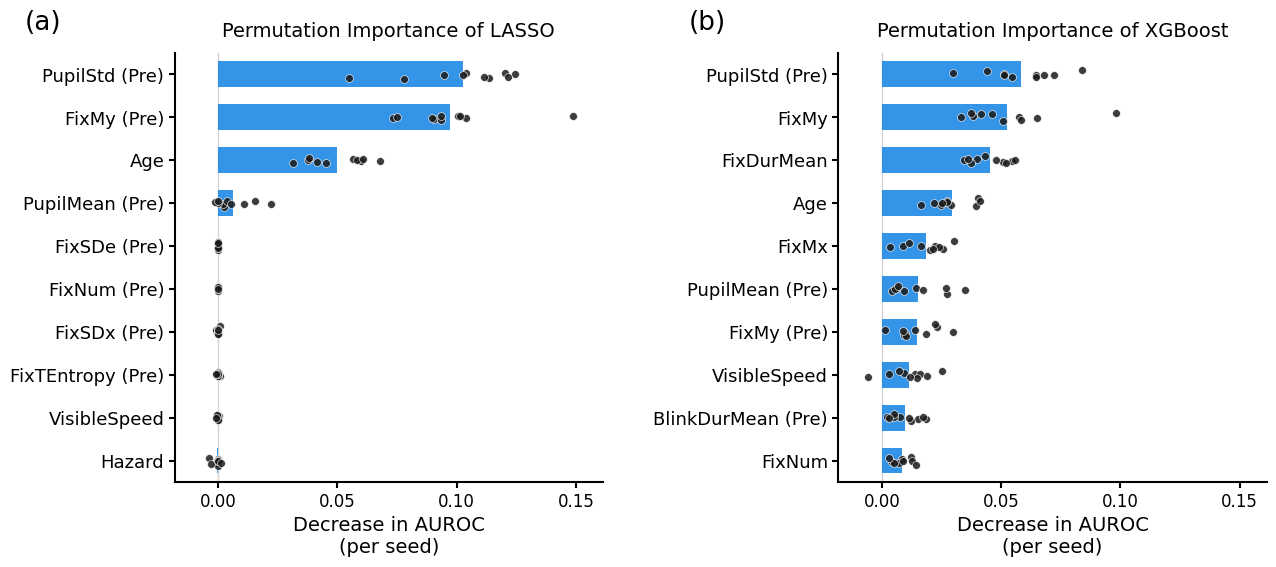

In [ ]:
# =====================================================================
# CROSS-SEED (PFI) — CLASSIFICATION
#   Two panels: (left) LASSO single-TW, (right) XGBoost combine-TW.
#   For each feature, shows the distribution across the 10 seeds of the
#   per-seed PFI (= mean fold-PFI over that seed's 5 outer folds).
#
#   Reuses the grouped-PFI logic (permute one-hot dummies of a categorical
#   together; XGB native-category handled). Self-contained.
# =====================================================================

import os
import re
import json
import glob
import textwrap

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import roc_auc_score
from xgboost import XGBClassifier


# =====================================================================
# 0. CONFIG
# =====================================================================
data_path = "/content/drive/MyDrive/Colab_Backups/Data_3sMean_IDT_beforeMat.xlsx"

SELECTED_SEEDS = [
    3558, 6687, 6836, 7862, 11033,
    13285, 22075, 22163, 23858, 30690,
]

OUTER_SPLITS = 5
CAT_NAMES    = ["Gender", "automation", "eventType"]
TARGET_COL   = "relativeRT"
N_REPEATS    = 10        # PFI permutation repeats per feature per fold
TOP_N        = 10

# LASSO single-TW
LASSO_BASE_DIR  = "/content/drive/MyDrive/Colab_Backups/LR_test"
LASSO_MODEL_DIR = "LRC_model_singleTW"
LASSO_TARGET_TW = 11
LASSO_TWS       = [11]

# XGB combine-TW
XGB_BASE_DIR  = "/content/drive/MyDrive/Colab_Backups/XGBC"
XGB_MODEL_DIR = "XGB_model_combineTW"
XGB_TARGET_TW = 13
XGB_TWS       = [0, 13]

# Caching (PFI is expensive — cache the per-seed-fold-feature table)
CACHE_DIR  = "/content/drive/MyDrive/Colab_Backups/crossseed_pfi_cache_cls"
PFI_CACHE  = os.path.join(CACHE_DIR, "pfi_long_cls.parquet")
SAVE_CACHE = True
USE_CACHE  = True


# =====================================================================
# 1. HELPERS  (name map, feature builder, encoders, param loaders, PFI)
# =====================================================================
NAME_MAP = {
    "Age": "Age", "License": "DrivingExperience", "Mileage": "Mileage",
    "Gender": "Gender", "automation": "Automation", "eventType": "Hazard",
    "visibleSpeed": "VisibleSpeed",
    "pdMean": "PupilMean", "pdSd": "PupilStd",
    "blinkNumber": "BlinkNum", "avgBlinkDuration": "BlinkDurMean",
    "fixNumber": "FixNum", "avgFixDuration": "FixDurMean",
    "fixTE": "FixTEntropy", "fixSE": "FixSEntropy",
    "FixDisperX": "FixSDx", "FixDisperY": "FixSDy", "FixDisperE": "FixSDe",
    "FixMeanPosX": "FixMx", "FixMeanPosY": "FixMy",
}

FEATURE_TEMPLATES = [
    "Age", "License", "Mileage",
    "Gender", "automation", "eventType",
    "visibleSpeed",
    "pdMean_{TW}", "pdSd_{TW}",
    "blinkNumber_{TW}", "avgBlinkDuration_{TW}",
    "fixNumber_{TW}", "avgFixDuration_{TW}",
    "fixTE_{TW}", "fixSE_{TW}",
    "FixDisperX_{TW}", "FixDisperY_{TW}", "FixDisperE_{TW}",
    "FixMeanPosX_{TW}", "FixMeanPosY_{TW}",
]


def build_feature_cols(tws):
    cols = []
    for c in FEATURE_TEMPLATES:
        if "{TW}" in c:
            cols.extend([c.format(TW=tw) for tw in tws])
        else:
            cols.append(c)
    return cols


def clean_feature_name(name):
    if "_" in name:
        prefix, val = name.split("_", 1)
        if prefix in ["Gender", "automation", "eventType"]:
            if prefix == "automation":
                val = {"1": "MD", "2": "PAD"}.get(val, val)
            elif prefix == "Gender":
                val = {"M": "Male", "F": "Female"}.get(val, val)
            elif prefix == "eventType":
                val = {
                    "EVENT_MAT_LEFT_VRU": "Left Pedestrian",
                    "EVENT_MAT_RIGHT_VRU": "Right Pedestrian",
                    "EVENT_MAT_ONCOMING": "Oncoming Vehicle",
                }.get(val, val)
            return f"{NAME_MAP.get(prefix, prefix)} {val}"
    m = re.match(r"(.+?)_(\d+)$", name)
    if m:
        base, tw = m.groups()
        base_clean = NAME_MAP.get(base, base)
        return base_clean if int(tw) == 0 else f"{base_clean} (Pre)"
    return NAME_MAP.get(name, name)


def wrap_labels(label, width=20):
    return "\n".join(textwrap.wrap(label, width))


def fit_outer_onehot(X_train_raw, X_test_raw, cat_cols):
    X_train_raw = X_train_raw.copy()
    X_test_raw = X_test_raw.copy()
    use_cat = [c for c in cat_cols if c in X_train_raw.columns]
    for c in use_cat:
        cats = pd.Index(X_train_raw[c].dropna().unique())
        dtype = pd.CategoricalDtype(categories=cats, ordered=False)
        X_train_raw[c] = X_train_raw[c].astype(dtype)
        X_test_raw[c] = X_test_raw[c].astype(dtype)
    X_tr = pd.get_dummies(X_train_raw, columns=use_cat, drop_first=False)
    X_te = pd.get_dummies(X_test_raw, columns=use_cat, drop_first=False)
    X_te = X_te.reindex(columns=X_tr.columns, fill_value=0)
    return X_tr.astype(np.float32), X_te.astype(np.float32)


def ensure_categorical_dtype_from_train(train_df, test_df, cat_cols):
    train_df = train_df.copy()
    test_df = test_df.copy()
    for col in cat_cols:
        if col in train_df.columns:
            cats = pd.Index(train_df[col].dropna().unique())
            dtype = pd.CategoricalDtype(categories=cats, ordered=False)
            train_df[col] = train_df[col].astype(dtype)
            test_df[col] = test_df[col].astype(dtype)
    return train_df, test_df


def _load_meta(base_dir, model_dir, prefix, seed, tw, outer_fold):
    folder = os.path.join(base_dir, model_dir)
    patterns = [
        f"{prefix}_seed_{seed:02d}_*TW_{tw:02d}_outerfold_{outer_fold:02d}_meta.json",
        f"{prefix}_seed_{seed:02d}_TW_{tw:02d}_outerfold_{outer_fold:02d}_meta.json",
    ]
    candidates = []
    for p in patterns:
        candidates = glob.glob(os.path.join(folder, p))
        if candidates:
            break
    if not candidates:
        raise FileNotFoundError(
            f"No {prefix} metadata for seed={seed}, TW={tw}, fold={outer_fold} in {folder}"
        )
    path = sorted(candidates, key=len)[0]
    with open(path, "r", encoding="utf-8") as f:
        meta = json.load(f)
    return meta["best_params"]


# ---- grouped PFI (one-hot dummies of a categorical permuted together) ----
def permute_group(X, cols, rng):
    X_perm = X.copy()
    perm_idx = rng.permutation(X.shape[0])
    original_dtypes = {c: X_perm[c].dtype for c in cols}
    shuffled = X_perm[cols].to_numpy()[perm_idx]
    for j, c in enumerate(cols):
        X_perm[c] = pd.Series(shuffled[:, j], index=X_perm.index).astype(original_dtypes[c])
    return X_perm


def compute_grouped_pfi(model, X_test, y_test, pf_groups, n_repeats, base_seed):
    base_auc = roc_auc_score(y_test, model.predict_proba(X_test)[:, 1])
    out = {}
    for g_idx, (gname, cols) in enumerate(pf_groups.items()):
        scores = []
        for i in range(n_repeats):
            rng = np.random.default_rng(base_seed * 10_000 + g_idx * 100 + i)
            X_perm = permute_group(X_test, cols, rng)
            scores.append(roc_auc_score(y_test, model.predict_proba(X_perm)[:, 1]))
        out[gname] = base_auc - np.mean(scores)
    return out


def build_pf_groups(columns, cat_cols):
    """Group one-hot dummies of each categorical; everything else is its own group."""
    cat_dummies = {}
    for cat in cat_cols:
        members = [c for c in columns if c.startswith(cat + "_") or c == cat]
        if members:
            cat_dummies[cat] = members
    flat = {c for cols in cat_dummies.values() for c in cols}
    pf_groups = dict(cat_dummies)
    for c in columns:
        if c not in flat:
            pf_groups[c] = [c]
    return pf_groups


# =====================================================================
# 2. LOAD + FILTER DATA  (classification target)
# =====================================================================
df = pd.read_excel(data_path)
allowed_events = {"EVENT_MAT_RIGHT_VRU", "EVENT_MAT_LEFT_VRU", "EVENT_MAT_ONCOMING"}
df = df[df["eventType"].isin(allowed_events)].copy()

df[TARGET_COL] = pd.to_numeric(df[TARGET_COL], errors="coerce")
df = df.dropna(subset=[TARGET_COL, "eventType", "subNumber"]).copy()
df["rt85_by_event"] = df.groupby("eventType")[TARGET_COL].transform(lambda x: x.quantile(0.85))
df["RT85_cls"] = (df[TARGET_COL] >= df["rt85_by_event"]).astype(int)
tww_cols = [f"perValid_{i}" for i in range(31)]
df = df[df[tww_cols].mean(axis=1) >= 74.5].copy()

y = df["RT85_cls"].values.astype(int)
groups = df["subNumber"].values
y_strat = y.copy()
print(f"Final N = {len(df)} | class counts: {pd.Series(y).value_counts().to_dict()}")


# =====================================================================
# 2b. CACHE PROBE
# =====================================================================
_CACHE_HIT = USE_CACHE and os.path.exists(PFI_CACHE)
if _CACHE_HIT:
    pfi_long = pd.read_parquet(PFI_CACHE)
    print("\n[cache] Loaded PFI table from", PFI_CACHE, "-> skipping PFI computation.")


if not _CACHE_HIT:
    # =================================================================
    # 3. COMPUTE PFI for every seed x fold x feature, both models
    # =================================================================
    X_lasso = df[build_feature_cols(LASSO_TWS)].copy()
    X_xgb   = df[build_feature_cols(XGB_TWS)].copy()
    pfi_records = []

    for seed in SELECTED_SEEDS:
        cv = StratifiedGroupKFold(n_splits=OUTER_SPLITS, shuffle=True, random_state=seed)

        # ----- LASSO -----
        print(f"[LASSO PFI] seed={seed}")
        for outer_fold, (tr, te) in enumerate(cv.split(X_lasso, y_strat, groups), start=1):
            X_tr, X_te = X_lasso.iloc[tr].copy(), X_lasso.iloc[te].copy()
            y_tr, y_te = y[tr], y[te]

            best_params = _load_meta(LASSO_BASE_DIR, LASSO_MODEL_DIR, "lr",
                                     seed, LASSO_TARGET_TW, outer_fold)
            X_tr_oh, X_te_oh = fit_outer_onehot(X_tr, X_te, CAT_NAMES)

            imp = SimpleImputer(strategy="median")
            X_tr_oh = pd.DataFrame(imp.fit_transform(X_tr_oh),
                                   columns=X_tr_oh.columns, index=X_tr_oh.index)
            X_te_oh = pd.DataFrame(imp.transform(X_te_oh),
                                   columns=X_te_oh.columns, index=X_te_oh.index)
            sc = StandardScaler()
            X_tr_oh = pd.DataFrame(sc.fit_transform(X_tr_oh),
                                   columns=X_tr_oh.columns, index=X_tr_oh.index)
            X_te_oh = pd.DataFrame(sc.transform(X_te_oh),
                                   columns=X_te_oh.columns, index=X_te_oh.index)

            model = LogisticRegression(**best_params)
            model.fit(X_tr_oh, y_tr)

            pf_groups = build_pf_groups(list(X_te_oh.columns), CAT_NAMES)
            pfi = compute_grouped_pfi(model, X_te_oh, y_te, pf_groups,
                                      n_repeats=N_REPEATS,
                                      base_seed=seed * 100 + outer_fold)
            for feat, v in pfi.items():
                pfi_records.append({"model": "LASSO", "seed": seed,
                                    "fold": outer_fold, "feature": feat, "pfi": v})

        # ----- XGB -----
        print(f"[XGB PFI]   seed={seed}")
        for outer_fold, (tr, te) in enumerate(cv.split(X_xgb, y_strat, groups), start=1):
            X_tr, X_te = X_xgb.iloc[tr].copy(), X_xgb.iloc[te].copy()
            y_tr, y_te = y[tr], y[te]

            best_params = _load_meta(XGB_BASE_DIR, XGB_MODEL_DIR, "xgb",
                                     seed, XGB_TARGET_TW, outer_fold)
            X_tr_proc, X_te_proc = ensure_categorical_dtype_from_train(X_tr, X_te, CAT_NAMES)

            model = XGBClassifier(**best_params)
            model.fit(X_tr_proc, y_tr)

            pf_groups = build_pf_groups(list(X_te_proc.columns), CAT_NAMES)
            pfi = compute_grouped_pfi(model, X_te_proc, y_te, pf_groups,
                                      n_repeats=N_REPEATS,
                                      base_seed=seed * 100 + outer_fold)
            for feat, v in pfi.items():
                pfi_records.append({"model": "XGB", "seed": seed,
                                    "fold": outer_fold, "feature": feat, "pfi": v})

    pfi_fold_long = pd.DataFrame(pfi_records)

    # collapse folds -> one PFI per (model, seed, feature) = mean over that seed's folds
    pfi_long = (
        pfi_fold_long.groupby(["model", "seed", "feature"], as_index=False)
        .agg(pfi=("pfi", "mean"))
    )

    print("\npfi_long (per seed):", pfi_long.shape)

    if SAVE_CACHE:
        try:
            os.makedirs(CACHE_DIR, exist_ok=True)
            pfi_long.to_parquet(PFI_CACHE)
            print(f"Cached PFI table saved to {PFI_CACHE}")
        except Exception as e:
            print(f"[warn] cache save skipped: {e}")


# =====================================================================
# 4. PLOT — two panels, cross-seed PFI distribution per feature
# =====================================================================
DOT_COLOR, DOT_SIZE, DOT_ALPHA = "#1A1A1A", 32, 0.85
BAR_FACE = "#1E88E5"
BAR_HEIGHT = 0.6
FS_XLAB, FS_XTICK, FS_Y = 14, 12, 13
PANEL_FS, SPINE_W = 19, 1.5
N_SEEDS = len(SELECTED_SEEDS)
rng = np.random.default_rng(42)

# shared x-range across both panels for comparability
def _top_feats(model_type):
    mean_by_feat = (pfi_long[pfi_long["model"] == model_type]
                    .groupby("feature")["pfi"].mean().sort_values(ascending=False))
    return mean_by_feat.head(TOP_N).index.tolist()

xmin, xmax = 0.0, 0.0
for mt in ["LASSO", "XGB"]:
    feats = _top_feats(mt)
    vals = pfi_long[(pfi_long["model"] == mt) & (pfi_long["feature"].isin(feats))]["pfi"].values
    if len(vals):
        xmin = min(xmin, vals.min())
        xmax = max(xmax, vals.max())
rng_pad = (xmax - xmin) * 0.08
xmin -= rng_pad
xmax += rng_pad

fig, axes = plt.subplots(1, 2, figsize=(13, 5.8))

for ax_i, model_type in enumerate(["LASSO", "XGB"]):
    ax = axes[ax_i]
    feats = _top_feats(model_type)
    feats_plot = feats[::-1]                      # largest at top
    labels = [clean_feature_name(f) for f in feats_plot]
    n = len(feats_plot)

    for i, feat in enumerate(feats_plot):
        vals = pfi_long[(pfi_long["model"] == model_type) &
                        (pfi_long["feature"] == feat)]["pfi"].values
        if len(vals) == 0:
            continue
        ax.barh(i, np.mean(vals), color=BAR_FACE, edgecolor="none",
                height=BAR_HEIGHT, alpha=0.9, zorder=2)
        ax.scatter(vals, rng.normal(i, 0.06, size=len(vals)),
                   color=DOT_COLOR, s=DOT_SIZE, alpha=DOT_ALPHA,
                   edgecolor="white", linewidth=0.5, zorder=5)

    ax.axvline(0, color="lightgray", linewidth=1.0, zorder=0)
    ax.set_yticks(range(n))
    ax.set_yticklabels([wrap_labels(l) for l in labels], fontsize=FS_Y)
    ax.set_xlabel("Decrease in AUROC\n(per seed)", fontsize=FS_XLAB)
    ax.set_xlim(xmin, xmax)
    ax.set_ylim(-0.5, n - 0.5)
    ax.xaxis.set_major_locator(MultipleLocator(0.05))
    ax.set_title("Permutation Importance of "
                 + ("LASSO" if model_type == "LASSO" else "XGBoost"),
                 fontsize=FS_XLAB, pad=12)

# spines / ticks / panel labels
for ax in axes:
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.grid(False)
    for spine in ax.spines.values():
        if spine.get_visible():
            spine.set_linewidth(SPINE_W)
            spine.set_edgecolor("black")
    ax.tick_params(axis="x", labelsize=FS_XTICK, length=4, width=SPINE_W,
                   colors="black", direction="out", bottom=True, top=False)
    ax.tick_params(axis="y", labelsize=FS_Y, length=4, width=SPINE_W,
                   colors="black", direction="out", left=True, right=False,
                   labelleft=True)

for ax, lab in [(axes[0], "(a)"), (axes[1], "(b)")]:
    ax.text(-0.35, 1.04, lab, transform=ax.transAxes,
            ha="left", va="bottom", fontsize=PANEL_FS)

plt.subplots_adjust(left=0.14, right=0.98, top=0.90, bottom=0.16, wspace=0.55)
plt.show()

## Regression

Number of samples: 351
Number of features: 46
Number of groups: 40


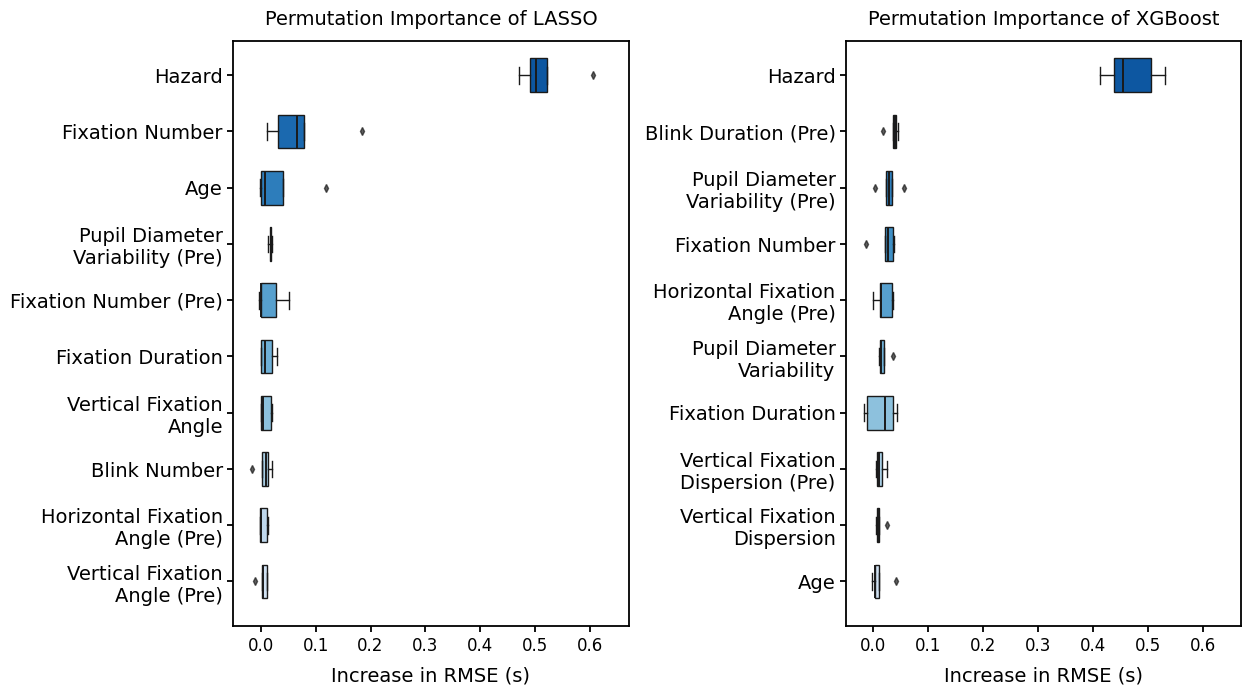

In [ ]:
"""
PFI for regression — measures the INCREASE in RMSE when each feature
(or feature group) is permuted.

Mirrors your classification PFI workflow but uses:
    - RMSE instead of AUROC (lower = better, so permutation INCREASES RMSE)
    - GroupKFold instead of StratifiedGroupKFold
    - Regressor models instead of classifiers
    - Seeds and configurations from your regression refit script

Each PFI value = RMSE_permuted - RMSE_baseline
                 (absolute increase in RMSE due to permutation)
"""

import os
import re
import json
import glob
import numpy as np
import pandas as pd
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Lasso
from xgboost import XGBRegressor
from sklearn.model_selection import GroupKFold
from sklearn.metrics import mean_squared_error
from matplotlib.ticker import MultipleLocator, FuncFormatter
import matplotlib.pyplot as plt
import shap
import textwrap

def wrap_labels(label, width=22):
    """Wrap to at most `width` chars per line."""
    return "\n".join(textwrap.wrap(label, width))

# =========================================================
# SETTINGS — match your regression refit script
# =========================================================
selected_seeds_reg = [
    261, 452, 285, 966, 786,
    1423, 3789, 5602, 8741, 11905,
]

outer_splits = 5
cat_names    = ["Gender", "automation", "eventType"]
target_col   = "relativeRT"
data_path    = "/content/drive/MyDrive/Colab_Backups/Data_3sMean_IDT_beforeMat.xlsx"

# --- LASSO regression ---
lasso_base_dir     = "/content/drive/MyDrive/Colab_Backups/LRR"
lasso_results_path = "/content/drive/MyDrive/Colab_Backups/LRR/LRR_combineTW.xlsx"
lasso_model_dir    = "LR_model_combineTW"
lasso_targetTW     = 20
lasso_TWs          = [0, 20]

# --- XGB regression ---
xgb_base_dir       = "/content/drive/MyDrive/Colab_Backups/XGBR"
xgb_results_path   = "/content/drive/MyDrive/Colab_Backups/XGBR/XGBR_combineTW.xlsx"
xgb_model_dir      = "XGB_model_combineTW"
xgb_targetTW       = 21
xgb_TWs            = [0, 21]


# =========================================================
# DATA LOAD + FEATURE TEMPLATES
# =========================================================
feature_templates = [
    "Age", "License", "Mileage",
    "Gender", "automation", "eventType",
    "visibleSpeed",
    "pdMean_{TW}", "pdSd_{TW}",
    "blinkNumber_{TW}",
    "avgBlinkDuration_{TW}",
    "fixNumber_{TW}",
    "avgFixDuration_{TW}",
    "fixTE_{TW}", "fixSE_{TW}",
    "FixDisperX_{TW}", "FixDisperY_{TW}",
    "FixDisperE_{TW}",
    "FixMeanPosX_{TW}", "FixMeanPosY_{TW}",
]

TWs = list(set(lasso_TWs + xgb_TWs))


def load_and_prepare_data(data_path, target_col):
    df = pd.read_excel(data_path)
    allowed_events = {"EVENT_MAT_RIGHT_VRU", "EVENT_MAT_LEFT_VRU", "EVENT_MAT_ONCOMING"}
    df = df[df["eventType"].isin(allowed_events)].copy()
    df[target_col] = pd.to_numeric(df[target_col], errors="coerce")
    df = df.dropna(subset=[target_col, "eventType", "subNumber"]).copy()

    tww_cols = [f"perValid_{i}" for i in range(31)]
    df = df[df[tww_cols].mean(axis=1) >= 74.5].copy()

    feature_cols = []
    for c in feature_templates:
        if "{TW}" in c:
            feature_cols.extend([c.format(TW=tw) for tw in TWs])
        else:
            feature_cols.append(c)

    X = df[feature_cols].copy()
    y = df[target_col].values.astype(float)
    groups = df["subNumber"].values
    return df, X, y, groups, feature_cols


df, X, y, groups, feature_cols = load_and_prepare_data(data_path, target_col)

print(f"Number of samples: {len(df)}")
print(f"Number of features: {len(feature_cols)}")
print(f"Number of groups: {len(np.unique(groups))}")


# =========================================================
# Name mapping for clean labels
# =========================================================
# name_map = {
#     "Age": "Age", "License": "DrivingExperience", "Mileage": "Mileage",
#     "Gender": "Gender", "automation": "Automation", "eventType": "Hazard",
#     "visibleSpeed": "VisibleSpeed",
#     "pdMean": "PupilMean", "pdSd": "PupilStd",
#     "blinkNumber": "BlinkNum", "avgBlinkDuration": "BlinkDurMean",
#     "fixNumber": "FixNum", "avgFixDuration": "FixDurMean",
#     "fixTE": "FixTEntropy", "fixSE": "FixSEntropy",
#     "FixDisperX": "FixSDx", "FixDisperY": "FixSDy", "FixDisperE": "FixSDe",
#     "FixMeanPosX": "FixMx", "FixMeanPosY": "FixMy",
# }

name_map = {
    "Age": "Age",
    "License": "Driving Experience",
    "Mileage": "Annual Mileage",
    "Gender": "Gender",
    "automation": "Automation",
    "eventType": "Hazard",
    "visibleSpeed": "Speed",
    "pdMean": "Pupil Diameter",
    "pdSd": "Pupil Diameter Variability",
    "blinkNumber": "Blink Number",
    "avgBlinkDuration": "Blink Duration",
    "fixNumber": "Fixation Number",
    "avgFixDuration": "Fixation Duration",
    "fixTE": "Transition Entropy",
    "fixSE": "Stationary Entropy",
    "FixDisperX": "Horizontal Fixation Dispersion",
    "FixDisperY": "Vertical Fixation Dispersion",
    "FixDisperE": "Euclidean Fixation Dispersion",
    "FixMeanPosX": "Horizontal Fixation Angle",
    "FixMeanPosY": "Vertical Fixation Angle",
}



def clean_feature_name(name):
    if "_" in name:
        prefix, val = name.split("_", 1)
        if prefix in ["Gender", "automation", "eventType"]:
            if prefix == "automation":
                val = {"1": "MD", "2": "PAD"}.get(val, val)
            elif prefix == "Gender":
                val = {"M": "Male", "F": "Female"}.get(val, val)
            return f"{name_map.get(prefix, prefix)} {val}"

    m = re.match(r"(.+?)_(\d+)$", name)
    if m:
        base, tw = m.groups()
        tw = int(tw)
        base_clean = name_map.get(base, base)
        return base_clean if tw == 0 else f"{base_clean} (Pre)"
    return name_map.get(name, name)


# =========================================================
# Helpers from your regression refit script
# =========================================================
def fit_outer_onehot(X_train_raw, X_test_raw, cat_cols):
    X_train_raw = X_train_raw.copy()
    X_test_raw  = X_test_raw.copy()
    use_cat = [c for c in cat_cols if c in X_train_raw.columns]
    for c in use_cat:
        train_cats = pd.Index(X_train_raw[c].dropna().unique())
        dtype = pd.CategoricalDtype(categories=train_cats, ordered=False)
        X_train_raw[c] = X_train_raw[c].astype(dtype)
        X_test_raw[c]  = X_test_raw[c].astype(dtype)
    X_train_oh = pd.get_dummies(X_train_raw, columns=use_cat, drop_first=False)
    X_test_oh  = pd.get_dummies(X_test_raw,  columns=use_cat, drop_first=False)
    X_test_oh  = X_test_oh.reindex(columns=X_train_oh.columns, fill_value=0)
    return X_train_oh.astype(np.float32), X_test_oh.astype(np.float32)


def ensure_categorical_dtype_from_train(train_df, test_df, cat_cols):
    train_df = train_df.copy()
    test_df  = test_df.copy()
    for col in cat_cols:
        if col in train_df.columns:
            cats = pd.Index(train_df[col].dropna().unique())
            dtype = pd.CategoricalDtype(categories=cats, ordered=False)
            train_df[col] = train_df[col].astype(dtype)
            test_df[col]  = test_df[col].astype(dtype)
    return train_df, test_df


def load_lasso_params_reg(base_dir, model_dir, seed, tw, outer_fold):
    folder = os.path.join(base_dir, model_dir)
    candidates = glob.glob(os.path.join(
        folder,
        f"lr_seed_{seed:02d}_*TW_{tw:02d}_outerfold_{outer_fold:02d}_meta.json"
    ))
    if len(candidates) == 0:
        candidates = glob.glob(os.path.join(
            folder,
            f"lr_seed_{seed:02d}_TW_{tw:02d}_outerfold_{outer_fold:02d}_meta.json"
        ))
    path = sorted(candidates, key=len)[0]
    with open(path, "r", encoding="utf-8") as f:
        meta_json = json.load(f)
    return meta_json["best_params"]


def load_xgb_params_reg(base_dir, model_dir, seed, tw, outer_fold):
    folder = os.path.join(base_dir, model_dir)
    candidates = glob.glob(os.path.join(
        folder,
        f"xgb_seed_{seed:02d}_*TW_{tw:02d}_outerfold_{outer_fold:02d}_meta.json"
    ))
    if len(candidates) == 0:
        candidates = glob.glob(os.path.join(
            folder,
            f"xgb_seed_{seed:02d}_TW_{tw:02d}_outerfold_{outer_fold:02d}_meta.json"
        ))
    path = sorted(candidates, key=len)[0]
    with open(path, "r", encoding="utf-8") as f:
        meta_json = json.load(f)
    return meta_json["best_params"]


def find_best_seed_reg(results_path, targetTW, selected_seeds, metric="RMSE"):
    """Best seed = lowest RMSE."""
    res = pd.read_excel(results_path)
    res["outer_fold"] = res["outer_fold"].astype(str)
    res["TW"] = pd.to_numeric(res["TW"], errors="coerce")
    res[metric] = pd.to_numeric(res[metric], errors="coerce")
    sub = res[
        (res["outer_fold"] == "SUMMARY") &
        (res["TW"] == targetTW) &
        (res["seed"].isin(selected_seeds))
    ].copy()
    if sub.empty:
        raise ValueError(f"No SUMMARY rows for TW={targetTW}")
    best_row = sub.loc[sub[metric].idxmin()]
    return int(best_row["seed"]), float(best_row[metric]), sub.sort_values(metric)


def make_groupkfold(n_splits, seed):
    try:
        return GroupKFold(n_splits=n_splits, shuffle=True, random_state=seed)
    except TypeError:
        return GroupKFold(n_splits=n_splits)


# =========================================================
# Permutation helpers
# =========================================================
def permute_group(X, cols, rng):
    X_permuted = X.copy()
    perm_idx = rng.permutation(X.shape[0])
    original_dtypes = {c: X_permuted[c].dtype for c in cols}
    shuffled_values = X_permuted[cols].to_numpy()[perm_idx]
    for j, c in enumerate(cols):
        X_permuted[c] = pd.Series(shuffled_values[:, j], index=X_permuted.index) \
                          .astype(original_dtypes[c])
    return X_permuted


def compute_grouped_pfi_reg(model, X_test, y_test, cat_dummies, n_repeats=10,
                             base_seed=0, debug=False):
    """
    Regression PFI: increase in RMSE when each feature group is permuted.
    """
    pfi_results = {}

    y_pred_base = model.predict(X_test)
    base_rmse = np.sqrt(mean_squared_error(y_test, y_pred_base))

    if debug:
        print(f"Base RMSE: {base_rmse:.4f}")

    for cat_idx, (cat, cols) in enumerate(cat_dummies.items()):
        scores = []
        for i in range(n_repeats):
            repeat_seed = base_seed * 10_000 + cat_idx * 100 + i
            rng = np.random.default_rng(repeat_seed)

            X_perm = permute_group(X_test, cols, rng=rng)

            for c in cols:
                if X_test[c].nunique(dropna=False) > 1:
                    n_changed = (X_test[c].values != X_perm[c].values).sum()
                    assert n_changed > 0, (
                        f"Permutation didn't change column '{c}' in group '{cat}' "
                        f"(repeat {i+1})."
                    )

            y_pred = model.predict(X_perm)
            perm_rmse = np.sqrt(mean_squared_error(y_test, y_pred))
            scores.append(perm_rmse)

        mean_rise = np.mean(scores) - base_rmse
        pfi_results[cat] = mean_rise

        if debug:
            print(f"  Group '{cat}': permuted RMSE = {np.mean(scores):.4f}, "
                  f"PFI (rise) = {mean_rise:.6f}")

    return pfi_results


# =========================================================
# Main PFI function for regression
# =========================================================
def compute_pfi_reg(model_type, best_seed, base_dir, model_dir, targetTW,
                     X, y, groups, cat_names, model_TWs,
                     outer_splits=5, n_repeats=10, debug_permutation=False):
    pfi_rows = []
    fold_rmse_list = []
    outer_cv = make_groupkfold(outer_splits, best_seed)

    for outer_fold, (train_idx, test_idx) in enumerate(
        outer_cv.split(X, y, groups), start=1
    ):
        print(f"\n=== {model_type} | Outer Fold {outer_fold} ===")
        X_train = X.iloc[train_idx].copy()
        X_test  = X.iloc[test_idx].copy()
        y_train = y[train_idx]
        y_test  = y[test_idx]

        local_feature_cols = []
        for c in feature_templates:
            if "{TW}" in c:
                local_feature_cols.extend([c.format(TW=tw) for tw in model_TWs])
            else:
                local_feature_cols.append(c)

        X_out_train = X_train[local_feature_cols].copy()
        X_out_test  = X_test[local_feature_cols].copy()

        if model_type.lower() == "lasso":
            best_params = load_lasso_params_reg(base_dir, model_dir, best_seed,
                                                  targetTW, outer_fold)

            X_out_train_oh, X_out_test_oh = fit_outer_onehot(
                X_out_train, X_out_test, cat_names
            )

            imputer = SimpleImputer(strategy="median")
            X_out_train_oh = pd.DataFrame(
                imputer.fit_transform(X_out_train_oh),
                columns=X_out_train_oh.columns,
                index=X_out_train_oh.index,
            )
            X_out_test_oh = pd.DataFrame(
                imputer.transform(X_out_test_oh),
                columns=X_out_test_oh.columns,
                index=X_out_test_oh.index,
            )

            scaler = StandardScaler()
            X_out_train_oh = pd.DataFrame(
                scaler.fit_transform(X_out_train_oh),
                columns=X_out_train_oh.columns,
                index=X_out_train_oh.index,
            )
            X_out_test_oh = pd.DataFrame(
                scaler.transform(X_out_test_oh),
                columns=X_out_test_oh.columns,
                index=X_out_test_oh.index,
            )

            model = Lasso(**best_params)

        else:  # XGB
            best_params = load_xgb_params_reg(base_dir, model_dir, best_seed,
                                                targetTW, outer_fold)

            X_out_train_oh, X_out_test_oh = ensure_categorical_dtype_from_train(
                X_out_train, X_out_test, cat_names
            )

            model = XGBRegressor(**best_params)

        model.fit(X_out_train_oh, y_train)

        y_pred = model.predict(X_out_test_oh)
        fold_rmse = np.sqrt(mean_squared_error(y_test, y_pred))
        print(f"Fold {outer_fold} RMSE: {fold_rmse:.4f}")
        fold_rmse_list.append({"outer_fold": outer_fold, "model": model_type,
                                "RMSE": fold_rmse})

        cat_dummies = {}
        for cat in cat_names:
            cat_dummies[cat] = [col for col in X_out_test_oh.columns
                                if col.startswith(cat + "_") or col == cat]
            if len(cat_dummies[cat]) == 0:
                del cat_dummies[cat]

        cat_col_names_flat = {c for cols in cat_dummies.values() for c in cols}
        cont_cols = [col for col in X_out_test_oh.columns
                     if col not in cat_col_names_flat]

        pf_groups = {}
        for cat, cols in cat_dummies.items():
            pf_groups[cat] = cols
        for col in cont_cols:
            pf_groups[col] = [col]

        fold_base_seed = best_seed * 100 + outer_fold
        grouped_pfi_dict = compute_grouped_pfi_reg(
            model, X_out_test_oh, y_test, pf_groups,
            n_repeats=n_repeats,
            base_seed=fold_base_seed,
            debug=debug_permutation,
        )

        fold_df = pd.DataFrame({
            "feature": list(grouped_pfi_dict.keys()),
            "pfi_mean": list(grouped_pfi_dict.values()),
        })
        fold_df["outer_fold"] = outer_fold
        fold_df["model"] = model_type
        pfi_rows.append(fold_df)

    return pd.concat(pfi_rows, ignore_index=True), pd.DataFrame(fold_rmse_list)


# =========================================================
# RUN: find best seeds and compute PFI for both models
# =========================================================

# # --- LASSO ---
# best_seed_lasso, best_lasso_rmse, _ = find_best_seed_reg(
#     lasso_results_path, lasso_targetTW, selected_seeds_reg, metric="RMSE"
# )
# print(f"\n[LASSO] Best seed = {best_seed_lasso}, SUMMARY RMSE = {best_lasso_rmse:.4f}")

# pfi_lasso_df, lasso_fold_rmse = compute_pfi_reg(
#     model_type="LASSO",
#     best_seed=best_seed_lasso,
#     base_dir=lasso_base_dir,
#     model_dir=lasso_model_dir,
#     targetTW=lasso_targetTW,
#     X=X, y=y, groups=groups,
#     cat_names=cat_names,
#     model_TWs=lasso_TWs,
#     outer_splits=outer_splits,
#     n_repeats=10,
# )

# # --- XGB ---
# best_seed_xgb, best_xgb_rmse, _ = find_best_seed_reg(
#     xgb_results_path, xgb_targetTW, selected_seeds_reg, metric="RMSE"
# )
# print(f"\n[XGB] Best seed = {best_seed_xgb}, SUMMARY RMSE = {best_xgb_rmse:.4f}")

# pfi_xgb_df, xgb_fold_rmse = compute_pfi_reg(
#     model_type="XGB",
#     best_seed=best_seed_xgb,
#     base_dir=xgb_base_dir,
#     model_dir=xgb_model_dir,
#     targetTW=xgb_targetTW,
#     X=X, y=y, groups=groups,
#     cat_names=cat_names,
#     model_TWs=xgb_TWs,
#     outer_splits=outer_splits,
#     n_repeats=10,
# )

# print("\n=== LASSO fold RMSEs ===")
# print(lasso_fold_rmse)
# print("\n=== XGB fold RMSEs ===")
# print(xgb_fold_rmse)



# =========================================================
# PFI plot — matched exactly to classification version
# =========================================================

pfi_all = pd.concat([pfi_lasso_df, pfi_xgb_df], ignore_index=True)

pfi_summary = (
    pfi_all.groupby(["feature", "model"], as_index=False)
           .agg(mean_pfi=("pfi_mean", "mean"),
                sd_pfi=("pfi_mean", "std"))
)

top_n = 10

# Style constants (matching classification figure)
PFI_BAR_COLORS = {
    "LASSO": "#1E88E5",
    "XGB":   "#1E88E5",
}
PFI_BAR_ALPHA = 0.9
BAR_HEIGHT = 0.7
ERR_COLOR = "#1A1A1A"
ERR_LW = 1.0
ERR_CAPSIZE = 3
SPINE_WIDTH = 1.3

fontsize_x_label = 14
fontsize_x_tick  = 12
fontsize_y       = 14

fig, axes = plt.subplots(1, 2, figsize=(12, 7.5))

# # =========================================================
# # GLOBAL X LIMITS
# # =========================================================
global_x_min = 0
global_x_max = 0

for model_type in ["LASSO", "XGB"]:
    df_m = pfi_summary[pfi_summary["model"] == model_type]
    top_features = df_m.nlargest(top_n, "mean_pfi")["feature"].tolist()

    fold_vals = pfi_all[
        (pfi_all["model"] == model_type) &
        (pfi_all["feature"].isin(top_features))
    ]["pfi_mean"].values

    if len(fold_vals) > 0:
        global_x_min = min(global_x_min, fold_vals.min())
        global_x_max = max(global_x_max, fold_vals.max())

# Headroom
total_range = global_x_max - global_x_min
global_x_min -= 0.05 * total_range
global_x_max += 0.10 * total_range

# Round nicely
# (smaller step because RMSE increases are smaller than AUROC drops)
tick_step = 0.01
global_x_min = np.floor(global_x_min / tick_step) * tick_step
global_x_max = np.ceil(global_x_max / tick_step) * tick_step

from matplotlib.ticker import MultipleLocator

# # =========================================================
# # PLOT EACH MODEL
# # =========================================================
for i, model_type in enumerate(["LASSO", "XGB"]):

    ax = axes[i]

    # Top-N features
    df_model = pfi_summary[pfi_summary["model"] == model_type].copy()
    top_feats = df_model.nlargest(top_n, "mean_pfi")
    top_feature_names = top_feats["feature"].tolist()

    # Pull fold-level values
    fold_df = pfi_all[
        (pfi_all["model"] == model_type) &
        (pfi_all["feature"].isin(top_feature_names))
    ].copy()

    # Reverse so largest appears at top
    features_clean = [clean_feature_name(f) for f in top_feature_names][::-1]
    raw_features_ordered = top_feature_names[::-1]

    # Build boxplot arrays
    box_data = [
        fold_df.loc[fold_df["feature"] == f, "pfi_mean"].values
        for f in raw_features_ordered
    ]

    # Blue gradient identical to classification version
    cmap = plt.get_cmap("Blues")
    color_levels = np.linspace(0.85, 0.20, len(box_data))
    box_colors = [cmap(c) for c in color_levels]
    box_colors = box_colors[::-1]

    y_positions = np.arange(len(box_data))

    bp = ax.boxplot(
        box_data,
        positions=y_positions,
        vert=False,
        widths=0.6,
        patch_artist=True,
        showfliers=True,
        flierprops=dict(
            marker="d",
            markersize=4,
            markerfacecolor="#1A1A1A",
            markeredgecolor="#1A1A1A",
            alpha=0.7,
        ),
        medianprops=dict(color="#1A1A1A", linewidth=1.4),
        whiskerprops=dict(color="#1A1A1A", linewidth=1.0),
        capprops=dict(color="#1A1A1A", linewidth=1.0),
        boxprops=dict(linewidth=1.0, edgecolor="#1A1A1A"),
    )

    for patch, c in zip(bp["boxes"], box_colors):
        patch.set_facecolor(c)

    ax.set_yticks(y_positions)
    # ax.set_yticklabels(features_clean)
    ax.set_yticklabels([wrap_labels(f) for f in features_clean])

    ax.set_xlim(global_x_min, global_x_max)
    ax.tick_params(axis="x", labelsize=fontsize_x_tick)

    # Smaller tick spacing for RMSE-scale values
    ax.xaxis.set_major_locator(MultipleLocator(0.1))

    ax.grid(False)
    ax.set_axisbelow(True)

# =========================================================
# PANEL LABELS
# =========================================================
# PANEL_LABEL_FONTSIZE = 16

# panel_labels = [
#     (axes[0], "(a)"),
#     (axes[1], "(b)"),
# ]

# for ax, label in panel_labels:
#     ax.text(
#         -0.35, 1.05,
#         label,
#         transform=ax.transAxes,
#         ha="left",
#         va="bottom",
#         fontsize=PANEL_LABEL_FONTSIZE,
#         fontweight="bold",
#     )



# =========================================================
# FINAL LAYOUT
# =========================================================
plt.subplots_adjust(
    left=0.14,
    right=0.98,
    top=0.92,
    bottom=0.14,
    wspace=0.55,
)

for ax in axes:
    ax.tick_params(axis="y", labelsize=fontsize_y)
    ax.set_xlabel("Increase in RMSE (s)", fontsize=fontsize_x_label, labelpad=8)

SPINE_WIDTH = 1.3

for ax in axes:

    for spine in ax.spines.values():
        if spine.get_visible():
            spine.set_linewidth(SPINE_WIDTH)
            spine.set_edgecolor("black")

    # X-axis ticks
    ax.tick_params(
        axis="x",
        labelsize=fontsize_x_tick,
        length=4,
        width=SPINE_WIDTH,
        colors="black",
        direction="out",
        bottom=True,
        top=False,
    )

    # Y-axis ticks
    ax.tick_params(
        axis="y",
        labelsize=fontsize_y,
        length=4,
        width=SPINE_WIDTH,
        colors="black",
        direction="out",
        left=True,
        right=False,
    )

    # increase vertical padding
    padding = 0.3

    ax.set_ylim(
        -0.5  - padding,
        len(y_positions) - 0.7 + padding
    )
titles = {
    "LASSO": "Permutation Importance of LASSO",
    "XGB": "Permutation Importance of XGBoost"
}

for i, model_type in enumerate(["LASSO", "XGB"]):

    ax = axes[i]

    ax.set_title(
        titles[model_type],
        fontsize=fontsize_x_label,
        pad=12
    )


plt.show()


Final N = 351
[LASSO PFI] seed=261
[XGB PFI]   seed=261
[LASSO PFI] seed=452
[XGB PFI]   seed=452
[LASSO PFI] seed=285
[XGB PFI]   seed=285
[LASSO PFI] seed=966
[XGB PFI]   seed=966
[LASSO PFI] seed=786
[XGB PFI]   seed=786
[LASSO PFI] seed=1423
[XGB PFI]   seed=1423
[LASSO PFI] seed=3789
[XGB PFI]   seed=3789
[LASSO PFI] seed=5602
[XGB PFI]   seed=5602
[LASSO PFI] seed=8741
[XGB PFI]   seed=8741
[LASSO PFI] seed=11905
[XGB PFI]   seed=11905

pfi_long (per seed): (660, 4)
Cached PFI table saved to /content/drive/MyDrive/Colab_Backups/crossseed_pfi_cache_reg/pfi_long_reg.parquet


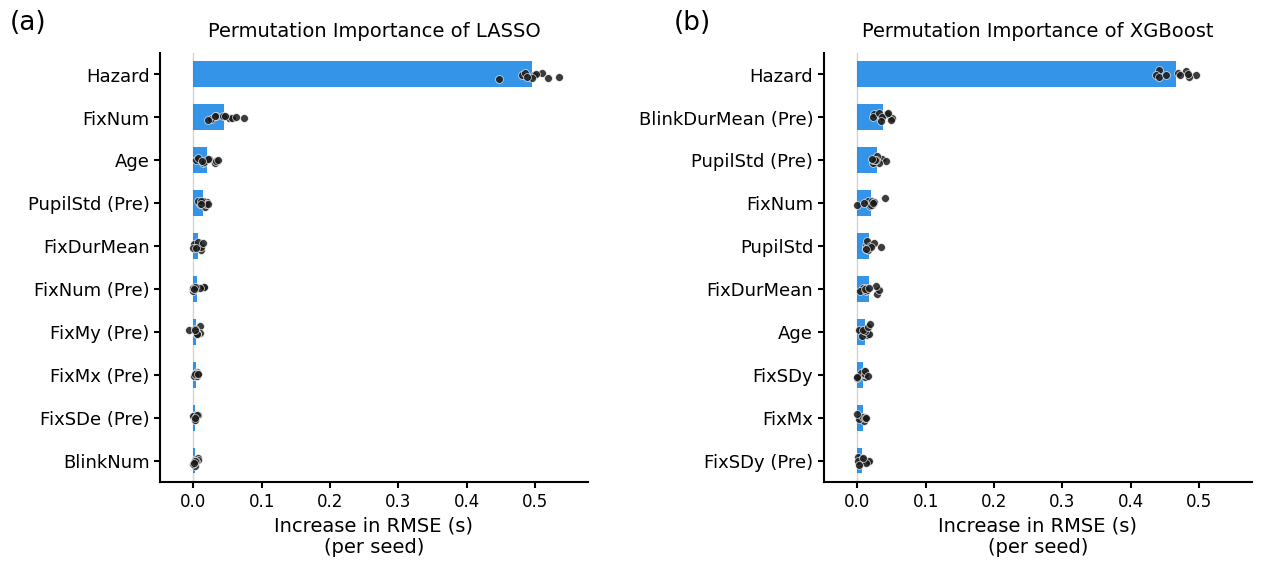

In [ ]:
# =====================================================================
# CROSS-SEED PERMUTATION FEATURE IMPORTANCE (PFI) — REGRESSION
#   Two panels: (left) LASSO combine-TW, (right) XGBoost combine-TW.
#   For each feature, shows the distribution across the 10 seeds of the
#   per-seed PFI (= mean fold-PFI over that seed's 5 outer folds).
#
#   PFI = increase in RMSE when a feature (group) is permuted.
#   GroupKFold, Lasso, XGBRegressor. Self-contained.
# =====================================================================

import os
import re
import json
import glob
import textwrap

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Lasso
from sklearn.model_selection import GroupKFold
from sklearn.metrics import mean_squared_error
from xgboost import XGBRegressor


# =====================================================================
# 0. CONFIG
# =====================================================================
data_path = "/content/drive/MyDrive/Colab_Backups/Data_3sMean_IDT_beforeMat.xlsx"

SELECTED_SEEDS = [
    261, 452, 285, 966, 786,
    1423, 3789, 5602, 8741, 11905,
]

OUTER_SPLITS = 5
CAT_NAMES    = ["Gender", "automation", "eventType"]
TARGET_COL   = "relativeRT"
N_REPEATS    = 10        # PFI permutation repeats per feature per fold
TOP_N        = 10

# LASSO combine-TW
LASSO_BASE_DIR  = "/content/drive/MyDrive/Colab_Backups/LRR"
LASSO_MODEL_DIR = "LR_model_combineTW"
LASSO_TARGET_TW = 20
LASSO_TWS       = [0, 20]

# XGB combine-TW
XGB_BASE_DIR  = "/content/drive/MyDrive/Colab_Backups/XGBR"
XGB_MODEL_DIR = "XGB_model_combineTW"
XGB_TARGET_TW = 21
XGB_TWS       = [0, 21]

# Caching (PFI is expensive)
CACHE_DIR  = "/content/drive/MyDrive/Colab_Backups/crossseed_pfi_cache_reg"
PFI_CACHE  = os.path.join(CACHE_DIR, "pfi_long_reg.parquet")
SAVE_CACHE = True
USE_CACHE  = True


# =====================================================================
# 1. HELPERS
# =====================================================================
NAME_MAP = {
    "Age": "Age", "License": "DrivingExperience", "Mileage": "Mileage",
    "Gender": "Gender", "automation": "Automation", "eventType": "Hazard",
    "visibleSpeed": "VisibleSpeed",
    "pdMean": "PupilMean", "pdSd": "PupilStd",
    "blinkNumber": "BlinkNum", "avgBlinkDuration": "BlinkDurMean",
    "fixNumber": "FixNum", "avgFixDuration": "FixDurMean",
    "fixTE": "FixTEntropy", "fixSE": "FixSEntropy",
    "FixDisperX": "FixSDx", "FixDisperY": "FixSDy", "FixDisperE": "FixSDe",
    "FixMeanPosX": "FixMx", "FixMeanPosY": "FixMy",
}

FEATURE_TEMPLATES = [
    "Age", "License", "Mileage",
    "Gender", "automation", "eventType",
    "visibleSpeed",
    "pdMean_{TW}", "pdSd_{TW}",
    "blinkNumber_{TW}", "avgBlinkDuration_{TW}",
    "fixNumber_{TW}", "avgFixDuration_{TW}",
    "fixTE_{TW}", "fixSE_{TW}",
    "FixDisperX_{TW}", "FixDisperY_{TW}", "FixDisperE_{TW}",
    "FixMeanPosX_{TW}", "FixMeanPosY_{TW}",
]


def build_feature_cols(tws):
    cols = []
    for c in FEATURE_TEMPLATES:
        if "{TW}" in c:
            cols.extend([c.format(TW=tw) for tw in tws])
        else:
            cols.append(c)
    return cols


def clean_feature_name(name):
    if "_" in name:
        prefix, val = name.split("_", 1)
        if prefix in ["Gender", "automation", "eventType"]:
            if prefix == "automation":
                val = {"1": "MD", "2": "PAD"}.get(val, val)
            elif prefix == "Gender":
                val = {"M": "Male", "F": "Female"}.get(val, val)
            elif prefix == "eventType":
                val = {
                    "EVENT_MAT_LEFT_VRU": "Left Pedestrian",
                    "EVENT_MAT_RIGHT_VRU": "Right Pedestrian",
                    "EVENT_MAT_ONCOMING": "Oncoming Vehicle",
                }.get(val, val)
            return f"{NAME_MAP.get(prefix, prefix)} {val}"
    m = re.match(r"(.+?)_(\d+)$", name)
    if m:
        base, tw = m.groups()
        base_clean = NAME_MAP.get(base, base)
        return base_clean if int(tw) == 0 else f"{base_clean} (Pre)"
    return NAME_MAP.get(name, name)


def wrap_labels(label, width=20):
    return "\n".join(textwrap.wrap(label, width))


def fit_outer_onehot(X_train_raw, X_test_raw, cat_cols):
    X_train_raw = X_train_raw.copy()
    X_test_raw = X_test_raw.copy()
    use_cat = [c for c in cat_cols if c in X_train_raw.columns]
    for c in use_cat:
        cats = pd.Index(X_train_raw[c].dropna().unique())
        dtype = pd.CategoricalDtype(categories=cats, ordered=False)
        X_train_raw[c] = X_train_raw[c].astype(dtype)
        X_test_raw[c] = X_test_raw[c].astype(dtype)
    X_tr = pd.get_dummies(X_train_raw, columns=use_cat, drop_first=False)
    X_te = pd.get_dummies(X_test_raw, columns=use_cat, drop_first=False)
    X_te = X_te.reindex(columns=X_tr.columns, fill_value=0)
    return X_tr.astype(np.float32), X_te.astype(np.float32)


def ensure_categorical_dtype_from_train(train_df, test_df, cat_cols):
    train_df = train_df.copy()
    test_df = test_df.copy()
    for col in cat_cols:
        if col in train_df.columns:
            cats = pd.Index(train_df[col].dropna().unique())
            dtype = pd.CategoricalDtype(categories=cats, ordered=False)
            train_df[col] = train_df[col].astype(dtype)
            test_df[col] = test_df[col].astype(dtype)
    return train_df, test_df


def make_groupkfold(n_splits, seed):
    try:
        return GroupKFold(n_splits=n_splits, shuffle=True, random_state=seed)
    except TypeError:
        return GroupKFold(n_splits=n_splits)


def _load_meta(base_dir, model_dir, prefix, seed, tw, outer_fold):
    folder = os.path.join(base_dir, model_dir)
    patterns = [
        f"{prefix}_seed_{seed:02d}_*TW_{tw:02d}_outerfold_{outer_fold:02d}_meta.json",
        f"{prefix}_seed_{seed:02d}_TW_{tw:02d}_outerfold_{outer_fold:02d}_meta.json",
    ]
    candidates = []
    for p in patterns:
        candidates = glob.glob(os.path.join(folder, p))
        if candidates:
            break
    if not candidates:
        raise FileNotFoundError(
            f"No {prefix} metadata for seed={seed}, TW={tw}, fold={outer_fold} in {folder}"
        )
    path = sorted(candidates, key=len)[0]
    with open(path, "r", encoding="utf-8") as f:
        meta = json.load(f)
    return meta["best_params"]


# ---- grouped PFI (RMSE increase) ----
def permute_group(X, cols, rng):
    X_perm = X.copy()
    perm_idx = rng.permutation(X.shape[0])
    original_dtypes = {c: X_perm[c].dtype for c in cols}
    shuffled = X_perm[cols].to_numpy()[perm_idx]
    for j, c in enumerate(cols):
        X_perm[c] = pd.Series(shuffled[:, j], index=X_perm.index).astype(original_dtypes[c])
    return X_perm


def compute_grouped_pfi_reg(model, X_test, y_test, pf_groups, n_repeats, base_seed):
    base_rmse = np.sqrt(mean_squared_error(y_test, model.predict(X_test)))
    out = {}
    for g_idx, (gname, cols) in enumerate(pf_groups.items()):
        scores = []
        for i in range(n_repeats):
            rng = np.random.default_rng(base_seed * 10_000 + g_idx * 100 + i)
            X_perm = permute_group(X_test, cols, rng)
            scores.append(np.sqrt(mean_squared_error(y_test, model.predict(X_perm))))
        out[gname] = np.mean(scores) - base_rmse      # increase in RMSE
    return out


def build_pf_groups(columns, cat_cols):
    cat_dummies = {}
    for cat in cat_cols:
        members = [c for c in columns if c.startswith(cat + "_") or c == cat]
        if members:
            cat_dummies[cat] = members
    flat = {c for cols in cat_dummies.values() for c in cols}
    pf_groups = dict(cat_dummies)
    for c in columns:
        if c not in flat:
            pf_groups[c] = [c]
    return pf_groups


# =====================================================================
# 2. LOAD + FILTER DATA  (regression: continuous target)
# =====================================================================
df = pd.read_excel(data_path)
allowed_events = {"EVENT_MAT_RIGHT_VRU", "EVENT_MAT_LEFT_VRU", "EVENT_MAT_ONCOMING"}
df = df[df["eventType"].isin(allowed_events)].copy()
df[TARGET_COL] = pd.to_numeric(df[TARGET_COL], errors="coerce")
df = df.dropna(subset=[TARGET_COL, "eventType", "subNumber"]).copy()
tww_cols = [f"perValid_{i}" for i in range(31)]
df = df[df[tww_cols].mean(axis=1) >= 74.5].copy()

y = df[TARGET_COL].values.astype(float)
groups = df["subNumber"].values
print(f"Final N = {len(df)}")


# =====================================================================
# 2b. CACHE PROBE
# =====================================================================
_CACHE_HIT = USE_CACHE and os.path.exists(PFI_CACHE)
if _CACHE_HIT:
    pfi_long = pd.read_parquet(PFI_CACHE)
    print("\n[cache] Loaded PFI table from", PFI_CACHE, "-> skipping PFI computation.")


if not _CACHE_HIT:
    # =================================================================
    # 3. COMPUTE PFI for every seed x fold x feature, both models
    # =================================================================
    X_lasso = df[build_feature_cols(LASSO_TWS)].copy()
    X_xgb   = df[build_feature_cols(XGB_TWS)].copy()
    pfi_records = []

    for seed in SELECTED_SEEDS:
        # NOTE: GroupKFold split does not depend on y, so the same cv works for both
        cv = make_groupkfold(OUTER_SPLITS, seed)

        # ----- LASSO -----
        print(f"[LASSO PFI] seed={seed}")
        for outer_fold, (tr, te) in enumerate(cv.split(X_lasso, y, groups), start=1):
            X_tr, X_te = X_lasso.iloc[tr].copy(), X_lasso.iloc[te].copy()
            y_tr, y_te = y[tr], y[te]

            best_params = _load_meta(LASSO_BASE_DIR, LASSO_MODEL_DIR, "lr",
                                     seed, LASSO_TARGET_TW, outer_fold)
            X_tr_oh, X_te_oh = fit_outer_onehot(X_tr, X_te, CAT_NAMES)

            imp = SimpleImputer(strategy="median")
            X_tr_oh = pd.DataFrame(imp.fit_transform(X_tr_oh),
                                   columns=X_tr_oh.columns, index=X_tr_oh.index)
            X_te_oh = pd.DataFrame(imp.transform(X_te_oh),
                                   columns=X_te_oh.columns, index=X_te_oh.index)
            sc = StandardScaler()
            X_tr_oh = pd.DataFrame(sc.fit_transform(X_tr_oh),
                                   columns=X_tr_oh.columns, index=X_tr_oh.index)
            X_te_oh = pd.DataFrame(sc.transform(X_te_oh),
                                   columns=X_te_oh.columns, index=X_te_oh.index)

            model = Lasso(**best_params)
            model.fit(X_tr_oh, y_tr)

            pf_groups = build_pf_groups(list(X_te_oh.columns), CAT_NAMES)
            pfi = compute_grouped_pfi_reg(model, X_te_oh, y_te, pf_groups,
                                          n_repeats=N_REPEATS,
                                          base_seed=seed * 100 + outer_fold)
            for feat, v in pfi.items():
                pfi_records.append({"model": "LASSO", "seed": seed,
                                    "fold": outer_fold, "feature": feat, "pfi": v})

        # ----- XGB -----
        print(f"[XGB PFI]   seed={seed}")
        for outer_fold, (tr, te) in enumerate(cv.split(X_xgb, y, groups), start=1):
            X_tr, X_te = X_xgb.iloc[tr].copy(), X_xgb.iloc[te].copy()
            y_tr, y_te = y[tr], y[te]

            best_params = _load_meta(XGB_BASE_DIR, XGB_MODEL_DIR, "xgb",
                                     seed, XGB_TARGET_TW, outer_fold)
            X_tr_proc, X_te_proc = ensure_categorical_dtype_from_train(X_tr, X_te, CAT_NAMES)

            model = XGBRegressor(**best_params)
            model.fit(X_tr_proc, y_tr, verbose=False)

            pf_groups = build_pf_groups(list(X_te_proc.columns), CAT_NAMES)
            pfi = compute_grouped_pfi_reg(model, X_te_proc, y_te, pf_groups,
                                          n_repeats=N_REPEATS,
                                          base_seed=seed * 100 + outer_fold)
            for feat, v in pfi.items():
                pfi_records.append({"model": "XGB", "seed": seed,
                                    "fold": outer_fold, "feature": feat, "pfi": v})

    pfi_fold_long = pd.DataFrame(pfi_records)

    # collapse folds -> one PFI per (model, seed, feature)
    pfi_long = (
        pfi_fold_long.groupby(["model", "seed", "feature"], as_index=False)
        .agg(pfi=("pfi", "mean"))
    )

    print("\npfi_long (per seed):", pfi_long.shape)

    if SAVE_CACHE:
        try:
            os.makedirs(CACHE_DIR, exist_ok=True)
            pfi_long.to_parquet(PFI_CACHE)
            print(f"Cached PFI table saved to {PFI_CACHE}")
        except Exception as e:
            print(f"[warn] cache save skipped: {e}")


# =====================================================================
# 4. PLOT — two panels, cross-seed PFI distribution per feature
# =====================================================================
DOT_COLOR, DOT_SIZE, DOT_ALPHA = "#1A1A1A", 32, 0.85
BAR_FACE = "#1E88E5"
BAR_HEIGHT = 0.6
FS_XLAB, FS_XTICK, FS_Y = 14, 12, 13
PANEL_FS, SPINE_W = 19, 1.5
N_SEEDS = len(SELECTED_SEEDS)
rng = np.random.default_rng(42)


def _top_feats(model_type):
    mean_by_feat = (pfi_long[pfi_long["model"] == model_type]
                    .groupby("feature")["pfi"].mean().sort_values(ascending=False))
    return mean_by_feat.head(TOP_N).index.tolist()

# shared x-range across both panels
xmin, xmax = 0.0, 0.0
for mt in ["LASSO", "XGB"]:
    feats = _top_feats(mt)
    vals = pfi_long[(pfi_long["model"] == mt) & (pfi_long["feature"].isin(feats))]["pfi"].values
    if len(vals):
        xmin = min(xmin, vals.min())
        xmax = max(xmax, vals.max())
pad = (xmax - xmin) * 0.08
xmin -= pad
xmax += pad

fig, axes = plt.subplots(1, 2, figsize=(13, 5.8))

for ax_i, model_type in enumerate(["LASSO", "XGB"]):
    ax = axes[ax_i]
    feats = _top_feats(model_type)
    feats_plot = feats[::-1]
    labels = [clean_feature_name(f) for f in feats_plot]
    n = len(feats_plot)

    for i, feat in enumerate(feats_plot):
        vals = pfi_long[(pfi_long["model"] == model_type) &
                        (pfi_long["feature"] == feat)]["pfi"].values
        if len(vals) == 0:
            continue
        ax.barh(i, np.mean(vals), color=BAR_FACE, edgecolor="none",
                height=BAR_HEIGHT, alpha=0.9, zorder=2)
        ax.scatter(vals, rng.normal(i, 0.06, size=len(vals)),
                   color=DOT_COLOR, s=DOT_SIZE, alpha=DOT_ALPHA,
                   edgecolor="white", linewidth=0.5, zorder=5)

    ax.axvline(0, color="lightgray", linewidth=1.0, zorder=0)
    ax.set_yticks(range(n))
    ax.set_yticklabels([wrap_labels(l) for l in labels], fontsize=FS_Y)
    ax.set_xlabel("Increase in RMSE (s)\n(per seed)", fontsize=FS_XLAB)
    ax.set_xlim(xmin, xmax)
    ax.set_ylim(-0.5, n - 0.5)
    ax.xaxis.set_major_locator(MultipleLocator(0.1))
    ax.set_title("Permutation Importance of "
                 + ("LASSO" if model_type == "LASSO" else "XGBoost"),
                 fontsize=FS_XLAB, pad=12)

for ax in axes:
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.grid(False)
    for spine in ax.spines.values():
        if spine.get_visible():
            spine.set_linewidth(SPINE_W)
            spine.set_edgecolor("black")
    ax.tick_params(axis="x", labelsize=FS_XTICK, length=4, width=SPINE_W,
                   colors="black", direction="out", bottom=True, top=False)
    ax.tick_params(axis="y", labelsize=FS_Y, length=4, width=SPINE_W,
                   colors="black", direction="out", left=True, right=False,
                   labelleft=True)

for ax, lab in [(axes[0], "(a)"), (axes[1], "(b)")]:
    ax.text(-0.35, 1.04, lab, transform=ax.transAxes,
            ha="left", va="bottom", fontsize=PANEL_FS)

plt.subplots_adjust(left=0.14, right=0.98, top=0.90, bottom=0.16, wspace=0.55)
plt.show()

Final N = 351
Class counts for 'pdSd_11' are not meaningful, but here's missing values check:
0


/tmp/ipykernel_520/812166806.py:75: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


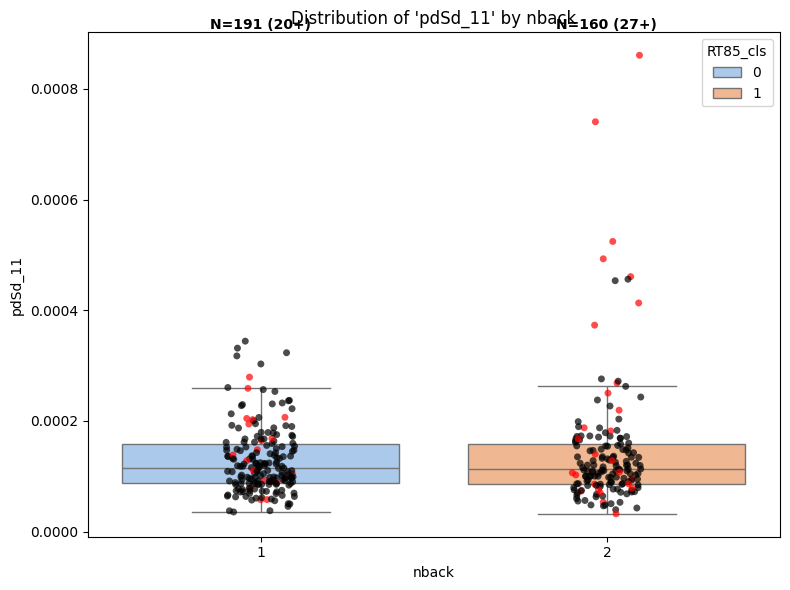

In [ ]:
# =========================================================
# IMPORTS
# =========================================================
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# =========================================================
# SETTINGS
# =========================================================
data_path = "/content/drive/MyDrive/Colab_Backups/Data_3sMean_IDT_beforeMat.xlsx"
target_plot = "pdSd_11"  # <-- Customize this to any variable you want
min_valid_percent = 74.5

# =========================================================
# LOAD DATA
# =========================================================
df = pd.read_excel(data_path)
target_col = 'relativeRT'
df[target_col] = pd.to_numeric(df[target_col], errors="coerce")
df = df.dropna(subset=[target_col, "eventType", "subNumber"]).copy()
df["rt85_by_event"] = df.groupby("eventType")[target_col].transform(lambda x: x.quantile(0.85))
df["RT85_cls"] = (df[target_col] >= df["rt85_by_event"]).astype(int)

# =========================================================
# FILTER AND PREPROCESS
# =========================================================
# Keep only allowed event types
allowed_events = {
    "EVENT_MAT_RIGHT_VRU",
    "EVENT_MAT_LEFT_VRU",
    "EVENT_MAT_ONCOMING"
}
unexpected = set(df["eventType"].dropna().unique()) - allowed_events
if unexpected:
    raise ValueError(f"Unexpected eventType(s): {unexpected}")

# Ensure numeric target variable exists
if target_plot not in df.columns:
    raise ValueError(f"Variable '{target_plot}' not found in the data!")

# Drop rows with missing critical values
critical_cols = ["eventType", "subNumber", target_plot]
df = df.dropna(subset=critical_cols).copy()

# Filter by valid trials per time window (perValid_0 to perValid_30)
tww_cols = [f"perValid_{i}" for i in range(31)]
df = df[df[tww_cols].mean(axis=1) >= min_valid_percent].copy()

# Make sure 'nback' exists
if 'nback' not in df.columns:
    df['nback'] = df['2-back'] if '2-back' in df.columns else 0  # fallback

# Print summary
print(f"Final N = {len(df)}")
print(f"Class counts for '{target_plot}' are not meaningful, but here's missing values check:")
print(df[target_plot].isna().sum())

# =========================================================
# PLOT BOXPLOTS WITH DATAPOINTS AND SAMPLE SIZES
# =========================================================

df['highlight'] = df['RT85_cls'] if 'RT85_cls' in df.columns else 0

# Count total and RT positive per nback group
nback_counts = df.groupby('nback')[target_plot].count()
nback_pos = df.groupby('nback')['highlight'].sum()  # number of RT85_cls==1

# Set up the figure
plt.figure(figsize=(8,6))

# Boxplot (neutral colors)
sns.boxplot(
    x='nback',
    y=target_plot,
    data=df,
    palette='pastel',
    showfliers=False
)

# Overlay datapoints with highlight
sns.stripplot(
    x='nback',
    y=target_plot,
    data=df,
    hue='highlight',  # RT85_cls determines color
    palette={0: 'black', 1: 'red'},  # RT85_cls==1 -> red
    size=5,
    jitter=True,
    alpha=0.7,
    dodge=False
)

# Show number of points above each box with number of positives
y_max = df[target_plot].max()
y_range = df[target_plot].max() - df[target_plot].min()
for i in range(len(nback_counts)):
    n_total = nback_counts.iloc[i]
    n_pos = int(nback_pos.iloc[i])
    plt.text(i, y_max + 0.05*y_range, f"N={n_total} ({n_pos}+)",
             ha='center', va='bottom', fontsize=10, fontweight='bold')

# plt.title(f"Distribution of '{target_plot}' by nback")
plt.xlabel("nback")
plt.ylabel(target_plot)

# Optional: hide legend title for cleaner look
plt.legend(title='RT85_cls', loc='upper right', labels=['0','1'])

plt.tight_layout()
plt.show()

# T-test

## Classifier

In [ ]:
import pandas as pd
from scipy.stats import ttest_rel
from itertools import combinations
from statsmodels.stats.anova import AnovaRM
from statsmodels.stats.multitest import multipletests

# =========================================================
# 1. Define target conditions
# =========================================================
selected_seeds = [
    3558, 6687, 6836, 7862, 11033,
    13285, 22075, 22163, 23858,30690
]

# XGB combined, TW = 13
df1_sub = df1[
    (df1["outer_fold"].astype(str) == "SUMMARY") &
    (df1["TW"] == 13) &
    (df1["seed"].isin(selected_seeds))
][["seed", "AUC"]].copy()

df1_sub = df1_sub.rename(columns={"AUC": "XGB_combined_TW13"})


# XGB single, TW = 13
df2_sub = df2[
    (df2["outer_fold"].astype(str) == "SUMMARY") &
    (df2["TW"] == 13) &
    (df2["seed"].isin(selected_seeds))
][["seed", "AUC"]].copy()

df2_sub = df2_sub.rename(columns={"AUC": "XGB_single_TW13"})


# LASSO combined, TW = 11
df3_sub = df3[
    (df3["outer_fold"].astype(str) == "SUMMARY") &
    (df3["TW"] == 11) &
    (df3["seed"].isin(selected_seeds))
][["seed", "AUC"]].copy()

df3_sub = df3_sub.rename(columns={"AUC": "LASSO_combined_TW11"})


# LASSO single, TW = 11
df4_sub = df4[
    (df4["outer_fold"].astype(str) == "SUMMARY") &
    (df4["TW"] == 11) &
    (df4["seed"].isin(selected_seeds))
][["seed", "AUC"]].copy()

df4_sub = df4_sub.rename(columns={"AUC": "LASSO_single_TW11"})


# =========================================================
# 2. Merge by seed
# =========================================================
merged = (
    df1_sub
    .merge(df2_sub, on="seed", how="inner")
    .merge(df3_sub, on="seed", how="inner")
    .merge(df4_sub, on="seed", how="inner")
)

auc_cols = [
    "XGB_combined_TW13",
    "XGB_single_TW13",
    "LASSO_combined_TW11",
    "LASSO_single_TW11"
]

for col in auc_cols:
    merged[col] = pd.to_numeric(merged[col], errors="coerce")

merged = merged.dropna(subset=auc_cols)

print("Paired data:")
print(merged)
print("\nNumber of paired seeds:", len(merged))


# =========================================================
# 3. Descriptive statistics
# =========================================================
print("\nDescriptive statistics:")
print(merged[auc_cols].describe().T)


# =========================================================
# 4. Repeated-measures ANOVA
# =========================================================
long_df = merged.melt(
    id_vars="seed",
    value_vars=auc_cols,
    var_name="condition",
    value_name="AUC"
)

long_df["condition"] = long_df["condition"].replace({
    "XGB_combined_TW13": "XGB (Combined TW)",
    "XGB_single_TW13": "XGB (Single TW)",
    "LASSO_combined_TW11": "LASSO (Combined TW)",
    "LASSO_single_TW11": "LASSO (Single TW)"
})

anova = AnovaRM(
    data=long_df,
    depvar="AUC",
    subject="seed",
    within=["condition"]
)

anova_result = anova.fit()

print("\nRepeated-measures ANOVA:")
print(anova_result)


# =========================================================
# 5. Post-hoc paired t-tests
# =========================================================
pairs = []
t_values = []
p_values = []
mean_diffs = []
effect_sizes = []

for c1, c2 in combinations(auc_cols, 2):
    t_stat, p_val = ttest_rel(merged[c1], merged[c2])

    diff = merged[c1] - merged[c2]
    mean_diff = diff.mean()
    sd_diff = diff.std(ddof=1)

    # Cohen's d (paired)
    d = mean_diff / sd_diff if sd_diff != 0 else 0

    pairs.append(f"{c1} vs {c2}")
    t_values.append(t_stat)
    p_values.append(p_val)
    mean_diffs.append(mean_diff)
    effect_sizes.append(d)

reject, p_corrected, _, _ = multipletests(
    p_values,
    method="bonferroni"
)

posthoc_df = pd.DataFrame({
    "comparison": pairs,
    "mean_difference": mean_diffs,
    "t": t_values,
    "cohens_d": effect_sizes,
    "p_raw": p_values,
    "p_bonferroni": p_corrected,
    "significant_bonferroni": reject
})

print("\nPost-hoc paired t-tests:")
print(posthoc_df)

Paired data:
    seed  XGB_combined_TW13  XGB_single_TW13  LASSO_combined_TW11  \
0   3558           0.686537         0.683158             0.692405   
1   6687           0.688507         0.606297             0.711169   
2   6836           0.760621         0.647978             0.701927   
3   7862           0.667900         0.643901             0.706558   
4  11033           0.772889         0.685118             0.698163   
5  13285           0.738380         0.570393             0.740375   
6  22075           0.680777         0.637163             0.637279   
7  22163           0.737322         0.653924             0.698971   
8  23858           0.722236         0.642394             0.690021   
9  30690           0.693755         0.612469             0.750391   

   LASSO_single_TW11  
0           0.711270  
1           0.736621  
2           0.738987  
3           0.681996  
4           0.707931  
5           0.731700  
6           0.699093  
7           0.733128  
8           0.698368

## Regressor

In [ ]:
import pandas as pd
from scipy.stats import ttest_rel
from itertools import combinations
from statsmodels.stats.anova import AnovaRM
from statsmodels.stats.multitest import multipletests

# =========================================================
# 1. Define target conditions
# =========================================================
selected_seeds = [
   261,452,285,966,786, 1423,3789, 5602, 8741, 11905
]
metric = "RMSE"

df1_sub = df1[
    (df1["outer_fold"].astype(str) == "SUMMARY") &
    (df1["TW"] == 21) &
    (df1["seed"].isin(selected_seeds))
][["seed", metric]].copy()

df1_sub = df1_sub.rename(columns={metric: "XGB_combined_TW21"})

df2_sub = df2[
    (df2["outer_fold"].astype(str) == "SUMMARY") &
    (df2["TW"] == 21) &
    (df2["seed"].isin(selected_seeds))
][["seed", metric]].copy()

df2_sub = df2_sub.rename(columns={metric: "XGB_single_TW21"})

df3_sub = df3[
    (df3["outer_fold"].astype(str) == "SUMMARY") &
    (df3["TW"] == 20) &
    (df3["seed"].isin(selected_seeds))
][["seed", metric]].copy()

df3_sub = df3_sub.rename(columns={metric: "LASSO_combined_TW20"})

# LASSO single, TW = 11
df4_sub = df4[
    (df4["outer_fold"].astype(str) == "SUMMARY") &
    (df4["TW"] == 19) &
    (df4["seed"].isin(selected_seeds))
][["seed", metric]].copy()

df4_sub = df4_sub.rename(columns={metric: "LASSO_single_TW19"})

# =========================================================
# 2. Merge by seed to ensure paired comparison
# =========================================================
merged = (
    df1_sub
    .merge(df2_sub, on="seed", how="inner")
    .merge(df3_sub, on="seed", how="inner")
    .merge(df4_sub, on="seed", how="inner")
)

rmse_cols = [
    "XGB_combined_TW21",
    "XGB_single_TW21",
    "LASSO_combined_TW20",
    "LASSO_single_TW19"
]

for col in rmse_cols:
    merged[col] = pd.to_numeric(merged[col], errors="coerce")

merged = merged.dropna(subset=rmse_cols)

print("Paired data:")
print(merged)
print("\nNumber of paired seeds:", len(merged))

# =========================================================
# 3. Descriptive statistics
# =========================================================
print("\nDescriptive statistics:")
print(merged[rmse_cols].describe().T)

# =========================================================
# 4. Repeated-measures ANOVA
# =========================================================
long_df = merged.melt(
    id_vars="seed",
    value_vars=rmse_cols,
    var_name="condition",
    value_name="RMSE"
)

anova = AnovaRM(
    data=long_df,
    depvar="RMSE",
    subject="seed",
    within=["condition"]
)

anova_result = anova.fit()

print("\nRepeated-measures ANOVA:")
print(anova_result)

# =========================================================
# 5. Post-hoc paired t-tests
# =========================================================
pairs = []
t_values = []
p_values = []
mean_diffs = []

for c1, c2 in combinations(rmse_cols, 2):
    t_stat, p_val = ttest_rel(merged[c1], merged[c2])

    diff = merged[c1] - merged[c2]
    mean_diff = diff.mean()

    pairs.append(f"{c1} vs {c2}")
    t_values.append(t_stat)
    p_values.append(p_val)
    mean_diffs.append(mean_diff)

reject, p_corrected, _, _ = multipletests(p_values, method="bonferroni")

posthoc_df = pd.DataFrame({
    "comparison": pairs,
    "mean_difference_RMSE": mean_diffs,
    "t": t_values,
    "p_raw": p_values,
    "p_bonferroni": p_corrected,
    "significant_bonferroni": reject
})

print("\nPost-hoc paired t-tests:")
print(posthoc_df)

# =========================================================
# 6. Optional: save results
# =========================================================
# merged.to_excel(
#     "/content/drive/MyDrive/Colab_Backups/model_comparison_paired_data_RMSE.xlsx",
#     index=False
# )

# posthoc_df.to_excel(
#     "/content/drive/MyDrive/Colab_Backups/model_comparison_posthoc_tests_RMSE.xlsx",
#     index=False
# )

Paired data:
    seed  XGB_combined_TW21  XGB_single_TW21  LASSO_combined_TW20  \
0    261           0.858686         0.907429             0.879770   
1    452           0.838741         0.881215             0.866032   
2    285           0.862936         0.876109             0.864159   
3    966           0.868407         0.899654             0.883741   
4    786           0.842663         0.891760             0.888407   
5   1423           0.852019         0.860068             0.859479   
6   3789           0.818345         0.869701             0.843378   
7   5602           0.867467         0.921271             0.865206   
8   8741           0.847717         0.877173             0.881900   
9  11905           0.849887         0.889493             0.859256   

   LASSO_single_TW19  
0           0.884881  
1           0.877869  
2           0.864884  
3           0.895288  
4           0.894732  
5           0.875530  
6           0.871935  
7           0.875882  
8           0.890336

# Visualize Lambda Selection of LASSO

Number of files read:
folder
singleTW     1550
combineTW    1500
Name: count, dtype: int64 

Preview:
     folder                                        file   seed  TW  \
0  singleTW  lr_seed_22075_TW_24_outerfold_01_meta.json  22075  24   
1  singleTW  lr_seed_22075_TW_24_outerfold_02_meta.json  22075  24   
2  singleTW  lr_seed_22075_TW_24_outerfold_03_meta.json  22075  24   
3  singleTW  lr_seed_22075_TW_24_outerfold_04_meta.json  22075  24   
4  singleTW  lr_seed_22075_TW_24_outerfold_05_meta.json  22075  24   

   outer_fold         C  
0           1  0.238061  
1           2  0.056893  
2           3  0.166521  
3           4  0.053399  
4           5  0.064696   



/tmp/ipykernel_66267/337468968.py:75: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


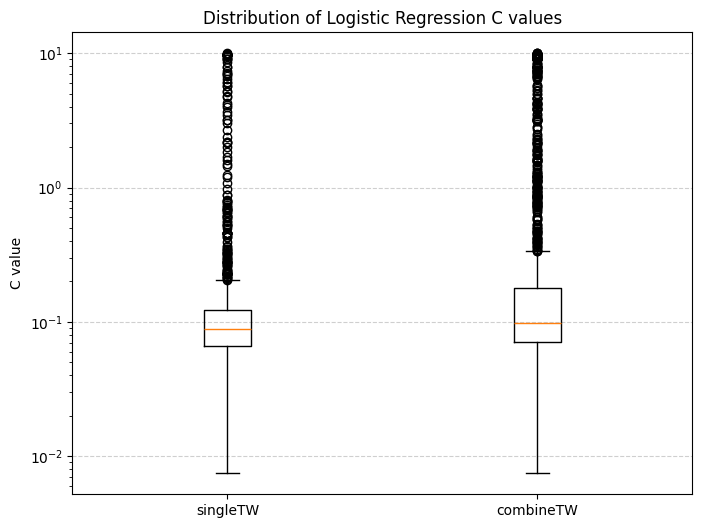

Summary statistics:
            count      mean       std       min       25%       50%       75%  \
folder                                                                          
combineTW  1500.0  0.810863  2.134109  0.007459  0.071267  0.098467  0.177640   
singleTW   1550.0  0.322955  1.249681  0.007459  0.065666  0.088999  0.121473   

                max  
folder               
combineTW  9.964550  
singleTW   9.983741  


In [ ]:
import os
import json
import pandas as pd
import matplotlib.pyplot as plt

# =========================
# Paths
# =========================
single_path = "/content/drive/MyDrive/Colab_Backups/LR_test/LRC_model_singleTW"
combine_path = "/content/drive/MyDrive/Colab_Backups/LR/LRC_model_combineTW"

# =========================
# Function to extract C values
# =========================
def extract_c_values(folder_path, folder_label):
    records = []

    for root, _, files in os.walk(folder_path):
        for file in files:
            if file.endswith(".json"):   # use ".jason" if your files really have that extension
                file_path = os.path.join(root, file)

                try:
                    with open(file_path, "r", encoding="utf-8") as f:
                        data = json.load(f)

                    c_value = data.get("best_params", {}).get("C", None)

                    if c_value is not None:
                        records.append({
                            "folder": folder_label,
                            "file": file,
                            "seed": data.get("seed", None),
                            "TW": data.get("TW", None),
                            "outer_fold": data.get("outer_fold", None),
                            "C": c_value
                        })

                except Exception as e:
                    print(f"Error reading {file_path}: {e}")

    return pd.DataFrame(records)

# =========================
# Read both folders
# =========================
df_single = extract_c_values(single_path, "singleTW")
df_combine = extract_c_values(combine_path, "combineTW")

# Combine into one dataframe
df_c = pd.concat([df_single, df_combine], ignore_index=True)

# =========================
# Check extracted data
# =========================
print("Number of files read:")
print(df_c["folder"].value_counts(), "\n")

print("Preview:")
print(df_c.head(), "\n")

# =========================
# Box plot
# =========================
plt.figure(figsize=(8, 6))

data_to_plot = [
    df_c.loc[df_c["folder"] == "singleTW", "C"].dropna(),
    df_c.loc[df_c["folder"] == "combineTW", "C"].dropna()
]

plt.boxplot(
    data_to_plot,
    labels=["singleTW", "combineTW"],
    patch_artist=False
)

plt.ylabel("C value")
plt.title("Distribution of Logistic Regression C values")
plt.yscale("log")  # recommended because C usually spans orders of magnitude
plt.grid(True, axis="y", linestyle="--", alpha=0.6)
plt.show()

# =========================
# Optional summary stats
# =========================
summary = df_c.groupby("folder")["C"].describe()
print("Summary statistics:")
print(summary)


Number of files read:
folder
singleTW     310
combineTW    223
Name: count, dtype: int64 

Preview:
     folder                                       file  seed  TW  outer_fold  \
0  singleTW  lr_seed_3558_TW_00_outerfold_01_meta.json  3558   0           1   
1  singleTW  lr_seed_3558_TW_00_outerfold_02_meta.json  3558   0           2   
2  singleTW  lr_seed_3558_TW_00_outerfold_03_meta.json  3558   0           3   
3  singleTW  lr_seed_3558_TW_00_outerfold_04_meta.json  3558   0           4   
4  singleTW  lr_seed_3558_TW_00_outerfold_05_meta.json  3558   0           5   

          C  l1_ratio  
0  9.438388  0.109571  
1  0.086652  0.862327  
2  0.153711  0.162601  
3  0.601885  0.437131  
4  0.045124  0.521511   



/tmp/ipykernel_1478/3407194284.py:81: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


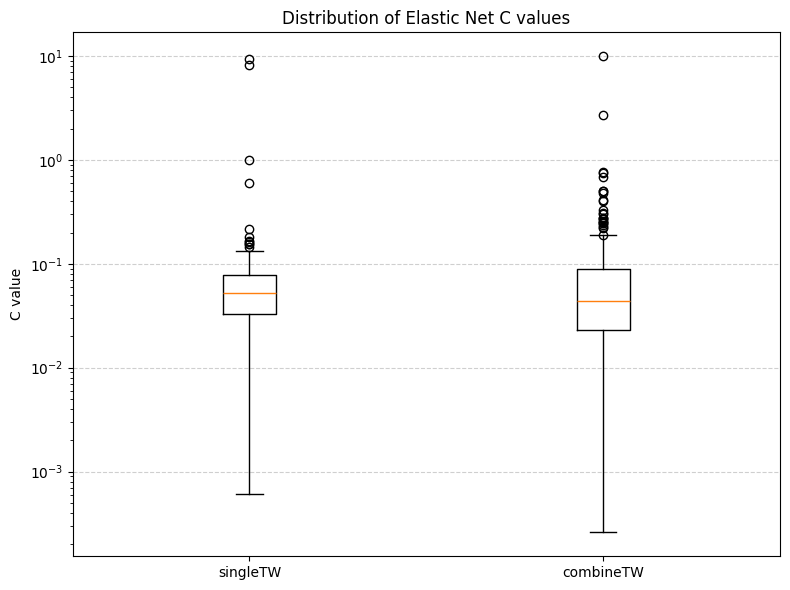

/tmp/ipykernel_1478/3407194284.py:104: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


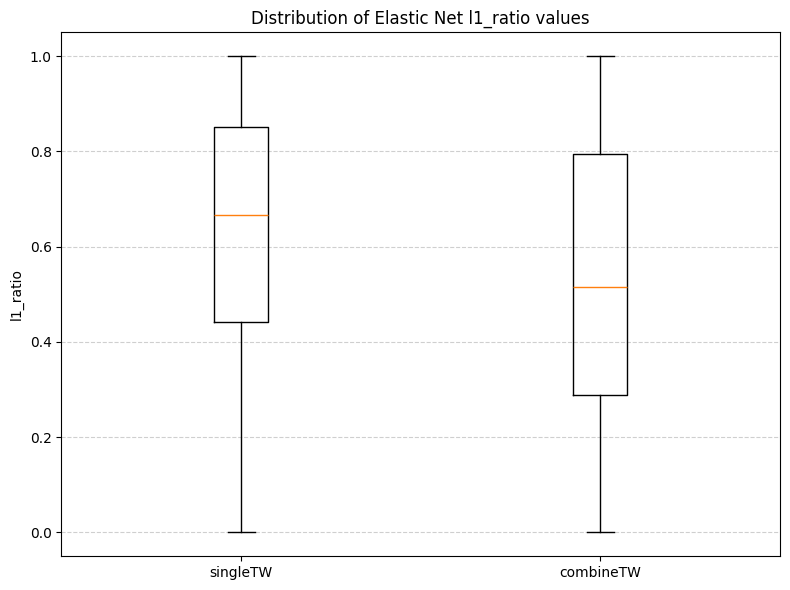

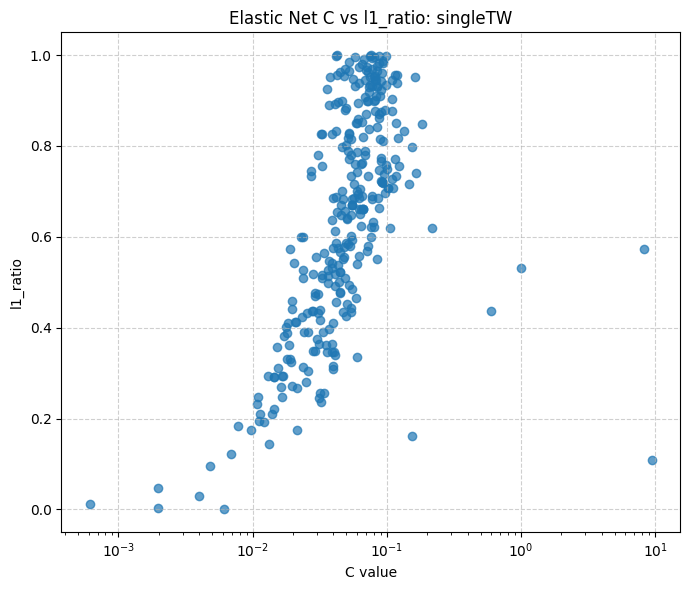

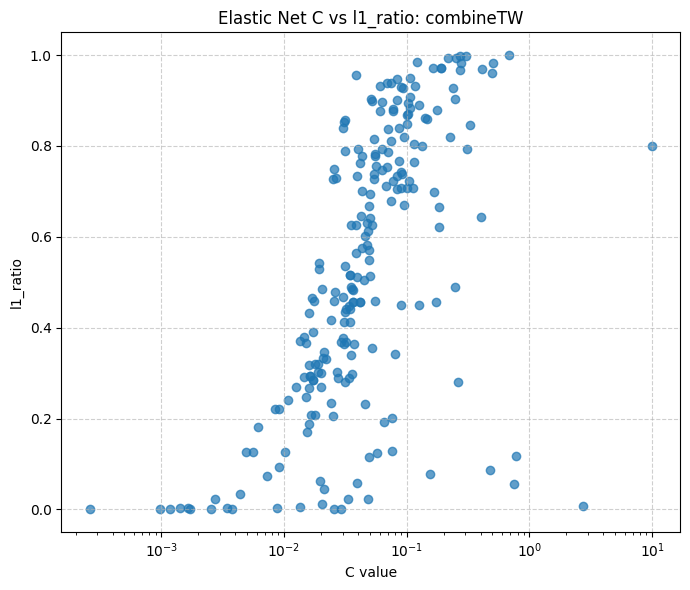

Summary statistics:
               C                                                              \
           count      mean       std       min       25%       50%       75%   
folder                                                                         
combineTW  223.0  0.138794  0.693670  0.000260  0.022965  0.043582  0.089755   
singleTW   310.0  0.117971  0.707639  0.000608  0.032837  0.052198  0.077546   

                    l1_ratio                                          \
                max    count      mean       std       min       25%   
folder                                                                 
combineTW  9.958623    223.0  0.527215  0.306041  0.000147  0.288678   
singleTW   9.438388    310.0  0.637694  0.248740  0.001057  0.441758   

                                         
                50%       75%       max  
folder                                   
combineTW  0.516095  0.793633  0.999922  
singleTW   0.666269  0.851213  0.999807  


In [ ]:
import os
import json
import pandas as pd
import matplotlib.pyplot as plt

# =========================
# Paths
# =========================
single_path = "/content/drive/MyDrive/Colab_Backups/LR_other/LRC_model_singleTW_EL"
combine_path = "/content/drive/MyDrive/Colab_Backups/LR_other/LRC_model_combineTW_EL"

# =========================
# Function to extract Elastic Net parameters
# =========================
def extract_elasticnet_values(folder_path, folder_label):
    records = []

    for root, _, files in os.walk(folder_path):
        for file in files:
            if file.endswith(".json"):
                file_path = os.path.join(root, file)

                try:
                    with open(file_path, "r", encoding="utf-8") as f:
                        data = json.load(f)

                    best_params = data.get("best_params", {})

                    c_value = best_params.get("C", None)
                    l1_ratio = best_params.get("l1_ratio", None)

                    if c_value is not None and l1_ratio is not None:
                        records.append({
                            "folder": folder_label,
                            "file": file,
                            "seed": data.get("seed", None),
                            "TW": data.get("TW", None),
                            "outer_fold": data.get("outer_fold", None),
                            "C": c_value,
                            "l1_ratio": l1_ratio
                        })

                except Exception as e:
                    print(f"Error reading {file_path}: {e}")

    return pd.DataFrame(records)

# =========================
# Read both folders
# =========================
df_single = extract_elasticnet_values(single_path, "singleTW")
df_combine = extract_elasticnet_values(combine_path, "combineTW")

df_el = pd.concat([df_single, df_combine], ignore_index=True)

# =========================
# Check extracted data
# =========================
print("Number of files read:")
print(df_el["folder"].value_counts(), "\n")

print("Preview:")
print(df_el.head(), "\n")

# Optional save
df_el.to_excel(
    "/content/drive/MyDrive/Colab_Backups/LR_other/extracted_elasticnet_params.xlsx",
    index=False
)

# =========================
# Figure 1: C distribution
# =========================
plt.figure(figsize=(8, 6))

data_to_plot = [
    df_el.loc[df_el["folder"] == "singleTW", "C"].dropna(),
    df_el.loc[df_el["folder"] == "combineTW", "C"].dropna()
]

plt.boxplot(
    data_to_plot,
    labels=["singleTW", "combineTW"],
    patch_artist=False
)

plt.ylabel("C value")
plt.title("Distribution of Elastic Net C values")
plt.yscale("log")
plt.grid(True, axis="y", linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()

# =========================
# Figure 2: l1_ratio distribution
# =========================
plt.figure(figsize=(8, 6))

data_to_plot = [
    df_el.loc[df_el["folder"] == "singleTW", "l1_ratio"].dropna(),
    df_el.loc[df_el["folder"] == "combineTW", "l1_ratio"].dropna()
]

plt.boxplot(
    data_to_plot,
    labels=["singleTW", "combineTW"],
    patch_artist=False
)

plt.ylabel("l1_ratio")
plt.title("Distribution of Elastic Net l1_ratio values")
plt.ylim(-0.05, 1.05)
plt.grid(True, axis="y", linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()

# =========================
# Figure 3: C vs l1_ratio, singleTW
# =========================
temp = df_el[df_el["folder"] == "singleTW"]

plt.figure(figsize=(7, 6))
plt.scatter(temp["C"], temp["l1_ratio"], alpha=0.7)

plt.xscale("log")
plt.xlabel("C value")
plt.ylabel("l1_ratio")
plt.title("Elastic Net C vs l1_ratio: singleTW")
plt.ylim(-0.05, 1.05)
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()

# =========================
# Figure 4: C vs l1_ratio, combineTW
# =========================
temp = df_el[df_el["folder"] == "combineTW"]

plt.figure(figsize=(7, 6))
plt.scatter(temp["C"], temp["l1_ratio"], alpha=0.7)

plt.xscale("log")
plt.xlabel("C value")
plt.ylabel("l1_ratio")
plt.title("Elastic Net C vs l1_ratio: combineTW")
plt.ylim(-0.05, 1.05)
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()

# =========================
# Summary statistics
# =========================
summary = df_el.groupby("folder")[["C", "l1_ratio"]].describe()

print("Summary statistics:")
print(summary)

# Flow Chart

In [ ]:
df_el.head()

""


# LASSO Regressor

[0, 20]


[I 2026-04-25 10:08:06,398] A new study created in memory with name: no-name-0ce62fe7-fea1-4953-8d9f-07cd4528dbf4
[I 2026-04-25 10:08:06,463] Trial 0 finished with value: 0.9097760907889243 and parameters: {'alpha': 0.0074593432857265485}. Best is trial 0 with value: 0.9097760907889243.
[I 2026-04-25 10:08:06,524] Trial 1 finished with value: 1.2075868619859156 and parameters: {'alpha': 5.669849511478847}. Best is trial 0 with value: 0.9097760907889243.


Running rs=261, targetTW=20
len(df)=351

=== Outer fold 1/5 ===
Fold 1 - Gender levels in train: ['F' 'M']
Fold 1 - automation levels in train: [1 2]
Fold 1 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-04-25 10:08:06,583] Trial 2 finished with value: 1.0328444800013992 and parameters: {'alpha': 0.4570563099801455}. Best is trial 0 with value: 0.9097760907889243.
[I 2026-04-25 10:08:06,641] Trial 3 finished with value: 0.9253335610211176 and parameters: {'alpha': 0.09846738873614563}. Best is trial 0 with value: 0.9097760907889243.
[I 2026-04-25 10:08:06,741] Trial 4 finished with value: 0.9376392129412215 and parameters: {'alpha': 0.0006026889128682511}. Best is trial 0 with value: 0.9097760907889243.
[I 2026-04-25 10:08:06,840] Trial 5 finished with value: 0.9376402281364071 and parameters: {'alpha': 0.000602521573620386}. Best is trial 0 with value: 0.9097760907889243.
[I 2026-04-25 10:08:07,037] Trial 6 finished with value: 0.9399960644697948 and parameters: {'alpha': 0.00019517224641449495}. Best is trial 0 with value: 0.9097760907889243.
[I 2026-04-25 10:08:07,098] Trial 7 finished with value: 1.2075868619859156 and parameters: {'alpha': 2.1423021757741068}. Best is tria

/content/drive/MyDrive/Colab_Backups/Data_3sMean_IDT_beforeMat.xlsx | Outer fold 1/5 RMSE = 0.7036 R2 = 0.2048


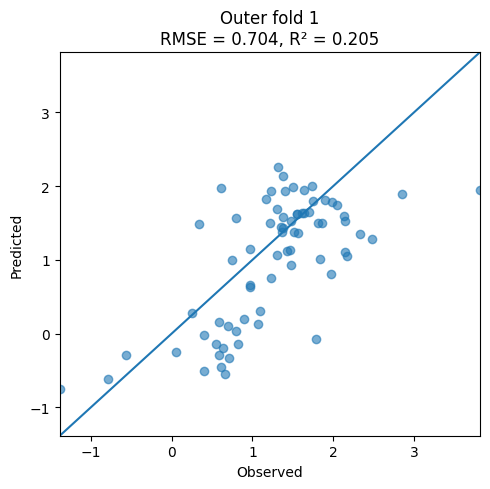

Saved model: /content/drive/MyDrive/Colab_Backups/LRR_test/LR_model_combineTW/lr_seed_261_TW_20_outerfold_01.joblib
Saved metadata: /content/drive/MyDrive/Colab_Backups/LRR_test/LR_model_combineTW/lr_seed_261_TW_20_outerfold_01_meta.json

=== Outer fold 2/5 ===
Fold 2 - Gender levels in train: ['M' 'F']
Fold 2 - automation levels in train: [1 2]
Fold 2 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-04-25 10:08:15,111] A new study created in memory with name: no-name-2d5d7d58-0ed6-49db-9257-f120662ad016
[I 2026-04-25 10:08:15,183] Trial 0 finished with value: 0.9056171471271185 and parameters: {'alpha': 0.0074593432857265485}. Best is trial 0 with value: 0.9056171471271185.
[I 2026-04-25 10:08:15,247] Trial 1 finished with value: 1.136629219005586 and parameters: {'alpha': 5.669849511478847}. Best is trial 0 with value: 0.9056171471271185.
[I 2026-04-25 10:08:15,311] Trial 2 finished with value: 1.0061039167398254 and parameters: {'alpha': 0.4570563099801455}. Best is trial 0 with value: 0.9056171471271185.
[I 2026-04-25 10:08:15,371] Trial 3 finished with value: 0.9212244627882877 and parameters: {'alpha': 0.09846738873614563}. Best is trial 0 with value: 0.9056171471271185.
[I 2026-04-25 10:08:15,473] Trial 4 finished with value: 0.9212820103528859 and parameters: {'alpha': 0.0006026889128682511}. Best is trial 0 with value: 0.9056171471271185.
[I 2026-04-25 10:08:15,598

/content/drive/MyDrive/Colab_Backups/Data_3sMean_IDT_beforeMat.xlsx | Outer fold 2/5 RMSE = 0.8652 R2 = 0.4091


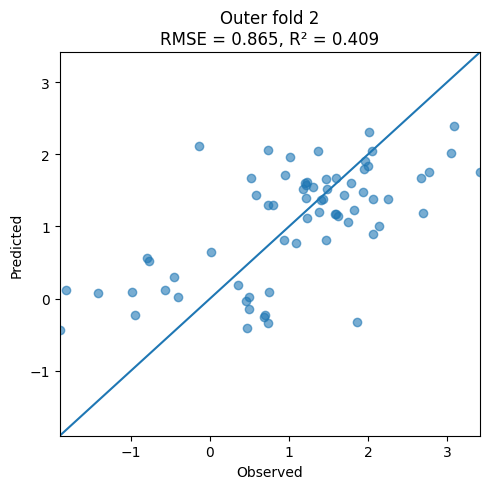

[I 2026-04-25 10:08:22,284] A new study created in memory with name: no-name-263443ae-e400-4322-b425-227310d169d7


Saved model: /content/drive/MyDrive/Colab_Backups/LRR_test/LR_model_combineTW/lr_seed_261_TW_20_outerfold_02.joblib
Saved metadata: /content/drive/MyDrive/Colab_Backups/LRR_test/LR_model_combineTW/lr_seed_261_TW_20_outerfold_02_meta.json

=== Outer fold 3/5 ===
Fold 3 - Gender levels in train: ['F' 'M']
Fold 3 - automation levels in train: [1 2]
Fold 3 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-04-25 10:08:22,353] Trial 0 finished with value: 0.8662937722622825 and parameters: {'alpha': 0.0074593432857265485}. Best is trial 0 with value: 0.8662937722622825.
[I 2026-04-25 10:08:22,411] Trial 1 finished with value: 1.0467403919348992 and parameters: {'alpha': 5.669849511478847}. Best is trial 0 with value: 0.8662937722622825.
[I 2026-04-25 10:08:22,471] Trial 2 finished with value: 0.9340809590380114 and parameters: {'alpha': 0.4570563099801455}. Best is trial 0 with value: 0.8662937722622825.
[I 2026-04-25 10:08:22,530] Trial 3 finished with value: 0.8247863169626408 and parameters: {'alpha': 0.09846738873614563}. Best is trial 3 with value: 0.8247863169626408.
[I 2026-04-25 10:08:22,627] Trial 4 finished with value: 0.900572668675655 and parameters: {'alpha': 0.0006026889128682511}. Best is trial 3 with value: 0.8247863169626408.
[I 2026-04-25 10:08:22,724] Trial 5 finished with value: 0.9005734100397449 and parameters: {'alpha': 0.000602521573620386}. Best is trial 3

/content/drive/MyDrive/Colab_Backups/Data_3sMean_IDT_beforeMat.xlsx | Outer fold 3/5 RMSE = 1.0699 R2 = 0.4609


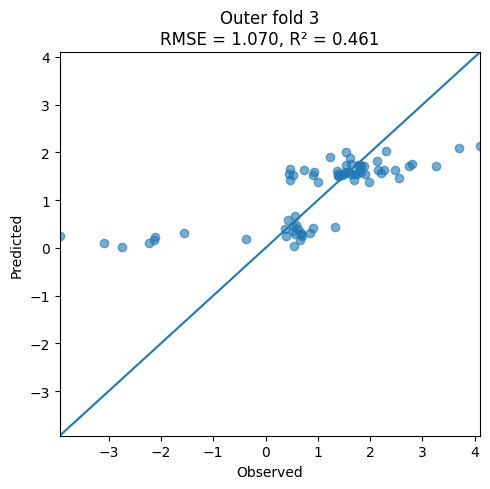

Saved model: /content/drive/MyDrive/Colab_Backups/LRR_test/LR_model_combineTW/lr_seed_261_TW_20_outerfold_03.joblib
Saved metadata: /content/drive/MyDrive/Colab_Backups/LRR_test/LR_model_combineTW/lr_seed_261_TW_20_outerfold_03_meta.json

=== Outer fold 4/5 ===
Fold 4 - Gender levels in train: ['F' 'M']
Fold 4 - automation levels in train: [1 2]
Fold 4 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-04-25 10:08:30,806] A new study created in memory with name: no-name-8afa1bbf-a74d-4799-860b-a27fca85f98b
[I 2026-04-25 10:08:30,877] Trial 0 finished with value: 0.9051063228456052 and parameters: {'alpha': 0.0074593432857265485}. Best is trial 0 with value: 0.9051063228456052.
[I 2026-04-25 10:08:30,937] Trial 1 finished with value: 1.152513406207647 and parameters: {'alpha': 5.669849511478847}. Best is trial 0 with value: 0.9051063228456052.
[I 2026-04-25 10:08:30,999] Trial 2 finished with value: 1.0037304025151552 and parameters: {'alpha': 0.4570563099801455}. Best is trial 0 with value: 0.9051063228456052.
[I 2026-04-25 10:08:31,067] Trial 3 finished with value: 0.8876784232565842 and parameters: {'alpha': 0.09846738873614563}. Best is trial 3 with value: 0.8876784232565842.
[I 2026-04-25 10:08:31,167] Trial 4 finished with value: 0.925815475982244 and parameters: {'alpha': 0.0006026889128682511}. Best is trial 3 with value: 0.8876784232565842.
[I 2026-04-25 10:08:31,262]

/content/drive/MyDrive/Colab_Backups/Data_3sMean_IDT_beforeMat.xlsx | Outer fold 4/5 RMSE = 0.8376 R2 = 0.4187


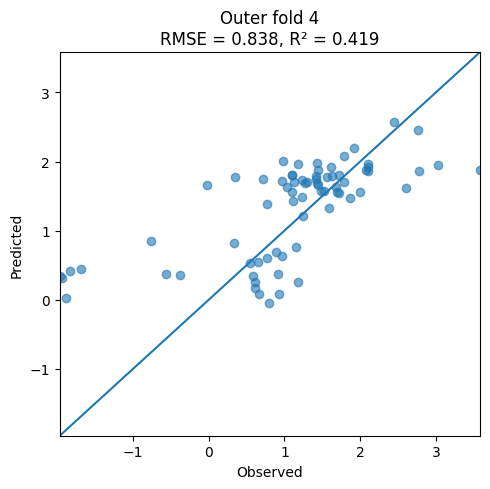

[I 2026-04-25 10:08:37,809] A new study created in memory with name: no-name-91803880-9c85-40e4-b93a-b78295336aa5


Saved model: /content/drive/MyDrive/Colab_Backups/LRR_test/LR_model_combineTW/lr_seed_261_TW_20_outerfold_04.joblib
Saved metadata: /content/drive/MyDrive/Colab_Backups/LRR_test/LR_model_combineTW/lr_seed_261_TW_20_outerfold_04_meta.json

=== Outer fold 5/5 ===
Fold 5 - Gender levels in train: ['F' 'M']
Fold 5 - automation levels in train: [1 2]
Fold 5 - eventType levels in train: ['EVENT_MAT_RIGHT_VRU' 'EVENT_MAT_LEFT_VRU' 'EVENT_MAT_ONCOMING']
  > [TW-Filter] Dropped 0 smaller windows. 33 variables remain.


[I 2026-04-25 10:08:37,880] Trial 0 finished with value: 0.885195404717974 and parameters: {'alpha': 0.0074593432857265485}. Best is trial 0 with value: 0.885195404717974.
[I 2026-04-25 10:08:37,943] Trial 1 finished with value: 1.1388757859659049 and parameters: {'alpha': 5.669849511478847}. Best is trial 0 with value: 0.885195404717974.
[I 2026-04-25 10:08:38,003] Trial 2 finished with value: 0.9855810809584981 and parameters: {'alpha': 0.4570563099801455}. Best is trial 0 with value: 0.885195404717974.
[I 2026-04-25 10:08:38,073] Trial 3 finished with value: 0.850594805626921 and parameters: {'alpha': 0.09846738873614563}. Best is trial 3 with value: 0.850594805626921.
[I 2026-04-25 10:08:38,210] Trial 4 finished with value: 0.9064746055770048 and parameters: {'alpha': 0.0006026889128682511}. Best is trial 3 with value: 0.850594805626921.
[I 2026-04-25 10:08:38,369] Trial 5 finished with value: 0.9064755136082736 and parameters: {'alpha': 0.000602521573620386}. Best is trial 3 with 

/content/drive/MyDrive/Colab_Backups/Data_3sMean_IDT_beforeMat.xlsx | Outer fold 5/5 RMSE = 0.9226 R2 = 0.3028


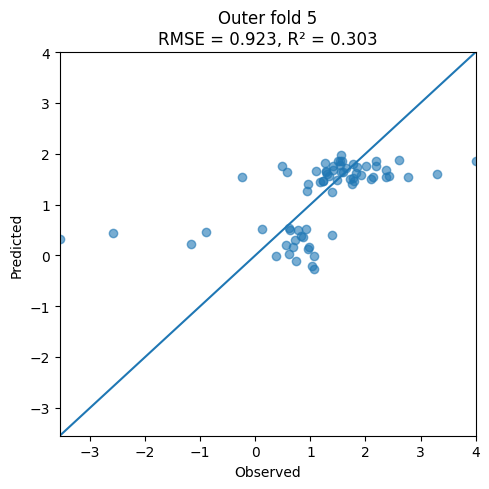

Saved model: /content/drive/MyDrive/Colab_Backups/LRR_test/LR_model_combineTW/lr_seed_261_TW_20_outerfold_05.joblib
Saved metadata: /content/drive/MyDrive/Colab_Backups/LRR_test/LR_model_combineTW/lr_seed_261_TW_20_outerfold_05_meta.json

===== FINAL RESULTS SUMMARY =====
Mean RMSE (Outer CV): 0.8798 (+/- 0.1192)
Mean R2 (Outer CV): 0.3593 (+/- 0.0932)
Updated results: /content/drive/MyDrive/Colab_Backups/LRR_test/LRR_combineTW.xlsx
[0, 20]


KeyboardInterrupt: 

In [ ]:
import json
import os
import re
import hashlib
import numpy as np
import pandas as pd
import optuna
from sklearn.model_selection import StratifiedGroupKFold
import matplotlib.pyplot as plt
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import GroupKFold
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_squared_error, mean_absolute_error
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Lasso
import joblib

def save_results(rows, path):
    df_res = pd.DataFrame(rows)

    df_res = df_res.drop_duplicates(
        subset=["dataName", "seed","TW", "outer_fold"],
        keep="last"
    )
    df_res.to_excel(path, index=False)

def fit_outer_onehot(X_train_raw, X_test_raw, cat_cols):
    """
    Fit category levels from outer-train only, then one-hot outer-train and outer-test once.
    Returns aligned float32 matrices.
    """
    X_train_raw = X_train_raw.copy()
    X_test_raw = X_test_raw.copy()

    use_cat = [c for c in cat_cols if c in X_train_raw.columns]

    # lock category levels using OUTER TRAIN only
    for c in use_cat:
        train_cats = pd.Index(X_train_raw[c].dropna().unique())
        dtype = pd.CategoricalDtype(categories=train_cats, ordered=False)
        X_train_raw[c] = X_train_raw[c].astype(dtype)
        X_test_raw[c] = X_test_raw[c].astype(dtype)

    X_train_oh = pd.get_dummies(
        X_train_raw,
        columns=use_cat,
        drop_first=False
    )

    X_test_oh = pd.get_dummies(
        X_test_raw,
        columns=use_cat,
        drop_first=False
    )

    X_test_oh = X_test_oh.reindex(columns=X_train_oh.columns, fill_value=0)

    # keep exact same column order
    X_train_oh = X_train_oh.astype(np.float32)
    X_test_oh = X_test_oh.astype(np.float32)

    return X_train_oh, X_test_oh

for dataName in ["/content/drive/MyDrive/Colab_Backups/Data_3sMean_IDT_beforeMat.xlsx"]:

  for rs in [261,
              452,
              285,
              966,786, 1423, 3789, 5602, 8741, 11905
             ]:

      TW_comb = [[0,x] for x in range(20,21)]
      twType = "combineTW"
      # twType = "singleTW"

      # if rs == 0:
      #    TW_comb = [[0, x] for x in range(6,31)]
      # else:
      #    TW_comb = [[0, x] for x in range(1,31)]

      for TWs in TW_comb:

        print(TWs)

        if len(TWs)>1:

          targetTW = TWs[1]

        else:
          targetTW = TWs[0]

        corrThre = 0.85

        # ---------- Data Setup ----------
        df = pd.read_excel(dataName)

        BASE_DIR = "/content/drive/MyDrive/Colab_Backups/LRR_test"
        os.makedirs(BASE_DIR, exist_ok=True)

        results_path = os.path.join(BASE_DIR, f"LRR_{twType}.xlsx")
        modelDirectory = f"LR_model_{twType}"

        if os.path.exists(results_path):
              results_df = pd.read_excel(results_path)
              results_rows = results_df.to_dict('records')
              print(f"Resuming from existing file. Found {len(results_rows)} previous runs.")
        else:
              results_df = pd.DataFrame(columns=["seed", "TW"])
              results_rows = []

        # ---- skip if this rs + TW already exists ----
        if not results_df.empty:
            existing = (
                (results_df["seed"] == rs) &
                (results_df["TW"] == targetTW)
            )

            if existing.any():
                print(f"Skipping rs={rs}, targetTW={targetTW} because it already exists.")
                continue

          # ---- run your modelling code here ----
        print(f"Running rs={rs}, targetTW={targetTW}")


        # ---------- Parameter ----------
        outer_splits, inner_splits, n_trials = 5, 4, 100

        target_col = "relativeRT"

        cat_names = ["Gender", "automation", "eventType"]

        TW_list = TWs

        feature_templates = [
            "Age",
            "License",
            "Mileage",
            "Gender",
            "automation", "eventType",
            "visibleSpeed",

            "pdMean_{TW}", "pdSd_{TW}",
            "blinkNumber_{TW}",
            "avgBlinkDuration_{TW}",

            "fixNumber_{TW}",
            "avgFixDuration_{TW}",

            "fixTE_{TW}", "fixSE_{TW}",
            "FixDisperX_{TW}", "FixDisperY_{TW}",
            "FixDisperE_{TW}",
            "FixMeanPosX_{TW}", "FixMeanPosY_{TW}",

        ]

        feature_cols = []
        for c in feature_templates:
            feature_cols.extend([c.format(TW=tw) for tw in TW_list] if "{TW}" in c else [c])

        cont_names = [c for c in feature_cols if c not in cat_names]


        tww_cols = [f"perValid_{i}" for i in range(31)]

        pervalid_mean = df[tww_cols].mean(axis=1)

        abandon_mask = pervalid_mean < 74.5
        keep_mask = ~abandon_mask

        df = df[keep_mask].copy()

        X = df[feature_cols].copy()
        y = pd.to_numeric(df[target_col], errors="coerce").values.astype(float)
        groups = df["subNumber"].values

        outer_cv = GroupKFold(
            n_splits=outer_splits,
            shuffle=True,
            random_state=rs
        )

        outer_scores = []
        outer_RMSE = []
        oof_pred = np.full_like(y, fill_value=-1)
        oof_fold = np.full(len(y), -1, dtype=int)
        oof_proba = np.full(len(y), np.nan)
        all_fold_best_vars = []

        outer_best_params = []
        outer_R2 = []
        fold_rows = []   # temp storage for this (dataName, rs, TW)

        print(f'len(df)={len(df)}')

        for outer_fold, (train_idx, test_idx) in enumerate(outer_cv.split(X, y, groups), start=1):


            print(f"\n=== Outer fold {outer_fold}/{outer_splits} ===")

            X_out_train = X.iloc[train_idx].copy()
            y_out_train = y[train_idx]
            groups_out_tr = groups[train_idx]

            X_out_test = X.iloc[test_idx].copy()
            y_out_test = y[test_idx]

            to_drop_fold = []

            for col in cat_names:
                if col in X_out_train.columns:
                    print(f"Fold {outer_fold} - {col} levels in train:",
                          X_out_train[col].unique())


            fold_vars = [c for c in feature_cols if c not in to_drop_fold]
            fold_cont = [c for c in fold_vars if c in cont_names]
            fold_cat = [c for c in fold_vars if c in cat_names]

            print(f"  > [TW-Filter] Dropped {len(to_drop_fold)} smaller windows. {len(fold_vars)} variables remain.")

            current_vars = fold_vars[:]
            best_vars = current_vars

            X_out_train_oh, X_out_test_oh = fit_outer_onehot(
                X_out_train[best_vars],
                X_out_test[best_vars],
                cat_names
            )


            def objective(trial):

                alpha = trial.suggest_float("alpha", 1e-4, 10.0, log=True)
                cv_opt = GroupKFold(
                    n_splits=inner_splits,
                    shuffle=True,
                    random_state=123
                )
                scores = []

                for t_i, v_i in cv_opt.split(X_out_train_oh, y_out_train, groups_out_tr):


                  X_tr = X_out_train_oh.iloc[t_i].copy()
                  X_val = X_out_train_oh.iloc[v_i].copy()
                  y_tr = y_out_train[t_i]
                  y_val = y_out_train[v_i]

                  # --- impute (fit ONLY on train fold) ---
                  imputer = SimpleImputer(strategy="median")
                  X_tr = pd.DataFrame(
                      imputer.fit_transform(X_tr),
                      columns=X_tr.columns,
                      index=X_tr.index
                  )
                  X_val = pd.DataFrame(
                      imputer.transform(X_val),
                      columns=X_val.columns,
                      index=X_val.index
                  )

                  # --- scale (fit ONLY on train fold) ---
                  scaler = StandardScaler()
                  X_tr = pd.DataFrame(
                      scaler.fit_transform(X_tr),
                      columns=X_tr.columns,
                      index=X_tr.index
                  )
                  X_val = pd.DataFrame(
                      scaler.transform(X_val),
                      columns=X_val.columns,
                      index=X_val.index
                  )

                  # --- model ---
                  model = Lasso(
                    alpha=alpha,
                    max_iter=5000,
                    random_state=42
                  )

                  model.fit(X_tr, y_tr)

                  y_pred = model.predict(X_val)

                  scores.append(np.sqrt(mean_squared_error(y_val, y_pred)))

                return float(np.mean(scores))


            sampler = optuna.samplers.TPESampler(seed=42)
            study = optuna.create_study(direction="minimize", sampler=sampler)
            study.optimize(objective, n_trials=n_trials)

            best_trial = study.best_trial

            # --- fit on OUTER TRAIN ONLY ---
            imputer = SimpleImputer(strategy="median")
            X_out_train_oh = pd.DataFrame(
                imputer.fit_transform(X_out_train_oh),
                columns=X_out_train_oh.columns,
                index=X_out_train_oh.index
            )
            X_out_test_oh = pd.DataFrame(
                imputer.transform(X_out_test_oh),
                columns=X_out_test_oh.columns,
                index=X_out_test_oh.index
            )

            scaler = StandardScaler()
            X_out_train_oh = pd.DataFrame(
                scaler.fit_transform(X_out_train_oh),
                columns=X_out_train_oh.columns,
                index=X_out_train_oh.index
            )
            X_out_test_oh = pd.DataFrame(
                scaler.transform(X_out_test_oh),
                columns=X_out_test_oh.columns,
                index=X_out_test_oh.index
            )

            final_p = {
                "alpha": study.best_params["alpha"],
                "max_iter": 5000,
                "random_state": 42
            }

            # --- final model ---
            final_model = Lasso(
                **final_p
            )

            outer_best_params.append(final_p)

            final_model.fit(X_out_train_oh, y_out_train)
            y_pred = final_model.predict(X_out_test_oh)


            oof_pred[test_idx] = y_pred
            oof_fold[test_idx] = outer_fold


            outer_rmse = np.sqrt(mean_squared_error(y_out_test, y_pred))

            r2   = r2_score(y_out_test, y_pred)

            fold_rows.append({
                "dataName": dataName,
                "seed": rs,
                "TW": float(targetTW),
                "outer_fold": int(outer_fold),
                "RMSE": float(outer_rmse),
                "R2": float(r2),
                "n_test": int(len(test_idx)),
            })

            plt.figure(figsize=(5, 5))
            plt.scatter(y_out_test, y_pred, alpha=0.6)
            outer_R2.append(r2)

            outer_scores.append(outer_rmse)

            print(f"{dataName} | Outer fold {outer_fold}/5 RMSE = {outer_rmse:.4f} R2 = {r2:.4f}")

            lims = [
                min(y_out_test.min(), y_pred.min()),
                max(y_out_test.max(), y_pred.max())
            ]
            plt.plot(lims, lims)
            plt.xlim(lims)
            plt.ylim(lims)

            plt.xlabel("Observed")
            plt.ylabel("Predicted")
            plt.title(
                f"Outer fold {outer_fold}\n"
                f"RMSE = {outer_rmse:.3f}, R² = {r2:.3f}"
            )

            plt.tight_layout()
            plt.show()

            MODEL_DIR = os.path.join(BASE_DIR, modelDirectory)
            os.makedirs(MODEL_DIR, exist_ok=True)

            model_path = os.path.join(MODEL_DIR, f"lr_seed_{rs:02d}_TW_{targetTW:02d}_outerfold_{outer_fold:02d}.joblib")
            joblib.dump(
                {
                    "model": final_model,
                    "imputer": imputer,
                    "scaler": scaler,
                    "feature_names": list(X_out_train_oh.columns)
                },
                model_path
            )
            print("Saved model:", model_path)


            meta = {
                "seed": rs,
                "TW": targetTW,
                "outer_fold": outer_fold,
                "best_params": final_p,
                "best_score_inner_cv": study.best_value,
                "selected_features": best_vars
            }

            meta_path = model_path.replace(".joblib", "_meta.json")

            with open(meta_path, "w") as f:
                json.dump(meta, f, indent=4)

            print("Saved metadata:", meta_path)


        # ---------- Final reporting ----------
        print(f"\n===== FINAL RESULTS SUMMARY =====")
        print(f"Mean RMSE (Outer CV): {np.mean(outer_scores):.4f} (+/- {np.std(outer_scores):.4f})")
        print(f"Mean R2 (Outer CV): {np.mean(outer_R2):.4f} (+/- {np.std(outer_R2):.4f})")


        results_rows.extend(fold_rows)


        summary_row = {
            "dataName": dataName,
            "seed": rs,
            "TW": float(targetTW),
            "outer_fold": "SUMMARY",
            "RMSE": float(np.mean(outer_scores)),
            "R2": float(np.mean(outer_R2)),
            "std_RMSE": float(np.std(outer_scores)),
            "std_R2": float(np.std(outer_R2)),
            "n_samples": int(len(y)),
        }
        results_rows.append(summary_row)

        save_results(results_rows, results_path)
        print(f"Updated results: {results_path}")

In [ ]:
import json
import os
import re
import hashlib
import numpy as np
import pandas as pd
import optuna
from sklearn.model_selection import StratifiedGroupKFold
import matplotlib.pyplot as plt
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import GroupKFold
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_squared_error, mean_absolute_error
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Lasso
import joblib

def save_results(rows, path):
    df_res = pd.DataFrame(rows)

    df_res = df_res.drop_duplicates(
        subset=["dataName", "seed","TW", "outer_fold"],
        keep="last"
    )
    df_res.to_excel(path, index=False)

def fit_outer_onehot(X_train_raw, X_test_raw, cat_cols):
    """
    Fit category levels from outer-train only, then one-hot outer-train and outer-test once.
    Returns aligned float32 matrices.
    """
    X_train_raw = X_train_raw.copy()
    X_test_raw = X_test_raw.copy()

    use_cat = [c for c in cat_cols if c in X_train_raw.columns]

    # lock category levels using OUTER TRAIN only
    for c in use_cat:
        train_cats = pd.Index(X_train_raw[c].dropna().unique())
        dtype = pd.CategoricalDtype(categories=train_cats, ordered=False)
        X_train_raw[c] = X_train_raw[c].astype(dtype)
        X_test_raw[c] = X_test_raw[c].astype(dtype)

    X_train_oh = pd.get_dummies(
        X_train_raw,
        columns=use_cat,
        drop_first=False
    )

    X_test_oh = pd.get_dummies(
        X_test_raw,
        columns=use_cat,
        drop_first=False
    )

    X_test_oh = X_test_oh.reindex(columns=X_train_oh.columns, fill_value=0)

    # keep exact same column order
    X_train_oh = X_train_oh.astype(np.float32)
    X_test_oh = X_test_oh.astype(np.float32)

    return X_train_oh, X_test_oh

for dataName in ["/content/drive/MyDrive/Colab_Backups/Data_3sMean_IDT_beforeMat.xlsx"]:

  for rs in [261,
              452,
              285,
              966,786, 1423, 3789, 5602, 8741, 11905
             ]:

      TW_comb = [[x] for x in range(0,31)]
      # twType = "combineTW"
      twType = "singleTW"

      # if rs == 0:
      #    TW_comb = [[0, x] for x in range(6,31)]
      # else:
      #    TW_comb = [[0, x] for x in range(1,31)]

      for TWs in TW_comb:

        print(TWs)

        if len(TWs)>1:

          targetTW = TWs[1]

        else:
          targetTW = TWs[0]

        corrThre = 0.85

        # ---------- Data Setup ----------
        df = pd.read_excel(dataName)

        BASE_DIR = "/content/drive/MyDrive/Colab_Backups/LRR"
        os.makedirs(BASE_DIR, exist_ok=True)

        results_path = os.path.join(BASE_DIR, f"LRR_{twType}.xlsx")
        modelDirectory = f"LR_model_{twType}"

        if os.path.exists(results_path):
              results_df = pd.read_excel(results_path)
              results_rows = results_df.to_dict('records')
              print(f"Resuming from existing file. Found {len(results_rows)} previous runs.")
        else:
              results_df = pd.DataFrame(columns=["seed", "TW"])
              results_rows = []

        # ---- skip if this rs + TW already exists ----
        if not results_df.empty:
            existing = (
                (results_df["seed"] == rs) &
                (results_df["TW"] == targetTW)
            )

            if existing.any():
                print(f"Skipping rs={rs}, targetTW={targetTW} because it already exists.")
                continue

          # ---- run your modelling code here ----
        print(f"Running rs={rs}, targetTW={targetTW}")


        # ---------- Parameter ----------
        outer_splits, inner_splits, n_trials = 5, 4, 100

        target_col = "relativeRT"

        cat_names = ["Gender", "automation", "eventType"]

        TW_list = TWs

        feature_templates = [
            "Age",
            "License",
            "Mileage",
            "Gender",
            "automation", "eventType",
            "visibleSpeed",

            "pdMean_{TW}", "pdSd_{TW}",
            "blinkNumber_{TW}",
            "avgBlinkDuration_{TW}",

            "fixNumber_{TW}",
            "avgFixDuration_{TW}",

            "fixTE_{TW}", "fixSE_{TW}",
            "FixDisperX_{TW}", "FixDisperY_{TW}",
            "FixDisperE_{TW}",
            "FixMeanPosX_{TW}", "FixMeanPosY_{TW}",

        ]

        feature_cols = []
        for c in feature_templates:
            feature_cols.extend([c.format(TW=tw) for tw in TW_list] if "{TW}" in c else [c])

        cont_names = [c for c in feature_cols if c not in cat_names]


        tww_cols = [f"perValid_{i}" for i in range(31)]

        pervalid_mean = df[tww_cols].mean(axis=1)

        abandon_mask = pervalid_mean < 74.5
        keep_mask = ~abandon_mask

        df = df[keep_mask].copy()

        X = df[feature_cols].copy()
        y = pd.to_numeric(df[target_col], errors="coerce").values.astype(float)
        groups = df["subNumber"].values

        outer_cv = GroupKFold(
            n_splits=outer_splits,
            shuffle=True,
            random_state=rs
        )

        outer_scores = []
        outer_RMSE = []
        oof_pred = np.full_like(y, fill_value=-1)
        oof_fold = np.full(len(y), -1, dtype=int)
        oof_proba = np.full(len(y), np.nan)
        all_fold_best_vars = []

        outer_best_params = []
        outer_R2 = []
        fold_rows = []   # temp storage for this (dataName, rs, TW)

        print(f'len(df)={len(df)}')

        for outer_fold, (train_idx, test_idx) in enumerate(outer_cv.split(X, y, groups), start=1):


            print(f"\n=== Outer fold {outer_fold}/{outer_splits} ===")

            X_out_train = X.iloc[train_idx].copy()
            y_out_train = y[train_idx]
            groups_out_tr = groups[train_idx]

            X_out_test = X.iloc[test_idx].copy()
            y_out_test = y[test_idx]

            to_drop_fold = []

            for col in cat_names:
                if col in X_out_train.columns:
                    print(f"Fold {outer_fold} - {col} levels in train:",
                          X_out_train[col].unique())


            fold_vars = [c for c in feature_cols if c not in to_drop_fold]
            fold_cont = [c for c in fold_vars if c in cont_names]
            fold_cat = [c for c in fold_vars if c in cat_names]

            print(f"  > [TW-Filter] Dropped {len(to_drop_fold)} smaller windows. {len(fold_vars)} variables remain.")

            current_vars = fold_vars[:]
            best_vars = current_vars

            X_out_train_oh, X_out_test_oh = fit_outer_onehot(
                X_out_train[best_vars],
                X_out_test[best_vars],
                cat_names
            )


            def objective(trial):

                alpha = trial.suggest_float("alpha", 1e-4, 10.0, log=True)
                cv_opt = GroupKFold(
                    n_splits=inner_splits,
                    shuffle=True,
                    random_state=123
                )
                scores = []

                for t_i, v_i in cv_opt.split(X_out_train_oh, y_out_train, groups_out_tr):


                  X_tr = X_out_train_oh.iloc[t_i].copy()
                  X_val = X_out_train_oh.iloc[v_i].copy()
                  y_tr = y_out_train[t_i]
                  y_val = y_out_train[v_i]

                  # --- impute (fit ONLY on train fold) ---
                  imputer = SimpleImputer(strategy="median")
                  X_tr = pd.DataFrame(
                      imputer.fit_transform(X_tr),
                      columns=X_tr.columns,
                      index=X_tr.index
                  )
                  X_val = pd.DataFrame(
                      imputer.transform(X_val),
                      columns=X_val.columns,
                      index=X_val.index
                  )

                  # --- scale (fit ONLY on train fold) ---
                  scaler = StandardScaler()
                  X_tr = pd.DataFrame(
                      scaler.fit_transform(X_tr),
                      columns=X_tr.columns,
                      index=X_tr.index
                  )
                  X_val = pd.DataFrame(
                      scaler.transform(X_val),
                      columns=X_val.columns,
                      index=X_val.index
                  )

                  # --- model ---
                  model = Lasso(
                    alpha=alpha,
                    max_iter=5000,
                    random_state=42
                  )

                  model.fit(X_tr, y_tr)

                  y_pred = model.predict(X_val)

                  scores.append(np.sqrt(mean_squared_error(y_val, y_pred)))

                return float(np.mean(scores))


            sampler = optuna.samplers.TPESampler(seed=42)
            study = optuna.create_study(direction="minimize", sampler=sampler)
            study.optimize(objective, n_trials=n_trials)

            best_trial = study.best_trial

            # --- fit on OUTER TRAIN ONLY ---
            imputer = SimpleImputer(strategy="median")
            X_out_train_oh = pd.DataFrame(
                imputer.fit_transform(X_out_train_oh),
                columns=X_out_train_oh.columns,
                index=X_out_train_oh.index
            )
            X_out_test_oh = pd.DataFrame(
                imputer.transform(X_out_test_oh),
                columns=X_out_test_oh.columns,
                index=X_out_test_oh.index
            )

            scaler = StandardScaler()
            X_out_train_oh = pd.DataFrame(
                scaler.fit_transform(X_out_train_oh),
                columns=X_out_train_oh.columns,
                index=X_out_train_oh.index
            )
            X_out_test_oh = pd.DataFrame(
                scaler.transform(X_out_test_oh),
                columns=X_out_test_oh.columns,
                index=X_out_test_oh.index
            )

            final_p = {
                "alpha": study.best_params["alpha"],
                "max_iter": 5000,
                "random_state": 42
            }

            # --- final model ---
            final_model = Lasso(
                **final_p
            )

            outer_best_params.append(final_p)

            final_model.fit(X_out_train_oh, y_out_train)
            y_pred = final_model.predict(X_out_test_oh)


            oof_pred[test_idx] = y_pred
            oof_fold[test_idx] = outer_fold


            outer_rmse = np.sqrt(mean_squared_error(y_out_test, y_pred))

            r2   = r2_score(y_out_test, y_pred)

            fold_rows.append({
                "dataName": dataName,
                "seed": rs,
                "TW": float(targetTW),
                "outer_fold": int(outer_fold),
                "RMSE": float(outer_rmse),
                "R2": float(r2),
                "n_test": int(len(test_idx)),
            })

            plt.figure(figsize=(5, 5))
            plt.scatter(y_out_test, y_pred, alpha=0.6)
            outer_R2.append(r2)

            outer_scores.append(outer_rmse)

            print(f"{dataName} | Outer fold {outer_fold}/5 RMSE = {outer_rmse:.4f} R2 = {r2:.4f}")

            lims = [
                min(y_out_test.min(), y_pred.min()),
                max(y_out_test.max(), y_pred.max())
            ]
            plt.plot(lims, lims)
            plt.xlim(lims)
            plt.ylim(lims)

            plt.xlabel("Observed")
            plt.ylabel("Predicted")
            plt.title(
                f"Outer fold {outer_fold}\n"
                f"RMSE = {outer_rmse:.3f}, R² = {r2:.3f}"
            )

            plt.tight_layout()
            plt.show()

            MODEL_DIR = os.path.join(BASE_DIR, modelDirectory)
            os.makedirs(MODEL_DIR, exist_ok=True)

            model_path = os.path.join(MODEL_DIR, f"lr_seed_{rs:02d}_TW_{targetTW:02d}_outerfold_{outer_fold:02d}.joblib")
            joblib.dump(
                {
                    "model": final_model,
                    "imputer": imputer,
                    "scaler": scaler,
                    "feature_names": list(X_out_train_oh.columns)
                },
                model_path
            )
            print("Saved model:", model_path)


            meta = {
                "seed": rs,
                "TW": targetTW,
                "outer_fold": outer_fold,
                "best_params": final_p,
                "best_score_inner_cv": study.best_value,
                "selected_features": best_vars
            }

            meta_path = model_path.replace(".joblib", "_meta.json")

            with open(meta_path, "w") as f:
                json.dump(meta, f, indent=4)

            print("Saved metadata:", meta_path)


        # ---------- Final reporting ----------
        print(f"\n===== FINAL RESULTS SUMMARY =====")
        print(f"Mean RMSE (Outer CV): {np.mean(outer_scores):.4f} (+/- {np.std(outer_scores):.4f})")
        print(f"Mean R2 (Outer CV): {np.mean(outer_R2):.4f} (+/- {np.std(outer_R2):.4f})")


        results_rows.extend(fold_rows)


        summary_row = {
            "dataName": dataName,
            "seed": rs,
            "TW": float(targetTW),
            "outer_fold": "SUMMARY",
            "RMSE": float(np.mean(outer_scores)),
            "R2": float(np.mean(outer_R2)),
            "std_RMSE": float(np.std(outer_scores)),
            "std_R2": float(np.std(outer_R2)),
            "n_samples": int(len(y)),
        }
        results_rows.append(summary_row)

        save_results(results_rows, results_path)
        print(f"Updated results: {results_path}")

[0]


KeyboardInterrupt: 